# EDA 02 — Análise temporal e clustering

## Objetivo

Descrever temporalmente a coorte analítica do projeto SRAG e explorar
perfis de apresentação na admissão por meio de técnicas de clustering.

### Fonte da coorte

A fonte da coorte é resolvida pelo mecanismo central do projeto, sem
manter uma lista própria de arquivos neste notebook. O tipo solicitado
pode ser provisório ou definitivo, e o caminho efetivamente utilizado é
validado antes da leitura.

Nesta execução, foi utilizada a coorte provisória. Quando a coorte
definitiva estiver disponível e for selecionada na configuração de
execução, o mesmo fluxo poderá ser reproduzido sem alterar as células
analíticas do notebook.

O tipo, o caminho e a dimensão da coorte utilizada são registrados no
início da execução e na tabela `eda_02_resumo_fonte.csv`, permitindo
rastrear exatamente a origem dos resultados.

## Limites

- o desfecho não participará da formação dos clusters;
- identificadores não serão usados como variáveis de clustering;
- informações posteriores à admissão não entrarão na matriz;
- 2026 será tratado conforme a cobertura da coorte carregada;
- o desfecho será relacionado aos clusters somente depois da definição
  da solução não supervisionada.

In [1]:
from pathlib import Path
import gc
import sys
import time

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

import os
import psutil

PROCESSO_ATUAL = psutil.Process(os.getpid())

def memoria_processo_gb():
    """Retorna a memória residente do kernel atual em GB."""

    return (
        PROCESSO_ATUAL.memory_info().rss
        / (1024 ** 3)
    )

print(
    "Memória inicial do kernel:",
    f"{memoria_processo_gb():.2f} GB",
)

def encontrar_raiz_projeto() -> Path:
    pasta_atual = Path.cwd().resolve()

    for pasta in [pasta_atual, *pasta_atual.parents]:
        possui_src = (pasta / "src").is_dir()
        possui_configs = (pasta / "configs").is_dir()

        if possui_src and possui_configs:
            return pasta

    raise FileNotFoundError(
        "Não foi possível localizar a raiz do projeto."
    )


ROOT_DIR = encontrar_raiz_projeto()

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.data.cohort_source import resolve_cohort_path
from src.utils import config as C

TIPO_COORTE, CAMINHO_COORTE = resolve_cohort_path(
    root=ROOT_DIR,
    kind=None,
    explicit_path=None,
)

CAMINHO_COORTE = Path(CAMINHO_COORTE)
NOME_COORTE = str(TIPO_COORTE)

if not CAMINHO_COORTE.is_file():
    raise FileNotFoundError(
        "A fonte de coorte resolvida não existe: "
        f"{CAMINHO_COORTE}"
    )

print(
    "Tipo de coorte:",
    NOME_COORTE,
)
print(
    "Arquivo da coorte:",
    CAMINHO_COORTE,
)


COLUNAS_ESTRUTURA_B06 = [
    "nu_notific",
    "dt_interna_convertida",
    "ano_internacao",
    "evolucao_normalizada",
    "alvo_obito_srag",
]

COLUNAS_DEMOGRAFIA_B06 = [
    "cs_sexo",
    "sexo_categoria",
    "nu_idade_n",
    "tp_idade",
    "idade_anos",
    "faixa_etaria",
    "cs_gestant",
    "cs_raca",
    "cs_zona",
]

COLUNAS_SINTOMAS_PLANEJADAS = [
    "febre",
    "tosse",
    "garganta",
    "dispneia",
    "desc_resp",
    "saturacao",
    "diarreia",
    "vomito",
    "dor_abd",
    "fadiga",
    "perd_olft",
    "perd_pala",
    "outro_sin",
]

COLUNAS_COMORBIDADES_PLANEJADAS = [
    "puerpera",
    "cardiopati",
    "hematologi",
    "sind_down",
    "hepatica",
    "asma",
    "diabetes",
    "neurologic",
    "pneumopati",
    "imunodepre",
    "renal",
    "obesidade",
    "out_morbi",
]

COLUNAS_CONTEXTO_B06 = [
    "cs_escol_n",
    "sg_uf",
    "vacina",
    "vacina_cov",
    "ave_suino",
]

COLUNAS_INTERVALOS_B06 = [
    "dt_sin_pri",
    "dt_interna",
    "dt_sin_pri_convertida",
    "dias_sintomas_ate_internacao",
    "flag_intervalo_invalido",
]

COLUNAS_CONTADORES_EXISTENTES_B06 = [
    "n_sintomas_confirmados",
    "n_sintomas_avaliados",
    "n_comorbidades_confirmadas",
    "n_comorbidades_avaliadas",
    "flag_multimorbidade",
]

COLUNAS_CLUSTERING_B06 = [
    "sin_semana",
    "cos_semana",
]


COLUNAS_SOLICITADAS_B06 = list(
    dict.fromkeys(
        COLUNAS_ESTRUTURA_B06
        + COLUNAS_DEMOGRAFIA_B06
        + COLUNAS_SINTOMAS_PLANEJADAS
        + COLUNAS_COMORBIDADES_PLANEJADAS
        + COLUNAS_CONTEXTO_B06
        + COLUNAS_INTERVALOS_B06
        + COLUNAS_CONTADORES_EXISTENTES_B06
        + COLUNAS_CLUSTERING_B06
    )
)


# ------------------------------------------------------------
# Conferência do schema antes da leitura
# ------------------------------------------------------------

arquivo_parquet = pq.ParquetFile(
    CAMINHO_COORTE
)

COLUNAS_DISPONIVEIS_COORTE = set(
    arquivo_parquet.schema_arrow.names
)

COLUNAS_EXISTENTES_B06 = [
    coluna
    for coluna in COLUNAS_SOLICITADAS_B06
    if coluna in COLUNAS_DISPONIVEIS_COORTE
]

COLUNAS_AUSENTES_B06 = [
    coluna
    for coluna in COLUNAS_SOLICITADAS_B06
    if coluna not in COLUNAS_DISPONIVEIS_COORTE
]


# Colunas exigidas diretamente do Parquet. As derivadas (data convertida,
# ano e evolução normalizada) são criadas na célula seguinte quando a
# coorte definitiva não as traz prontas.
COLUNAS_OBRIGATORIAS_COORTE = [
    "nu_notific",
    "dt_interna",
    "alvo_obito_srag",
]

colunas_obrigatorias_ausentes = [
    coluna
    for coluna in COLUNAS_OBRIGATORIAS_COORTE
    if coluna not in COLUNAS_DISPONIVEIS_COORTE
]

if colunas_obrigatorias_ausentes:
    raise KeyError(
        "A coorte não contém as colunas obrigatórias: "
        f"{colunas_obrigatorias_ausentes}"
    )


print(
    "Colunas disponíveis no Parquet:",
    len(COLUNAS_DISPONIVEIS_COORTE),
)

print(
    "Colunas solicitadas pelo B_06:",
    len(COLUNAS_SOLICITADAS_B06),
)

print(
    "Colunas que serão carregadas:",
    len(COLUNAS_EXISTENTES_B06),
)

if COLUNAS_AUSENTES_B06:
    print(
        "Colunas opcionais ausentes, que poderão ser derivadas:",
        COLUNAS_AUSENTES_B06,
    )


# ------------------------------------------------------------
# Leitura projetada
# ------------------------------------------------------------

t0_carregamento = time.perf_counter()

try:
    coorte = pd.read_parquet(
        CAMINHO_COORTE,
        columns=COLUNAS_EXISTENTES_B06,
        dtype_backend="pyarrow",
    )

    BACKEND_COORTE = "pyarrow"

except TypeError:
    coorte = pd.read_parquet(
        CAMINHO_COORTE,
        columns=COLUNAS_EXISTENTES_B06,
    )

    BACKEND_COORTE = "numpy/object"


if coorte.empty:
    raise ValueError(
        "A coorte carregada está vazia."
    )


memoria_apos_leitura_mb = (
    coorte.memory_usage(
        index=True,
        deep=True,
    )
    .sum()
    / 1_048_576
)


# ------------------------------------------------------------
# Compactação controlada
# ------------------------------------------------------------

COLUNAS_CATEGORICAS_BAIXA_CARDINALIDADE = [
    coluna
    for coluna in (
        COLUNAS_DEMOGRAFIA_B06
        + COLUNAS_SINTOMAS_PLANEJADAS
        + COLUNAS_COMORBIDADES_PLANEJADAS
        + COLUNAS_CONTEXTO_B06
        + [
            "evolucao_normalizada",
            "faixa_etaria",
        ]
    )
    if coluna in coorte.columns
]


relatorio_compactacao = []


for coluna in COLUNAS_CATEGORICAS_BAIXA_CARDINALIDADE:
    memoria_antes = int(
        coorte[coluna]
        .memory_usage(
            index=False,
            deep=True,
        )
    )

    quantidade_categorias = int(
        coorte[coluna]
        .nunique(
            dropna=False
        )
    )

    if quantidade_categorias <= 500:
        coorte[coluna] = (
            coorte[coluna]
            .astype("category")
        )

    memoria_depois = int(
        coorte[coluna]
        .memory_usage(
            index=False,
            deep=True,
        )
    )

    relatorio_compactacao.append(
        {
            "coluna": coluna,
            "categorias": quantidade_categorias,
            "dtype_final": str(
                coorte[coluna].dtype
            ),
            "memoria_antes_mb": (
                memoria_antes
                / 1_048_576
            ),
            "memoria_depois_mb": (
                memoria_depois
                / 1_048_576
            ),
        }
    )


if "ano_internacao" in coorte.columns:
    coorte["ano_internacao"] = (
        pd.to_numeric(
            coorte["ano_internacao"],
            errors="coerce",
        )
        .astype("Int16")
    )


if "alvo_obito_srag" in coorte.columns:
    coorte["alvo_obito_srag"] = (
        pd.to_numeric(
            coorte["alvo_obito_srag"],
            errors="coerce",
        )
        .astype("Int8")
    )


if "idade_anos" in coorte.columns:
    coorte["idade_anos"] = (
        pd.to_numeric(
            coorte["idade_anos"],
            errors="coerce",
        )
        .astype("Float32")
    )


if "dias_sintomas_ate_internacao" in coorte.columns:
    coorte["dias_sintomas_ate_internacao"] = (
        pd.to_numeric(
            coorte["dias_sintomas_ate_internacao"],
            errors="coerce",
        )
        .astype("Float32")
    )


for coluna in [
    "n_sintomas_confirmados",
    "n_sintomas_avaliados",
    "n_comorbidades_confirmadas",
    "n_comorbidades_avaliadas",
]:
    if coluna in coorte.columns:
        coorte[coluna] = (
            pd.to_numeric(
                coorte[coluna],
                errors="coerce",
            )
            .astype("Int16")
        )


for coluna in [
    "flag_intervalo_invalido",
    "flag_multimorbidade",
]:
    if coluna in coorte.columns:
        coorte[coluna] = (
            pd.to_numeric(
                coorte[coluna],
                errors="coerce",
            )
            .fillna(0)
            .astype("int8")
        )


memoria_final_mb = (
    coorte.memory_usage(
        index=True,
        deep=True,
    )
    .sum()
    / 1_048_576
)

tempo_carregamento_s = (
    time.perf_counter()
    - t0_carregamento
)

gc.collect()


print(
    "Coorte utilizada:",
    NOME_COORTE,
)

print(
    "Caminho:",
    CAMINHO_COORTE,
)

print(
    "Backend:",
    BACKEND_COORTE,
)

print(
    "Dimensão carregada:",
    coorte.shape,
)

print(
    "Memória após leitura:",
    f"{memoria_apos_leitura_mb:,.2f} MB",
)

print(
    "Memória após compactação:",
    f"{memoria_final_mb:,.2f} MB",
)

if memoria_apos_leitura_mb > 0:
    reducao_memoria_pct = (
        1
        - memoria_final_mb
        / memoria_apos_leitura_mb
    ) * 100
else:
    reducao_memoria_pct = 0.0

print(
    "Redução após compactação:",
    f"{reducao_memoria_pct:,.2f}%",
)

print(
    "Tempo de leitura e compactação:",
    f"{tempo_carregamento_s:,.2f} s",
)


relatorio_compactacao_df = (
    pd.DataFrame(
        relatorio_compactacao
    )
    .sort_values(
        [
            "memoria_antes_mb",
            "coluna",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .reset_index(drop=True)
)


display(
    relatorio_compactacao_df.head(20)
)

Memória inicial do kernel: 0.11 GB
Tipo de coorte: final
Arquivo da coorte: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\data\analytical\coorte_final.parquet
Colunas disponíveis no Parquet: 199
Colunas solicitadas pelo B_06: 57
Colunas que serão carregadas: 41
Colunas opcionais ausentes, que poderão ser derivadas: ['dt_interna_convertida', 'ano_internacao', 'evolucao_normalizada', 'sexo_categoria', 'idade_anos', 'faixa_etaria', 'dt_sin_pri_convertida', 'dias_sintomas_ate_internacao', 'flag_intervalo_invalido', 'n_sintomas_confirmados', 'n_sintomas_avaliados', 'n_comorbidades_confirmadas', 'n_comorbidades_avaliadas', 'flag_multimorbidade', 'sin_semana', 'cos_semana']


Coorte utilizada: final
Caminho: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\data\analytical\coorte_final.parquet
Backend: pyarrow
Dimensão carregada: (3884728, 41)
Memória após leitura: 830.98 MB
Memória após compactação: 313.89 MB
Redução após compactação: 62.23%
Tempo de leitura e compactação: 6.94 s


,coluna,categorias,dtype_final,memoria_antes_mb,memoria_depois_mb
0,sg_uf,28,category,22.689557,3.704924
1,nu_idade_n,135,category,21.475392,7.410336
2,cs_zona,5,category,18.662969,3.704785
3,tosse,4,category,18.626857,3.704781
4,cs_raca,7,category,18.616165,3.704795
5,dispneia,4,category,18.591432,3.704781
6,cs_gestant,8,category,18.523827,3.704804
7,cs_sexo,3,category,18.523827,3.704781
8,tp_idade,3,category,18.523827,3.704781
9,febre,4,category,18.491655,3.704781


In [2]:
# Compatibilidade com a coorte definitiva: cria as colunas derivadas que a
# coorte provisória já trazia prontas. Não altera linhas nem valores originais.
if "dt_interna_convertida" not in coorte.columns:
    coorte["dt_interna_convertida"] = pd.to_datetime(
        coorte["dt_interna"].astype("string"),
        errors="coerce",
    )

if "dt_sin_pri_convertida" not in coorte.columns and "dt_sin_pri" in coorte.columns:
    coorte["dt_sin_pri_convertida"] = pd.to_datetime(
        coorte["dt_sin_pri"].astype("string"),
        errors="coerce",
    )

if "ano_internacao" not in coorte.columns:
    coorte["ano_internacao"] = (
        coorte["dt_interna_convertida"].dt.year.astype("Int16")
    )

if "evolucao_normalizada" not in coorte.columns:
    # Na coorte definitiva o alvo já é binário: 1 = óbito por SRAG, 0 = cura.
    coorte["evolucao_normalizada"] = (
        pd.to_numeric(coorte["alvo_obito_srag"], errors="coerce")
        .map({1: "obito_srag", 0: "cura"})
        .astype("category")
    )

print(
    "Datas de internação não convertidas:",
    int(coorte["dt_interna_convertida"].isna().sum()),
)
print(
    "Anos presentes:",
    sorted(coorte["ano_internacao"].dropna().unique().tolist()),
)

Datas de internação não convertidas: 0
Anos presentes: [2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]


In [3]:
COLUNAS_ENTRADA_FEATURES = [
    "nu_idade_n",
    "tp_idade",
    "cs_sexo",
    "dt_sin_pri",
    "dt_interna",
]

colunas_entrada_ausentes_parquet = [
    coluna
    for coluna in COLUNAS_ENTRADA_FEATURES
    if coluna not in COLUNAS_DISPONIVEIS_COORTE
]

colunas_entrada_fora_da_leitura = [
    coluna
    for coluna in COLUNAS_ENTRADA_FEATURES
    if coluna not in COLUNAS_EXISTENTES_B06
]

print(
    "Entradas ausentes no Parquet:",
    colunas_entrada_ausentes_parquet,
)
print(
    "Entradas disponíveis, mas fora da leitura:",
    colunas_entrada_fora_da_leitura,
)

if colunas_entrada_ausentes_parquet:
    raise KeyError(
        "O Parquet não contém todas as entradas exigidas pela "
        "engenharia centralizada: "
        f"{colunas_entrada_ausentes_parquet}"
    )

if colunas_entrada_fora_da_leitura:
    raise RuntimeError(
        "Há entradas da engenharia disponíveis no Parquet, "
        "mas excluídas da leitura projetada: "
        f"{colunas_entrada_fora_da_leitura}"
    )

Entradas ausentes no Parquet: []
Entradas disponíveis, mas fora da leitura: []


In [4]:
COLUNAS_OBRIGATORIAS_COORTE = [
    "nu_notific",
    "dt_interna_convertida",
    "ano_internacao",
    "evolucao_normalizada",
    "alvo_obito_srag",
]

colunas_obrigatorias_ausentes = [
    coluna
    for coluna in COLUNAS_OBRIGATORIAS_COORTE
    if coluna not in coorte.columns
]

if colunas_obrigatorias_ausentes:
    raise KeyError(
        "A coorte não contém as colunas obrigatórias: "
        f"{colunas_obrigatorias_ausentes}"
    )

dt_interna_sem_ausencia = (
    not coorte[
        "dt_interna_convertida"
    ]
    .isna()
    .any()
)

alvo_binario = (
    coorte[
        "alvo_obito_srag"
    ]
    .isin(
        [
            0,
            1,
        ]
    )
    .all()
)

periodo_valido = (
    coorte[
        "ano_internacao"
    ]
    .between(
        2019,
        2026,
    )
    .all()
)

verificacao_contrato = pd.DataFrame(
    {
        "verificacao": [
            "coorte_nao_vazia",
            "colunas_obrigatorias_presentes",
            "dt_interna_sem_ausencia",
            "alvo_binario",
            "ano_internacao_entre_2019_e_2026",
        ],
        "resultado": [
            not coorte.empty,
            not colunas_obrigatorias_ausentes,
            dt_interna_sem_ausencia,
            alvo_binario,
            periodo_valido,
        ],
    }
)

display(
    verificacao_contrato
)

if not verificacao_contrato[
    "resultado"
].all():
    falhas = (
        verificacao_contrato.loc[
            ~verificacao_contrato[
                "resultado"
            ],
            "verificacao",
        ]
        .tolist()
    )

    raise RuntimeError(
        "O contrato mínimo da coorte falhou em: "
        f"{falhas}"
    )

print(
    "Contrato mínimo da coorte validado."
)

,verificacao,resultado
0,coorte_nao_vazia,True
1,colunas_obrigatorias_presentes,True
2,dt_interna_sem_ausencia,True
3,alvo_binario,True
4,ano_internacao_entre_2019_e_2026,True


Contrato mínimo da coorte validado.


In [5]:
CAMINHO_VOLUME_ANO = (
    C.TABLES_DIR
    / "eda_02_volume_por_ano.csv"
)

CAMINHO_ALVO_ANO = (
    C.TABLES_DIR
    / "eda_02_alvo_por_ano.csv"
)

CAMINHO_AUSENCIA_ANO = (
    C.TABLES_DIR
    / "eda_02_ausencia_por_ano.csv"
)

CAMINHO_RESUMO_FONTE = (
    C.TABLES_DIR
    / "eda_02_resumo_fonte.csv"
)

C.TABLES_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

C.FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

resumo_fonte = pd.DataFrame(
    {
        "metrica": [
            "nome_coorte",
            "caminho_coorte",
            "quantidade_linhas",
            "quantidade_colunas",
        ],
        "valor": [
            NOME_COORTE,
            str(
                CAMINHO_COORTE
            ),
            len(
                coorte
            ),
            coorte.shape[1],
        ],
    }
)

resumo_fonte.to_csv(
    CAMINHO_RESUMO_FONTE,
    index=False,
    encoding="utf-8-sig",
)

display(
    resumo_fonte
)

,metrica,valor
0,nome_coorte,final
1,caminho_coorte,C:\Users\olivem85\OneDrive - Pfizer\Documents\...
2,quantidade_linhas,3884728
3,quantidade_colunas,45


## 1. Distribuição temporal da coorte

Esta seção descreve a distribuição dos registros segundo o ano da
internação, que é a referência temporal definida para a coorte.

Serão avaliados:

- quantidade e percentual de registros por ano;
- distribuição do desfecho por ano;
- proporção observada de óbito por SRAG;
- cobertura temporal da coorte utilizada.

O ano de 2026 deve ser interpretado de acordo com a data de encerramento
da base carregada.


In [6]:
import matplotlib.pyplot as plt

CAMINHO_FIGURA_VOLUME_ANO = (
    C.FIGURES_DIR
    / "eda_02_volume_por_ano.png"
)

CAMINHO_FIGURA_ALVO_ANO = (
    C.FIGURES_DIR
    / "eda_02_proporcao_obito_por_ano.png"
)

print(
    "Figura de volume:",
    CAMINHO_FIGURA_VOLUME_ANO,
)

print(
    "Figura do desfecho:",
    CAMINHO_FIGURA_ALVO_ANO,
)

Figura de volume: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\eda_02_volume_por_ano.png
Figura do desfecho: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\eda_02_proporcao_obito_por_ano.png


In [7]:
volume_por_ano = (
    coorte.groupby(
        "ano_internacao",
        dropna=False,
    )
    .size()
    .rename(
        "quantidade_registros"
    )
    .reset_index()
    .sort_values(
        "ano_internacao"
    )
    .reset_index(drop=True)
)

volume_por_ano[
    "percentual_coorte"
] = (
    volume_por_ano[
        "quantidade_registros"
    ]
    .div(
        len(
            coorte
        )
    )
    .mul(100)
)

volume_por_ano[
    "ano_internacao"
] = (
    volume_por_ano[
        "ano_internacao"
    ]
    .astype("Int64")
)

volume_por_ano[
    "periodo_completo"
] = (
    volume_por_ano[
        "ano_internacao"
    ]
    .ne(2026)
)

total_volume_por_ano = int(
    volume_por_ano[
        "quantidade_registros"
    ]
    .sum()
)

if total_volume_por_ano != len(
    coorte
):
    raise RuntimeError(
        "A soma do volume por ano não corresponde "
        "ao total de registros da coorte."
    )

display(
    volume_por_ano
)

,ano_internacao,quantidade_registros,percentual_coorte,periodo_completo
0,2019,43392,1.116989,True
1,2020,974415,25.083223,True
2,2021,1471091,37.868571,True
3,2022,470323,12.106974,True
4,2023,237976,6.125937,True
5,2024,226749,5.836934,True
6,2025,286837,7.383709,True
7,2026,173945,4.477662,False


In [8]:
contagem_alvo_por_ano = (
    coorte.groupby(
        [
            "ano_internacao",
            "alvo_obito_srag",
        ],
        dropna=False,
    )
    .size()
    .unstack(
        fill_value=0
    )
)

contagem_alvo_por_ano = (
    contagem_alvo_por_ano.reindex(
        columns=[
            0,
            1,
        ],
        fill_value=0,
    )
)

contagem_alvo_por_ano = (
    contagem_alvo_por_ano.rename(
        columns={
            0: "quantidade_cura",
            1: "quantidade_obito_srag",
        }
    )
    .reset_index()
)

alvo_por_ano = (
    contagem_alvo_por_ano
    .sort_values(
        "ano_internacao"
    )
    .reset_index(drop=True)
)

alvo_por_ano[
    "quantidade_total"
] = (
    alvo_por_ano[
        "quantidade_cura"
    ]
    .add(
        alvo_por_ano[
            "quantidade_obito_srag"
        ]
    )
)

alvo_por_ano[
    "percentual_cura"
] = (
    alvo_por_ano[
        "quantidade_cura"
    ]
    .div(
        alvo_por_ano[
            "quantidade_total"
        ]
    )
    .mul(100)
)

alvo_por_ano[
    "percentual_obito_srag"
] = (
    alvo_por_ano[
        "quantidade_obito_srag"
    ]
    .div(
        alvo_por_ano[
            "quantidade_total"
        ]
    )
    .mul(100)
)

alvo_por_ano[
    "ano_internacao"
] = (
    alvo_por_ano[
        "ano_internacao"
    ]
    .astype("Int64")
)

total_alvo_por_ano = int(
    alvo_por_ano[
        "quantidade_total"
    ]
    .sum()
)

if total_alvo_por_ano != len(
    coorte
):
    raise RuntimeError(
        "A soma da distribuição do alvo por ano "
        "não corresponde ao total da coorte."
    )

display(
    alvo_por_ano
)

alvo_obito_srag,ano_internacao,quantidade_cura,quantidade_obito_srag,quantidade_total,percentual_cura,percentual_obito_srag
0,2019,38186,5206,43392,88.002397,11.997603
1,2020,702311,272104,974415,72.075143,27.924857
2,2021,1057151,413940,1471091,71.861700,28.138300
3,2022,385272,85051,470323,81.916470,18.083530
4,2023,215498,22478,237976,90.554510,9.445490
5,2024,208120,18629,226749,91.784308,8.215692
6,2025,266058,20779,286837,92.755816,7.244184
7,2026,164412,9533,173945,94.519532,5.480468


In [9]:
resumo_temporal = (
    volume_por_ano.merge(
        alvo_por_ano,
        on="ano_internacao",
        how="left",
        validate="one_to_one",
    )
)

resumo_temporal[
    "diferenca_total"
] = (
    resumo_temporal[
        "quantidade_registros"
    ]
    .sub(
        resumo_temporal[
            "quantidade_total"
        ]
    )
)

if not resumo_temporal[
    "diferenca_total"
].eq(0).all():
    raise RuntimeError(
        "Existe divergência entre o volume anual "
        "e a distribuição anual do alvo."
    )

COLUNAS_RESUMO_TEMPORAL = [
    "ano_internacao",
    "quantidade_registros",
    "percentual_coorte",
    "quantidade_cura",
    "quantidade_obito_srag",
    "percentual_cura",
    "percentual_obito_srag",
    "periodo_completo",
]

resumo_temporal = (
    resumo_temporal[
        COLUNAS_RESUMO_TEMPORAL
    ]
    .copy()
)

display(
    resumo_temporal
)

,ano_internacao,quantidade_registros,percentual_coorte,quantidade_cura,quantidade_obito_srag,percentual_cura,percentual_obito_srag,periodo_completo
0,2019,43392,1.116989,38186,5206,88.002397,11.997603,True
1,2020,974415,25.083223,702311,272104,72.075143,27.924857,True
2,2021,1471091,37.868571,1057151,413940,71.861700,28.138300,True
3,2022,470323,12.106974,385272,85051,81.916470,18.083530,True
4,2023,237976,6.125937,215498,22478,90.554510,9.445490,True
5,2024,226749,5.836934,208120,18629,91.784308,8.215692,True
6,2025,286837,7.383709,266058,20779,92.755816,7.244184,True
7,2026,173945,4.477662,164412,9533,94.519532,5.480468,False


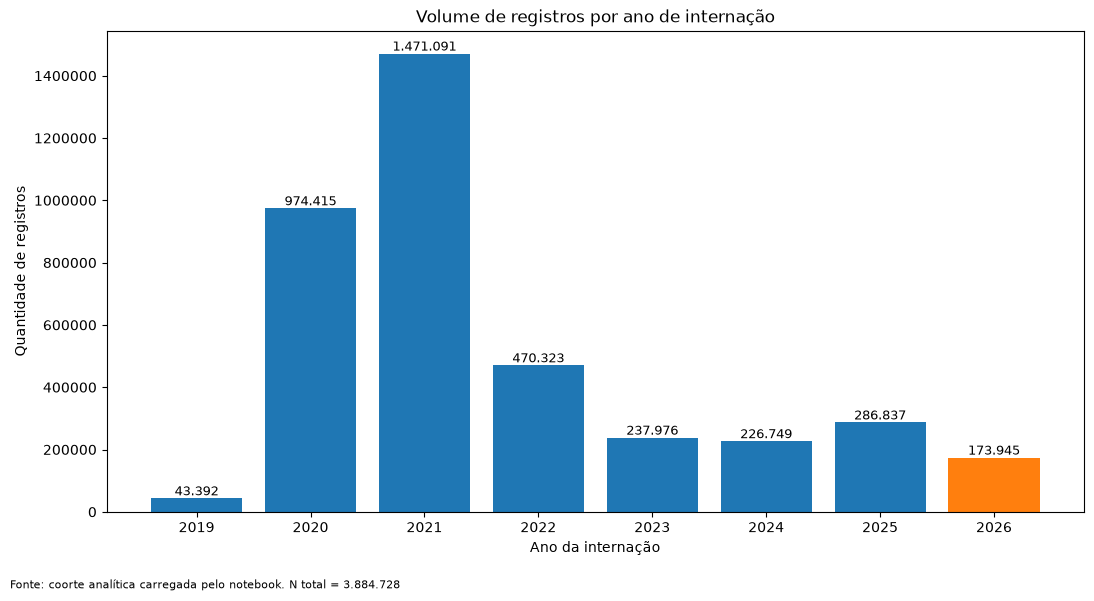

Figura salva em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\eda_02_volume_por_ano.png


In [10]:
anos_volume = (
    resumo_temporal[
        "ano_internacao"
    ]
    .astype(int)
    .astype(str)
)

quantidades_volume = (
    resumo_temporal[
        "quantidade_registros"
    ]
)

cores_volume = [
    (
        "tab:orange"
        if ano == 2026
        else "tab:blue"
    )
    for ano in resumo_temporal[
        "ano_internacao"
    ]
]

figura_volume, eixo_volume = plt.subplots(
    figsize=(
        11,
        6,
    )
)

barras_volume = eixo_volume.bar(
    anos_volume,
    quantidades_volume,
    color=cores_volume,
)

eixo_volume.set_title(
    "Volume de registros por ano de internação"
)

eixo_volume.set_xlabel(
    "Ano da internação"
)

eixo_volume.set_ylabel(
    "Quantidade de registros"
)

eixo_volume.ticklabel_format(
    style="plain",
    axis="y",
)

for barra, quantidade in zip(
    barras_volume,
    quantidades_volume,
):
    rotulo_quantidade = (
        f"{int(quantidade):,}"
        .replace(
            ",",
            ".",
        )
    )

    eixo_volume.text(
        barra.get_x()
        + barra.get_width()
        / 2,
        barra.get_height(),
        rotulo_quantidade,
        ha="center",
        va="bottom",
        fontsize=9,
    )

figura_volume.text(
    0.01,
    0.01,
    (
        "Fonte: coorte analítica carregada pelo notebook. "
        f"N total = {len(coorte):,}"
        .replace(
            ",",
            ".",
        )
    ),
    fontsize=8,
)

figura_volume.tight_layout(
    rect=[
        0,
        0.04,
        1,
        1,
    ]
)

figura_volume.savefig(
    CAMINHO_FIGURA_VOLUME_ANO,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figura salva em:",
    CAMINHO_FIGURA_VOLUME_ANO,
)

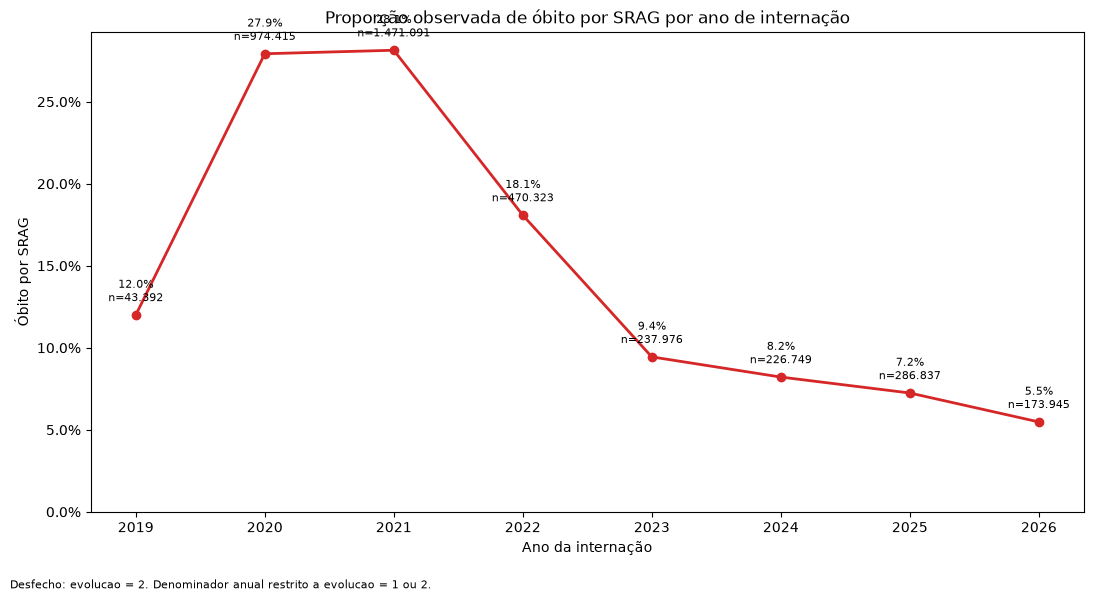

Figura salva em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\eda_02_proporcao_obito_por_ano.png


In [11]:
anos_alvo = (
    alvo_por_ano[
        "ano_internacao"
    ]
    .astype(int)
)

percentuais_obito = (
    alvo_por_ano[
        "percentual_obito_srag"
    ]
)

denominadores_ano = (
    alvo_por_ano[
        "quantidade_total"
    ]
)

figura_alvo, eixo_alvo = plt.subplots(
    figsize=(
        11,
        6,
    )
)

eixo_alvo.plot(
    anos_alvo,
    percentuais_obito,
    color="tab:red",
    marker="o",
    linewidth=2,
)

eixo_alvo.set_title(
    "Proporção observada de óbito por SRAG por ano de internação"
)

eixo_alvo.set_xlabel(
    "Ano da internação"
)

eixo_alvo.set_ylabel(
    "Óbito por SRAG"
)

eixo_alvo.set_xticks(
    anos_alvo
)

eixo_alvo.set_ylim(
    bottom=0,
)

eixo_alvo.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.1f}%"
        )
    )
)

for ano, percentual, denominador in zip(
    anos_alvo,
    percentuais_obito,
    denominadores_ano,
):
    denominador_formatado = (
        f"{int(denominador):,}"
        .replace(
            ",",
            ".",
        )
    )

    rotulo_ponto = (
        f"{percentual:.1f}%\n"
        f"n={denominador_formatado}"
    )

    eixo_alvo.annotate(
        rotulo_ponto,
        (
            ano,
            percentual,
        ),
        textcoords="offset points",
        xytext=(
            0,
            10,
        ),
        ha="center",
        fontsize=8,
    )

figura_alvo.text(
    0.01,
    0.01,
    (
        "Desfecho: evolucao = 2. "
        "Denominador anual restrito a evolucao = 1 ou 2."
    ),
    fontsize=8,
)

figura_alvo.tight_layout(
    rect=[
        0,
        0.04,
        1,
        1,
    ]
)

figura_alvo.savefig(
    CAMINHO_FIGURA_ALVO_ANO,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figura salva em:",
    CAMINHO_FIGURA_ALVO_ANO,
)

In [12]:
volume_por_ano.to_csv(
    CAMINHO_VOLUME_ANO,
    index=False,
    encoding="utf-8-sig",
)

alvo_por_ano.to_csv(
    CAMINHO_ALVO_ANO,
    index=False,
    encoding="utf-8-sig",
)

CAMINHO_RESUMO_TEMPORAL = (
    C.TABLES_DIR
    / "eda_02_resumo_temporal.csv"
)

resumo_temporal.to_csv(
    CAMINHO_RESUMO_TEMPORAL,
    index=False,
    encoding="utf-8-sig",
)

print(
    "Volume por ano salvo em:",
    CAMINHO_VOLUME_ANO,
)

print(
    "Distribuição do alvo salva em:",
    CAMINHO_ALVO_ANO,
)

print(
    "Resumo temporal salvo em:",
    CAMINHO_RESUMO_TEMPORAL,
)

Volume por ano salvo em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\eda_02_volume_por_ano.csv
Distribuição do alvo salva em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\eda_02_alvo_por_ano.csv
Resumo temporal salvo em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\eda_02_resumo_temporal.csv


In [13]:
ANOS_ESPERADOS = {
    2019,
    2020,
    2021,
    2022,
    2023,
    2024,
    2025,
    2026,
}

anos_observados = set(
    resumo_temporal[
        "ano_internacao"
    ]
    .dropna()
    .astype(int)
    .tolist()
)

verificacoes_temporais = {
    "volume_nao_vazio": (
        not volume_por_ano.empty
    ),
    "alvo_por_ano_nao_vazio": (
        not alvo_por_ano.empty
    ),
    "resumo_temporal_nao_vazio": (
        not resumo_temporal.empty
    ),
    "soma_volume_igual_coorte": (
        total_volume_por_ano
        == len(
            coorte
        )
    ),
    "soma_alvo_igual_coorte": (
        total_alvo_por_ano
        == len(
            coorte
        )
    ),
    "todos_anos_esperados_presentes": (
        ANOS_ESPERADOS
        .issubset(
            anos_observados
        )
    ),
    "percentual_obito_valido": (
        alvo_por_ano[
            "percentual_obito_srag"
        ]
        .between(
            0,
            100,
        )
        .all()
    ),
    "arquivo_volume_criado": (
        CAMINHO_VOLUME_ANO.exists()
    ),
    "arquivo_alvo_criado": (
        CAMINHO_ALVO_ANO.exists()
    ),
    "arquivo_resumo_temporal_criado": (
        CAMINHO_RESUMO_TEMPORAL.exists()
    ),
    "figura_volume_criada": (
        CAMINHO_FIGURA_VOLUME_ANO.exists()
    ),
    "figura_alvo_criada": (
        CAMINHO_FIGURA_ALVO_ANO.exists()
    ),
}

verificacoes_temporais_df = pd.DataFrame(
    {
        "verificacao": list(
            verificacoes_temporais.keys()
        ),
        "resultado": list(
            verificacoes_temporais.values()
        ),
    }
)

display(
    verificacoes_temporais_df
)

if not all(
    verificacoes_temporais.values()
):
    falhas_temporais = [
        verificacao
        for verificacao, resultado
        in verificacoes_temporais.items()
        if not resultado
    ]

    raise RuntimeError(
        "A seção temporal terminou com falhas: "
        f"{falhas_temporais}"
    )

print(
    "Distribuição temporal validada com sucesso."
)

,verificacao,resultado
0,volume_nao_vazio,True
1,alvo_por_ano_nao_vazio,True
2,resumo_temporal_nao_vazio,True
3,soma_volume_igual_coorte,True
4,soma_alvo_igual_coorte,True
5,todos_anos_esperados_presentes,True
6,percentual_obito_valido,True
7,arquivo_volume_criado,True
8,arquivo_alvo_criado,True
9,arquivo_resumo_temporal_criado,True


Distribuição temporal validada com sucesso.


## 2. Idade e características demográficas

A idade registrada no SIVEP-Gripe utiliza dois campos:

- `nu_idade_n`: valor informado;
- `tp_idade`: unidade do valor, sendo dias, meses ou anos.

Nesta seção, os dois campos serão combinados para produzir uma idade
padronizada em anos.

A análise incluirá:

- auditoria da conversão da idade;
- mediana e intervalo interquartil por ano;
- distribuição por faixa etária;
- distribuição do sexo registrado por ano;
- proporção de valores ausentes ou inválidos.

Os campos originais serão preservados.

In [14]:
CAMINHO_IDADE_ANO = (
    C.TABLES_DIR
    / "eda_02_idade_por_ano.csv"
)

CAMINHO_FAIXA_ETARIA_ANO = (
    C.TABLES_DIR
    / "eda_02_faixa_etaria_por_ano.csv"
)

CAMINHO_SEXO_ANO = (
    C.TABLES_DIR
    / "eda_02_sexo_por_ano.csv"
)

CAMINHO_AUDITORIA_IDADE = (
    C.TABLES_DIR
    / "eda_02_auditoria_idade.csv"
)

CAMINHO_FIGURA_IDADE_ANO = (
    C.FIGURES_DIR
    / "eda_02_idade_por_ano.png"
)

CAMINHO_FIGURA_FAIXA_ETARIA = (
    C.FIGURES_DIR
    / "eda_02_faixa_etaria_por_ano.png"
)

print(
    "Tabela de idade:",
    CAMINHO_IDADE_ANO,
)

print(
    "Tabela de faixa etária:",
    CAMINHO_FAIXA_ETARIA_ANO,
)

print(
    "Tabela de sexo:",
    CAMINHO_SEXO_ANO,
)

Tabela de idade: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\eda_02_idade_por_ano.csv
Tabela de faixa etária: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\eda_02_faixa_etaria_por_ano.csv
Tabela de sexo: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\eda_02_sexo_por_ano.csv


In [15]:
from src.features import montar_features

COLUNAS_ORIGEM_DEMOGRAFIA = [
    "nu_idade_n",
    "tp_idade",
    "cs_sexo",
]

colunas_origem_ausentes = [
    coluna
    for coluna in COLUNAS_ORIGEM_DEMOGRAFIA
    if coluna not in coorte.columns
]

if colunas_origem_ausentes:
    raise KeyError(
        "A coorte não contém as colunas de origem necessárias: "
        f"{colunas_origem_ausentes}"
    )

quantidade_linhas_antes = len(coorte)
indice_antes = coorte.index.copy()

coorte = montar_features(coorte)

COLUNAS_DEMOGRAFICAS_CENTRALIZADAS = [
    "idade_anos",
    "faixa_etaria",
    "sexo_categoria",
]

colunas_demograficas_ausentes = [
    coluna
    for coluna in COLUNAS_DEMOGRAFICAS_CENTRALIZADAS
    if coluna not in coorte.columns
]

if colunas_demograficas_ausentes:
    raise KeyError(
        "A engenharia centralizada não produziu as colunas esperadas: "
        f"{colunas_demograficas_ausentes}"
    )

if len(coorte) != quantidade_linhas_antes:
    raise RuntimeError(
        "A engenharia de atributos alterou a quantidade de registros: "
        f"{quantidade_linhas_antes} -> {len(coorte)}"
    )

if not coorte.index.equals(indice_antes):
    raise RuntimeError(
        "A engenharia de atributos alterou o índice ou a ordem dos registros."
    )

idade_valor = pd.to_numeric(
    coorte["nu_idade_n"],
    errors="coerce",
)

tipo_idade = (
    coorte["tp_idade"]
    .astype("string")
    .str.strip()
    .str.replace(
        r"\.0$",
        "",
        regex=True,
    )
    .replace(
        {
            "": pd.NA,
            "nan": pd.NA,
            "NaN": pd.NA,
            "None": pd.NA,
            "<NA>": pd.NA,
        }
    )
)

coorte["flag_idade_ausente"] = (
    idade_valor.isna()
    | tipo_idade.isna()
).astype("int8")

coorte["flag_tipo_idade_invalido"] = (
    tipo_idade.notna()
    & ~tipo_idade.isin(["1", "2", "3"])
).astype("int8")

coorte["flag_idade_nao_convertida"] = (
    idade_valor.notna()
    & tipo_idade.notna()
    & coorte["idade_anos"].isna()
).astype("int8")

print(
    "Idades padronizadas válidas:",
    int(coorte["idade_anos"].notna().sum()),
)
print(
    "Idades ausentes:",
    int(coorte["flag_idade_ausente"].sum()),
)
print(
    "Idades não convertidas ou implausíveis:",
    int(coorte["flag_idade_nao_convertida"].sum()),
)
print(
    "Tipos de idade inválidos:",
    int(coorte["flag_tipo_idade_invalido"].sum()),
)
print(
    "Categorias de faixa etária:",
    coorte["faixa_etaria"].cat.categories.tolist(),
)
print(
    "Categorias de sexo:",
    coorte["sexo_categoria"].cat.categories.tolist(),
)


Idades padronizadas válidas: 3884704
Idades ausentes: 0
Idades não convertidas ou implausíveis: 24
Tipos de idade inválidos: 0
Categorias de faixa etária: ['1-4', '12-17', '18-39', '40-59', '5-11', '60-79', '80+', '<1', 'desconhecida']
Categorias de sexo: ['feminino', 'ignorado', 'masculino']


In [16]:
auditoria_idade = (
    pd.DataFrame(
        {
            "tipo_idade": tipo_idade,
            "idade_valor_original": idade_valor,
            "idade_anos": coorte[
                "idade_anos"
            ],
            "flag_idade_ausente": coorte[
                "flag_idade_ausente"
            ],
            "flag_idade_nao_convertida": coorte[
                "flag_idade_nao_convertida"
            ],
            "flag_tipo_idade_invalido": coorte[
                "flag_tipo_idade_invalido"
            ],
        }
    )
    .groupby(
        "tipo_idade",
        dropna=False,
    )
    .agg(
        quantidade_registros=(
            "idade_valor_original",
            "size",
        ),
        quantidade_valor_informado=(
            "idade_valor_original",
            "count",
        ),
        quantidade_idade_convertida=(
            "idade_anos",
            "count",
        ),
        quantidade_idade_ausente=(
            "flag_idade_ausente",
            "sum",
        ),
        quantidade_nao_convertida=(
            "flag_idade_nao_convertida",
            "sum",
        ),
        quantidade_tipo_invalido=(
            "flag_tipo_idade_invalido",
            "sum",
        ),
    )
    .reset_index()
)

auditoria_idade[
    "percentual_convertido"
] = (
    auditoria_idade[
        "quantidade_idade_convertida"
    ]
    .div(
        auditoria_idade[
            "quantidade_registros"
        ]
    )
    .mul(100)
)

display(
    auditoria_idade
)

,tipo_idade,quantidade_registros,quantidade_valor_informado,quantidade_idade_convertida,quantidade_idade_ausente,quantidade_nao_convertida,quantidade_tipo_invalido,percentual_convertido
0,1,26271,26271,26270,0,1,0,99.996194
1,2,352745,352745,352730,0,15,0,99.995748
2,3,3505712,3505712,3505704,0,8,0,99.999772


In [17]:
idade_por_ano = (
    coorte.groupby(
        "ano_internacao",
        dropna=False,
    )
    .agg(
        quantidade_registros=(
            "ano_internacao",
            "size",
        ),
        quantidade_idade_valida=(
            "idade_anos",
            "count",
        ),
        idade_media=(
            "idade_anos",
            "mean",
        ),
        idade_mediana=(
            "idade_anos",
            "median",
        ),
        idade_minima=(
            "idade_anos",
            "min",
        ),
        idade_maxima=(
            "idade_anos",
            "max",
        ),
    )
    .reset_index()
    .sort_values(
        "ano_internacao"
    )
    .reset_index(drop=True)
)

quantil_25_idade = (
    coorte.groupby(
        "ano_internacao",
        dropna=False,
    )[
        "idade_anos"
    ]
    .quantile(0.25)
    .rename(
        "idade_q1"
    )
    .reset_index()
)

quantil_75_idade = (
    coorte.groupby(
        "ano_internacao",
        dropna=False,
    )[
        "idade_anos"
    ]
    .quantile(0.75)
    .rename(
        "idade_q3"
    )
    .reset_index()
)

idade_por_ano = (
    idade_por_ano.merge(
        quantil_25_idade,
        on="ano_internacao",
        how="left",
        validate="one_to_one",
    )
    .merge(
        quantil_75_idade,
        on="ano_internacao",
        how="left",
        validate="one_to_one",
    )
)

idade_por_ano[
    "idade_iqr"
] = (
    idade_por_ano[
        "idade_q3"
    ]
    .sub(
        idade_por_ano[
            "idade_q1"
        ]
    )
)

idade_por_ano[
    "quantidade_idade_ausente"
] = (
    idade_por_ano[
        "quantidade_registros"
    ]
    .sub(
        idade_por_ano[
            "quantidade_idade_valida"
        ]
    )
)

idade_por_ano[
    "percentual_idade_ausente"
] = (
    idade_por_ano[
        "quantidade_idade_ausente"
    ]
    .div(
        idade_por_ano[
            "quantidade_registros"
        ]
    )
    .mul(100)
)

COLUNAS_IDADE_ANO = [
    "ano_internacao",
    "quantidade_registros",
    "quantidade_idade_valida",
    "quantidade_idade_ausente",
    "percentual_idade_ausente",
    "idade_media",
    "idade_mediana",
    "idade_q1",
    "idade_q3",
    "idade_iqr",
    "idade_minima",
    "idade_maxima",
]

idade_por_ano = (
    idade_por_ano[
        COLUNAS_IDADE_ANO
    ]
    .copy()
)

display(
    idade_por_ano
)

,ano_internacao,quantidade_registros,quantidade_idade_valida,quantidade_idade_ausente,percentual_idade_ausente,idade_media,idade_mediana,idade_q1,idade_q3,idade_iqr,idade_minima,idade_maxima
0,2019,43392,43392,0,0.0,24.570303,5.0,0.666667,50.0,49.333333,0.0,108.0
1,2020,974415,974411,4,0.000411,56.894779,60.0,43.000000,74.0,31.000000,0.0,120.0
2,2021,1471091,1471083,8,0.000544,53.559093,56.0,41.000000,70.0,29.000000,0.0,119.0
3,2022,470323,470319,4,0.00085,47.340607,58.0,5.000000,77.0,72.000000,0.0,118.0
4,2023,237976,237973,3,0.001261,29.865681,7.0,0.916667,66.0,65.083333,0.0,117.0
5,2024,226749,226745,4,0.001764,28.117401,6.0,0.833333,63.0,62.166667,0.0,114.0
6,2025,286837,286836,1,0.000349,27.306364,5.0,0.750000,62.0,61.250000,0.0,114.0
7,2026,173945,173945,0,0.0,23.570118,3.0,0.750000,53.0,52.250000,0.0,115.0


In [18]:
COLUNAS_DEMOGRAFICAS_CENTRALIZADAS = [
    "idade_anos",
    "faixa_etaria",
    "sexo_categoria",
]

colunas_demograficas_ausentes = [
    coluna
    for coluna in COLUNAS_DEMOGRAFICAS_CENTRALIZADAS
    if coluna not in coorte.columns
]

if colunas_demograficas_ausentes:
    raise KeyError(
        "A coorte não contém todas as variáveis demográficas "
        "centralizadas necessárias para esta análise: "
        f"{colunas_demograficas_ausentes}"
    )

if not isinstance(coorte["faixa_etaria"].dtype, pd.CategoricalDtype):
    raise TypeError(
        "faixa_etaria não preservou o tipo categórico centralizado."
    )

if not isinstance(coorte["sexo_categoria"].dtype, pd.CategoricalDtype):
    raise TypeError(
        "sexo_categoria não preservou o tipo categórico centralizado."
    )

ROTULOS_FAIXA_ETARIA = (
    coorte["faixa_etaria"]
    .cat.categories
    .astype("string")
    .tolist()
)

ROTULOS_SEXO = (
    coorte["sexo_categoria"]
    .cat.categories
    .astype("string")
    .tolist()
)

ROTULO_FAIXA_AUSENTE = "idade ausente ou inválida"
ROTULO_SEXO_AUSENTE = "sexo ausente ou inesperado"

faixa_etaria_eda = (
    coorte["faixa_etaria"]
    .astype("string")
    .fillna(ROTULO_FAIXA_AUSENTE)
)

sexo_categoria_eda = (
    coorte["sexo_categoria"]
    .astype("string")
    .fillna(ROTULO_SEXO_AUSENTE)
)

ORDEM_FAIXA_ETARIA = (
    ROTULOS_FAIXA_ETARIA
    + [ROTULO_FAIXA_AUSENTE]
)

ORDEM_SEXO = (
    ROTULOS_SEXO
    + [ROTULO_SEXO_AUSENTE]
)

faixa_etaria_por_ano = (
    pd.DataFrame(
        {
            "ano_internacao": coorte["ano_internacao"],
            "faixa_etaria": faixa_etaria_eda,
        }
    )
    .groupby(
        ["ano_internacao", "faixa_etaria"],
        dropna=False,
    )
    .size()
    .rename("quantidade")
    .reset_index()
)

faixa_etaria_por_ano["percentual_ano"] = (
    faixa_etaria_por_ano["quantidade"]
    .div(
        faixa_etaria_por_ano.groupby(
            "ano_internacao"
        )["quantidade"].transform("sum")
    )
    .mul(100)
)

ordem_faixa = {
    categoria: posicao
    for posicao, categoria in enumerate(ORDEM_FAIXA_ETARIA)
}

faixa_etaria_por_ano["ordem_faixa"] = (
    faixa_etaria_por_ano["faixa_etaria"]
    .map(ordem_faixa)
    .fillna(len(ordem_faixa))
)

faixa_etaria_por_ano = (
    faixa_etaria_por_ano
    .sort_values(["ano_internacao", "ordem_faixa"])
    .drop(columns=["ordem_faixa"])
    .reset_index(drop=True)
)

sexo_por_ano = (
    pd.DataFrame(
        {
            "ano_internacao": coorte["ano_internacao"],
            "sexo_categoria": sexo_categoria_eda,
        }
    )
    .groupby(
        ["ano_internacao", "sexo_categoria"],
        dropna=False,
    )
    .size()
    .rename("quantidade")
    .reset_index()
)

sexo_por_ano["percentual_ano"] = (
    sexo_por_ano["quantidade"]
    .div(
        sexo_por_ano.groupby(
            "ano_internacao"
        )["quantidade"].transform("sum")
    )
    .mul(100)
)

ordem_sexo = {
    categoria: posicao
    for posicao, categoria in enumerate(ORDEM_SEXO)
}

sexo_por_ano["ordem_sexo"] = (
    sexo_por_ano["sexo_categoria"]
    .map(ordem_sexo)
    .fillna(len(ordem_sexo))
)

sexo_por_ano = (
    sexo_por_ano
    .sort_values(["ano_internacao", "ordem_sexo"])
    .drop(columns=["ordem_sexo"])
    .reset_index(drop=True)
)

auditoria_categorias_demograficas = pd.DataFrame(
    {
        "variavel": ["faixa_etaria", "sexo_categoria"],
        "quantidade_registros": [len(coorte), len(coorte)],
        "quantidade_categorias": [
            coorte["faixa_etaria"].nunique(dropna=True),
            coorte["sexo_categoria"].nunique(dropna=True),
        ],
        "quantidade_ausente_ou_invalida": [
            int(coorte["faixa_etaria"].isna().sum()),
            int(coorte["sexo_categoria"].isna().sum()),
        ],
    }
)

display(auditoria_categorias_demograficas)
display(faixa_etaria_por_ano.head(30))
display(sexo_por_ano)


,variavel,quantidade_registros,quantidade_categorias,quantidade_ausente_ou_invalida
0,faixa_etaria,3884728,9,0
1,sexo_categoria,3884728,3,0


,ano_internacao,faixa_etaria,quantidade,percentual_ano
0,2019,1-4,8187,18.867533
1,2019,12-17,931,2.145557
2,2019,18-39,5047,11.631176
3,2019,40-59,5303,12.221147
4,2019,5-11,2752,6.342183
5,2019,60-79,5591,12.884864
6,2019,80+,2476,5.706121
7,2019,<1,13105,30.201420
8,2020,1-4,24369,2.500885
9,2020,12-17,9204,0.944567


,ano_internacao,sexo_categoria,quantidade,percentual_ano
0,2019,feminino,21110,48.649521
1,2019,ignorado,12,0.027655
2,2019,masculino,22270,51.322824
3,2020,feminino,444414,45.608288
4,2020,ignorado,216,0.022167
5,2020,masculino,529785,54.369545
6,2021,feminino,666186,45.285166
7,2021,ignorado,175,0.011896
8,2021,masculino,804730,54.702938
9,2022,feminino,232830,49.504277


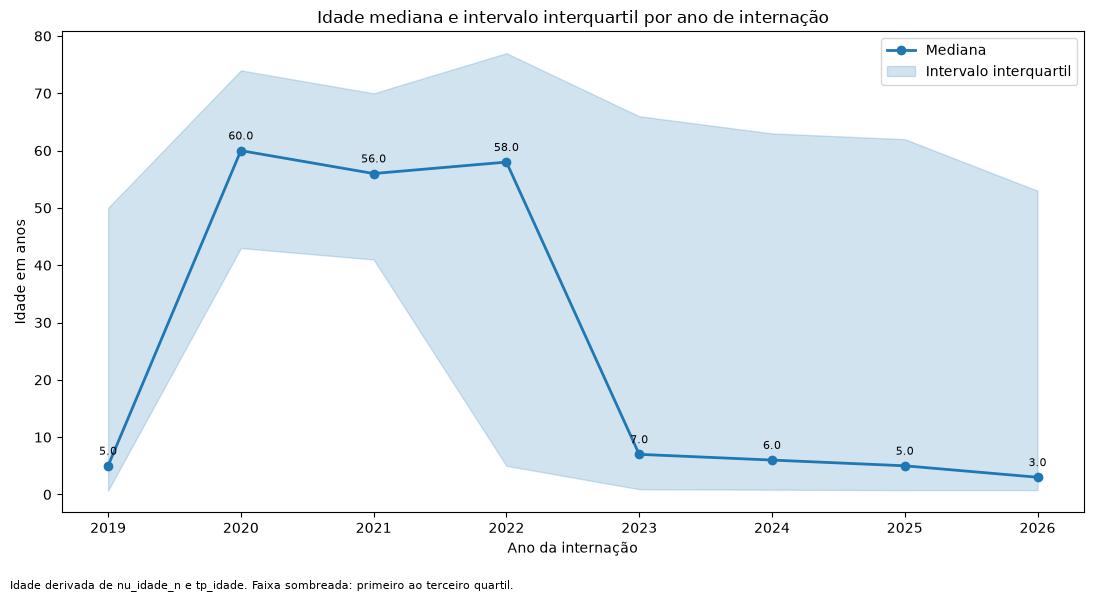

Figura salva em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\eda_02_idade_por_ano.png


In [19]:
anos_idade = (
    idade_por_ano[
        "ano_internacao"
    ]
    .astype(int)
    .to_numpy()
)

idade_mediana_grafico = (
    idade_por_ano[
        "idade_mediana"
    ]
    .astype(float)
    .to_numpy()
)

idade_q1_grafico = (
    idade_por_ano[
        "idade_q1"
    ]
    .astype(float)
    .to_numpy()
)

idade_q3_grafico = (
    idade_por_ano[
        "idade_q3"
    ]
    .astype(float)
    .to_numpy()
)

figura_idade, eixo_idade = plt.subplots(
    figsize=(
        11,
        6,
    )
)

eixo_idade.plot(
    anos_idade,
    idade_mediana_grafico,
    color="tab:blue",
    marker="o",
    linewidth=2,
    label="Mediana",
)

eixo_idade.fill_between(
    anos_idade,
    idade_q1_grafico,
    idade_q3_grafico,
    color="tab:blue",
    alpha=0.2,
    label="Intervalo interquartil",
)

eixo_idade.set_title(
    "Idade mediana e intervalo interquartil por ano de internação"
)

eixo_idade.set_xlabel(
    "Ano da internação"
)

eixo_idade.set_ylabel(
    "Idade em anos"
)

eixo_idade.set_xticks(
    anos_idade
)

eixo_idade.legend()

for ano, mediana in zip(
    anos_idade,
    idade_mediana_grafico,
):
    eixo_idade.annotate(
        f"{mediana:.1f}",
        (
            ano,
            mediana,
        ),
        textcoords="offset points",
        xytext=(
            0,
            8,
        ),
        ha="center",
        fontsize=8,
    )

figura_idade.text(
    0.01,
    0.01,
    (
        "Idade derivada de nu_idade_n e tp_idade. "
        "Faixa sombreada: primeiro ao terceiro quartil."
    ),
    fontsize=8,
)

figura_idade.tight_layout(
    rect=[
        0,
        0.04,
        1,
        1,
    ]
)

figura_idade.savefig(
    CAMINHO_FIGURA_IDADE_ANO,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figura salva em:",
    CAMINHO_FIGURA_IDADE_ANO,
)

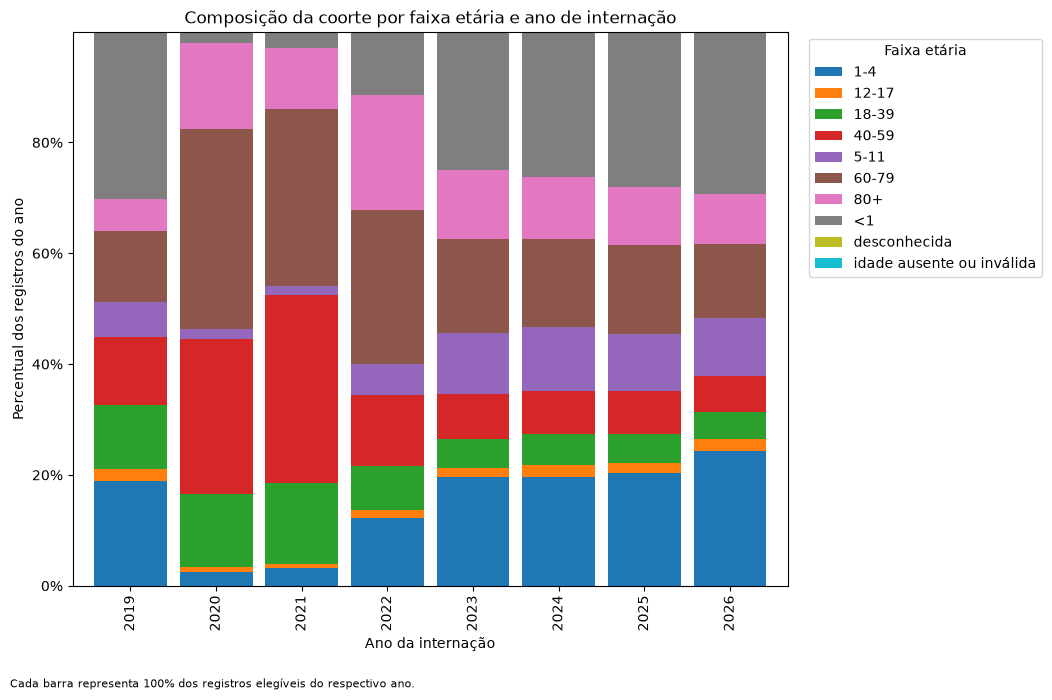

Figura salva em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\eda_02_faixa_etaria_por_ano.png


In [20]:
if "ORDEM_FAIXA_ETARIA" not in globals():
    raise NameError(
        "A ordem centralizada das faixas etárias não foi criada. "
        "Execute novamente a célula demográfica desde o início."
    )

faixa_etaria_grafico = (
    faixa_etaria_por_ano.pivot(
        index="ano_internacao",
        columns="faixa_etaria",
        values="percentual_ano",
    )
    .reindex(
        columns=ORDEM_FAIXA_ETARIA,
        fill_value=0,
    )
    .fillna(0)
)

figura_faixa, eixo_faixa = plt.subplots(
    figsize=(
        13,
        7,
    )
)

faixa_etaria_grafico.plot(
    kind="bar",
    stacked=True,
    ax=eixo_faixa,
    width=0.85,
)

eixo_faixa.set_title(
    "Composição da coorte por faixa etária e ano de internação"
)

eixo_faixa.set_xlabel(
    "Ano da internação"
)

eixo_faixa.set_ylabel(
    "Percentual dos registros do ano"
)

eixo_faixa.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

eixo_faixa.legend(
    title="Faixa etária",
    bbox_to_anchor=(
        1.02,
        1,
    ),
    loc="upper left",
)

figura_faixa.text(
    0.01,
    0.01,
    (
        "Cada barra representa 100% dos registros elegíveis "
        "do respectivo ano."
    ),
    fontsize=8,
)

figura_faixa.tight_layout(
    rect=[
        0,
        0.04,
        0.82,
        1,
    ]
)

figura_faixa.savefig(
    CAMINHO_FIGURA_FAIXA_ETARIA,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figura salva em:",
    CAMINHO_FIGURA_FAIXA_ETARIA,
)

In [21]:
idade_por_ano.to_csv(
    CAMINHO_IDADE_ANO,
    index=False,
    encoding="utf-8-sig",
)

faixa_etaria_por_ano.to_csv(
    CAMINHO_FAIXA_ETARIA_ANO,
    index=False,
    encoding="utf-8-sig",
)

sexo_por_ano.to_csv(
    CAMINHO_SEXO_ANO,
    index=False,
    encoding="utf-8-sig",
)

auditoria_idade.to_csv(
    CAMINHO_AUDITORIA_IDADE,
    index=False,
    encoding="utf-8-sig",
)

total_faixa_etaria = int(
    faixa_etaria_por_ano[
        "quantidade"
    ]
    .sum()
)

total_sexo = int(
    sexo_por_ano[
        "quantidade"
    ]
    .sum()
)

LIMITE_MINIMO_IDADE = 0.0
LIMITE_MAXIMO_IDADE = 120.0

idades_validas = (
    coorte["idade_anos"]
    .dropna()
)

idade_valida_entre_limites = (
    idades_validas
    .between(
        LIMITE_MINIMO_IDADE,
        LIMITE_MAXIMO_IDADE,
        inclusive="both",
    )
    .all()
)

verificacoes_demograficas = {
    "idade_por_ano_nao_vazia": (
        not idade_por_ano.empty
    ),
    "faixa_etaria_nao_vazia": (
        not faixa_etaria_por_ano.empty
    ),
    "sexo_por_ano_nao_vazio": (
        not sexo_por_ano.empty
    ),
    "total_faixa_etaria_igual_coorte": (
        total_faixa_etaria
        == len(coorte)
    ),
    "total_sexo_igual_coorte": (
        total_sexo
        == len(coorte)
    ),
    "idade_valida_entre_zero_e_120": (
        bool(idade_valida_entre_limites)
    ),
    "arquivo_idade_criado": (
        CAMINHO_IDADE_ANO.exists()
    ),
    "arquivo_faixa_etaria_criado": (
        CAMINHO_FAIXA_ETARIA_ANO.exists()
    ),
    "arquivo_sexo_criado": (
        CAMINHO_SEXO_ANO.exists()
    ),
    "arquivo_auditoria_idade_criado": (
        CAMINHO_AUDITORIA_IDADE.exists()
    ),
    "figura_idade_criada": (
        CAMINHO_FIGURA_IDADE_ANO.exists()
    ),
    "figura_faixa_etaria_criada": (
        CAMINHO_FIGURA_FAIXA_ETARIA.exists()
    ),
}

verificacoes_demograficas_df = pd.DataFrame(
    {
        "verificacao": list(
            verificacoes_demograficas.keys()
        ),
        "resultado": list(
            verificacoes_demograficas.values()
        ),
    }
)

display(
    verificacoes_demograficas_df
)

if not all(
    verificacoes_demograficas.values()
):
    falhas_demograficas = [
        verificacao
        for verificacao, resultado
        in verificacoes_demograficas.items()
        if not resultado
    ]

    raise RuntimeError(
        "A seção demográfica terminou com falhas: "
        f"{falhas_demograficas}"
    )

print(
    "Análise demográfica validada com sucesso."
)

,verificacao,resultado
0,idade_por_ano_nao_vazia,True
1,faixa_etaria_nao_vazia,True
2,sexo_por_ano_nao_vazio,True
3,total_faixa_etaria_igual_coorte,True
4,total_sexo_igual_coorte,True
5,idade_valida_entre_zero_e_120,True
6,arquivo_idade_criado,True
7,arquivo_faixa_etaria_criado,True
8,arquivo_sexo_criado,True
9,arquivo_auditoria_idade_criado,True


Análise demográfica validada com sucesso.


## 3. Preenchimento das variáveis por ano

O preenchimento será analisado por variável e por ano de internação.

Nesta seção, ausência corresponde ao valor nulo armazenado na base.
Categorias como ignorado, não se aplica e resposta negativa não serão
automaticamente interpretadas como ausência.

A análise terá dois objetivos:

- identificar variáveis com baixa cobertura;
- identificar mudanças relevantes de preenchimento entre os anos.

As tabelas serão produzidas em formato longo para facilitar filtros,
gráficos e análises posteriores por grupo de variáveis.

In [22]:
CAMINHO_DICIONARIO_OPERACIONAL = (
    C.CONFIGS_DIR
    / "dicionario_variaveis_v1.csv"
)

if not CAMINHO_DICIONARIO_OPERACIONAL.exists():
    raise FileNotFoundError(
        "O dicionário operacional não foi encontrado em: "
        f"{CAMINHO_DICIONARIO_OPERACIONAL}"
    )

dicionario_operacional = pd.read_csv(
    CAMINHO_DICIONARIO_OPERACIONAL,
    encoding="utf-8-sig",
    dtype="string",
    keep_default_na=False,
)

COLUNAS_DICIONARIO_NECESSARIAS = [
    "coluna",
    "nome_amigavel",
    "grupo",
    "uso_inicial_sugerido",
]

colunas_dicionario_ausentes = [
    coluna
    for coluna in COLUNAS_DICIONARIO_NECESSARIAS
    if coluna not in dicionario_operacional.columns
]

if colunas_dicionario_ausentes:
    raise KeyError(
        "O dicionário operacional não contém as colunas: "
        f"{colunas_dicionario_ausentes}"
    )

dicionario_operacional[
    "coluna"
] = (
    dicionario_operacional[
        "coluna"
    ]
    .astype("string")
    .str.strip()
)

dicionario_operacional = (
    dicionario_operacional.loc[
        dicionario_operacional[
            "coluna"
        ].ne("")
    ]
    .drop_duplicates(
        subset=[
            "coluna",
        ],
        keep="first",
    )
    .reset_index(drop=True)
)

colunas_dicionario_na_coorte = [
    coluna
    for coluna in dicionario_operacional[
        "coluna"
    ].tolist()
    if coluna in coorte.columns
]

colunas_dicionario_fora_coorte = [
    coluna
    for coluna in dicionario_operacional[
        "coluna"
    ].tolist()
    if coluna not in coorte.columns
]

if not colunas_dicionario_na_coorte:
    raise ValueError(
        "Nenhuma variável do dicionário foi encontrada na coorte."
    )

print(
    "Variáveis do dicionário encontradas na coorte:",
    len(
        colunas_dicionario_na_coorte
    ),
)

print(
    "Variáveis do dicionário ausentes na coorte:",
    len(
        colunas_dicionario_fora_coorte
    ),
)

if colunas_dicionario_fora_coorte:
    display(
        pd.DataFrame(
            {
                "coluna_ausente_na_coorte": (
                    colunas_dicionario_fora_coorte
                ),
            }
        )
    )

Variáveis do dicionário encontradas na coorte: 40
Variáveis do dicionário ausentes na coorte: 48


,coluna_ausente_na_coorte
0,dt_notific
1,sem_pri
2,hospital
3,cs_etinia
4,out_anim
5,tabag
6,outro_des
7,obes_imc
8,morb_desc
9,out_antiv


In [23]:
CAMINHO_PREENCHIMENTO_ANO = (
    C.TABLES_DIR
    / "eda_02_preenchimento_por_variavel_ano.csv"
)

CAMINHO_RESUMO_PREENCHIMENTO = (
    C.TABLES_DIR
    / "eda_02_resumo_preenchimento_variaveis.csv"
)

CAMINHO_VARIACAO_PREENCHIMENTO = (
    C.TABLES_DIR
    / "eda_02_variacao_preenchimento.csv"
)

CAMINHO_FIGURA_VARIACAO_PREENCHIMENTO = (
    C.FIGURES_DIR
    / "eda_02_variacao_preenchimento.png"
)

print(
    "Tabela anual de preenchimento:",
    CAMINHO_PREENCHIMENTO_ANO,
)

print(
    "Resumo de preenchimento:",
    CAMINHO_RESUMO_PREENCHIMENTO,
)

print(
    "Figura de variação:",
    CAMINHO_FIGURA_VARIACAO_PREENCHIMENTO,
)

Tabela anual de preenchimento: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\eda_02_preenchimento_por_variavel_ano.csv
Resumo de preenchimento: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\eda_02_resumo_preenchimento_variaveis.csv
Figura de variação: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\eda_02_variacao_preenchimento.png


In [24]:
quantidade_por_ano = (
    coorte.groupby(
        "ano_internacao",
        dropna=False,
    )
    .size()
    .rename(
        "quantidade_registros_ano"
    )
    .sort_index()
)

preenchidos_por_ano = (
    coorte.groupby(
        "ano_internacao",
        dropna=False,
    )[
        colunas_dicionario_na_coorte
    ]
    .count()
    .sort_index()
)

preenchidos_por_ano.index = (
    preenchidos_por_ano.index.astype(
        "Int64"
    )
)

quantidade_por_ano.index = (
    quantidade_por_ano.index.astype(
        "Int64"
    )
)

preenchimento_percentual_por_ano = (
    preenchidos_por_ano
    .div(
        quantidade_por_ano,
        axis=0,
    )
    .mul(100)
)

quantidade_preenchida_longa = (
    preenchidos_por_ano
    .reset_index()
    .melt(
        id_vars=[
            "ano_internacao",
        ],
        var_name="coluna",
        value_name="quantidade_preenchida",
    )
)

percentual_preenchido_longo = (
    preenchimento_percentual_por_ano
    .reset_index()
    .melt(
        id_vars=[
            "ano_internacao",
        ],
        var_name="coluna",
        value_name="percentual_preenchido",
    )
)

preenchimento_por_variavel_ano = (
    quantidade_preenchida_longa.merge(
        percentual_preenchido_longo,
        on=[
            "ano_internacao",
            "coluna",
        ],
        how="inner",
        validate="one_to_one",
    )
)

quantidade_por_ano_df = (
    quantidade_por_ano
    .reset_index()
)

preenchimento_por_variavel_ano = (
    preenchimento_por_variavel_ano.merge(
        quantidade_por_ano_df,
        on="ano_internacao",
        how="left",
        validate="many_to_one",
    )
)

preenchimento_por_variavel_ano[
    "quantidade_ausente"
] = (
    preenchimento_por_variavel_ano[
        "quantidade_registros_ano"
    ]
    .sub(
        preenchimento_por_variavel_ano[
            "quantidade_preenchida"
        ]
    )
)

preenchimento_por_variavel_ano[
    "percentual_ausente"
] = (
    100
    - preenchimento_por_variavel_ano[
        "percentual_preenchido"
    ]
)

metadados_variaveis = (
    dicionario_operacional[
        COLUNAS_DICIONARIO_NECESSARIAS
    ]
    .copy()
)

preenchimento_por_variavel_ano = (
    preenchimento_por_variavel_ano.merge(
        metadados_variaveis,
        on="coluna",
        how="left",
        validate="many_to_one",
    )
)

COLUNAS_PREENCHIMENTO_ANUAL = [
    "ano_internacao",
    "coluna",
    "nome_amigavel",
    "grupo",
    "uso_inicial_sugerido",
    "quantidade_registros_ano",
    "quantidade_preenchida",
    "quantidade_ausente",
    "percentual_preenchido",
    "percentual_ausente",
]

preenchimento_por_variavel_ano = (
    preenchimento_por_variavel_ano[
        COLUNAS_PREENCHIMENTO_ANUAL
    ]
    .sort_values(
        [
            "grupo",
            "coluna",
            "ano_internacao",
        ]
    )
    .reset_index(drop=True)
)

display(
    preenchimento_por_variavel_ano.head(30)
)

,ano_internacao,coluna,nome_amigavel,grupo,uso_inicial_sugerido,quantidade_registros_ano,quantidade_preenchida,quantidade_ausente,percentual_preenchido,percentual_ausente
0,2019,asma,Asma,comorbidades_fatores_risco,modelo_a_nucleo,43392,16823,26569,38.769819,61.230181
1,2020,asma,Asma,comorbidades_fatores_risco,modelo_a_nucleo,974415,427968,546447,43.920506,56.079494
2,2021,asma,Asma,comorbidades_fatores_risco,modelo_a_nucleo,1471091,533375,937716,36.257104,63.742896
3,2022,asma,Asma,comorbidades_fatores_risco,modelo_a_nucleo,470323,174237,296086,37.046243,62.953757
4,2023,asma,Asma,comorbidades_fatores_risco,modelo_a_nucleo,237976,74072,163904,31.125828,68.874172
5,2024,asma,Asma,comorbidades_fatores_risco,modelo_a_nucleo,226749,70734,156015,31.194845,68.805155
6,2025,asma,Asma,comorbidades_fatores_risco,modelo_a_nucleo,286837,93145,193692,32.473147,67.526853
7,2026,asma,Asma,comorbidades_fatores_risco,modelo_a_nucleo,173945,53572,120373,30.798241,69.201759
8,2019,cardiopati,Doenca cardiovascular cronica,comorbidades_fatores_risco,modelo_a_nucleo,43392,16972,26420,39.113201,60.886799
9,2020,cardiopati,Doenca cardiovascular cronica,comorbidades_fatores_risco,modelo_a_nucleo,974415,527716,446699,54.157212,45.842788


In [25]:
quantidade_total_coorte = len(
    coorte
)

quantidade_preenchida_global = (
    coorte[
        colunas_dicionario_na_coorte
    ]
    .count()
    .rename(
        "quantidade_preenchida"
    )
)

resumo_preenchimento_variaveis = (
    quantidade_preenchida_global
    .reset_index()
    .rename(
        columns={
            "index": "coluna",
        }
    )
)

resumo_preenchimento_variaveis[
    "quantidade_registros"
] = quantidade_total_coorte

resumo_preenchimento_variaveis[
    "quantidade_ausente"
] = (
    resumo_preenchimento_variaveis[
        "quantidade_registros"
    ]
    .sub(
        resumo_preenchimento_variaveis[
            "quantidade_preenchida"
        ]
    )
)

resumo_preenchimento_variaveis[
    "percentual_preenchido"
] = (
    resumo_preenchimento_variaveis[
        "quantidade_preenchida"
    ]
    .div(
        resumo_preenchimento_variaveis[
            "quantidade_registros"
        ]
    )
    .mul(100)
)

resumo_preenchimento_variaveis[
    "percentual_ausente"
] = (
    100
    - resumo_preenchimento_variaveis[
        "percentual_preenchido"
    ]
)

resumo_preenchimento_variaveis = (
    resumo_preenchimento_variaveis.merge(
        metadados_variaveis,
        on="coluna",
        how="left",
        validate="one_to_one",
    )
)

COLUNAS_RESUMO_PREENCHIMENTO = [
    "coluna",
    "nome_amigavel",
    "grupo",
    "uso_inicial_sugerido",
    "quantidade_registros",
    "quantidade_preenchida",
    "quantidade_ausente",
    "percentual_preenchido",
    "percentual_ausente",
]

resumo_preenchimento_variaveis = (
    resumo_preenchimento_variaveis[
        COLUNAS_RESUMO_PREENCHIMENTO
    ]
    .sort_values(
        [
            "percentual_preenchido",
            "grupo",
            "coluna",
        ],
        ascending=[
            True,
            True,
            True,
        ],
    )
    .reset_index(drop=True)
)

display(
    resumo_preenchimento_variaveis.head(30)
)

,coluna,nome_amigavel,grupo,uso_inicial_sugerido,quantidade_registros,quantidade_preenchida,quantidade_ausente,percentual_preenchido,percentual_ausente
0,puerpera,Puerpera ou parturiente,comorbidades_fatores_risco,modelo_a_nucleo,3884728,1397706,2487022,35.979507,64.020493
1,hepatica,Doenca hepatica cronica,comorbidades_fatores_risco,modelo_a_nucleo,3884728,1399538,2485190,36.026666,63.973334
2,sind_down,Sindrome de Down,comorbidades_fatores_risco,modelo_a_nucleo,3884728,1400612,2484116,36.054313,63.945687
3,hematologi,Doenca hematologica cronica,comorbidades_fatores_risco,modelo_a_nucleo,3884728,1404906,2479822,36.164849,63.835151
4,imunodepre,Imunodeficiencia ou imunodepressao,comorbidades_fatores_risco,modelo_a_nucleo,3884728,1421767,2462961,36.598882,63.401118
5,renal,Doenca renal cronica,comorbidades_fatores_risco,modelo_a_nucleo,3884728,1426204,2458524,36.713098,63.286902
6,neurologic,Doenca neurologica cronica,comorbidades_fatores_risco,modelo_a_nucleo,3884728,1443221,2441507,37.151147,62.848853
7,asma,Asma,comorbidades_fatores_risco,modelo_a_nucleo,3884728,1443926,2440802,37.169295,62.830705
8,pneumopati,Outra pneumopatia cronica,comorbidades_fatores_risco,modelo_a_nucleo,3884728,1444275,2440453,37.178279,62.821721
9,obesidade,Obesidade,comorbidades_fatores_risco,modelo_a_nucleo,3884728,1449319,2435409,37.308120,62.691880


In [26]:
variacao_preenchimento = (
    preenchimento_por_variavel_ano.groupby(
        [
            "coluna",
            "nome_amigavel",
            "grupo",
            "uso_inicial_sugerido",
        ],
        dropna=False,
    )
    .agg(
        preenchimento_minimo=(
            "percentual_preenchido",
            "min",
        ),
        preenchimento_maximo=(
            "percentual_preenchido",
            "max",
        ),
        preenchimento_medio=(
            "percentual_preenchido",
            "mean",
        ),
        quantidade_anos_observados=(
            "ano_internacao",
            "nunique",
        ),
    )
    .reset_index()
)

variacao_preenchimento[
    "amplitude_pontos_percentuais"
] = (
    variacao_preenchimento[
        "preenchimento_maximo"
    ]
    .sub(
        variacao_preenchimento[
            "preenchimento_minimo"
        ]
    )
)

variacao_preenchimento[
    "flag_variacao_20_pp"
] = (
    variacao_preenchimento[
        "amplitude_pontos_percentuais"
    ]
    .ge(20)
)

variacao_preenchimento = (
    variacao_preenchimento
    .sort_values(
        [
            "amplitude_pontos_percentuais",
            "coluna",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .reset_index(drop=True)
)

display(
    variacao_preenchimento.head(30)
)

,coluna,nome_amigavel,grupo,uso_inicial_sugerido,preenchimento_minimo,preenchimento_maximo,preenchimento_medio,quantidade_anos_observados,amplitude_pontos_percentuais,flag_variacao_20_pp
0,vacina_cov,Recebeu vacina contra COVID-19?,vacinacao_covid,modelo_a_nucleo,1.338956,99.993725,73.685134,8,98.654768,True
1,fadiga,Fadiga,sintomas,modelo_a_nucleo,0.523138,83.964472,63.423242,8,83.441334,True
2,dor_abd,Dor abdominal,sintomas,modelo_a_nucleo,0.274244,82.470321,61.557547,8,82.196077,True
3,perd_olft,Perda do olfato,sintomas,modelo_a_nucleo,0.269635,82.09549,61.261682,8,81.825855,True
4,perd_pala,Perda do paladar,sintomas,modelo_a_nucleo,0.26733,81.902325,61.179847,8,81.634995,True
5,vacina,Recebeu vacina contra influenza?,vacinacao_influenza,modelo_a_nucleo,56.119945,96.034379,78.088779,8,39.914434,True
6,cs_escol_n,Escolaridade,demografia_contexto_social,modelo_b_ampliado,62.544488,92.593105,69.350736,8,30.048617,True
7,diarreia,Diarreia,sintomas,modelo_a_nucleo,68.500158,97.607854,78.344364,8,29.107696,True
8,vomito,Vomito,sintomas,modelo_a_nucleo,69.104211,97.693123,78.517096,8,28.588912,True
9,garganta,Dor de garganta,sintomas,modelo_a_nucleo,70.390136,98.041114,78.838657,8,27.650977,True


,coluna,rotulo_variavel,grupo,uso_inicial_sugerido,preenchimento_minimo,preenchimento_maximo,amplitude_pontos_percentuais
0,vacina_cov,Recebeu vacina contra COVID-19?,vacinacao_covid,modelo_a_nucleo,1.338956,99.993725,98.654768
1,fadiga,Fadiga,sintomas,modelo_a_nucleo,0.523138,83.964472,83.441334
2,dor_abd,Dor abdominal,sintomas,modelo_a_nucleo,0.274244,82.470321,82.196077
3,perd_olft,Perda do olfato,sintomas,modelo_a_nucleo,0.269635,82.09549,81.825855
4,perd_pala,Perda do paladar,sintomas,modelo_a_nucleo,0.26733,81.902325,81.634995
5,vacina,Recebeu vacina contra influenza?,vacinacao_influenza,modelo_a_nucleo,56.119945,96.034379,39.914434
6,cs_escol_n,Escolaridade,demografia_contexto_social,modelo_b_ampliado,62.544488,92.593105,30.048617
7,diarreia,Diarreia,sintomas,modelo_a_nucleo,68.500158,97.607854,29.107696
8,vomito,Vomito,sintomas,modelo_a_nucleo,69.104211,97.693123,28.588912
9,garganta,Dor de garganta,sintomas,modelo_a_nucleo,70.390136,98.041114,27.650977


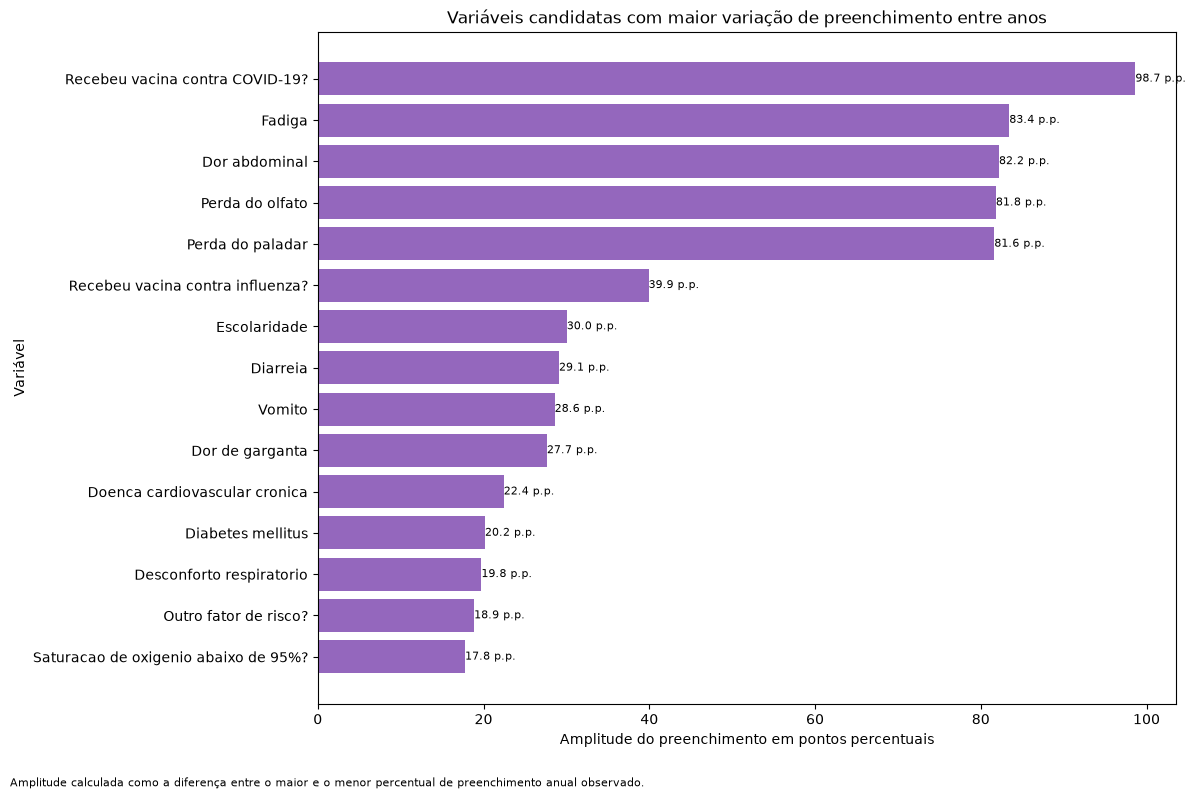

Figura salva em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\eda_02_variacao_preenchimento.png


In [27]:
USOS_RELEVANTES_PARA_GRAFICO = {
    "modelo_a_nucleo",
    "modelo_b_ampliado",
    "modelo_c_sensibilidade",
    "derivar_atributo",
    "reavaliar_apos_eda",
    "reavaliar_apos_modelo_principal",
    "exploracao_subgrupo",
}

variaveis_relevantes_variacao = (
    variacao_preenchimento.loc[
        variacao_preenchimento[
            "uso_inicial_sugerido"
        ].isin(
            USOS_RELEVANTES_PARA_GRAFICO
        )
    ]
    .copy()
)

QUANTIDADE_VARIAVEIS_GRAFICO = 15

variaveis_grafico = (
    variaveis_relevantes_variacao.head(
        QUANTIDADE_VARIAVEIS_GRAFICO
    )
    .copy()
)

if variaveis_grafico.empty:
    raise ValueError(
        "Nenhuma variável foi selecionada para "
        "o gráfico de variação de preenchimento."
    )

variaveis_grafico[
    "rotulo_variavel"
] = (
    variaveis_grafico[
        "nome_amigavel"
    ]
    .where(
        variaveis_grafico[
            "nome_amigavel"
        ].str.strip().ne(""),
        variaveis_grafico[
            "coluna"
        ],
    )
)

display(
    variaveis_grafico[
        [
            "coluna",
            "rotulo_variavel",
            "grupo",
            "uso_inicial_sugerido",
            "preenchimento_minimo",
            "preenchimento_maximo",
            "amplitude_pontos_percentuais",
        ]
    ]
)

variaveis_grafico = (
    variaveis_grafico
    .sort_values(
        "amplitude_pontos_percentuais",
        ascending=True,
    )
    .reset_index(drop=True)
)

figura_variacao, eixo_variacao = plt.subplots(
    figsize=(
        12,
        8,
    )
)

barras_variacao = eixo_variacao.barh(
    variaveis_grafico[
        "rotulo_variavel"
    ],
    variaveis_grafico[
        "amplitude_pontos_percentuais"
    ],
    color="tab:purple",
)

eixo_variacao.set_title(
    "Variáveis candidatas com maior variação de preenchimento entre anos"
)

eixo_variacao.set_xlabel(
    "Amplitude do preenchimento em pontos percentuais"
)

eixo_variacao.set_ylabel(
    "Variável"
)

for barra, amplitude in zip(
    barras_variacao,
    variaveis_grafico[
        "amplitude_pontos_percentuais"
    ],
):
    eixo_variacao.text(
        barra.get_width(),
        barra.get_y()
        + barra.get_height()
        / 2,
        f"{amplitude:.1f} p.p.",
        va="center",
        ha="left",
        fontsize=8,
    )

figura_variacao.text(
    0.01,
    0.01,
    (
        "Amplitude calculada como a diferença entre o maior e o menor "
        "percentual de preenchimento anual observado."
    ),
    fontsize=8,
)

figura_variacao.tight_layout(
    rect=[
        0,
        0.04,
        1,
        1,
    ]
)

figura_variacao.savefig(
    CAMINHO_FIGURA_VARIACAO_PREENCHIMENTO,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figura salva em:",
    CAMINHO_FIGURA_VARIACAO_PREENCHIMENTO,
)

In [28]:
preenchimento_por_variavel_ano.to_csv(
    CAMINHO_PREENCHIMENTO_ANO,
    index=False,
    encoding="utf-8-sig",
)

resumo_preenchimento_variaveis.to_csv(
    CAMINHO_RESUMO_PREENCHIMENTO,
    index=False,
    encoding="utf-8-sig",
)

variacao_preenchimento.to_csv(
    CAMINHO_VARIACAO_PREENCHIMENTO,
    index=False,
    encoding="utf-8-sig",
)

quantidade_anos_observados = (
    coorte[
        "ano_internacao"
    ]
    .nunique(
        dropna=True
    )
)

quantidade_linhas_esperada = (
    len(
        colunas_dicionario_na_coorte
    )
    * quantidade_anos_observados
)

percentuais_preenchimento_validos = (
    preenchimento_por_variavel_ano[
        "percentual_preenchido"
    ]
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

percentuais_ausencia_validos = (
    preenchimento_por_variavel_ano[
        "percentual_ausente"
    ]
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

soma_percentuais_valida = (
    preenchimento_por_variavel_ano[
        "percentual_preenchido"
    ]
    .add(
        preenchimento_por_variavel_ano[
            "percentual_ausente"
        ]
    )
    .sub(100)
    .abs()
    .lt(0.000001)
    .all()
)

verificacoes_preenchimento = {
    "tabela_anual_nao_vazia": (
        not preenchimento_por_variavel_ano.empty
    ),
    "resumo_global_nao_vazio": (
        not resumo_preenchimento_variaveis.empty
    ),
    "variacao_nao_vazia": (
        not variacao_preenchimento.empty
    ),
    "uma_linha_por_variavel_e_ano": (
        len(
            preenchimento_por_variavel_ano
        )
        == quantidade_linhas_esperada
    ),
    "todas_variaveis_no_resumo": (
        len(
            resumo_preenchimento_variaveis
        )
        == len(
            colunas_dicionario_na_coorte
        )
    ),
    "percentuais_preenchimento_validos": (
        percentuais_preenchimento_validos
    ),
    "percentuais_ausencia_validos": (
        percentuais_ausencia_validos
    ),
    "preenchimento_e_ausencia_somam_100": (
        soma_percentuais_valida
    ),
    "arquivo_anual_criado": (
        CAMINHO_PREENCHIMENTO_ANO.exists()
    ),
    "arquivo_resumo_criado": (
        CAMINHO_RESUMO_PREENCHIMENTO.exists()
    ),
    "arquivo_variacao_criado": (
        CAMINHO_VARIACAO_PREENCHIMENTO.exists()
    ),
    "figura_variacao_criada": (
        CAMINHO_FIGURA_VARIACAO_PREENCHIMENTO.exists()
    ),
}

verificacoes_preenchimento_df = pd.DataFrame(
    {
        "verificacao": list(
            verificacoes_preenchimento.keys()
        ),
        "resultado": list(
            verificacoes_preenchimento.values()
        ),
    }
)

display(
    verificacoes_preenchimento_df
)

if not all(
    verificacoes_preenchimento.values()
):
    falhas_preenchimento = [
        verificacao
        for verificacao, resultado
        in verificacoes_preenchimento.items()
        if not resultado
    ]

    raise RuntimeError(
        "A análise de preenchimento terminou com falhas: "
        f"{falhas_preenchimento}"
    )

print(
    "Análise de preenchimento validada com sucesso."
)

,verificacao,resultado
0,tabela_anual_nao_vazia,True
1,resumo_global_nao_vazio,True
2,variacao_nao_vazia,True
3,uma_linha_por_variavel_e_ano,True
4,todas_variaveis_no_resumo,True
5,percentuais_preenchimento_validos,True
6,percentuais_ausencia_validos,True
7,preenchimento_e_ausencia_somam_100,True
8,arquivo_anual_criado,True
9,arquivo_resumo_criado,True


Análise de preenchimento validada com sucesso.


## 4. Sintomas e comorbidades por ano

Os sintomas e as comorbidades estruturadas serão avaliados separadamente
por ano de internação.

Para cada variável, serão preservadas as categorias:

- sim;
- não;
- ignorado;
- ausente;
- código inesperado.

A proporção de presença da condição será calculada somente entre
respostas válidas, definidas como sim ou não.

Também serão derivados, por registro:

- número de sintomas confirmados;
- número de sintomas avaliados;
- número de comorbidades confirmadas;
- número de comorbidades avaliadas.

Ausência e resposta ignorada não serão convertidas em resposta negativa.


In [29]:
# ============================================================
# Colunas clínicas disponíveis
# ============================================================

COLUNAS_SINTOMAS = [
    coluna
    for coluna in COLUNAS_SINTOMAS_PLANEJADAS
    if coluna in coorte.columns
]

COLUNAS_COMORBIDADES = [
    coluna
    for coluna in COLUNAS_COMORBIDADES_PLANEJADAS
    if coluna in coorte.columns
]

SINTOMAS_AUSENTES_NA_COORTE = [
    coluna
    for coluna in COLUNAS_SINTOMAS_PLANEJADAS
    if coluna not in coorte.columns
]

COMORBIDADES_AUSENTES_NA_COORTE = [
    coluna
    for coluna in COLUNAS_COMORBIDADES_PLANEJADAS
    if coluna not in coorte.columns
]

if not COLUNAS_SINTOMAS:
    raise ValueError(
        "Nenhuma variável estruturada de sintomas "
        "foi encontrada na coorte."
    )

if not COLUNAS_COMORBIDADES:
    raise ValueError(
        "Nenhuma variável estruturada de comorbidades "
        "foi encontrada na coorte."
    )

print(
    "Sintomas encontrados:",
    len(COLUNAS_SINTOMAS),
)

print(
    "Comorbidades encontradas:",
    len(COLUNAS_COMORBIDADES),
)

if SINTOMAS_AUSENTES_NA_COORTE:
    print(
        "Sintomas ausentes na coorte:",
        SINTOMAS_AUSENTES_NA_COORTE,
    )

if COMORBIDADES_AUSENTES_NA_COORTE:
    print(
        "Comorbidades ausentes na coorte:",
        COMORBIDADES_AUSENTES_NA_COORTE,
    )

Sintomas encontrados: 13
Comorbidades encontradas: 13


In [30]:
nomes_amigaveis_dicionario = (
    dicionario_operacional.set_index(
        "coluna"
    )[
        "nome_amigavel"
    ]
    .to_dict()
)

CAMINHO_SINTOMAS_ANO = (
    C.TABLES_DIR
    / "eda_02_sintomas_por_ano.csv"
)

CAMINHO_COMORBIDADES_ANO = (
    C.TABLES_DIR
    / "eda_02_comorbidades_por_ano.csv"
)

CAMINHO_CONTADORES_CLINICOS_ANO = (
    C.TABLES_DIR
    / "eda_02_contadores_clinicos_por_ano.csv"
)

CAMINHO_VARIACAO_SINTOMAS = (
    C.TABLES_DIR
    / "eda_02_variacao_sintomas.csv"
)

CAMINHO_VARIACAO_COMORBIDADES = (
    C.TABLES_DIR
    / "eda_02_variacao_comorbidades.csv"
)

CAMINHO_FIGURA_SINTOMAS = (
    C.FIGURES_DIR
    / "eda_02_sintomas_por_ano.png"
)

CAMINHO_FIGURA_COMORBIDADES = (
    C.FIGURES_DIR
    / "eda_02_comorbidades_por_ano.png"
)

print(
    "Tabela de sintomas:",
    CAMINHO_SINTOMAS_ANO,
)

print(
    "Tabela de comorbidades:",
    CAMINHO_COMORBIDADES_ANO,
)

print(
    "Tabela de contadores clínicos:",
    CAMINHO_CONTADORES_CLINICOS_ANO,
)

Tabela de sintomas: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\eda_02_sintomas_por_ano.csv
Tabela de comorbidades: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\eda_02_comorbidades_por_ano.csv
Tabela de contadores clínicos: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\eda_02_contadores_clinicos_por_ano.csv


In [31]:
def normalizar_resposta_clinica(
    serie: pd.Series,
) -> pd.Series:
    """
    Normaliza respostas estruturadas sem converter ausência em não.

    Categorias produzidas:
    - sim;
    - nao;
    - ignorado;
    - ausente;
    - inesperado.
    """

    codigo = (
        serie.astype("string")
        .str.strip()
        .str.upper()
        .str.replace(
            r"\.0$",
            "",
            regex=True,
        )
        .replace(
            {
                "": pd.NA,
                "NAN": pd.NA,
                "NONE": pd.NA,
                "<NA>": pd.NA,
            }
        )
    )

    mapa_respostas = {
        "1": "sim",
        "SIM": "sim",
        "S": "sim",
        "2": "nao",
        "NÃO": "nao",
        "NAO": "nao",
        "N": "nao",
        "9": "ignorado",
        "IGNORADO": "ignorado",
        "I": "ignorado",
    }

    resposta = (
        codigo.map(
            mapa_respostas
        )
    )

    resposta = resposta.where(
        codigo.notna(),
        "ausente",
    )

    resposta = resposta.fillna(
        "inesperado"
    )

    return resposta.astype(
        "string"
    )

In [32]:
def criar_tabela_clinica_por_ano(
    dataframe: pd.DataFrame,
    colunas: list,
    grupo_clinico: str,
    nomes_amigaveis: dict,
) -> pd.DataFrame:
    """
    Cria uma tabela longa de sintomas ou comorbidades por ano.

    A proporção de presença utiliza como denominador apenas
    respostas válidas, definidas como sim ou não.
    """

    registros = []

    anos_observados = (
        dataframe[
            "ano_internacao"
        ]
        .dropna()
        .astype(int)
        .sort_values()
        .unique()
        .tolist()
    )

    for coluna in colunas:
        resposta_normalizada = (
            normalizar_resposta_clinica(
                dataframe[
                    coluna
                ]
            )
        )

        tabela_variavel = pd.DataFrame(
            {
                "ano_internacao": dataframe[
                    "ano_internacao"
                ],
                "resposta": resposta_normalizada,
            }
        )

        contagem = (
            tabela_variavel.groupby(
                [
                    "ano_internacao",
                    "resposta",
                ],
                dropna=False,
            )
            .size()
            .unstack(
                fill_value=0
            )
        )

        contagem = contagem.reindex(
            index=anos_observados,
            fill_value=0,
        )

        contagem = contagem.reindex(
            columns=[
                "sim",
                "nao",
                "ignorado",
                "ausente",
                "inesperado",
            ],
            fill_value=0,
        )

        for ano in anos_observados:
            quantidade_sim = int(
                contagem.loc[
                    ano,
                    "sim",
                ]
            )

            quantidade_nao = int(
                contagem.loc[
                    ano,
                    "nao",
                ]
            )

            quantidade_ignorado = int(
                contagem.loc[
                    ano,
                    "ignorado",
                ]
            )

            quantidade_ausente = int(
                contagem.loc[
                    ano,
                    "ausente",
                ]
            )

            quantidade_inesperado = int(
                contagem.loc[
                    ano,
                    "inesperado",
                ]
            )

            quantidade_total = (
                quantidade_sim
                + quantidade_nao
                + quantidade_ignorado
                + quantidade_ausente
                + quantidade_inesperado
            )

            quantidade_respostas_validas = (
                quantidade_sim
                + quantidade_nao
            )

            if quantidade_respostas_validas == 0:
                percentual_sim_validos = np.nan
                percentual_nao_validos = np.nan
            else:
                percentual_sim_validos = (
                    quantidade_sim
                    / quantidade_respostas_validas
                    * 100
                )

                percentual_nao_validos = (
                    quantidade_nao
                    / quantidade_respostas_validas
                    * 100
                )

            if quantidade_total == 0:
                percentual_sem_resposta_valida = np.nan
            else:
                percentual_sem_resposta_valida = (
                    (
                        quantidade_ignorado
                        + quantidade_ausente
                        + quantidade_inesperado
                    )
                    / quantidade_total
                    * 100
                )

            registros.append(
                {
                    "ano_internacao": int(
                        ano
                    ),
                    "grupo_clinico": grupo_clinico,
                    "coluna": coluna,
                    "nome_amigavel": (
                        nomes_amigaveis.get(
                            coluna,
                            coluna,
                        )
                    ),
                    "quantidade_total": (
                        quantidade_total
                    ),
                    "quantidade_sim": (
                        quantidade_sim
                    ),
                    "quantidade_nao": (
                        quantidade_nao
                    ),
                    "quantidade_ignorado": (
                        quantidade_ignorado
                    ),
                    "quantidade_ausente": (
                        quantidade_ausente
                    ),
                    "quantidade_inesperado": (
                        quantidade_inesperado
                    ),
                    "quantidade_respostas_validas": (
                        quantidade_respostas_validas
                    ),
                    "percentual_sim_validos": (
                        percentual_sim_validos
                    ),
                    "percentual_nao_validos": (
                        percentual_nao_validos
                    ),
                    "percentual_sem_resposta_valida": (
                        percentual_sem_resposta_valida
                    ),
                }
            )

    resultado = pd.DataFrame(
        registros
    )

    resultado = (
        resultado.sort_values(
            [
                "coluna",
                "ano_internacao",
            ]
        )
        .reset_index(drop=True)
    )

    return resultado

In [33]:
sintomas_por_ano = (
    criar_tabela_clinica_por_ano(
        dataframe=coorte,
        colunas=COLUNAS_SINTOMAS,
        grupo_clinico="sintomas",
        nomes_amigaveis=(
            nomes_amigaveis_dicionario
        ),
    )
)

comorbidades_por_ano = (
    criar_tabela_clinica_por_ano(
        dataframe=coorte,
        colunas=COLUNAS_COMORBIDADES,
        grupo_clinico="comorbidades",
        nomes_amigaveis=(
            nomes_amigaveis_dicionario
        ),
    )
)

display(
    sintomas_por_ano.head(20)
)

display(
    comorbidades_por_ano.head(20)
)

,ano_internacao,grupo_clinico,coluna,nome_amigavel,quantidade_total,quantidade_sim,quantidade_nao,quantidade_ignorado,quantidade_ausente,quantidade_inesperado,quantidade_respostas_validas,percentual_sim_validos,percentual_nao_validos,percentual_sem_resposta_valida
0,2019,sintomas,desc_resp,Desconforto respiratorio,43392,36428,6383,270,311,0,42811,85.090281,14.909719,1.338956
1,2020,sintomas,desc_resp,Desconforto respiratorio,974415,557926,262682,13363,140444,0,820608,67.989344,32.010656,15.784548
2,2021,sintomas,desc_resp,Desconforto respiratorio,1471091,828013,364544,15648,262886,0,1192557,69.431734,30.568266,18.933839
3,2022,sintomas,desc_resp,Desconforto respiratorio,470323,236652,133071,4338,96262,0,369723,64.007919,35.992081,21.389556
4,2023,sintomas,desc_resp,Desconforto respiratorio,237976,148542,52781,1097,35556,0,201323,73.782926,26.217074,15.401973
5,2024,sintomas,desc_resp,Desconforto respiratorio,226749,150921,49069,649,26110,0,199990,75.464273,24.535727,11.801155
6,2025,sintomas,desc_resp,Desconforto respiratorio,286837,200604,62392,689,23152,0,262996,76.276445,23.723555,8.311689
7,2026,sintomas,desc_resp,Desconforto respiratorio,173945,125747,35151,603,12444,0,160898,78.153240,21.846760,7.500647
8,2019,sintomas,diarreia,Diarreia,43392,3877,37134,1343,1038,0,41011,9.453561,90.546439,5.487187
9,2020,sintomas,diarreia,Diarreia,974415,120987,601592,23549,228287,0,722579,16.743775,83.256225,25.844840


,ano_internacao,grupo_clinico,coluna,nome_amigavel,quantidade_total,quantidade_sim,quantidade_nao,quantidade_ignorado,quantidade_ausente,quantidade_inesperado,quantidade_respostas_validas,percentual_sim_validos,percentual_nao_validos,percentual_sem_resposta_valida
0,2019,comorbidades,asma,Asma,43392,2499,14066,258,26569,0,16565,15.086025,84.913975,61.824760
1,2020,comorbidades,asma,Asma,974415,38255,378185,11528,546447,0,416440,9.186197,90.813803,57.262563
2,2021,comorbidades,asma,Asma,1471091,46082,476655,10638,937716,0,522737,8.815523,91.184477,64.466032
3,2022,comorbidades,asma,Asma,470323,23001,148785,2451,296086,0,171786,13.389333,86.610667,63.474889
4,2023,comorbidades,asma,Asma,237976,16856,56486,730,163904,0,73342,22.982738,77.017262,69.180926
5,2024,comorbidades,asma,Asma,226749,15548,54686,500,156015,0,70234,22.137426,77.862574,69.025663
6,2025,comorbidades,asma,Asma,286837,21063,71616,466,193692,0,92679,22.726831,77.273169,67.689315
7,2026,comorbidades,asma,Asma,173945,13918,39446,208,120373,0,53364,26.081253,73.918747,69.321337
8,2019,comorbidades,cardiopati,Doenca cardiovascular cronica,43392,4680,12102,190,26420,0,16782,27.887022,72.112978,61.324668
9,2020,comorbidades,cardiopati,Doenca cardiovascular cronica,974415,322595,198688,6433,446699,0,521283,61.884811,38.115189,46.502979


In [34]:
# ============================================================
# Contadores clínicos com pico de memória controlado
# ============================================================

import gc

def contar_respostas_clinicas(
    dataframe: pd.DataFrame,
    colunas: list[str],
    coluna_confirmados: str,
    coluna_avaliados: str,
) -> None:
    """
    Calcula as quantidades de respostas confirmadas e avaliadas
    sem manter grandes matrizes textuais simultaneamente.

    Uma resposta é considerada:
    - confirmada quando possui valor normalizado igual a "sim";
    - avaliada quando possui valor normalizado igual a "sim" ou "nao".

    Ausente, ignorado e inesperado não são tratados como "nao".
    """

    if not colunas:
        raise ValueError(
            "A lista de colunas clínicas está vazia."
        )

    colunas_ausentes = [
        coluna
        for coluna in colunas
        if coluna not in dataframe.columns
    ]

    if colunas_ausentes:
        raise KeyError(
            "Não foi possível calcular os contadores clínicos. "
            "As seguintes colunas não existem na coorte: "
            f"{colunas_ausentes}"
        )

    quantidade_linhas = len(
        dataframe
    )

    confirmados = np.zeros(
        quantidade_linhas,
        dtype=np.int16,
    )

    avaliados = np.zeros(
        quantidade_linhas,
        dtype=np.int16,
    )

    for coluna in colunas:
        resposta = normalizar_resposta_clinica(
            dataframe[coluna]
        )

        mascara_confirmado = (
            resposta.eq("sim")
            .to_numpy(
                dtype=bool,
                copy=False,
            )
        )

        mascara_avaliado = (
            resposta.isin(
                [
                    "sim",
                    "nao",
                ]
            )
            .to_numpy(
                dtype=bool,
                copy=False,
            )
        )

        confirmados += (
            mascara_confirmado
            .astype(
                np.int16,
                copy=False,
            )
        )

        avaliados += (
            mascara_avaliado
            .astype(
                np.int16,
                copy=False,
            )
        )

        del resposta
        del mascara_confirmado
        del mascara_avaliado

    dataframe[coluna_confirmados] = pd.Series(
        confirmados,
        index=dataframe.index,
        dtype="Int16",
    )

    dataframe[coluna_avaliados] = pd.Series(
        avaliados,
        index=dataframe.index,
        dtype="Int16",
    )

    if not dataframe[coluna_confirmados].between(
        0,
        len(colunas),
        inclusive="both",
    ).all():
        raise RuntimeError(
            f"A coluna {coluna_confirmados!r} contém "
            "valores fora do intervalo esperado."
        )

    if not dataframe[coluna_avaliados].between(
        0,
        len(colunas),
        inclusive="both",
    ).all():
        raise RuntimeError(
            f"A coluna {coluna_avaliados!r} contém "
            "valores fora do intervalo esperado."
        )

    if (
        dataframe[coluna_confirmados]
        .gt(
            dataframe[coluna_avaliados]
        )
        .any()
    ):
        raise RuntimeError(
            "A quantidade de condições confirmadas não pode "
            "ser maior que a quantidade avaliada."
        )

    del confirmados
    del avaliados

    gc.collect()


# Remover colunas incorretas que podem ter sido criadas
# pela execução anterior da função.
COLUNAS_CONTADORES_INCORRETAS = [
    "n_comorbidades_confirmados",
    "n_comorbidades_avaliados",
]

colunas_incorretas_presentes = [
    coluna
    for coluna in COLUNAS_CONTADORES_INCORRETAS
    if coluna in coorte.columns
]

if colunas_incorretas_presentes:
    coorte.drop(
        columns=colunas_incorretas_presentes,
        inplace=True,
    )

    print(
        "Colunas com nomes incorretos removidas:",
        colunas_incorretas_presentes,
    )


contar_respostas_clinicas(
    dataframe=coorte,
    colunas=COLUNAS_SINTOMAS,
    coluna_confirmados="n_sintomas_confirmados",
    coluna_avaliados="n_sintomas_avaliados",
)


contar_respostas_clinicas(
    dataframe=coorte,
    colunas=COLUNAS_COMORBIDADES,
    coluna_confirmados="n_comorbidades_confirmadas",
    coluna_avaliados="n_comorbidades_avaliadas",
)


coorte["flag_multimorbidade"] = (
    coorte["n_comorbidades_confirmadas"]
    .ge(2)
    .astype("int8")
)


COLUNAS_CONTADORES_CLINICOS = [
    "n_sintomas_confirmados",
    "n_sintomas_avaliados",
    "n_comorbidades_confirmadas",
    "n_comorbidades_avaliadas",
    "flag_multimorbidade",
]

colunas_contadores_ausentes = [
    coluna
    for coluna in COLUNAS_CONTADORES_CLINICOS
    if coluna not in coorte.columns
]

if colunas_contadores_ausentes:
    raise RuntimeError(
        "Os contadores clínicos não foram criados corretamente. "
        "Colunas ausentes: "
        f"{colunas_contadores_ausentes}"
    )


print(
    "Contadores clínicos criados "
    "sem matrizes textuais persistentes."
)

print(
    "Colunas criadas:",
    COLUNAS_CONTADORES_CLINICOS,
)

display(
    coorte[
        COLUNAS_CONTADORES_CLINICOS
    ]
    .describe()
)

Contadores clínicos criados sem matrizes textuais persistentes.
Colunas criadas: ['n_sintomas_confirmados', 'n_sintomas_avaliados', 'n_comorbidades_confirmadas', 'n_comorbidades_avaliadas', 'flag_multimorbidade']


,n_sintomas_confirmados,n_sintomas_avaliados,n_comorbidades_confirmadas,n_comorbidades_avaliadas,flag_multimorbidade
count,3884728.0,3884728.0,3884728.0,3884728.0,3.884728e+06
mean,4.142065,9.695599,0.941079,4.870517,2.687457e-01
std,1.850346,4.267144,1.073624,5.944442,4.433075e-01
min,0.0,0.0,0.0,0.0,0.000000e+00
25%,3.0,5.0,0.0,0.0,0.000000e+00
50%,4.0,13.0,1.0,1.0,0.000000e+00
75%,5.0,13.0,2.0,13.0,1.000000e+00
max,13.0,13.0,13.0,13.0,1.000000e+00


In [35]:
contadores_clinicos_por_ano = (
    coorte.groupby(
        "ano_internacao",
        dropna=False,
    )
    .agg(
        quantidade_registros=(
            "ano_internacao",
            "size",
        ),
        sintomas_confirmados_media=(
            "n_sintomas_confirmados",
            "mean",
        ),
        sintomas_confirmados_mediana=(
            "n_sintomas_confirmados",
            "median",
        ),
        sintomas_avaliados_media=(
            "n_sintomas_avaliados",
            "mean",
        ),
        comorbidades_confirmadas_media=(
            "n_comorbidades_confirmadas",
            "mean",
        ),
        comorbidades_confirmadas_mediana=(
            "n_comorbidades_confirmadas",
            "median",
        ),
        comorbidades_avaliadas_media=(
            "n_comorbidades_avaliadas",
            "mean",
        ),
        quantidade_multimorbidade=(
            "flag_multimorbidade",
            "sum",
        ),
    )
    .reset_index()
    .sort_values(
        "ano_internacao"
    )
    .reset_index(drop=True)
)

contadores_clinicos_por_ano[
    "percentual_multimorbidade"
] = (
    contadores_clinicos_por_ano[
        "quantidade_multimorbidade"
    ]
    .div(
        contadores_clinicos_por_ano[
            "quantidade_registros"
        ]
    )
    .mul(100)
)

display(
    contadores_clinicos_por_ano
)

,ano_internacao,quantidade_registros,sintomas_confirmados_media,sintomas_confirmados_mediana,sintomas_avaliados_media,comorbidades_confirmadas_media,comorbidades_confirmadas_mediana,comorbidades_avaliadas_media,quantidade_multimorbidade,percentual_multimorbidade
0,2019,43392,4.794617,5.0,8.633435,0.650327,0.0,4.938007,6800,15.671091
1,2020,974415,4.033549,4.0,9.060519,1.135779,1.0,5.76689,325926,33.448377
2,2021,1471091,4.327608,4.0,9.669373,0.975763,1.0,4.837385,414433,28.171813
3,2022,470323,3.717947,4.0,9.460728,0.987862,1.0,4.871118,133281,28.338185
4,2023,237976,4.000059,4.0,9.973304,0.724846,0.0,3.93996,45904,19.28934
5,2024,226749,4.13032,4.0,10.385867,0.686517,0.0,3.955034,41425,18.269099
6,2025,286837,4.197551,4.0,10.933534,0.655142,0.0,4.090236,49397,17.221279
7,2026,173945,4.282848,4.0,11.053942,0.602294,0.0,3.864101,26838,15.429015


In [36]:
def calcular_variacao_clinica(
    tabela_clinica: pd.DataFrame,
) -> pd.DataFrame:
    """
    Resume a variação anual da proporção de respostas sim.
    """

    resultado = (
        tabela_clinica.groupby(
            [
                "grupo_clinico",
                "coluna",
                "nome_amigavel",
            ],
            dropna=False,
        )
        .agg(
            percentual_sim_minimo=(
                "percentual_sim_validos",
                "min",
            ),
            percentual_sim_maximo=(
                "percentual_sim_validos",
                "max",
            ),
            percentual_sim_medio=(
                "percentual_sim_validos",
                "mean",
            ),
            percentual_sem_resposta_valida_maximo=(
                "percentual_sem_resposta_valida",
                "max",
            ),
            quantidade_anos_observados=(
                "ano_internacao",
                "nunique",
            ),
        )
        .reset_index()
    )

    resultado[
        "amplitude_percentual_sim"
    ] = (
        resultado[
            "percentual_sim_maximo"
        ]
        .sub(
            resultado[
                "percentual_sim_minimo"
            ]
        )
    )

    resultado[
        "flag_variacao_10_pp"
    ] = (
        resultado[
            "amplitude_percentual_sim"
        ]
        .ge(10)
    )

    resultado = (
        resultado.sort_values(
            [
                "amplitude_percentual_sim",
                "coluna",
            ],
            ascending=[
                False,
                True,
            ],
        )
        .reset_index(drop=True)
    )

    return resultado


variacao_sintomas = (
    calcular_variacao_clinica(
        sintomas_por_ano
    )
)

variacao_comorbidades = (
    calcular_variacao_clinica(
        comorbidades_por_ano
    )
)

display(
    variacao_sintomas
)

display(
    variacao_comorbidades
)

,grupo_clinico,coluna,nome_amigavel,percentual_sim_minimo,percentual_sim_maximo,percentual_sim_medio,percentual_sem_resposta_valida_maximo,quantidade_anos_observados,amplitude_percentual_sim,flag_variacao_10_pp
0,sintomas,fadiga,Fadiga,21.304499,50.660793,28.183663,99.476862,8,29.356294,True
1,sintomas,febre,Febre,61.496012,88.735499,69.695489,18.588289,8,27.239487,True
2,sintomas,desc_resp,Desconforto respiratorio,64.007919,85.090281,73.774520,21.389556,8,21.082361,True
3,sintomas,outro_sin,Apresentou outros sintomas?,25.142604,46.125307,38.570735,31.421597,8,20.982703,True
4,sintomas,tosse,Tosse,76.130208,93.388871,83.367387,12.921159,8,17.258662,True
5,sintomas,saturacao,Saturacao de oxigenio abaixo de 95%?,61.022151,77.043969,66.712164,20.162527,8,16.021818,True
6,sintomas,perd_pala,Perda do paladar,0.869565,13.097523,4.302944,99.734974,8,12.227958,True
7,sintomas,perd_olft,Perda do olfato,0.869565,12.842341,4.221967,99.734974,8,11.972776,True
8,sintomas,dispneia,Dispneia,72.688406,83.651963,76.393838,16.252448,8,10.963557,True
9,sintomas,garganta,Dor de garganta,13.372231,23.293317,17.528870,31.456892,8,9.921086,False


,grupo_clinico,coluna,nome_amigavel,percentual_sim_minimo,percentual_sim_maximo,percentual_sim_medio,percentual_sem_resposta_valida_maximo,quantidade_anos_observados,amplitude_percentual_sim,flag_variacao_10_pp
0,comorbidades,cardiopati,Doenca cardiovascular cronica,27.887022,62.538807,48.645988,68.400931,8,34.651785,True
1,comorbidades,diabetes,Diabetes mellitus,19.549913,46.408440,33.125874,69.497830,8,26.858528,True
2,comorbidades,obesidade,Obesidade,4.112634,22.640659,9.580133,71.334084,8,18.528025,True
3,comorbidades,asma,Asma,8.815523,26.081253,17.550666,69.321337,8,17.265730,True
4,comorbidades,out_morbi,Outro fator de risco?,46.319858,59.841626,52.863165,68.913162,8,13.521768,True
5,comorbidades,pneumopati,Outra pneumopatia cronica,9.034147,18.084402,15.510518,70.181379,8,9.050255,False
6,comorbidades,neurologic,Doenca neurologica cronica,9.221022,16.781076,13.790006,70.304981,8,7.560054,False
7,comorbidades,renal,Doenca renal cronica,5.943627,10.640829,8.088698,70.865503,8,4.697201,False
8,comorbidades,imunodepre,Imunodeficiencia ou imunodepressao,5.863559,10.196031,8.319239,70.678088,8,4.332472,False
9,comorbidades,sind_down,Sindrome de Down,0.724400,3.731976,2.197276,71.074394,8,3.007577,False


In [37]:
QUANTIDADE_INDICADORES_GRAFICO = 8

sintomas_grafico = (
    variacao_sintomas.head(
        QUANTIDADE_INDICADORES_GRAFICO
    )[
        [
            "coluna",
            "nome_amigavel",
        ]
    ]
    .copy()
)

comorbidades_grafico = (
    variacao_comorbidades.head(
        QUANTIDADE_INDICADORES_GRAFICO
    )[
        [
            "coluna",
            "nome_amigavel",
        ]
    ]
    .copy()
)

if sintomas_grafico.empty:
    raise ValueError(
        "Nenhum sintoma foi selecionado para o gráfico."
    )

if comorbidades_grafico.empty:
    raise ValueError(
        "Nenhuma comorbidade foi selecionada para o gráfico."
    )

display(
    sintomas_grafico
)

display(
    comorbidades_grafico
)

,coluna,nome_amigavel
0,fadiga,Fadiga
1,febre,Febre
2,desc_resp,Desconforto respiratorio
3,outro_sin,Apresentou outros sintomas?
4,tosse,Tosse
5,saturacao,Saturacao de oxigenio abaixo de 95%?
6,perd_pala,Perda do paladar
7,perd_olft,Perda do olfato


,coluna,nome_amigavel
0,cardiopati,Doenca cardiovascular cronica
1,diabetes,Diabetes mellitus
2,obesidade,Obesidade
3,asma,Asma
4,out_morbi,Outro fator de risco?
5,pneumopati,Outra pneumopatia cronica
6,neurologic,Doenca neurologica cronica
7,renal,Doenca renal cronica


In [38]:
def criar_grafico_clinico_temporal(
    tabela_clinica: pd.DataFrame,
    selecao_variaveis: pd.DataFrame,
    titulo: str,
    caminho_saida: Path,
) -> None:
    """
    Cria um gráfico de linhas com a proporção anual de resposta sim.
    """

    colunas_selecionadas = (
        selecao_variaveis[
            "coluna"
        ]
        .tolist()
    )

    dados_grafico = (
        tabela_clinica.loc[
            tabela_clinica[
                "coluna"
            ].isin(
                colunas_selecionadas
            )
        ]
        .copy()
    )

    dados_grafico[
        "rotulo"
    ] = (
        dados_grafico[
            "nome_amigavel"
        ]
        .where(
            dados_grafico[
                "nome_amigavel"
            ]
            .astype("string")
            .str.strip()
            .ne(""),
            dados_grafico[
                "coluna"
            ],
        )
    )

    figura, eixo = plt.subplots(
        figsize=(
            13,
            7,
        )
    )

    for rotulo in dados_grafico[
        "rotulo"
    ].drop_duplicates():
        serie_variavel = (
            dados_grafico.loc[
                dados_grafico[
                    "rotulo"
                ].eq(
                    rotulo
                )
            ]
            .sort_values(
                "ano_internacao"
            )
        )

        eixo.plot(
            serie_variavel[
                "ano_internacao"
            ].astype(int),
            serie_variavel[
                "percentual_sim_validos"
            ],
            marker="o",
            linewidth=2,
            label=rotulo,
        )

    anos_grafico = (
        dados_grafico[
            "ano_internacao"
        ]
        .dropna()
        .astype(int)
        .sort_values()
        .unique()
    )

    eixo.set_title(
        titulo
    )

    eixo.set_xlabel(
        "Ano da internação"
    )

    eixo.set_ylabel(
        "Resposta sim entre respostas válidas"
    )

    eixo.set_xticks(
        anos_grafico
    )

    eixo.set_ylim(
        bottom=0
    )

    eixo.yaxis.set_major_formatter(
        plt.FuncFormatter(
            lambda valor, posicao: (
                f"{valor:.0f}%"
            )
        )
    )

    eixo.legend(
        bbox_to_anchor=(
            1.02,
            1,
        ),
        loc="upper left",
        title="Indicador",
    )

    figura.text(
        0.01,
        0.01,
        (
            "Denominador de cada indicador: respostas sim ou não. "
            "Ignorado, ausente e código inesperado não entram "
            "no denominador da proporção."
        ),
        fontsize=8,
    )

    figura.tight_layout(
        rect=[
            0,
            0.04,
            0.82,
            1,
        ]
    )

    figura.savefig(
        caminho_saida,
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

    print(
        "Figura salva em:",
        caminho_saida,
    )

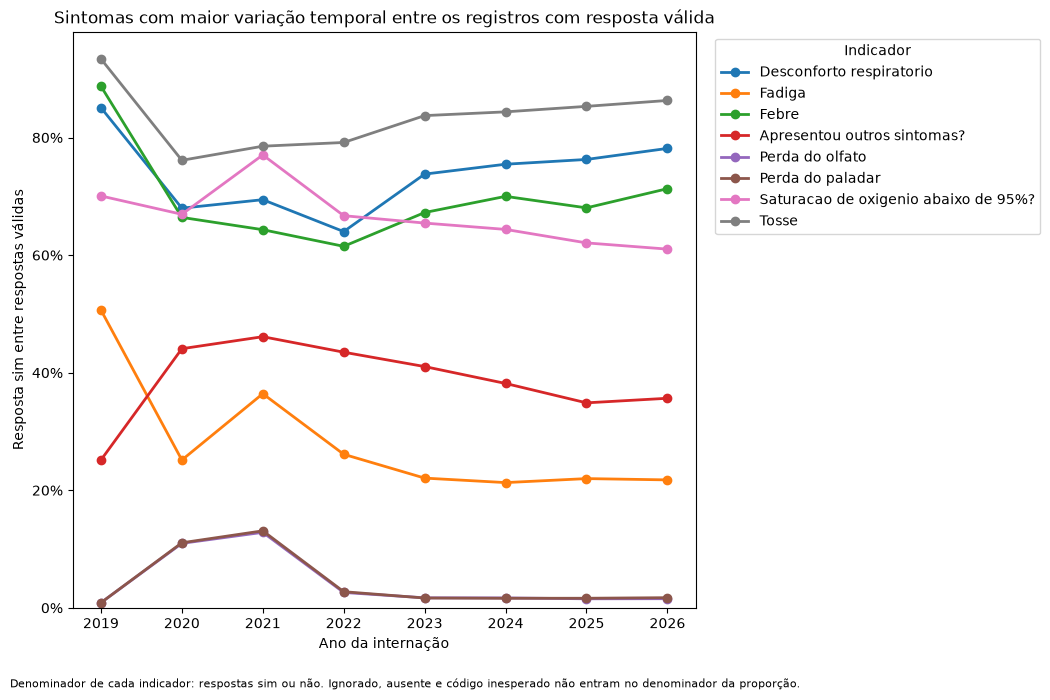

Figura salva em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\eda_02_sintomas_por_ano.png


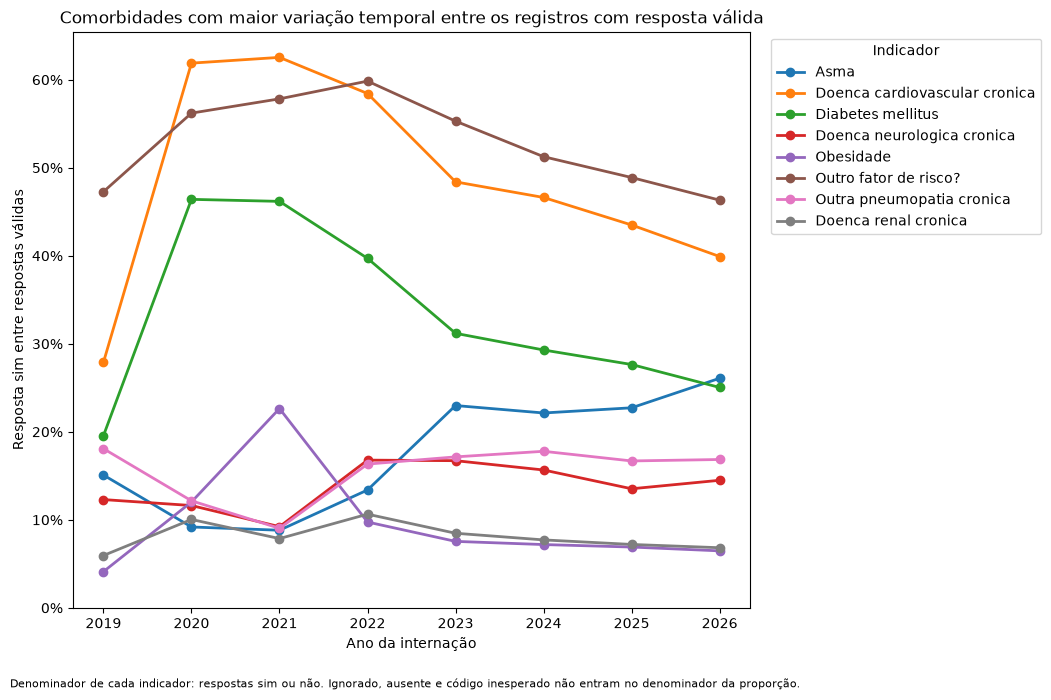

Figura salva em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\eda_02_comorbidades_por_ano.png


In [39]:
criar_grafico_clinico_temporal(
    tabela_clinica=sintomas_por_ano,
    selecao_variaveis=sintomas_grafico,
    titulo=(
        "Sintomas com maior variação temporal "
        "entre os registros com resposta válida"
    ),
    caminho_saida=(
        CAMINHO_FIGURA_SINTOMAS
    ),
)

criar_grafico_clinico_temporal(
    tabela_clinica=comorbidades_por_ano,
    selecao_variaveis=(
        comorbidades_grafico
    ),
    titulo=(
        "Comorbidades com maior variação temporal "
        "entre os registros com resposta válida"
    ),
    caminho_saida=(
        CAMINHO_FIGURA_COMORBIDADES
    ),
)

In [40]:
sintomas_por_ano.to_csv(
    CAMINHO_SINTOMAS_ANO,
    index=False,
    encoding="utf-8-sig",
)

comorbidades_por_ano.to_csv(
    CAMINHO_COMORBIDADES_ANO,
    index=False,
    encoding="utf-8-sig",
)

contadores_clinicos_por_ano.to_csv(
    CAMINHO_CONTADORES_CLINICOS_ANO,
    index=False,
    encoding="utf-8-sig",
)

variacao_sintomas.to_csv(
    CAMINHO_VARIACAO_SINTOMAS,
    index=False,
    encoding="utf-8-sig",
)

variacao_comorbidades.to_csv(
    CAMINHO_VARIACAO_COMORBIDADES,
    index=False,
    encoding="utf-8-sig",
)

anos_clinicos_observados = (
    coorte[
        "ano_internacao"
    ]
    .nunique(
        dropna=True
    )
)

linhas_sintomas_esperadas = (
    len(
        COLUNAS_SINTOMAS
    )
    * anos_clinicos_observados
)

linhas_comorbidades_esperadas = (
    len(
        COLUNAS_COMORBIDADES
    )
    * anos_clinicos_observados
)

totais_sintomas_validos = (
    sintomas_por_ano[
        [
            "quantidade_sim",
            "quantidade_nao",
            "quantidade_ignorado",
            "quantidade_ausente",
            "quantidade_inesperado",
        ]
    ]
    .sum(
        axis=1
    )
    .eq(
        sintomas_por_ano[
            "quantidade_total"
        ]
    )
    .all()
)

totais_comorbidades_validos = (
    comorbidades_por_ano[
        [
            "quantidade_sim",
            "quantidade_nao",
            "quantidade_ignorado",
            "quantidade_ausente",
            "quantidade_inesperado",
        ]
    ]
    .sum(
        axis=1
    )
    .eq(
        comorbidades_por_ano[
            "quantidade_total"
        ]
    )
    .all()
)

percentuais_sintomas_validos = (
    sintomas_por_ano[
        "percentual_sim_validos"
    ]
    .dropna()
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

percentuais_comorbidades_validos = (
    comorbidades_por_ano[
        "percentual_sim_validos"
    ]
    .dropna()
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

verificacoes_clinicas = {
    "sintomas_por_ano_nao_vazio": (
        not sintomas_por_ano.empty
    ),
    "comorbidades_por_ano_nao_vazio": (
        not comorbidades_por_ano.empty
    ),
    "contadores_por_ano_nao_vazio": (
        not contadores_clinicos_por_ano.empty
    ),
    "uma_linha_por_sintoma_e_ano": (
        len(
            sintomas_por_ano
        )
        == linhas_sintomas_esperadas
    ),
    "uma_linha_por_comorbidade_e_ano": (
        len(
            comorbidades_por_ano
        )
        == linhas_comorbidades_esperadas
    ),
    "categorias_sintomas_somam_total": (
        totais_sintomas_validos
    ),
    "categorias_comorbidades_somam_total": (
        totais_comorbidades_validos
    ),
    "percentuais_sintomas_validos": (
        percentuais_sintomas_validos
    ),
    "percentuais_comorbidades_validos": (
        percentuais_comorbidades_validos
    ),
    "contagem_sintomas_dentro_limite": (
        coorte[
            "n_sintomas_confirmados"
        ]
        .between(
            0,
            len(
                COLUNAS_SINTOMAS
            ),
            inclusive="both",
        )
        .all()
    ),
    "contagem_comorbidades_dentro_limite": (
        coorte[
            "n_comorbidades_confirmadas"
        ]
        .between(
            0,
            len(
                COLUNAS_COMORBIDADES
            ),
            inclusive="both",
        )
        .all()
    ),
    "arquivo_sintomas_criado": (
        CAMINHO_SINTOMAS_ANO.exists()
    ),
    "arquivo_comorbidades_criado": (
        CAMINHO_COMORBIDADES_ANO.exists()
    ),
    "arquivo_contadores_criado": (
        CAMINHO_CONTADORES_CLINICOS_ANO.exists()
    ),
    "arquivo_variacao_sintomas_criado": (
        CAMINHO_VARIACAO_SINTOMAS.exists()
    ),
    "arquivo_variacao_comorbidades_criado": (
        CAMINHO_VARIACAO_COMORBIDADES.exists()
    ),
    "figura_sintomas_criada": (
        CAMINHO_FIGURA_SINTOMAS.exists()
    ),
    "figura_comorbidades_criada": (
        CAMINHO_FIGURA_COMORBIDADES.exists()
    ),
}

verificacoes_clinicas_df = pd.DataFrame(
    {
        "verificacao": list(
            verificacoes_clinicas.keys()
        ),
        "resultado": list(
            verificacoes_clinicas.values()
        ),
    }
)

display(
    verificacoes_clinicas_df
)

if not all(
    verificacoes_clinicas.values()
):
    falhas_clinicas = [
        verificacao
        for verificacao, resultado
        in verificacoes_clinicas.items()
        if not resultado
    ]

    raise RuntimeError(
        "A análise de sintomas e comorbidades "
        "terminou com falhas: "
        f"{falhas_clinicas}"
    )

print(
    "Análise de sintomas e comorbidades validada com sucesso."
)

,verificacao,resultado
0,sintomas_por_ano_nao_vazio,True
1,comorbidades_por_ano_nao_vazio,True
2,contadores_por_ano_nao_vazio,True
3,uma_linha_por_sintoma_e_ano,True
4,uma_linha_por_comorbidade_e_ano,True
5,categorias_sintomas_somam_total,True
6,categorias_comorbidades_somam_total,True
7,percentuais_sintomas_validos,True
8,percentuais_comorbidades_validos,True
9,contagem_sintomas_dentro_limite,True


Análise de sintomas e comorbidades validada com sucesso.


## 5. Vacinação, escolaridade e geografia por ano

Esta seção avalia três grupos de contexto:

- vacinação contra influenza e COVID-19;
- escolaridade;
- UF de residência.

Para vacinação, serão preservadas separadamente as respostas sim, não,
ignorado, ausente e código inesperado.

Para escolaridade e geografia, serão apresentadas distribuições anuais
sem interpretar códigos ausentes ou desconhecidos como categorias
válidas.

As análises têm finalidade descritiva. Mudanças entre anos não serão
interpretadas automaticamente como mudanças clínicas, pois também podem
refletir alterações de preenchimento, cobertura ou composição da
população registrada.

In [41]:
COLUNAS_VACINACAO_PLANEJADAS = [
    "vacina",
    "vacina_cov",
]

COLUNAS_VACINACAO = [
    coluna
    for coluna in COLUNAS_VACINACAO_PLANEJADAS
    if coluna in coorte.columns
]

COLUNA_ESCOLARIDADE = "cs_escol_n"
COLUNA_UF_RESIDENCIA = "sg_uf"

if not COLUNAS_VACINACAO:
    raise ValueError(
        "Nenhum indicador geral de vacinação "
        "foi encontrado na coorte."
    )

if COLUNA_ESCOLARIDADE not in coorte.columns:
    raise KeyError(
        "A coluna cs_escol_n não está disponível na coorte."
    )

if COLUNA_UF_RESIDENCIA not in coorte.columns:
    raise KeyError(
        "A coluna sg_uf não está disponível na coorte."
    )

CAMINHO_VACINACAO_ANO = (
    C.TABLES_DIR
    / "eda_02_vacinacao_por_ano.csv"
)

CAMINHO_ESCOLARIDADE_ANO = (
    C.TABLES_DIR
    / "eda_02_escolaridade_por_ano.csv"
)

CAMINHO_UF_RESIDENCIA_ANO = (
    C.TABLES_DIR
    / "eda_02_uf_residencia_por_ano.csv"
)

CAMINHO_RESUMO_UF = (
    C.TABLES_DIR
    / "eda_02_resumo_uf_residencia.csv"
)

CAMINHO_FIGURA_VACINACAO = (
    C.FIGURES_DIR
    / "eda_02_vacinacao_por_ano.png"
)

CAMINHO_FIGURA_ESCOLARIDADE = (
    C.FIGURES_DIR
    / "eda_02_escolaridade_preenchimento_por_ano.png"
)

CAMINHO_FIGURA_UF = (
    C.FIGURES_DIR
    / "eda_02_principais_uf_residencia.png"
)

print(
    "Indicadores de vacinação encontrados:",
    COLUNAS_VACINACAO,
)

print(
    "Tabela de vacinação:",
    CAMINHO_VACINACAO_ANO,
)

print(
    "Tabela de escolaridade:",
    CAMINHO_ESCOLARIDADE_ANO,
)

print(
    "Tabela de UF de residência:",
    CAMINHO_UF_RESIDENCIA_ANO,
)

Indicadores de vacinação encontrados: ['vacina', 'vacina_cov']
Tabela de vacinação: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\eda_02_vacinacao_por_ano.csv
Tabela de escolaridade: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\eda_02_escolaridade_por_ano.csv
Tabela de UF de residência: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\eda_02_uf_residencia_por_ano.csv


In [42]:
vacinacao_por_ano = (
    criar_tabela_clinica_por_ano(
        dataframe=coorte,
        colunas=COLUNAS_VACINACAO,
        grupo_clinico="vacinacao",
        nomes_amigaveis=(
            nomes_amigaveis_dicionario
        ),
    )
)

vacinacao_por_ano = (
    vacinacao_por_ano.sort_values(
        [
            "coluna",
            "ano_internacao",
        ]
    )
    .reset_index(drop=True)
)

display(
    vacinacao_por_ano
)

,ano_internacao,grupo_clinico,coluna,nome_amigavel,quantidade_total,quantidade_sim,quantidade_nao,quantidade_ignorado,quantidade_ausente,quantidade_inesperado,quantidade_respostas_validas,percentual_sim_validos,percentual_nao_validos,percentual_sem_resposta_valida
0,2019,vacinacao,vacina,Recebeu vacina contra influenza?,43392,9046,19176,7222,7948,0,28222,32.053008,67.946992,34.960361
1,2020,vacinacao,vacina,Recebeu vacina contra influenza?,974415,132627,275741,384289,181758,0,408368,32.477324,67.522676,58.090957
2,2021,vacinacao,vacina,Recebeu vacina contra influenza?,1471091,123939,497424,489374,360354,0,621363,19.946312,80.053688,57.761756
3,2022,vacinacao,vacina,Recebeu vacina contra influenza?,470323,41049,105996,146532,176746,0,147045,27.915944,72.084056,68.735316
4,2023,vacinacao,vacina,Recebeu vacina contra influenza?,237976,16565,54302,62685,104424,0,70867,23.374772,76.625228,70.220947
5,2024,vacinacao,vacina,Recebeu vacina contra influenza?,226749,34123,116945,24418,51263,0,151068,22.587841,77.412159,33.376553
6,2025,vacinacao,vacina,Recebeu vacina contra influenza?,286837,76923,187319,5984,16611,0,264242,29.110815,70.889185,7.877296
7,2026,vacinacao,vacina,Recebeu vacina contra influenza?,173945,36545,129022,1480,6898,0,165567,22.072635,77.927365,4.816465
8,2019,vacinacao,vacina_cov,Recebeu vacina contra COVID-19?,43392,51,275,255,42811,0,326,15.644172,84.355828,99.248709
9,2020,vacinacao,vacina_cov,Recebeu vacina contra COVID-19?,974415,24164,65492,36099,848660,0,89656,26.951905,73.048095,90.798992


In [43]:
escolaridade_normalizada = (
    coorte[
        COLUNA_ESCOLARIDADE
    ]
    .astype("string")
    .str.strip()
    .str.replace(
        r"\.0$",
        "",
        regex=True,
    )
    .replace(
        {
            "": pd.NA,
            "nan": pd.NA,
            "NaN": pd.NA,
            "NONE": pd.NA,
            "None": pd.NA,
            "<NA>": pd.NA,
        }
    )
)

escolaridade_categoria = (
    escolaridade_normalizada
    .fillna(
        "ausente"
    )
)

escolaridade_por_ano = (
    pd.DataFrame(
        {
            "ano_internacao": coorte[
                "ano_internacao"
            ],
            "categoria_escolaridade": (
                escolaridade_categoria
            ),
        }
    )
    .groupby(
        [
            "ano_internacao",
            "categoria_escolaridade",
        ],
        dropna=False,
    )
    .size()
    .rename(
        "quantidade"
    )
    .reset_index()
)

denominador_escolaridade_ano = (
    escolaridade_por_ano.groupby(
        "ano_internacao"
    )[
        "quantidade"
    ]
    .transform("sum")
)

escolaridade_por_ano[
    "percentual_ano"
] = (
    escolaridade_por_ano[
        "quantidade"
    ]
    .div(
        denominador_escolaridade_ano
    )
    .mul(100)
)

escolaridade_por_ano[
    "flag_ausente"
] = (
    escolaridade_por_ano[
        "categoria_escolaridade"
    ]
    .eq("ausente")
)

escolaridade_por_ano = (
    escolaridade_por_ano
    .sort_values(
        [
            "ano_internacao",
            "categoria_escolaridade",
        ]
    )
    .reset_index(drop=True)
)

display(
    escolaridade_por_ano.head(40)
)

,ano_internacao,categoria_escolaridade,quantidade,percentual_ano,flag_ausente
0,2019,0,1803,4.155144,False
1,2019,1,3987,9.188330,False
2,2019,2,2199,5.067754,False
3,2019,3,3325,7.662703,False
4,2019,4,1485,3.422290,False
5,2019,5,19149,44.130254,False
6,2019,9,8230,18.966630,False
7,2019,ausente,3214,7.406895,True
8,2020,0,30645,3.144964,False
9,2020,1,100573,10.321372,False


In [44]:
escolaridade_preenchimento_ano = (
    pd.DataFrame(
        {
            "ano_internacao": coorte[
                "ano_internacao"
            ],
            "escolaridade_preenchida": (
                escolaridade_normalizada
                .notna()
                .astype("int8")
            ),
        }
    )
    .groupby(
        "ano_internacao",
        dropna=False,
    )
    .agg(
        quantidade_registros=(
            "escolaridade_preenchida",
            "size",
        ),
        quantidade_preenchida=(
            "escolaridade_preenchida",
            "sum",
        ),
    )
    .reset_index()
    .sort_values(
        "ano_internacao"
    )
    .reset_index(drop=True)
)

escolaridade_preenchimento_ano[
    "quantidade_ausente"
] = (
    escolaridade_preenchimento_ano[
        "quantidade_registros"
    ]
    .sub(
        escolaridade_preenchimento_ano[
            "quantidade_preenchida"
        ]
    )
)

escolaridade_preenchimento_ano[
    "percentual_preenchido"
] = (
    escolaridade_preenchimento_ano[
        "quantidade_preenchida"
    ]
    .div(
        escolaridade_preenchimento_ano[
            "quantidade_registros"
        ]
    )
    .mul(100)
)

escolaridade_preenchimento_ano[
    "percentual_ausente"
] = (
    100
    - escolaridade_preenchimento_ano[
        "percentual_preenchido"
    ]
)

display(
    escolaridade_preenchimento_ano
)

,ano_internacao,quantidade_registros,quantidade_preenchida,quantidade_ausente,percentual_preenchido,percentual_ausente
0,2019,43392,40178,3214,92.593105,7.406895
1,2020,974415,702761,271654,72.121324,27.878676
2,2021,1471091,982668,488423,66.798587,33.201413
3,2022,470323,301776,168547,64.163564,35.836436
4,2023,237976,154678,83298,64.997311,35.002689
5,2024,226749,141819,84930,62.544488,37.455512
6,2025,286837,186892,99945,65.156169,34.843831
7,2026,173945,115554,58391,66.431343,33.568657


In [45]:
uf_residencia_normalizada = (
    coorte[
        COLUNA_UF_RESIDENCIA
    ]
    .astype("string")
    .str.strip()
    .str.upper()
    .replace(
        {
            "": pd.NA,
            "NAN": pd.NA,
            "NONE": pd.NA,
            "<NA>": pd.NA,
        }
    )
)

SIGLAS_UF_VALIDAS = {
    "AC",
    "AL",
    "AP",
    "AM",
    "BA",
    "CE",
    "DF",
    "ES",
    "GO",
    "MA",
    "MT",
    "MS",
    "MG",
    "PA",
    "PB",
    "PR",
    "PE",
    "PI",
    "RJ",
    "RN",
    "RS",
    "RO",
    "RR",
    "SC",
    "SP",
    "SE",
    "TO",
}

coorte[
    "uf_residencia_categoria"
] = (
    uf_residencia_normalizada
    .where(
        uf_residencia_normalizada.isin(
            SIGLAS_UF_VALIDAS
        ),
        "Ausente ou inesperada",
    )
)

uf_residencia_por_ano = (
    coorte.groupby(
        [
            "ano_internacao",
            "uf_residencia_categoria",
        ],
        dropna=False,
    )
    .size()
    .rename(
        "quantidade"
    )
    .reset_index()
)

denominador_uf_ano = (
    uf_residencia_por_ano.groupby(
        "ano_internacao"
    )[
        "quantidade"
    ]
    .transform("sum")
)

uf_residencia_por_ano[
    "percentual_ano"
] = (
    uf_residencia_por_ano[
        "quantidade"
    ]
    .div(
        denominador_uf_ano
    )
    .mul(100)
)

uf_residencia_por_ano = (
    uf_residencia_por_ano
    .sort_values(
        [
            "ano_internacao",
            "quantidade",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .reset_index(drop=True)
)

display(
    uf_residencia_por_ano.head(40)
)

,ano_internacao,uf_residencia_categoria,quantidade,percentual_ano
0,2019,SP,10772,24.824853
1,2019,PR,6548,15.090339
2,2019,MG,3653,8.418603
3,2019,RS,3425,7.893160
4,2019,RJ,2202,5.074668
5,2019,SC,2170,5.000922
6,2019,AM,1918,4.420170
7,2019,MS,1654,3.811763
8,2019,PE,1602,3.691925
9,2019,DF,1493,3.440726


In [46]:
resumo_uf_residencia = (
    coorte.groupby(
        "uf_residencia_categoria",
        dropna=False,
    )
    .size()
    .rename(
        "quantidade"
    )
    .reset_index()
    .sort_values(
        "quantidade",
        ascending=False,
    )
    .reset_index(drop=True)
)

resumo_uf_residencia[
    "percentual_coorte"
] = (
    resumo_uf_residencia[
        "quantidade"
    ]
    .div(
        len(
            coorte
        )
    )
    .mul(100)
)

resumo_uf_residencia[
    "ordem_frequencia"
] = (
    resumo_uf_residencia.index
    + 1
)

display(
    resumo_uf_residencia
)

,uf_residencia_categoria,quantidade,percentual_coorte,ordem_frequencia
0,SP,1153276,29.687432,1
1,MG,468123,12.050342,2
2,PR,334556,8.612083,3
3,RJ,298669,7.688286,4
4,RS,231209,5.951742,5
5,SC,165795,4.267866,6
6,BA,141446,3.641079,7
7,GO,140843,3.625556,8
8,CE,128309,3.302908,9
9,PE,100549,2.588315,10


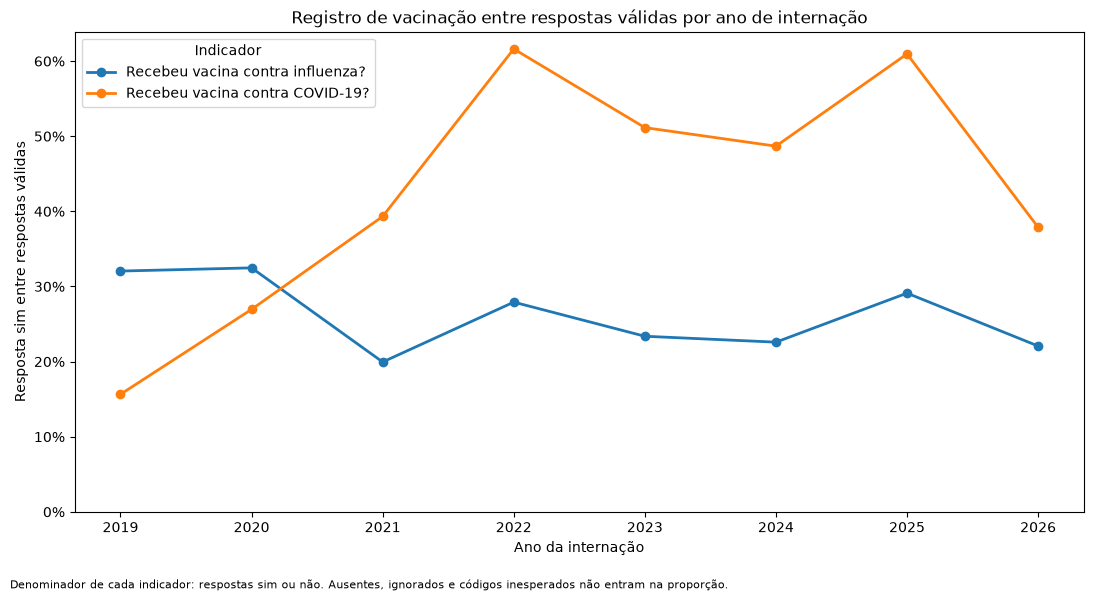

Figura salva em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\eda_02_vacinacao_por_ano.png


In [47]:
figura_vacinacao, eixo_vacinacao = plt.subplots(
    figsize=(
        11,
        6,
    )
)

for coluna in COLUNAS_VACINACAO:
    dados_variavel = (
        vacinacao_por_ano.loc[
            vacinacao_por_ano[
                "coluna"
            ].eq(
                coluna
            )
        ]
        .sort_values(
            "ano_internacao"
        )
    )

    nome_variavel = (
        nomes_amigaveis_dicionario.get(
            coluna,
            coluna,
        )
    )

    eixo_vacinacao.plot(
        dados_variavel[
            "ano_internacao"
        ].astype(int),
        dados_variavel[
            "percentual_sim_validos"
        ],
        marker="o",
        linewidth=2,
        label=nome_variavel,
    )

anos_vacinacao = (
    vacinacao_por_ano[
        "ano_internacao"
    ]
    .dropna()
    .astype(int)
    .sort_values()
    .unique()
)

eixo_vacinacao.set_title(
    "Registro de vacinação entre respostas válidas por ano de internação"
)

eixo_vacinacao.set_xlabel(
    "Ano da internação"
)

eixo_vacinacao.set_ylabel(
    "Resposta sim entre respostas válidas"
)

eixo_vacinacao.set_xticks(
    anos_vacinacao
)

eixo_vacinacao.set_ylim(
    bottom=0
)

eixo_vacinacao.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

eixo_vacinacao.legend(
    title="Indicador"
)

figura_vacinacao.text(
    0.01,
    0.01,
    (
        "Denominador de cada indicador: respostas sim ou não. "
        "Ausentes, ignorados e códigos inesperados não entram "
        "na proporção."
    ),
    fontsize=8,
)

figura_vacinacao.tight_layout(
    rect=[
        0,
        0.04,
        1,
        1,
    ]
)

figura_vacinacao.savefig(
    CAMINHO_FIGURA_VACINACAO,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figura salva em:",
    CAMINHO_FIGURA_VACINACAO,
)

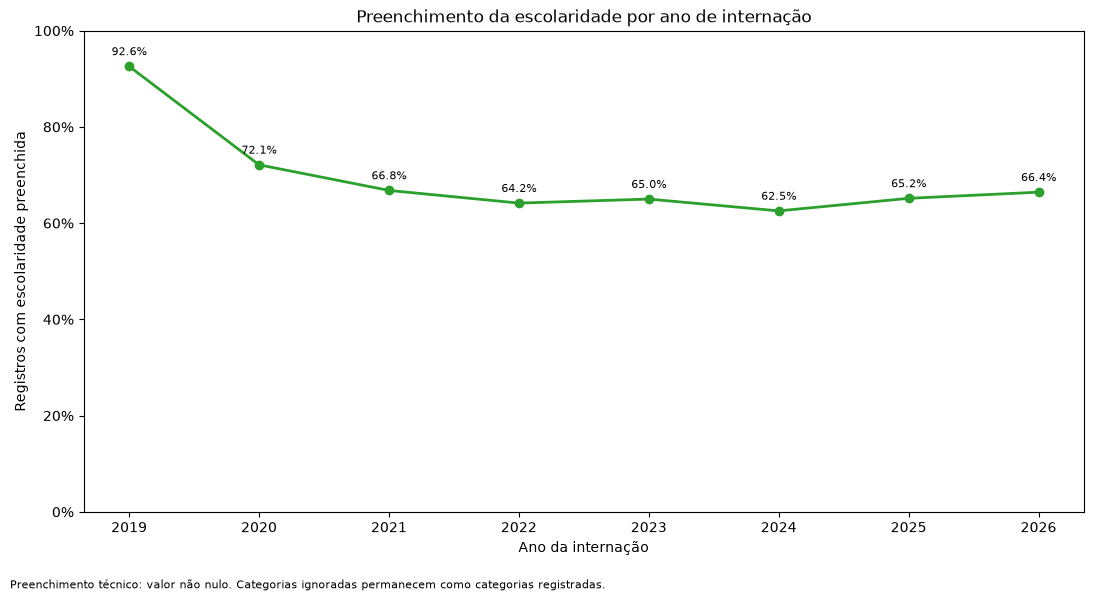

Figura salva em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\eda_02_escolaridade_preenchimento_por_ano.png


In [48]:
figura_escolaridade, eixo_escolaridade = plt.subplots(
    figsize=(
        11,
        6,
    )
)

anos_escolaridade = (
    escolaridade_preenchimento_ano[
        "ano_internacao"
    ]
    .astype(int)
)

percentuais_escolaridade = (
    escolaridade_preenchimento_ano[
        "percentual_preenchido"
    ]
)

eixo_escolaridade.plot(
    anos_escolaridade,
    percentuais_escolaridade,
    color="tab:green",
    marker="o",
    linewidth=2,
)

eixo_escolaridade.set_title(
    "Preenchimento da escolaridade por ano de internação"
)

eixo_escolaridade.set_xlabel(
    "Ano da internação"
)

eixo_escolaridade.set_ylabel(
    "Registros com escolaridade preenchida"
)

eixo_escolaridade.set_xticks(
    anos_escolaridade
)

eixo_escolaridade.set_ylim(
    0,
    100,
)

eixo_escolaridade.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

for ano, percentual in zip(
    anos_escolaridade,
    percentuais_escolaridade,
):
    eixo_escolaridade.annotate(
        f"{percentual:.1f}%",
        (
            ano,
            percentual,
        ),
        textcoords="offset points",
        xytext=(
            0,
            8,
        ),
        ha="center",
        fontsize=8,
    )

figura_escolaridade.text(
    0.01,
    0.01,
    (
        "Preenchimento técnico: valor não nulo. "
        "Categorias ignoradas permanecem como categorias registradas."
    ),
    fontsize=8,
)

figura_escolaridade.tight_layout(
    rect=[
        0,
        0.04,
        1,
        1,
    ]
)

figura_escolaridade.savefig(
    CAMINHO_FIGURA_ESCOLARIDADE,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figura salva em:",
    CAMINHO_FIGURA_ESCOLARIDADE,
)

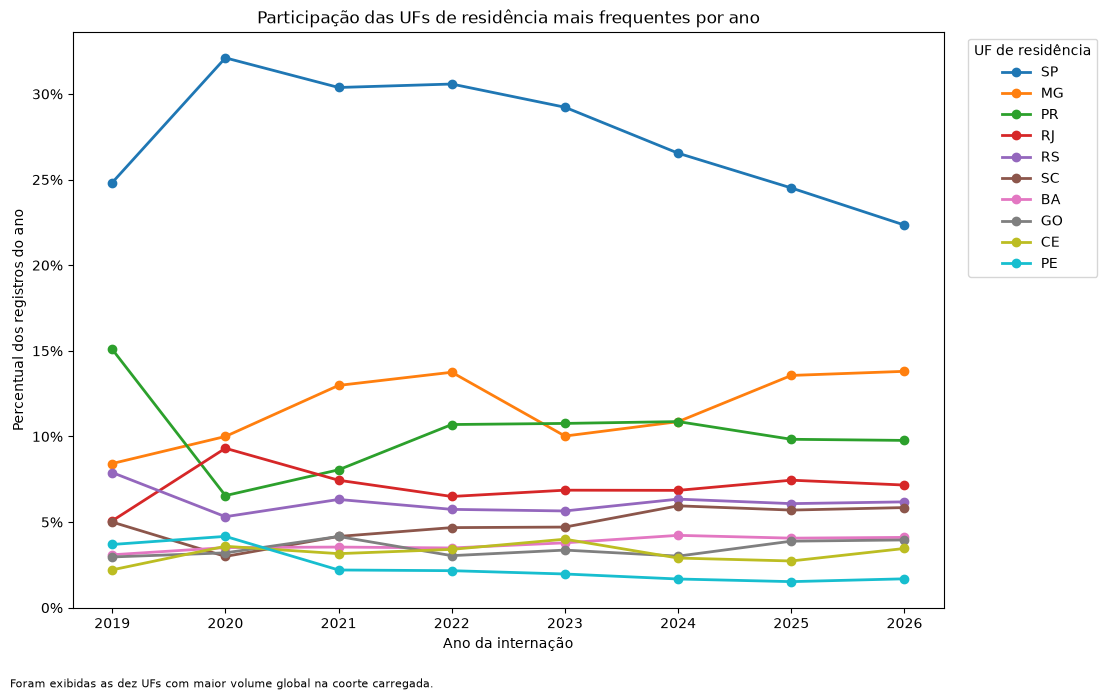

Figura salva em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\eda_02_principais_uf_residencia.png


In [49]:
QUANTIDADE_UF_GRAFICO = 10

ufs_validas_resumo = (
    resumo_uf_residencia.loc[
        resumo_uf_residencia[
            "uf_residencia_categoria"
        ].ne(
            "Ausente ou inesperada"
        )
    ]
    .head(
        QUANTIDADE_UF_GRAFICO
    )
    .copy()
)

if ufs_validas_resumo.empty:
    raise ValueError(
        "Nenhuma UF válida foi encontrada para o gráfico."
    )

ufs_grafico = (
    ufs_validas_resumo[
        "uf_residencia_categoria"
    ]
    .tolist()
)

dados_uf_grafico = (
    uf_residencia_por_ano.loc[
        uf_residencia_por_ano[
            "uf_residencia_categoria"
        ].isin(
            ufs_grafico
        )
    ]
    .copy()
)

tabela_uf_grafico = (
    dados_uf_grafico.pivot(
        index="ano_internacao",
        columns="uf_residencia_categoria",
        values="percentual_ano",
    )
    .reindex(
        columns=ufs_grafico,
        fill_value=0,
    )
    .fillna(0)
)

figura_uf, eixo_uf = plt.subplots(
    figsize=(
        13,
        7,
    )
)

tabela_uf_grafico.plot(
    kind="line",
    marker="o",
    linewidth=2,
    ax=eixo_uf,
)

eixo_uf.set_title(
    "Participação das UFs de residência mais frequentes por ano"
)

eixo_uf.set_xlabel(
    "Ano da internação"
)

eixo_uf.set_ylabel(
    "Percentual dos registros do ano"
)

eixo_uf.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

eixo_uf.legend(
    title="UF de residência",
    bbox_to_anchor=(
        1.02,
        1,
    ),
    loc="upper left",
)

figura_uf.text(
    0.01,
    0.01,
    (
        "Foram exibidas as dez UFs com maior volume global "
        "na coorte carregada."
    ),
    fontsize=8,
)

figura_uf.tight_layout(
    rect=[
        0,
        0.04,
        0.86,
        1,
    ]
)

figura_uf.savefig(
    CAMINHO_FIGURA_UF,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figura salva em:",
    CAMINHO_FIGURA_UF,
)

In [50]:
vacinacao_por_ano.to_csv(
    CAMINHO_VACINACAO_ANO,
    index=False,
    encoding="utf-8-sig",
)

escolaridade_por_ano.to_csv(
    CAMINHO_ESCOLARIDADE_ANO,
    index=False,
    encoding="utf-8-sig",
)

uf_residencia_por_ano.to_csv(
    CAMINHO_UF_RESIDENCIA_ANO,
    index=False,
    encoding="utf-8-sig",
)

resumo_uf_residencia.to_csv(
    CAMINHO_RESUMO_UF,
    index=False,
    encoding="utf-8-sig",
)

total_escolaridade = int(
    escolaridade_por_ano[
        "quantidade"
    ]
    .sum()
)

total_uf = int(
    uf_residencia_por_ano[
        "quantidade"
    ]
    .sum()
)

anos_contexto_observados = int(
    coorte[
        "ano_internacao"
    ]
    .nunique(
        dropna=True
    )
)

linhas_vacinacao_esperadas = (
    len(
        COLUNAS_VACINACAO
    )
    * anos_contexto_observados
)

categorias_vacinacao_somam_total = (
    vacinacao_por_ano[
        [
            "quantidade_sim",
            "quantidade_nao",
            "quantidade_ignorado",
            "quantidade_ausente",
            "quantidade_inesperado",
        ]
    ]
    .sum(
        axis=1
    )
    .eq(
        vacinacao_por_ano[
            "quantidade_total"
        ]
    )
    .all()
)

percentuais_vacinacao_validos = (
    vacinacao_por_ano[
        "percentual_sim_validos"
    ]
    .dropna()
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

percentuais_escolaridade_validos = (
    escolaridade_por_ano[
        "percentual_ano"
    ]
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

percentuais_uf_validos = (
    uf_residencia_por_ano[
        "percentual_ano"
    ]
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

verificacoes_contexto = {
    "vacinacao_por_ano_nao_vazia": (
        not vacinacao_por_ano.empty
    ),
    "escolaridade_por_ano_nao_vazia": (
        not escolaridade_por_ano.empty
    ),
    "uf_por_ano_nao_vazia": (
        not uf_residencia_por_ano.empty
    ),
    "uma_linha_por_vacina_e_ano": (
        len(
            vacinacao_por_ano
        )
        == linhas_vacinacao_esperadas
    ),
    "categorias_vacinacao_somam_total": (
        categorias_vacinacao_somam_total
    ),
    "total_escolaridade_igual_coorte": (
        total_escolaridade
        == len(
            coorte
        )
    ),
    "total_uf_igual_coorte": (
        total_uf
        == len(
            coorte
        )
    ),
    "percentuais_vacinacao_validos": (
        percentuais_vacinacao_validos
    ),
    "percentuais_escolaridade_validos": (
        percentuais_escolaridade_validos
    ),
    "percentuais_uf_validos": (
        percentuais_uf_validos
    ),
    "arquivo_vacinacao_criado": (
        CAMINHO_VACINACAO_ANO.exists()
    ),
    "arquivo_escolaridade_criado": (
        CAMINHO_ESCOLARIDADE_ANO.exists()
    ),
    "arquivo_uf_criado": (
        CAMINHO_UF_RESIDENCIA_ANO.exists()
    ),
    "arquivo_resumo_uf_criado": (
        CAMINHO_RESUMO_UF.exists()
    ),
    "figura_vacinacao_criada": (
        CAMINHO_FIGURA_VACINACAO.exists()
    ),
    "figura_escolaridade_criada": (
        CAMINHO_FIGURA_ESCOLARIDADE.exists()
    ),
    "figura_uf_criada": (
        CAMINHO_FIGURA_UF.exists()
    ),
}

verificacoes_contexto_df = pd.DataFrame(
    {
        "verificacao": list(
            verificacoes_contexto.keys()
        ),
        "resultado": list(
            verificacoes_contexto.values()
        ),
    }
)

display(
    verificacoes_contexto_df
)

if not all(
    verificacoes_contexto.values()
):
    falhas_contexto = [
        verificacao
        for verificacao, resultado
        in verificacoes_contexto.items()
        if not resultado
    ]

    raise RuntimeError(
        "A análise de vacinação, escolaridade e geografia "
        "terminou com falhas: "
        f"{falhas_contexto}"
    )

print(
    "Análise de vacinação, escolaridade e geografia "
    "validada com sucesso."
)

,verificacao,resultado
0,vacinacao_por_ano_nao_vazia,True
1,escolaridade_por_ano_nao_vazia,True
2,uf_por_ano_nao_vazia,True
3,uma_linha_por_vacina_e_ano,True
4,categorias_vacinacao_somam_total,True
5,total_escolaridade_igual_coorte,True
6,total_uf_igual_coorte,True
7,percentuais_vacinacao_validos,True
8,percentuais_escolaridade_validos,True
9,percentuais_uf_validos,True


Análise de vacinação, escolaridade e geografia validada com sucesso.


## 6. Consolidação das mudanças temporais

As análises anteriores serão reunidas em uma tabela de triagem temporal.

Para reduzir o efeito da cobertura parcial de 2026, os indicadores de
amplitude utilizados nesta triagem serão calculados entre 2019 e 2025.

O ano de 2026 continuará presente nas tabelas e figuras descritivas,
mas não será utilizado para classificar automaticamente uma variável
como temporalmente instável.

Os limites definidos nesta seção têm finalidade exploratória. Eles não
determinam automaticamente exclusão de variáveis, remoção de anos ou
alteração da coorte.

Serão destacados:

- mudanças no volume de registros;
- mudanças na proporção observada de óbito por SRAG;
- mudanças na idade mediana;
- mudanças no preenchimento das variáveis;
- mudanças na presença registrada de sintomas;
- mudanças na presença registrada de comorbidades;
- mudanças na vacinação;
- mudanças no preenchimento da escolaridade;
- mudanças na composição das principais UFs de residência.

In [51]:
ANO_INICIAL_TRIAGEM_TEMPORAL = 2019
ANO_FINAL_TRIAGEM_TEMPORAL = 2025

ANOS_TRIAGEM_TEMPORAL = list(
    range(
        ANO_INICIAL_TRIAGEM_TEMPORAL,
        ANO_FINAL_TRIAGEM_TEMPORAL + 1,
    )
)

CAMINHO_RUPTURAS_TEMPORAIS = (
    C.TABLES_DIR
    / "eda_02_rupturas_temporais.csv"
)

CAMINHO_RESUMO_RUPTURAS = (
    C.TABLES_DIR
    / "eda_02_resumo_rupturas_temporais.csv"
)

CAMINHO_FIGURA_RUPTURAS = (
    C.FIGURES_DIR
    / "eda_02_rupturas_temporais.png"
)

print(
    "Período utilizado na triagem temporal:",
    ANO_INICIAL_TRIAGEM_TEMPORAL,
    "a",
    ANO_FINAL_TRIAGEM_TEMPORAL,
)

print(
    "Tabela de rupturas:",
    CAMINHO_RUPTURAS_TEMPORAIS,
)

print(
    "Resumo de rupturas:",
    CAMINHO_RESUMO_RUPTURAS,
)

Período utilizado na triagem temporal: 2019 a 2025
Tabela de rupturas: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\eda_02_rupturas_temporais.csv
Resumo de rupturas: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\eda_02_resumo_rupturas_temporais.csv


In [52]:
def resumir_amplitude_temporal(
    dataframe: pd.DataFrame,
    coluna_indicador: str,
    coluna_valor: str,
    tipo_indicador: str,
    grupo_indicador: str,
    unidade: str,
    limite_destaque: float,
) -> pd.DataFrame:
    """
    Calcula mínimo, máximo e amplitude do indicador entre 2019 e 2025.

    A função não exclui variáveis nem altera a coorte.
    O limite é usado somente para triagem exploratória.
    """

    COLUNAS_OBRIGATORIAS = [
        "ano_internacao",
        coluna_indicador,
        coluna_valor,
    ]

    colunas_ausentes = [
        coluna
        for coluna in COLUNAS_OBRIGATORIAS
        if coluna not in dataframe.columns
    ]

    if colunas_ausentes:
        raise KeyError(
            "A tabela não contém as colunas necessárias: "
            f"{colunas_ausentes}"
        )

    dados_periodo = (
        dataframe.loc[
            dataframe[
                "ano_internacao"
            ].isin(
                ANOS_TRIAGEM_TEMPORAL
            ),
            COLUNAS_OBRIGATORIAS,
        ]
        .copy()
    )

    dados_periodo[
        coluna_valor
    ] = pd.to_numeric(
        dados_periodo[
            coluna_valor
        ],
        errors="coerce",
    )

    dados_periodo = (
        dados_periodo.dropna(
            subset=[
                coluna_indicador,
                coluna_valor,
            ]
        )
    )

    if dados_periodo.empty:
        return pd.DataFrame(
            columns=[
                "tipo_indicador",
                "grupo_indicador",
                "indicador",
                "unidade",
                "ano_minimo",
                "valor_minimo",
                "ano_maximo",
                "valor_maximo",
                "amplitude",
                "limite_destaque",
                "flag_destaque",
                "quantidade_anos",
            ]
        )

    registros_resumo = []

    indicadores = (
        dados_periodo[
            coluna_indicador
        ]
        .drop_duplicates()
        .tolist()
    )

    for indicador in indicadores:
        dados_indicador = (
            dados_periodo.loc[
                dados_periodo[
                    coluna_indicador
                ].eq(
                    indicador
                )
            ]
            .sort_values(
                "ano_internacao"
            )
            .copy()
        )

        if dados_indicador.empty:
            continue

        indice_minimo = (
            dados_indicador[
                coluna_valor
            ]
            .idxmin()
        )

        indice_maximo = (
            dados_indicador[
                coluna_valor
            ]
            .idxmax()
        )

        valor_minimo = float(
            dados_indicador.loc[
                indice_minimo,
                coluna_valor,
            ]
        )

        valor_maximo = float(
            dados_indicador.loc[
                indice_maximo,
                coluna_valor,
            ]
        )

        ano_minimo = int(
            dados_indicador.loc[
                indice_minimo,
                "ano_internacao",
            ]
        )

        ano_maximo = int(
            dados_indicador.loc[
                indice_maximo,
                "ano_internacao",
            ]
        )

        amplitude = (
            valor_maximo
            - valor_minimo
        )

        registros_resumo.append(
            {
                "tipo_indicador": tipo_indicador,
                "grupo_indicador": grupo_indicador,
                "indicador": str(
                    indicador
                ),
                "unidade": unidade,
                "ano_minimo": ano_minimo,
                "valor_minimo": valor_minimo,
                "ano_maximo": ano_maximo,
                "valor_maximo": valor_maximo,
                "amplitude": amplitude,
                "limite_destaque": (
                    limite_destaque
                ),
                "flag_destaque": (
                    amplitude
                    >= limite_destaque
                ),
                "quantidade_anos": int(
                    dados_indicador[
                        "ano_internacao"
                    ]
                    .nunique()
                ),
            }
        )

    resultado = pd.DataFrame(
        registros_resumo
    )

    resultado = (
        resultado.sort_values(
            [
                "flag_destaque",
                "amplitude",
                "indicador",
            ],
            ascending=[
                False,
                False,
                True,
            ],
        )
        .reset_index(drop=True)
    )

    return resultado

In [53]:
volume_triagem = (
    resumo_temporal.loc[
        resumo_temporal[
            "ano_internacao"
        ].isin(
            ANOS_TRIAGEM_TEMPORAL
        ),
        [
            "ano_internacao",
            "quantidade_registros",
        ],
    ]
    .copy()
)

total_volume_triagem = int(
    volume_triagem[
        "quantidade_registros"
    ]
    .sum()
)

if total_volume_triagem == 0:
    raise ValueError(
        "O período de triagem temporal não possui registros."
    )

volume_triagem[
    "percentual_periodo"
] = (
    volume_triagem[
        "quantidade_registros"
    ]
    .div(
        total_volume_triagem
    )
    .mul(100)
)

volume_triagem[
    "indicador"
] = (
    "Participação no volume do período"
)

desfecho_triagem = (
    alvo_por_ano.loc[
        alvo_por_ano[
            "ano_internacao"
        ].isin(
            ANOS_TRIAGEM_TEMPORAL
        ),
        [
            "ano_internacao",
            "percentual_obito_srag",
        ],
    ]
    .copy()
)

desfecho_triagem[
    "indicador"
] = (
    "Óbito por SRAG"
)

idade_triagem = (
    idade_por_ano.loc[
        idade_por_ano[
            "ano_internacao"
        ].isin(
            ANOS_TRIAGEM_TEMPORAL
        ),
        [
            "ano_internacao",
            "idade_mediana",
        ],
    ]
    .copy()
)

idade_triagem[
    "indicador"
] = (
    "Idade mediana"
)

display(
    volume_triagem
)

display(
    desfecho_triagem
)

display(
    idade_triagem
)

,ano_internacao,quantidade_registros,percentual_periodo,indicador
0,2019,43392,1.169349,Participação no volume do período
1,2020,974415,26.259013,Participação no volume do período
2,2021,1471091,39.643682,Participação no volume do período
3,2022,470323,12.674495,Participação no volume do período
4,2023,237976,6.413094,Participação no volume do período
5,2024,226749,6.110543,Participação no volume do período
6,2025,286837,7.729824,Participação no volume do período


alvo_obito_srag,ano_internacao,percentual_obito_srag,indicador
0,2019,11.997603,Óbito por SRAG
1,2020,27.924857,Óbito por SRAG
2,2021,28.138300,Óbito por SRAG
3,2022,18.083530,Óbito por SRAG
4,2023,9.445490,Óbito por SRAG
5,2024,8.215692,Óbito por SRAG
6,2025,7.244184,Óbito por SRAG


,ano_internacao,idade_mediana,indicador
0,2019,5.0,Idade mediana
1,2020,60.0,Idade mediana
2,2021,56.0,Idade mediana
3,2022,58.0,Idade mediana
4,2023,7.0,Idade mediana
5,2024,6.0,Idade mediana
6,2025,5.0,Idade mediana


In [54]:
ruptura_volume = (
    resumir_amplitude_temporal(
        dataframe=volume_triagem,
        coluna_indicador="indicador",
        coluna_valor="percentual_periodo",
        tipo_indicador="composicao",
        grupo_indicador="volume",
        unidade="pontos_percentuais",
        limite_destaque=5.0,
    )
)

ruptura_desfecho = (
    resumir_amplitude_temporal(
        dataframe=desfecho_triagem,
        coluna_indicador="indicador",
        coluna_valor=(
            "percentual_obito_srag"
        ),
        tipo_indicador="desfecho",
        grupo_indicador="desfecho",
        unidade="pontos_percentuais",
        limite_destaque=5.0,
    )
)

ruptura_idade = (
    resumir_amplitude_temporal(
        dataframe=idade_triagem,
        coluna_indicador="indicador",
        coluna_valor="idade_mediana",
        tipo_indicador="demografia",
        grupo_indicador="idade",
        unidade="anos",
        limite_destaque=5.0,
    )
)

display(
    ruptura_volume
)

display(
    ruptura_desfecho
)

display(
    ruptura_idade
)

,tipo_indicador,grupo_indicador,indicador,unidade,ano_minimo,valor_minimo,ano_maximo,valor_maximo,amplitude,limite_destaque,flag_destaque,quantidade_anos
0,composicao,volume,Participação no volume do período,pontos_percentuais,2019,1.169349,2021,39.643682,38.474333,5.0,True,7


,tipo_indicador,grupo_indicador,indicador,unidade,ano_minimo,valor_minimo,ano_maximo,valor_maximo,amplitude,limite_destaque,flag_destaque,quantidade_anos
0,desfecho,desfecho,Óbito por SRAG,pontos_percentuais,2025,7.244184,2021,28.1383,20.894116,5.0,True,7


,tipo_indicador,grupo_indicador,indicador,unidade,ano_minimo,valor_minimo,ano_maximo,valor_maximo,amplitude,limite_destaque,flag_destaque,quantidade_anos
0,demografia,idade,Idade mediana,anos,2019,5.0,2020,60.0,55.0,5.0,True,7


In [55]:
preenchimento_triagem = (
    preenchimento_por_variavel_ano.loc[
        preenchimento_por_variavel_ano[
            "ano_internacao"
        ].isin(
            ANOS_TRIAGEM_TEMPORAL
        ),
        [
            "ano_internacao",
            "coluna",
            "nome_amigavel",
            "grupo",
            "percentual_preenchido",
        ],
    ]
    .copy()
)

preenchimento_triagem[
    "indicador"
] = (
    preenchimento_triagem[
        "nome_amigavel"
    ]
    .where(
        preenchimento_triagem[
            "nome_amigavel"
        ]
        .astype("string")
        .str.strip()
        .ne(""),
        preenchimento_triagem[
            "coluna"
        ],
    )
)

ruptura_preenchimento = (
    resumir_amplitude_temporal(
        dataframe=preenchimento_triagem,
        coluna_indicador="indicador",
        coluna_valor=(
            "percentual_preenchido"
        ),
        tipo_indicador="qualidade_dados",
        grupo_indicador="preenchimento",
        unidade="pontos_percentuais",
        limite_destaque=20.0,
    )
)

display(
    ruptura_preenchimento.head(30)
)

,tipo_indicador,grupo_indicador,indicador,unidade,ano_minimo,valor_minimo,ano_maximo,valor_maximo,amplitude,limite_destaque,flag_destaque,quantidade_anos
0,qualidade_dados,preenchimento,Recebeu vacina contra COVID-19?,pontos_percentuais,2019,1.338956,2025,99.993725,98.654768,20.0,True,7
1,qualidade_dados,preenchimento,Fadiga,pontos_percentuais,2019,0.523138,2025,82.583140,82.060002,20.0,True,7
2,qualidade_dados,preenchimento,Dor abdominal,pontos_percentuais,2019,0.274244,2025,81.050562,80.776318,20.0,True,7
3,qualidade_dados,preenchimento,Perda do olfato,pontos_percentuais,2019,0.269635,2025,80.455799,80.186164,20.0,True,7
4,qualidade_dados,preenchimento,Perda do paladar,pontos_percentuais,2019,0.267330,2025,80.336567,80.069237,20.0,True,7
5,qualidade_dados,preenchimento,Recebeu vacina contra influenza?,pontos_percentuais,2023,56.119945,2025,94.208906,38.088961,20.0,True,7
6,qualidade_dados,preenchimento,Escolaridade,pontos_percentuais,2024,62.544488,2019,92.593105,30.048617,20.0,True,7
7,qualidade_dados,preenchimento,Diarreia,pontos_percentuais,2022,68.500158,2019,97.607854,29.107696,20.0,True,7
8,qualidade_dados,preenchimento,Vomito,pontos_percentuais,2022,69.104211,2019,97.693123,28.588912,20.0,True,7
9,qualidade_dados,preenchimento,Dor de garganta,pontos_percentuais,2022,70.390136,2019,98.041114,27.650977,20.0,True,7


In [56]:
sintomas_triagem = (
    sintomas_por_ano.loc[
        sintomas_por_ano[
            "ano_internacao"
        ].isin(
            ANOS_TRIAGEM_TEMPORAL
        ),
        [
            "ano_internacao",
            "coluna",
            "nome_amigavel",
            "percentual_sim_validos",
        ],
    ]
    .copy()
)

sintomas_triagem[
    "indicador"
] = (
    sintomas_triagem[
        "nome_amigavel"
    ]
    .where(
        sintomas_triagem[
            "nome_amigavel"
        ]
        .astype("string")
        .str.strip()
        .ne(""),
        sintomas_triagem[
            "coluna"
        ],
    )
)

comorbidades_triagem = (
    comorbidades_por_ano.loc[
        comorbidades_por_ano[
            "ano_internacao"
        ].isin(
            ANOS_TRIAGEM_TEMPORAL
        ),
        [
            "ano_internacao",
            "coluna",
            "nome_amigavel",
            "percentual_sim_validos",
        ],
    ]
    .copy()
)

comorbidades_triagem[
    "indicador"
] = (
    comorbidades_triagem[
        "nome_amigavel"
    ]
    .where(
        comorbidades_triagem[
            "nome_amigavel"
        ]
        .astype("string")
        .str.strip()
        .ne(""),
        comorbidades_triagem[
            "coluna"
        ],
    )
)

ruptura_sintomas = (
    resumir_amplitude_temporal(
        dataframe=sintomas_triagem,
        coluna_indicador="indicador",
        coluna_valor=(
            "percentual_sim_validos"
        ),
        tipo_indicador="clinico",
        grupo_indicador="sintomas",
        unidade="pontos_percentuais",
        limite_destaque=10.0,
    )
)

ruptura_comorbidades = (
    resumir_amplitude_temporal(
        dataframe=comorbidades_triagem,
        coluna_indicador="indicador",
        coluna_valor=(
            "percentual_sim_validos"
        ),
        tipo_indicador="clinico",
        grupo_indicador="comorbidades",
        unidade="pontos_percentuais",
        limite_destaque=10.0,
    )
)

display(
    ruptura_sintomas
)

display(
    ruptura_comorbidades
)

,tipo_indicador,grupo_indicador,indicador,unidade,ano_minimo,valor_minimo,ano_maximo,valor_maximo,amplitude,limite_destaque,flag_destaque,quantidade_anos
0,clinico,sintomas,Fadiga,pontos_percentuais,2024,21.304499,2019,50.660793,29.356294,10.0,True,7
1,clinico,sintomas,Febre,pontos_percentuais,2022,61.496012,2019,88.735499,27.239487,10.0,True,7
2,clinico,sintomas,Desconforto respiratorio,pontos_percentuais,2022,64.007919,2019,85.090281,21.082361,10.0,True,7
3,clinico,sintomas,Apresentou outros sintomas?,pontos_percentuais,2019,25.142604,2021,46.125307,20.982703,10.0,True,7
4,clinico,sintomas,Tosse,pontos_percentuais,2020,76.130208,2019,93.388871,17.258662,10.0,True,7
5,clinico,sintomas,Saturacao de oxigenio abaixo de 95%?,pontos_percentuais,2025,62.081116,2021,77.043969,14.962853,10.0,True,7
6,clinico,sintomas,Perda do paladar,pontos_percentuais,2019,0.869565,2021,13.097523,12.227958,10.0,True,7
7,clinico,sintomas,Perda do olfato,pontos_percentuais,2019,0.869565,2021,12.842341,11.972776,10.0,True,7
8,clinico,sintomas,Dispneia,pontos_percentuais,2022,72.688406,2019,83.651963,10.963557,10.0,True,7
9,clinico,sintomas,Dor de garganta,pontos_percentuais,2025,13.372231,2021,23.293317,9.921086,10.0,False,7


,tipo_indicador,grupo_indicador,indicador,unidade,ano_minimo,valor_minimo,ano_maximo,valor_maximo,amplitude,limite_destaque,flag_destaque,quantidade_anos
0,clinico,comorbidades,Doenca cardiovascular cronica,pontos_percentuais,2019,27.887022,2021,62.538807,34.651785,10.0,True,7
1,clinico,comorbidades,Diabetes mellitus,pontos_percentuais,2019,19.549913,2020,46.408440,26.858528,10.0,True,7
2,clinico,comorbidades,Obesidade,pontos_percentuais,2019,4.112634,2021,22.640659,18.528025,10.0,True,7
3,clinico,comorbidades,Asma,pontos_percentuais,2021,8.815523,2023,22.982738,14.167215,10.0,True,7
4,clinico,comorbidades,Outro fator de risco?,pontos_percentuais,2019,47.272506,2022,59.841626,12.569119,10.0,True,7
5,clinico,comorbidades,Outra pneumopatia cronica,pontos_percentuais,2021,9.034147,2019,18.084402,9.050255,10.0,False,7
6,clinico,comorbidades,Doenca neurologica cronica,pontos_percentuais,2021,9.221022,2022,16.781076,7.560054,10.0,False,7
7,clinico,comorbidades,Doenca renal cronica,pontos_percentuais,2019,5.943627,2022,10.640829,4.697201,10.0,False,7
8,clinico,comorbidades,Imunodeficiencia ou imunodepressao,pontos_percentuais,2021,5.863559,2019,10.196031,4.332472,10.0,False,7
9,clinico,comorbidades,Sindrome de Down,pontos_percentuais,2020,0.724400,2019,3.731976,3.007577,10.0,False,7


In [57]:
vacinacao_triagem = (
    vacinacao_por_ano.loc[
        vacinacao_por_ano[
            "ano_internacao"
        ].isin(
            ANOS_TRIAGEM_TEMPORAL
        ),
        [
            "ano_internacao",
            "coluna",
            "nome_amigavel",
            "percentual_sim_validos",
        ],
    ]
    .copy()
)

vacinacao_triagem[
    "indicador"
] = (
    vacinacao_triagem[
        "nome_amigavel"
    ]
    .where(
        vacinacao_triagem[
            "nome_amigavel"
        ]
        .astype("string")
        .str.strip()
        .ne(""),
        vacinacao_triagem[
            "coluna"
        ],
    )
)

escolaridade_triagem = (
    escolaridade_preenchimento_ano.loc[
        escolaridade_preenchimento_ano[
            "ano_internacao"
        ].isin(
            ANOS_TRIAGEM_TEMPORAL
        ),
        [
            "ano_internacao",
            "percentual_preenchido",
        ],
    ]
    .copy()
)

escolaridade_triagem[
    "indicador"
] = (
    "Preenchimento da escolaridade"
)

ruptura_vacinacao = (
    resumir_amplitude_temporal(
        dataframe=vacinacao_triagem,
        coluna_indicador="indicador",
        coluna_valor=(
            "percentual_sim_validos"
        ),
        tipo_indicador="contexto",
        grupo_indicador="vacinacao",
        unidade="pontos_percentuais",
        limite_destaque=10.0,
    )
)

ruptura_escolaridade = (
    resumir_amplitude_temporal(
        dataframe=escolaridade_triagem,
        coluna_indicador="indicador",
        coluna_valor=(
            "percentual_preenchido"
        ),
        tipo_indicador="qualidade_dados",
        grupo_indicador="escolaridade",
        unidade="pontos_percentuais",
        limite_destaque=20.0,
    )
)

display(
    ruptura_vacinacao
)

display(
    ruptura_escolaridade
)

,tipo_indicador,grupo_indicador,indicador,unidade,ano_minimo,valor_minimo,ano_maximo,valor_maximo,amplitude,limite_destaque,flag_destaque,quantidade_anos
0,contexto,vacinacao,Recebeu vacina contra COVID-19?,pontos_percentuais,2019,15.644172,2022,61.623424,45.979252,10.0,True,7
1,contexto,vacinacao,Recebeu vacina contra influenza?,pontos_percentuais,2021,19.946312,2020,32.477324,12.531013,10.0,True,7


,tipo_indicador,grupo_indicador,indicador,unidade,ano_minimo,valor_minimo,ano_maximo,valor_maximo,amplitude,limite_destaque,flag_destaque,quantidade_anos
0,qualidade_dados,escolaridade,Preenchimento da escolaridade,pontos_percentuais,2024,62.544488,2019,92.593105,30.048617,20.0,True,7


In [58]:
ufs_triagem = (
    resumo_uf_residencia.loc[
        resumo_uf_residencia[
            "uf_residencia_categoria"
        ].ne(
            "Ausente ou inesperada"
        )
    ]
    .head(10)[
        "uf_residencia_categoria"
    ]
    .tolist()
)

uf_triagem = (
    uf_residencia_por_ano.loc[
        uf_residencia_por_ano[
            "ano_internacao"
        ].isin(
            ANOS_TRIAGEM_TEMPORAL
        )
        & uf_residencia_por_ano[
            "uf_residencia_categoria"
        ].isin(
            ufs_triagem
        ),
        [
            "ano_internacao",
            "uf_residencia_categoria",
            "percentual_ano",
        ],
    ]
    .copy()
)

uf_triagem = (
    pd.MultiIndex.from_product(
        [
            ANOS_TRIAGEM_TEMPORAL,
            ufs_triagem,
        ],
        names=[
            "ano_internacao",
            "uf_residencia_categoria",
        ],
    )
    .to_frame(
        index=False
    )
    .merge(
        uf_triagem,
        on=[
            "ano_internacao",
            "uf_residencia_categoria",
        ],
        how="left",
        validate="one_to_one",
    )
)

uf_triagem[
    "percentual_ano"
] = (
    uf_triagem[
        "percentual_ano"
    ]
    .fillna(0)
)

uf_triagem[
    "indicador"
] = (
    "UF "
    + uf_triagem[
        "uf_residencia_categoria"
    ]
    .astype("string")
)

ruptura_uf = (
    resumir_amplitude_temporal(
        dataframe=uf_triagem,
        coluna_indicador="indicador",
        coluna_valor="percentual_ano",
        tipo_indicador="territorio",
        grupo_indicador="uf_residencia",
        unidade="pontos_percentuais",
        limite_destaque=5.0,
    )
)

display(
    ruptura_uf
)

,tipo_indicador,grupo_indicador,indicador,unidade,ano_minimo,valor_minimo,ano_maximo,valor_maximo,amplitude,limite_destaque,flag_destaque,quantidade_anos
0,territorio,uf_residencia,UF PR,pontos_percentuais,2020,6.545568,2019,15.090339,8.544771,5.0,True,7
1,territorio,uf_residencia,UF SP,pontos_percentuais,2025,24.511134,2020,32.109009,7.597875,5.0,True,7
2,territorio,uf_residencia,UF MG,pontos_percentuais,2019,8.418603,2022,13.749487,5.330885,5.0,True,7
3,territorio,uf_residencia,UF RJ,pontos_percentuais,2019,5.074668,2020,9.311023,4.236354,5.0,False,7
4,territorio,uf_residencia,UF SC,pontos_percentuais,2020,2.995233,2024,5.949310,2.954077,5.0,False,7
5,territorio,uf_residencia,UF PE,pontos_percentuais,2025,1.522119,2020,4.165474,2.643355,5.0,False,7
6,territorio,uf_residencia,UF RS,pontos_percentuais,2020,5.313855,2019,7.893160,2.579305,5.0,False,7
7,territorio,uf_residencia,UF CE,pontos_percentuais,2019,2.210085,2023,4.000824,1.790739,5.0,False,7
8,territorio,uf_residencia,UF GO,pontos_percentuais,2019,2.963680,2021,4.159158,1.195478,5.0,False,7
9,territorio,uf_residencia,UF BA,pontos_percentuais,2019,3.090431,2024,4.225377,1.134946,5.0,False,7


In [59]:
TABELAS_RUPTURAS = [
    ruptura_volume,
    ruptura_desfecho,
    ruptura_idade,
    ruptura_preenchimento,
    ruptura_sintomas,
    ruptura_comorbidades,
    ruptura_vacinacao,
    ruptura_escolaridade,
    ruptura_uf,
]

rupturas_temporais = (
    pd.concat(
        TABELAS_RUPTURAS,
        ignore_index=True,
    )
)

rupturas_temporais[
    "periodo_avaliado"
] = (
    f"{ANO_INICIAL_TRIAGEM_TEMPORAL}-"
    f"{ANO_FINAL_TRIAGEM_TEMPORAL}"
)

rupturas_temporais[
    "ordem_destaque"
] = (
    rupturas_temporais[
        "amplitude"
    ]
    .div(
        rupturas_temporais[
            "limite_destaque"
        ]
    )
)

COLUNAS_RUPTURAS_TEMPORAIS = [
    "tipo_indicador",
    "grupo_indicador",
    "indicador",
    "unidade",
    "periodo_avaliado",
    "ano_minimo",
    "valor_minimo",
    "ano_maximo",
    "valor_maximo",
    "amplitude",
    "limite_destaque",
    "flag_destaque",
    "ordem_destaque",
    "quantidade_anos",
]

rupturas_temporais = (
    rupturas_temporais[
        COLUNAS_RUPTURAS_TEMPORAIS
    ]
    .sort_values(
        [
            "flag_destaque",
            "ordem_destaque",
            "grupo_indicador",
            "indicador",
        ],
        ascending=[
            False,
            False,
            True,
            True,
        ],
    )
    .reset_index(drop=True)
)

display(
    rupturas_temporais.head(40)
)

,tipo_indicador,grupo_indicador,indicador,unidade,periodo_avaliado,ano_minimo,valor_minimo,ano_maximo,valor_maximo,amplitude,limite_destaque,flag_destaque,ordem_destaque,quantidade_anos
0,demografia,idade,Idade mediana,anos,2019-2025,2019,5.000000,2020,60.000000,55.000000,5.0,True,11.000000,7
1,composicao,volume,Participação no volume do período,pontos_percentuais,2019-2025,2019,1.169349,2021,39.643682,38.474333,5.0,True,7.694867,7
2,qualidade_dados,preenchimento,Recebeu vacina contra COVID-19?,pontos_percentuais,2019-2025,2019,1.338956,2025,99.993725,98.654768,20.0,True,4.932738,7
3,contexto,vacinacao,Recebeu vacina contra COVID-19?,pontos_percentuais,2019-2025,2019,15.644172,2022,61.623424,45.979252,10.0,True,4.597925,7
4,desfecho,desfecho,Óbito por SRAG,pontos_percentuais,2019-2025,2025,7.244184,2021,28.138300,20.894116,5.0,True,4.178823,7
5,qualidade_dados,preenchimento,Fadiga,pontos_percentuais,2019-2025,2019,0.523138,2025,82.583140,82.060002,20.0,True,4.103000,7
6,qualidade_dados,preenchimento,Dor abdominal,pontos_percentuais,2019-2025,2019,0.274244,2025,81.050562,80.776318,20.0,True,4.038816,7
7,qualidade_dados,preenchimento,Perda do olfato,pontos_percentuais,2019-2025,2019,0.269635,2025,80.455799,80.186164,20.0,True,4.009308,7
8,qualidade_dados,preenchimento,Perda do paladar,pontos_percentuais,2019-2025,2019,0.267330,2025,80.336567,80.069237,20.0,True,4.003462,7
9,clinico,comorbidades,Doenca cardiovascular cronica,pontos_percentuais,2019-2025,2019,27.887022,2021,62.538807,34.651785,10.0,True,3.465179,7


In [60]:
resumo_rupturas_temporais = (
    rupturas_temporais.groupby(
        [
            "tipo_indicador",
            "grupo_indicador",
        ],
        dropna=False,
    )
    .agg(
        quantidade_indicadores=(
            "indicador",
            "size",
        ),
        quantidade_destaques=(
            "flag_destaque",
            "sum",
        ),
        maior_amplitude=(
            "amplitude",
            "max",
        ),
        amplitude_mediana=(
            "amplitude",
            "median",
        ),
    )
    .reset_index()
)

resumo_rupturas_temporais[
    "percentual_indicadores_destacados"
] = (
    resumo_rupturas_temporais[
        "quantidade_destaques"
    ]
    .div(
        resumo_rupturas_temporais[
            "quantidade_indicadores"
        ]
    )
    .mul(100)
)

resumo_rupturas_temporais = (
    resumo_rupturas_temporais
    .sort_values(
        [
            "quantidade_destaques",
            "maior_amplitude",
        ],
        ascending=[
            False,
            False,
        ],
    )
    .reset_index(drop=True)
)

display(
    resumo_rupturas_temporais
)

,tipo_indicador,grupo_indicador,quantidade_indicadores,quantidade_destaques,maior_amplitude,amplitude_mediana,percentual_indicadores_destacados
0,qualidade_dados,preenchimento,40,12,98.654768,14.153519,30.000000
1,clinico,sintomas,13,9,29.356294,12.227958,69.230769
2,clinico,comorbidades,13,5,34.651785,7.560054,38.461538
3,territorio,uf_residencia,10,3,8.544771,2.798716,30.000000
4,contexto,vacinacao,2,2,45.979252,29.255133,100.000000
5,demografia,idade,1,1,55.000000,55.000000,100.000000
6,composicao,volume,1,1,38.474333,38.474333,100.000000
7,qualidade_dados,escolaridade,1,1,30.048617,30.048617,100.000000
8,desfecho,desfecho,1,1,20.894116,20.894116,100.000000


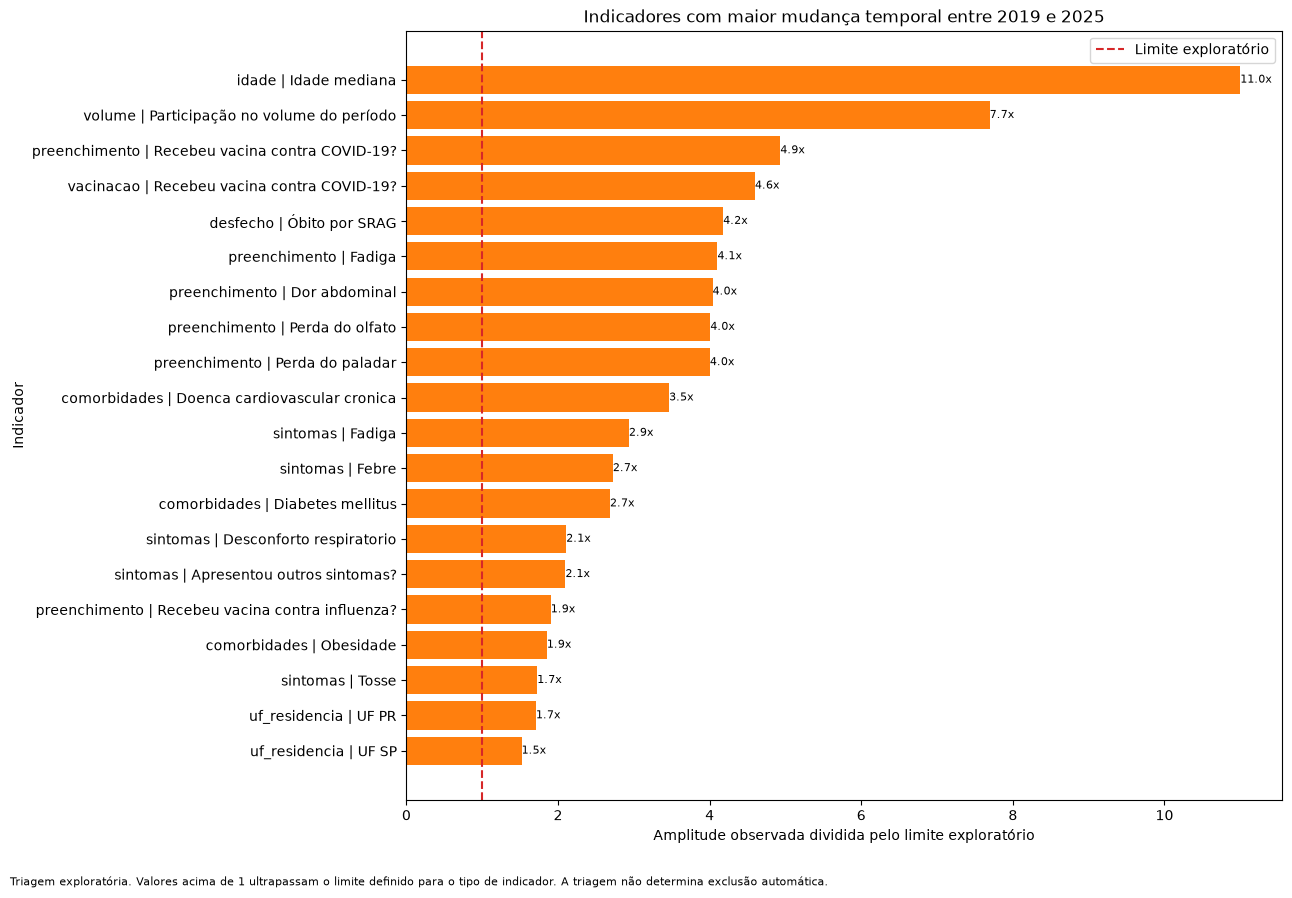

Figura salva em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\eda_02_rupturas_temporais.png


In [61]:
QUANTIDADE_DESTAQUES_GRAFICO = 20

rupturas_para_grafico = (
    rupturas_temporais.loc[
        rupturas_temporais[
            "flag_destaque"
        ]
    ]
    .head(
        QUANTIDADE_DESTAQUES_GRAFICO
    )
    .copy()
)

if rupturas_para_grafico.empty:
    print(
        "Nenhum indicador ultrapassou os limites "
        "exploratórios definidos."
    )
else:
    rupturas_para_grafico[
        "rotulo_grafico"
    ] = (
        rupturas_para_grafico[
            "grupo_indicador"
        ]
        .astype("string")
        + " | "
        + rupturas_para_grafico[
            "indicador"
        ]
        .astype("string")
    )

    rupturas_para_grafico = (
        rupturas_para_grafico
        .sort_values(
            "ordem_destaque",
            ascending=True,
        )
        .reset_index(drop=True)
    )

    figura_rupturas, eixo_rupturas = plt.subplots(
        figsize=(
            13,
            9,
        )
    )

    barras_rupturas = eixo_rupturas.barh(
        rupturas_para_grafico[
            "rotulo_grafico"
        ],
        rupturas_para_grafico[
            "ordem_destaque"
        ],
        color="tab:orange",
    )

    eixo_rupturas.axvline(
        x=1,
        color="tab:red",
        linestyle="--",
        linewidth=1.5,
        label="Limite exploratório",
    )

    eixo_rupturas.set_title(
        "Indicadores com maior mudança temporal entre 2019 e 2025"
    )

    eixo_rupturas.set_xlabel(
        "Amplitude observada dividida pelo limite exploratório"
    )

    eixo_rupturas.set_ylabel(
        "Indicador"
    )

    eixo_rupturas.legend()

    for barra, valor in zip(
        barras_rupturas,
        rupturas_para_grafico[
            "ordem_destaque"
        ],
    ):
        eixo_rupturas.text(
            barra.get_width(),
            barra.get_y()
            + barra.get_height()
            / 2,
            f"{valor:.1f}x",
            va="center",
            ha="left",
            fontsize=8,
        )

    figura_rupturas.text(
        0.01,
        0.01,
        (
            "Triagem exploratória. Valores acima de 1 ultrapassam "
            "o limite definido para o tipo de indicador. "
            "A triagem não determina exclusão automática."
        ),
        fontsize=8,
    )

    figura_rupturas.tight_layout(
        rect=[
            0,
            0.04,
            1,
            1,
        ]
    )

    figura_rupturas.savefig(
        CAMINHO_FIGURA_RUPTURAS,
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

    print(
        "Figura salva em:",
        CAMINHO_FIGURA_RUPTURAS,
    )

In [62]:
rupturas_temporais.to_csv(
    CAMINHO_RUPTURAS_TEMPORAIS,
    index=False,
    encoding="utf-8-sig",
)

resumo_rupturas_temporais.to_csv(
    CAMINHO_RESUMO_RUPTURAS,
    index=False,
    encoding="utf-8-sig",
)

grupos_esperados_rupturas = {
    "volume",
    "desfecho",
    "idade",
    "preenchimento",
    "sintomas",
    "comorbidades",
    "vacinacao",
    "escolaridade",
    "uf_residencia",
}

grupos_observados_rupturas = set(
    rupturas_temporais[
        "grupo_indicador"
    ]
    .dropna()
    .astype("string")
    .tolist()
)

amplitudes_validas = (
    rupturas_temporais[
        "amplitude"
    ]
    .dropna()
    .ge(0)
    .all()
)

anos_minimos_validos = (
    rupturas_temporais[
        "ano_minimo"
    ]
    .dropna()
    .between(
        ANO_INICIAL_TRIAGEM_TEMPORAL,
        ANO_FINAL_TRIAGEM_TEMPORAL,
        inclusive="both",
    )
    .all()
)

anos_maximos_validos = (
    rupturas_temporais[
        "ano_maximo"
    ]
    .dropna()
    .between(
        ANO_INICIAL_TRIAGEM_TEMPORAL,
        ANO_FINAL_TRIAGEM_TEMPORAL,
        inclusive="both",
    )
    .all()
)

figura_rupturas_necessaria = (
    rupturas_temporais[
        "flag_destaque"
    ]
    .any()
)

if figura_rupturas_necessaria:
    figura_rupturas_valida = (
        CAMINHO_FIGURA_RUPTURAS.exists()
    )
else:
    figura_rupturas_valida = True

verificacoes_rupturas = {
    "tabela_rupturas_nao_vazia": (
        not rupturas_temporais.empty
    ),
    "resumo_rupturas_nao_vazio": (
        not resumo_rupturas_temporais.empty
    ),
    "todos_grupos_esperados_presentes": (
        grupos_esperados_rupturas
        .issubset(
            grupos_observados_rupturas
        )
    ),
    "amplitudes_nao_negativas": (
        amplitudes_validas
    ),
    "anos_minimos_dentro_periodo": (
        anos_minimos_validos
    ),
    "anos_maximos_dentro_periodo": (
        anos_maximos_validos
    ),
    "arquivo_rupturas_criado": (
        CAMINHO_RUPTURAS_TEMPORAIS.exists()
    ),
    "arquivo_resumo_criado": (
        CAMINHO_RESUMO_RUPTURAS.exists()
    ),
    "figura_rupturas_valida": (
        figura_rupturas_valida
    ),
}

verificacoes_rupturas_df = pd.DataFrame(
    {
        "verificacao": list(
            verificacoes_rupturas.keys()
        ),
        "resultado": list(
            verificacoes_rupturas.values()
        ),
    }
)

display(
    verificacoes_rupturas_df
)

if not all(
    verificacoes_rupturas.values()
):
    falhas_rupturas = [
        verificacao
        for verificacao, resultado
        in verificacoes_rupturas.items()
        if not resultado
    ]

    raise RuntimeError(
        "A consolidação temporal terminou com falhas: "
        f"{falhas_rupturas}"
    )

print(
    "Consolidação das mudanças temporais validada com sucesso."
)

,verificacao,resultado
0,tabela_rupturas_nao_vazia,True
1,resumo_rupturas_nao_vazio,True
2,todos_grupos_esperados_presentes,True
3,amplitudes_nao_negativas,True
4,anos_minimos_dentro_periodo,True
5,anos_maximos_dentro_periodo,True
6,arquivo_rupturas_criado,True
7,arquivo_resumo_criado,True
8,figura_rupturas_valida,True


Consolidação das mudanças temporais validada com sucesso.


## 7. Óbito por características clínicas e demográficas

Esta seção descreve a associação bruta entre características registradas
na admissão e óbito por SRAG.

Quando uma partição de treino estiver disponível, somente essa partição
será utilizada. Caso contrário, a análise utilizará a coorte carregada
e registrará essa condição na tabela de resumo.

Serão avaliados:

- proporção de óbito por faixa etária;
- proporção de óbito por número de comorbidades;
- proporção de óbito segundo sintomas estruturados;
- proporção de óbito segundo comorbidades estruturadas;
- razão de chances bruta para sintomas e comorbidades;
- diferenças nos padrões de ausência entre curas e óbitos.

Os intervalos de confiança serão calculados pelo método de Wilson.

As associações apresentadas são descritivas e não devem ser interpretadas
como relações causais ou como importância preditiva ajustada.

In [63]:
# ============================================================
# Base enxuta para as análises de desfecho
# ============================================================

import gc
import time

t0_base_desfecho = time.perf_counter()

COLUNAS_FIXAS_DESFECHO = [
    "ano_internacao",
    "alvo_obito_srag",
    "faixa_etaria",
    "sexo_categoria",
    "n_sintomas_confirmados",
    "n_sintomas_avaliados",
    "n_comorbidades_confirmadas",
    "n_comorbidades_avaliadas",
    "flag_multimorbidade",
]

COLUNAS_ANALISE_DESFECHO = list(
    dict.fromkeys(
        COLUNAS_FIXAS_DESFECHO
        + list(COLUNAS_SINTOMAS)
        + list(COLUNAS_COMORBIDADES)
    )
)

colunas_desfecho_ausentes = [
    coluna
    for coluna in COLUNAS_ANALISE_DESFECHO
    if coluna not in coorte.columns
]

if colunas_desfecho_ausentes:
    raise KeyError(
        "A coorte não contém todas as colunas necessárias "
        "para a análise de desfecho. "
        f"Colunas ausentes: {colunas_desfecho_ausentes}"
    )

memoria_coorte_mb = (
    coorte.memory_usage(
        index=True,
        deep=True,
    )
    .sum()
    / 1_048_576
)

if "particao" in coorte.columns:
    particao_normalizada = (
        coorte["particao"]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    mascara_base_desfecho = (
        particao_normalizada
        .eq("treino")
        .to_numpy(dtype=bool)
    )

    if not mascara_base_desfecho.any():
        raise ValueError(
            "A coluna 'particao' existe, mas não há "
            "registros identificados como treino."
        )

    base_analise_desfecho = (
        coorte.loc[
            mascara_base_desfecho,
            COLUNAS_ANALISE_DESFECHO,
        ]
        .reset_index(drop=True)
    )

    origem_analise_desfecho = "particao_treino"

    del particao_normalizada
    del mascara_base_desfecho

else:
    # Neste ponto ainda não há uma partição disponível no B_06.
    # A análise continua descritiva sobre a coorte, mas somente
    # as colunas realmente necessárias são materializadas.
    base_analise_desfecho = (
        coorte.loc[
            :,
            COLUNAS_ANALISE_DESFECHO,
        ]
        .reset_index(drop=True)
    )

    origem_analise_desfecho = "coorte_sem_particao"

    print(
        "ATENÇÃO: a coorte não contém a coluna 'particao'. "
        "A análise de desfecho usa a coorte inteira, mas carrega "
        "somente as colunas necessárias. "
        "A restrição definitiva ao treino será aplicada depois "
        "que a partição por hash estiver centralizada em src."
    )

if base_analise_desfecho.empty:
    raise ValueError(
        "A base selecionada para a análise "
        "do desfecho está vazia."
    )

alvo_valido = (
    base_analise_desfecho["alvo_obito_srag"]
    .isin([0, 1])
    .all()
)

if not alvo_valido:
    valores_invalidos_alvo = sorted(
        base_analise_desfecho.loc[
            ~base_analise_desfecho["alvo_obito_srag"].isin([0, 1]),
            "alvo_obito_srag",
        ]
        .drop_duplicates()
        .astype("string")
        .tolist()
    )

    raise ValueError(
        "A base da análise contém valores inválidos "
        "em 'alvo_obito_srag': "
        f"{valores_invalidos_alvo}"
    )

# Compactar apenas as colunas categóricas da base enxuta.
# A coorte original não é alterada.
colunas_textuais_desfecho = (
    base_analise_desfecho
    .select_dtypes(
        include=[
            "object",
            "string",
        ]
    )
    .columns
    .tolist()
)

for coluna in colunas_textuais_desfecho:
    quantidade_categorias = (
        base_analise_desfecho[coluna]
        .nunique(dropna=False)
    )

    # Sintomas, comorbidades, faixa etária e sexo têm
    # cardinalidade pequena e se beneficiam de category.
    if quantidade_categorias <= 500:
        base_analise_desfecho[coluna] = (
            base_analise_desfecho[coluna]
            .astype("category")
        )

memoria_base_desfecho_mb = (
    base_analise_desfecho
    .memory_usage(
        index=True,
        deep=True,
    )
    .sum()
    / 1_048_576
)

gc.collect()

print(
    "Origem da análise do desfecho:",
    origem_analise_desfecho,
)

print(
    "Registros utilizados:",
    len(base_analise_desfecho),
)

print(
    "Colunas utilizadas:",
    len(COLUNAS_ANALISE_DESFECHO),
)

print(
    "Óbitos por SRAG:",
    int(
        base_analise_desfecho["alvo_obito_srag"]
        .sum()
    ),
)

print(
    "Memória da coorte completa:",
    f"{memoria_coorte_mb:,.2f} MB",
)

print(
    "Memória da base enxuta de desfecho:",
    f"{memoria_base_desfecho_mb:,.2f} MB",
)

print(
    "Redução de memória:",
    f"{(
        1
        - memoria_base_desfecho_mb
        / memoria_coorte_mb
    ) * 100:,.2f}%",
)

print(
    "Tempo de preparação:",
    f"{time.perf_counter() - t0_base_desfecho:,.2f} s",
)

ATENÇÃO: a coorte não contém a coluna 'particao'. A análise de desfecho usa a coorte inteira, mas carrega somente as colunas necessárias. A restrição definitiva ao treino será aplicada depois que a partição por hash estiver centralizada em src.
Origem da análise do desfecho: coorte_sem_particao
Registros utilizados: 3884728
Colunas utilizadas: 35
Óbitos por SRAG: 847720
Memória da coorte completa: 565.83 MB
Memória da base enxuta de desfecho: 170.42 MB
Redução de memória: 69.88%
Tempo de preparação: 0.12 s


In [64]:
CAMINHO_OBITO_FAIXA_ETARIA = (
    C.TABLES_DIR
    / "eda_02_obito_faixa_etaria.csv"
)

CAMINHO_OBITO_NUMERO_COMORBIDADES = (
    C.TABLES_DIR
    / "eda_02_obito_numero_comorbidades.csv"
)

CAMINHO_OBITO_SINTOMAS = (
    C.TABLES_DIR
    / "eda_02_obito_sintomas.csv"
)

CAMINHO_OBITO_COMORBIDADES = (
    C.TABLES_DIR
    / "eda_02_obito_comorbidades.csv"
)

CAMINHO_AUSENCIA_DESFECHO = (
    C.TABLES_DIR
    / "eda_02_ausencia_por_desfecho.csv"
)

CAMINHO_RESUMO_DESFECHO = (
    C.TABLES_DIR
    / "eda_02_resumo_analise_desfecho.csv"
)

CAMINHO_FIGURA_OBITO_FAIXA_ETARIA = (
    C.FIGURES_DIR
    / "eda_02_obito_faixa_etaria.png"
)

CAMINHO_FIGURA_OBITO_COMORBIDADES = (
    C.FIGURES_DIR
    / "eda_02_obito_numero_comorbidades.png"
)

CAMINHO_FIGURA_OR_SINTOMAS = (
    C.FIGURES_DIR
    / "eda_02_odds_ratio_sintomas.png"
)

CAMINHO_FIGURA_OR_COMORBIDADES = (
    C.FIGURES_DIR
    / "eda_02_odds_ratio_comorbidades.png"
)

CAMINHO_FIGURA_AUSENCIA_DESFECHO = (
    C.FIGURES_DIR
    / "eda_02_ausencia_por_desfecho.png"
)

print(
    "Tabela de óbito por faixa etária:",
    CAMINHO_OBITO_FAIXA_ETARIA,
)

print(
    "Tabela de óbito por comorbidades:",
    CAMINHO_OBITO_NUMERO_COMORBIDADES,
)

print(
    "Tabela de óbito por sintomas:",
    CAMINHO_OBITO_SINTOMAS,
)

Tabela de óbito por faixa etária: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\eda_02_obito_faixa_etaria.csv
Tabela de óbito por comorbidades: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\eda_02_obito_numero_comorbidades.csv
Tabela de óbito por sintomas: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\eda_02_obito_sintomas.csv


In [65]:
def calcular_ic_wilson(
    quantidade_eventos: int,
    quantidade_total: int,
    nivel_confianca: float = 0.95,
) -> tuple:
    """
    Calcula o intervalo de confiança de Wilson para uma proporção.

    O retorno é apresentado na escala percentual.
    """

    if quantidade_total <= 0:
        return (
            np.nan,
            np.nan,
        )

    if nivel_confianca != 0.95:
        raise ValueError(
            "Esta implementação utiliza o valor crítico "
            "correspondente ao nível de confiança de 95%."
        )

    valor_z = 1.959963984540054

    proporcao = (
        quantidade_eventos
        / quantidade_total
    )

    z_quadrado = np.square(
        valor_z
    )

    denominador = (
        1
        + z_quadrado
        / quantidade_total
    )

    centro = (
        proporcao
        + z_quadrado
        / (
            2
            * quantidade_total
        )
    )

    componente_variancia = (
        proporcao
        * (
            1
            - proporcao
        )
        / quantidade_total
        + z_quadrado
        / (
            4
            * np.square(
                quantidade_total
            )
        )
    )

    margem = (
        valor_z
        * np.sqrt(
            componente_variancia
        )
    )

    limite_inferior = (
        (
            centro
            - margem
        )
        / denominador
    )

    limite_superior = (
        (
            centro
            + margem
        )
        / denominador
    )

    return (
        limite_inferior
        * 100,
        limite_superior
        * 100,
    )


def calcular_odds_ratio_bruta(
    obito_exposto: int,
    cura_exposto: int,
    obito_referencia: int,
    cura_referencia: int,
) -> tuple:
    """
    Calcula a razão de chances bruta e o IC de 95%.

    Quando alguma célula é igual a zero, é aplicada a correção
    de continuidade de 0,5 às quatro células.
    """

    celulas = np.array(
        [
            obito_exposto,
            cura_exposto,
            obito_referencia,
            cura_referencia,
        ],
        dtype="float64",
    )

    if np.any(
        celulas < 0
    ):
        raise ValueError(
            "As contagens da tabela dois por dois "
            "não podem ser negativas."
        )

    if np.any(
        celulas == 0
    ):
        celulas = (
            celulas
            + 0.5
        )

    obito_exposto_corrigido = (
        celulas[0]
    )

    cura_exposto_corrigido = (
        celulas[1]
    )

    obito_referencia_corrigido = (
        celulas[2]
    )

    cura_referencia_corrigido = (
        celulas[3]
    )

    odds_ratio = (
        obito_exposto_corrigido
        * cura_referencia_corrigido
        / (
            cura_exposto_corrigido
            * obito_referencia_corrigido
        )
    )

    erro_padrao_log = np.sqrt(
        1
        / obito_exposto_corrigido
        + 1
        / cura_exposto_corrigido
        + 1
        / obito_referencia_corrigido
        + 1
        / cura_referencia_corrigido
    )

    valor_z = 1.959963984540054

    limite_inferior = np.exp(
        np.log(
            odds_ratio
        )
        - valor_z
        * erro_padrao_log
    )

    limite_superior = np.exp(
        np.log(
            odds_ratio
        )
        + valor_z
        * erro_padrao_log
    )

    return (
        float(
            odds_ratio
        ),
        float(
            limite_inferior
        ),
        float(
            limite_superior
        ),
    )


def criar_tabela_obito_categorica(
    dataframe: pd.DataFrame,
    coluna_categoria: str,
    nome_categoria_saida: str,
) -> pd.DataFrame:
    """
    Calcula quantidade, proporção de óbito e intervalo de Wilson
    para cada categoria de uma variável.
    """

    if coluna_categoria not in dataframe.columns:
        raise KeyError(
            "A coluna não está disponível na base: "
            f"{coluna_categoria}"
        )

    tabela = (
        dataframe.groupby(
            coluna_categoria,
            dropna=False,
        )
        .agg(
            quantidade_total=(
                "alvo_obito_srag",
                "size",
            ),
            quantidade_obito_srag=(
                "alvo_obito_srag",
                "sum",
            ),
        )
        .reset_index()
        .rename(
            columns={
                coluna_categoria: (
                    nome_categoria_saida
                ),
            }
        )
    )

    tabela[
        "quantidade_cura"
    ] = (
        tabela[
            "quantidade_total"
        ]
        .sub(
            tabela[
                "quantidade_obito_srag"
            ]
        )
    )

    tabela[
        "percentual_obito_srag"
    ] = (
        tabela[
            "quantidade_obito_srag"
        ]
        .div(
            tabela[
                "quantidade_total"
        ]
        )
        .mul(100)
    )

    intervalos = [
        calcular_ic_wilson(
            quantidade_eventos=int(
                linha[
                    "quantidade_obito_srag"
                ]
            ),
            quantidade_total=int(
                linha[
                    "quantidade_total"
                ]
            ),
        )
        for _, linha in tabela.iterrows()
    ]

    tabela[
        "ic95_inferior"
    ] = [
        intervalo[0]
        for intervalo in intervalos
    ]

    tabela[
        "ic95_superior"
    ] = [
        intervalo[1]
        for intervalo in intervalos
    ]

    tabela = (
        tabela.sort_values(
            "percentual_obito_srag",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    return tabela

In [66]:
if "faixa_etaria" not in base_analise_desfecho.columns:
    raise KeyError(
        "A coluna faixa_etaria não está disponível. "
        "Execute primeiro a seção demográfica."
    )

obito_faixa_etaria = (
    criar_tabela_obito_categorica(
        dataframe=base_analise_desfecho,
        coluna_categoria="faixa_etaria",
        nome_categoria_saida="faixa_etaria",
    )
)

ORDEM_FAIXA_OBITO = (
    ROTULOS_FAIXA_ETARIA
    + [
        "Idade ausente ou inválida",
    ]
)

ordem_faixa_obito = {
    categoria: posicao
    for posicao, categoria in enumerate(
        ORDEM_FAIXA_OBITO
    )
}

obito_faixa_etaria[
    "ordem_faixa"
] = (
    obito_faixa_etaria[
        "faixa_etaria"
    ]
    .astype("string")
    .map(
        ordem_faixa_obito
    )
    .fillna(
        len(
            ordem_faixa_obito
        )
    )
)

obito_faixa_etaria = (
    obito_faixa_etaria
    .sort_values(
        "ordem_faixa"
    )
    .drop(
        columns=[
            "ordem_faixa",
        ]
    )
    .reset_index(drop=True)
)

display(
    obito_faixa_etaria
)

,faixa_etaria,quantidade_total,quantidade_obito_srag,quantidade_cura,percentual_obito_srag,ic95_inferior,ic95_superior
0,1-4,329032,3560,325472,1.081962,1.047180,1.117886
1,12-17,45043,2190,42853,4.862021,4.667223,5.064517
2,18-39,435492,48868,386624,11.221331,11.127931,11.315416
3,40-59,908309,191484,716825,21.081372,20.997612,21.165377
4,5-11,168613,2106,166507,1.249014,1.197104,1.303146
5,60-79,1103748,379584,724164,34.390459,34.301896,34.479130
6,80+,515409,213356,302053,41.395474,41.261072,41.530004
7,<1,379058,6570,372488,1.733244,1.692185,1.775282
8,desconhecida,24,2,22,8.333333,2.315882,25.848802


In [67]:
COLUNAS_CONTAGEM_COMORBIDADES = [
    "n_comorbidades_confirmadas",
    "n_comorbidades_avaliadas",
]

colunas_contagem_comorbidades_ausentes = [
    coluna
    for coluna in COLUNAS_CONTAGEM_COMORBIDADES
    if coluna not in base_analise_desfecho.columns
]

if colunas_contagem_comorbidades_ausentes:
    raise KeyError(
        "As colunas de contagem de comorbidades "
        "não estão disponíveis: "
        f"{colunas_contagem_comorbidades_ausentes}"
    )

numero_comorbidades = (
    base_analise_desfecho[
        "n_comorbidades_confirmadas"
    ]
    .astype("Int64")
)

condicoes_comorbidades = [
    numero_comorbidades.eq(0),
    numero_comorbidades.eq(1),
    numero_comorbidades.eq(2),
    numero_comorbidades.ge(3),
]

rotulos_comorbidades = [
    "Nenhuma comorbidade confirmada",
    "Uma comorbidade confirmada",
    "Duas comorbidades confirmadas",
    "Três ou mais comorbidades confirmadas",
]

base_analise_desfecho[
    "grupo_numero_comorbidades"
] = pd.Series(
    np.select(
        condicoes_comorbidades,
        rotulos_comorbidades,
        default=(
            "Número de comorbidades indisponível"
        ),
    ),
    index=base_analise_desfecho.index,
    dtype="string",
)

obito_numero_comorbidades = (
    criar_tabela_obito_categorica(
        dataframe=base_analise_desfecho,
        coluna_categoria=(
            "grupo_numero_comorbidades"
        ),
        nome_categoria_saida=(
            "grupo_numero_comorbidades"
        ),
    )
)

ORDEM_NUMERO_COMORBIDADES = (
    rotulos_comorbidades
    + [
        "Número de comorbidades indisponível",
    ]
)

ordem_numero_comorbidades = {
    categoria: posicao
    for posicao, categoria in enumerate(
        ORDEM_NUMERO_COMORBIDADES
    )
}

obito_numero_comorbidades[
    "ordem_comorbidades"
] = (
    obito_numero_comorbidades[
        "grupo_numero_comorbidades"
    ]
    .map(
        ordem_numero_comorbidades
    )
    .fillna(
        len(
            ordem_numero_comorbidades
        )
    )
)

obito_numero_comorbidades = (
    obito_numero_comorbidades
    .sort_values(
        "ordem_comorbidades"
    )
    .drop(
        columns=[
            "ordem_comorbidades",
        ]
    )
    .reset_index(drop=True)
)

display(
    obito_numero_comorbidades
)

,grupo_numero_comorbidades,quantidade_total,quantidade_obito_srag,quantidade_cura,percentual_obito_srag,ic95_inferior,ic95_superior
0,Nenhuma comorbidade confirmada,1743006,217746,1525260,12.492556,12.443554,12.541723
1,Uma comorbidade confirmada,1097718,263231,834487,23.979838,23.900058,24.059800
2,Duas comorbidades confirmadas,684926,226076,458850,33.007361,32.896093,33.118821
3,Três ou mais comorbidades confirmadas,359078,140667,218411,39.174497,39.014953,39.334273


In [68]:
def criar_tabela_obito_indicadores(
    dataframe: pd.DataFrame,
    colunas: list,
    grupo_indicador: str,
    nomes_amigaveis: dict,
) -> pd.DataFrame:
    """
    Calcula proporções de óbito e razão de chances bruta
    para respostas sim versus não.
    """

    registros = []

    for coluna in colunas:
        if coluna not in dataframe.columns:
            continue

        resposta = (
            normalizar_resposta_clinica(
                dataframe[
                    coluna
                ]
            )
        )

        dados_variavel = pd.DataFrame(
            {
                "resposta": resposta,
                "alvo_obito_srag": dataframe[
                    "alvo_obito_srag"
                ],
            }
        )

        dados_validos = (
            dados_variavel.loc[
                dados_variavel[
                    "resposta"
                ].isin(
                    [
                        "sim",
                        "nao",
                    ]
                )
            ]
            .copy()
        )

        quantidade_sim = int(
            dados_validos[
                "resposta"
            ]
            .eq("sim")
            .sum()
        )

        quantidade_nao = int(
            dados_validos[
                "resposta"
            ]
            .eq("nao")
            .sum()
        )

        obito_sim = int(
            dados_validos.loc[
                dados_validos[
                    "resposta"
                ].eq("sim"),
                "alvo_obito_srag",
            ]
            .sum()
        )

        obito_nao = int(
            dados_validos.loc[
                dados_validos[
                    "resposta"
                ].eq("nao"),
                "alvo_obito_srag",
            ]
            .sum()
        )

        cura_sim = (
            quantidade_sim
            - obito_sim
        )

        cura_nao = (
            quantidade_nao
            - obito_nao
        )

        percentual_obito_sim = (
            obito_sim
            / quantidade_sim
            * 100
            if quantidade_sim > 0
            else np.nan
        )

        percentual_obito_nao = (
            obito_nao
            / quantidade_nao
            * 100
            if quantidade_nao > 0
            else np.nan
        )

        ic_sim = calcular_ic_wilson(
            quantidade_eventos=obito_sim,
            quantidade_total=quantidade_sim,
        )

        ic_nao = calcular_ic_wilson(
            quantidade_eventos=obito_nao,
            quantidade_total=quantidade_nao,
        )

        if (
            quantidade_sim > 0
            and quantidade_nao > 0
        ):
            resultado_or = (
                calcular_odds_ratio_bruta(
                    obito_exposto=obito_sim,
                    cura_exposto=cura_sim,
                    obito_referencia=obito_nao,
                    cura_referencia=cura_nao,
                )
            )
        else:
            resultado_or = (
                np.nan,
                np.nan,
                np.nan,
            )

        quantidade_ignorado = int(
            dados_variavel[
                "resposta"
            ]
            .eq("ignorado")
            .sum()
        )

        quantidade_ausente = int(
            dados_variavel[
                "resposta"
            ]
            .eq("ausente")
            .sum()
        )

        quantidade_inesperado = int(
            dados_variavel[
                "resposta"
            ]
            .eq("inesperado")
            .sum()
        )

        registros.append(
            {
                "grupo_indicador": grupo_indicador,
                "coluna": coluna,
                "nome_amigavel": (
                    nomes_amigaveis.get(
                        coluna,
                        coluna,
                    )
                ),
                "quantidade_sim": quantidade_sim,
                "obito_sim": obito_sim,
                "cura_sim": cura_sim,
                "percentual_obito_sim": (
                    percentual_obito_sim
                ),
                "ic95_obito_sim_inferior": (
                    ic_sim[0]
                ),
                "ic95_obito_sim_superior": (
                    ic_sim[1]
                ),
                "quantidade_nao": quantidade_nao,
                "obito_nao": obito_nao,
                "cura_nao": cura_nao,
                "percentual_obito_nao": (
                    percentual_obito_nao
                ),
                "ic95_obito_nao_inferior": (
                    ic_nao[0]
                ),
                "ic95_obito_nao_superior": (
                    ic_nao[1]
                ),
                "odds_ratio_bruta": (
                    resultado_or[0]
                ),
                "ic95_or_inferior": (
                    resultado_or[1]
                ),
                "ic95_or_superior": (
                    resultado_or[2]
                ),
                "quantidade_ignorado": (
                    quantidade_ignorado
                ),
                "quantidade_ausente": (
                    quantidade_ausente
                ),
                "quantidade_inesperado": (
                    quantidade_inesperado
                ),
            }
        )

    resultado = pd.DataFrame(
        registros
    )

    resultado = (
        resultado.sort_values(
            [
                "odds_ratio_bruta",
                "coluna",
            ],
            ascending=[
                False,
                True,
            ],
            na_position="last",
        )
        .reset_index(drop=True)
    )

    return resultado

In [69]:
obito_sintomas = (
    criar_tabela_obito_indicadores(
        dataframe=base_analise_desfecho,
        colunas=COLUNAS_SINTOMAS,
        grupo_indicador="sintomas",
        nomes_amigaveis=(
            nomes_amigaveis_dicionario
        ),
    )
)

obito_comorbidades = (
    criar_tabela_obito_indicadores(
        dataframe=base_analise_desfecho,
        colunas=COLUNAS_COMORBIDADES,
        grupo_indicador="comorbidades",
        nomes_amigaveis=(
            nomes_amigaveis_dicionario
        ),
    )
)

if obito_sintomas.empty:
    raise ValueError(
        "A tabela de óbito por sintomas está vazia."
    )

if obito_comorbidades.empty:
    raise ValueError(
        "A tabela de óbito por comorbidades está vazia."
    )

display(
    obito_sintomas
)

display(
    obito_comorbidades
)

,grupo_indicador,coluna,nome_amigavel,quantidade_sim,obito_sim,cura_sim,percentual_obito_sim,ic95_obito_sim_inferior,ic95_obito_sim_superior,quantidade_nao,...,cura_nao,percentual_obito_nao,ic95_obito_nao_inferior,ic95_obito_nao_superior,odds_ratio_bruta,ic95_or_inferior,ic95_or_superior,quantidade_ignorado,quantidade_ausente,quantidade_inesperado
0,sintomas,saturacao,Saturacao de oxigenio abaixo de 95%?,2294927,612093,1682834,26.671567,26.614390,26.728823,988407,...,867693,12.212985,12.148580,12.277684,2.614476,2.597033,2.632035,40398,560996,0
1,sintomas,dispneia,Dispneia,2665358,657917,2007441,24.684001,24.632274,24.735801,775064,...,672933,13.177105,13.101986,13.252590,2.159447,2.144069,2.174935,29591,414715,0
2,sintomas,desc_resp,Desconforto respiratorio,2284833,553217,1731616,24.212579,24.157078,24.268167,966073,...,810825,16.070007,15.996909,16.143376,1.668572,1.658232,1.678977,36657,597165,0
3,sintomas,fadiga,Fadiga,728808,170634,558174,23.412751,23.315673,23.510109,1788552,...,1452327,18.798727,18.741535,18.856052,1.320476,1.311799,1.329210,67239,1300129,0
4,sintomas,perd_olft,Perda do olfato,190997,40682,150315,21.299811,21.116773,21.484003,2196927,...,1761987,19.797654,19.745015,19.850398,1.096411,1.083934,1.109032,99859,1396945,0
5,sintomas,perd_pala,Perda do paladar,194276,41045,153231,21.127159,20.946212,21.309249,2189663,...,1755895,19.809806,19.757068,19.862650,1.084313,1.072034,1.096733,101182,1399607,0
6,sintomas,diarreia,Diarreia,418567,86322,332245,20.623222,20.500920,20.746063,2387145,...,1895424,20.598707,20.547451,20.650057,1.001499,0.993402,1.009663,63190,1015826,0
7,sintomas,dor_abd,Dor abdominal,203925,39369,164556,19.305627,19.134898,19.477512,2202633,...,1763978,19.915029,19.862341,19.967822,0.962079,0.951095,0.973190,75499,1402671,0
8,sintomas,garganta,Dor de garganta,565926,111463,454463,19.695685,19.592275,19.799505,2247193,...,1776677,20.937943,20.884797,20.991189,0.926118,0.919385,0.932900,85226,986383,0
9,sintomas,outro_sin,Apresentou outros sintomas?,1192832,234972,957860,19.698667,19.627391,19.770138,1591654,...,1250778,21.416464,21.352800,21.480265,0.900115,0.894828,0.905433,80205,1020037,0


,grupo_indicador,coluna,nome_amigavel,quantidade_sim,obito_sim,cura_sim,percentual_obito_sim,ic95_obito_sim_inferior,ic95_obito_sim_superior,quantidade_nao,...,cura_nao,percentual_obito_nao,ic95_obito_nao_inferior,ic95_obito_nao_superior,odds_ratio_bruta,ic95_or_inferior,ic95_or_superior,quantidade_ignorado,quantidade_ausente,quantidade_inesperado
0,comorbidades,renal,Doenca renal cronica,122725,50874,71851,41.453657,41.178307,41.729541,1276283,...,926272,27.424247,27.346915,27.501714,1.873786,1.851427,1.896414,27196,2458524,0
1,comorbidades,hepatica,Doenca hepatica cronica,29302,12037,17265,41.079107,40.517006,41.643547,1341175,...,965646,28.000000,27.924074,28.076052,1.792776,1.751004,1.835546,29061,2485190,0
2,comorbidades,cardiopati,Doenca cardiovascular cronica,1006384,341520,664864,33.935357,33.842911,34.027925,718379,...,546272,23.957688,23.859127,24.056528,1.630398,1.619333,1.641540,16544,2143421,0
3,comorbidades,diabetes,Diabetes mellitus,676931,238483,438448,35.230031,35.116321,35.343908,936019,...,697521,25.480038,25.391863,25.568415,1.590786,1.579978,1.601669,19535,2252243,0
4,comorbidades,neurologic,Doenca neurologica cronica,170738,57826,112912,33.868266,33.644148,34.093110,1245236,...,899883,27.733940,27.655377,27.812639,1.334461,1.320175,1.348902,27247,2441507,0
5,comorbidades,imunodepre,Imunodeficiencia ou imunodepressao,103332,35057,68275,33.926567,33.638491,34.215838,1289670,...,930485,27.850923,27.773624,27.928354,1.330161,1.312402,1.348161,28765,2462961,0
6,comorbidades,obesidade,Obesidade,209272,70047,139225,33.471750,33.269876,33.674230,1203367,...,871003,27.619504,27.539690,27.699461,1.318493,1.305479,1.331638,36680,2435409,0
7,comorbidades,out_morbi,Outro fator de risco?,919614,287784,631830,31.293999,31.199307,31.388848,717336,...,526323,26.628107,26.525945,26.730520,1.255035,1.246475,1.263654,21942,2225836,0
8,comorbidades,pneumopati,Outra pneumopatia cronica,178041,56599,121442,31.789869,31.573963,32.006560,1238278,...,892296,27.940576,27.861612,28.019676,1.201975,1.189159,1.214929,27956,2440453,0
9,comorbidades,hematologi,Doenca hematologica cronica,31738,8978,22760,28.287857,27.794995,28.785974,1343996,...,965136,28.189072,28.113069,28.265199,1.004887,0.980356,1.030031,29172,2479822,0


In [70]:
COLUNAS_AUSENCIA_DESFECHO = list(
    dict.fromkeys(
        COLUNAS_SINTOMAS
        + COLUNAS_COMORBIDADES
        + COLUNAS_VACINACAO
        + [
            "cs_escol_n",
            "sg_uf",
            "nu_idade_n",
            "tp_idade",
        ]
    )
)

COLUNAS_AUSENCIA_DESFECHO = [
    coluna
    for coluna in COLUNAS_AUSENCIA_DESFECHO
    if coluna in base_analise_desfecho.columns
]

registros_ausencia_desfecho = []

for coluna in COLUNAS_AUSENCIA_DESFECHO:
    serie_ausente = (
        base_analise_desfecho[
            coluna
        ]
        .isna()
    )

    mascara_cura = (
        base_analise_desfecho[
            "alvo_obito_srag"
        ]
        .eq(0)
    )

    mascara_obito = (
        base_analise_desfecho[
            "alvo_obito_srag"
        ]
        .eq(1)
    )

    quantidade_cura = int(
        mascara_cura.sum()
    )

    quantidade_obito = int(
        mascara_obito.sum()
    )

    ausente_cura = int(
        (
            serie_ausente
            & mascara_cura
        )
        .sum()
    )

    ausente_obito = int(
        (
            serie_ausente
            & mascara_obito
        )
        .sum()
    )

    percentual_ausente_cura = (
        ausente_cura
        / quantidade_cura
        * 100
        if quantidade_cura > 0
        else np.nan
    )

    percentual_ausente_obito = (
        ausente_obito
        / quantidade_obito
        * 100
        if quantidade_obito > 0
        else np.nan
    )

    registros_ausencia_desfecho.append(
        {
            "coluna": coluna,
            "nome_amigavel": (
                nomes_amigaveis_dicionario.get(
                    coluna,
                    coluna,
                )
            ),
            "quantidade_cura": quantidade_cura,
            "ausente_cura": ausente_cura,
            "percentual_ausente_cura": (
                percentual_ausente_cura
            ),
            "quantidade_obito": quantidade_obito,
            "ausente_obito": ausente_obito,
            "percentual_ausente_obito": (
                percentual_ausente_obito
            ),
            "diferenca_pp_obito_menos_cura": (
                percentual_ausente_obito
                - percentual_ausente_cura
            ),
        }
    )

ausencia_por_desfecho = pd.DataFrame(
    registros_ausencia_desfecho
)

ausencia_por_desfecho[
    "diferenca_absoluta_pp"
] = (
    ausencia_por_desfecho[
        "diferenca_pp_obito_menos_cura"
    ]
    .abs()
)

ausencia_por_desfecho = (
    ausencia_por_desfecho
    .sort_values(
        [
            "diferenca_absoluta_pp",
            "coluna",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .reset_index(drop=True)
)

display(
    ausencia_por_desfecho.head(30)
)

,coluna,nome_amigavel,quantidade_cura,ausente_cura,percentual_ausente_cura,quantidade_obito,ausente_obito,percentual_ausente_obito,diferenca_pp_obito_menos_cura,diferenca_absoluta_pp
0,cardiopati,Doenca cardiovascular cronica,3037008,1814863,59.758255,847720,328558,38.757845,-21.000411,21.000411
1,diabetes,Diabetes mellitus,3037008,1888184,62.172507,847720,364059,42.945666,-19.226841,19.226841
2,out_morbi,Outro fator de risco?,3037008,1864150,61.381136,847720,361686,42.665739,-18.715397,18.715397
3,obesidade,Obesidade,3037008,2003351,65.964627,847720,432058,50.967065,-14.997562,14.997562
4,renal,Doenca renal cronica,3037008,2021342,66.557019,847720,437182,51.571509,-14.985510,14.985510
5,neurologic,Doenca neurologica cronica,3037008,2006823,66.078950,847720,434684,51.276837,-14.802113,14.802113
6,pneumopati,Outra pneumopatia cronica,3037008,2005379,66.031403,847720,435074,51.322842,-14.708561,14.708561
7,imunodepre,Imunodeficiencia ou imunodepressao,3037008,2019882,66.508946,847720,443079,52.267140,-14.241806,14.241806
8,hepatica,Doenca hepatica cronica,3037008,2035607,67.026725,847720,449583,53.034375,-13.992350,13.992350
9,hematologi,Doenca hematologica cronica,3037008,2030604,66.861990,847720,449218,52.991318,-13.870673,13.870673


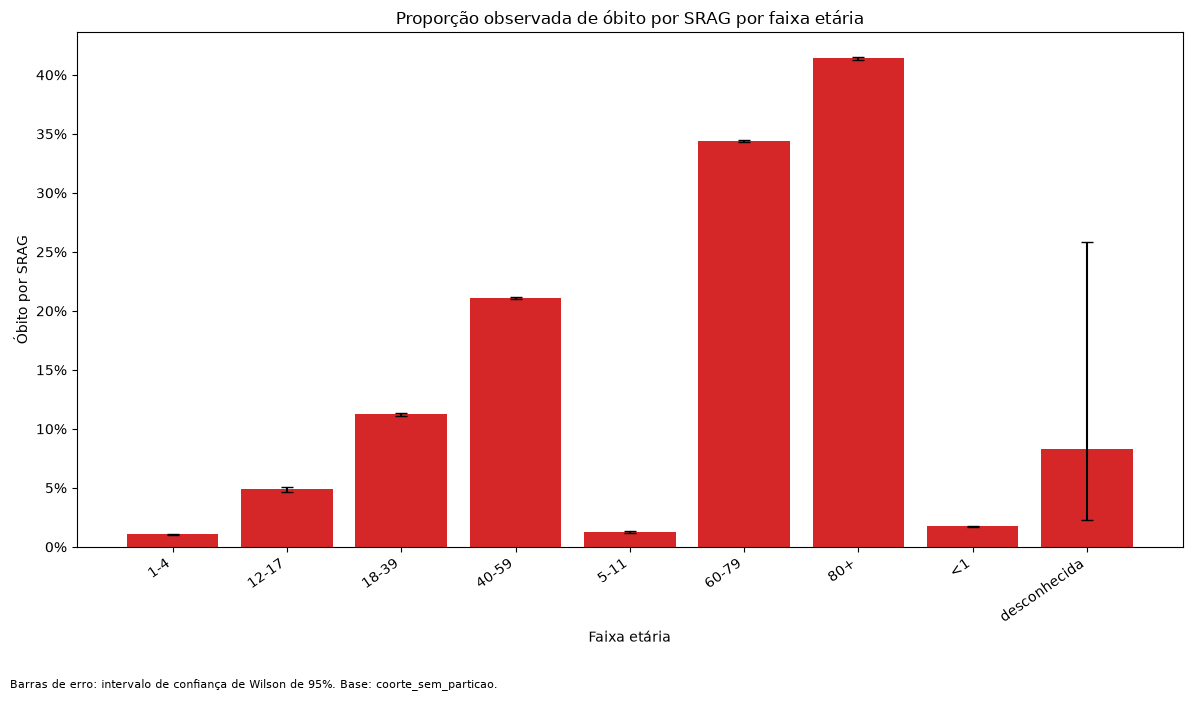

Figura salva em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\eda_02_obito_faixa_etaria.png


In [71]:
dados_faixa_grafico = (
    obito_faixa_etaria.loc[
        obito_faixa_etaria[
            "quantidade_total"
        ].gt(0)
    ]
    .copy()
)

categorias_faixa = (
    dados_faixa_grafico[
        "faixa_etaria"
    ]
    .astype("string")
    .tolist()
)

percentuais_faixa = (
    dados_faixa_grafico[
        "percentual_obito_srag"
    ]
    .astype(float)
    .to_numpy()
)

erros_inferiores_faixa = (
    dados_faixa_grafico[
        "percentual_obito_srag"
    ]
    .sub(
        dados_faixa_grafico[
            "ic95_inferior"
        ]
    )
    .astype(float)
    .to_numpy()
)

erros_superiores_faixa = (
    dados_faixa_grafico[
        "ic95_superior"
    ]
    .sub(
        dados_faixa_grafico[
            "percentual_obito_srag"
        ]
    )
    .astype(float)
    .to_numpy()
)

posicoes_faixa = np.arange(
    len(
        dados_faixa_grafico
    )
)

figura_obito_faixa, eixo_obito_faixa = plt.subplots(
    figsize=(
        12,
        7,
    )
)

eixo_obito_faixa.bar(
    posicoes_faixa,
    percentuais_faixa,
    color="tab:red",
)

eixo_obito_faixa.errorbar(
    posicoes_faixa,
    percentuais_faixa,
    yerr=[
        erros_inferiores_faixa,
        erros_superiores_faixa,
    ],
    fmt="none",
    ecolor="black",
    capsize=4,
)

eixo_obito_faixa.set_title(
    "Proporção observada de óbito por SRAG por faixa etária"
)

eixo_obito_faixa.set_xlabel(
    "Faixa etária"
)

eixo_obito_faixa.set_ylabel(
    "Óbito por SRAG"
)

eixo_obito_faixa.set_xticks(
    posicoes_faixa
)

eixo_obito_faixa.set_xticklabels(
    categorias_faixa,
    rotation=35,
    ha="right",
)

eixo_obito_faixa.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

figura_obito_faixa.text(
    0.01,
    0.01,
    (
        "Barras de erro: intervalo de confiança de Wilson de 95%. "
        f"Base: {origem_analise_desfecho}."
    ),
    fontsize=8,
)

figura_obito_faixa.tight_layout(
    rect=[
        0,
        0.05,
        1,
        1,
    ]
)

figura_obito_faixa.savefig(
    CAMINHO_FIGURA_OBITO_FAIXA_ETARIA,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figura salva em:",
    CAMINHO_FIGURA_OBITO_FAIXA_ETARIA,
)

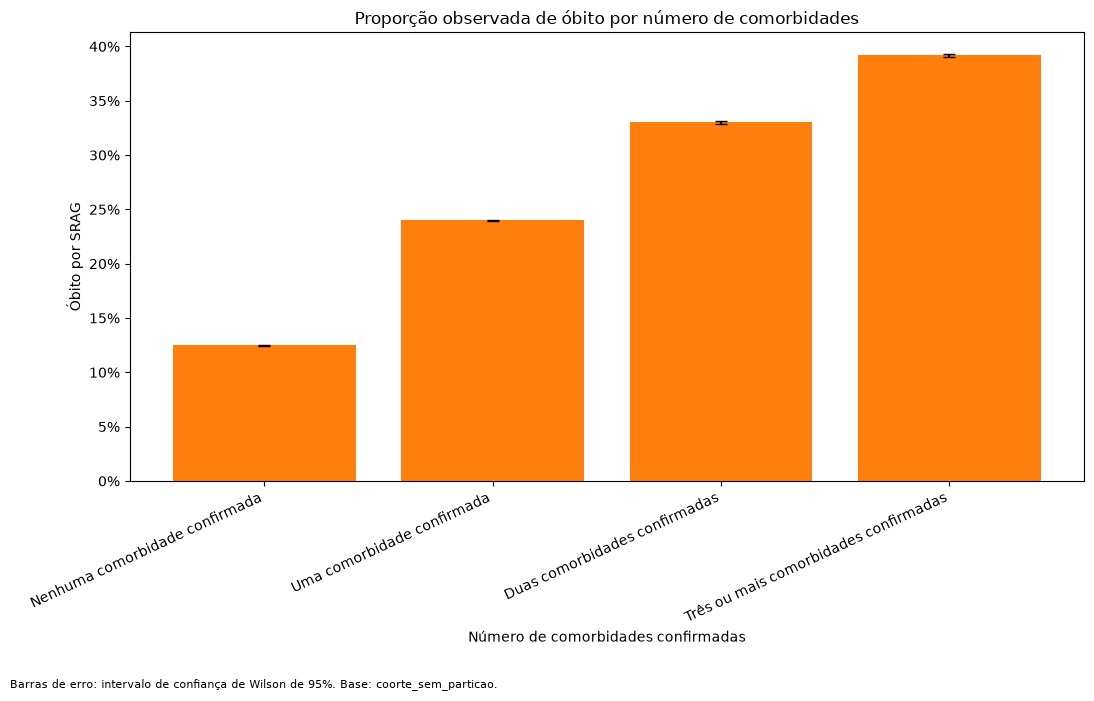

Figura salva em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\eda_02_obito_numero_comorbidades.png


In [72]:
dados_comorbidades_grafico = (
    obito_numero_comorbidades.loc[
        obito_numero_comorbidades[
            "quantidade_total"
        ].gt(0)
    ]
    .copy()
)

categorias_comorbidades = (
    dados_comorbidades_grafico[
        "grupo_numero_comorbidades"
    ]
    .astype("string")
    .tolist()
)

percentuais_comorbidades = (
    dados_comorbidades_grafico[
        "percentual_obito_srag"
    ]
    .astype(float)
    .to_numpy()
)

erros_inferiores_comorbidades = (
    dados_comorbidades_grafico[
        "percentual_obito_srag"
    ]
    .sub(
        dados_comorbidades_grafico[
            "ic95_inferior"
        ]
    )
    .astype(float)
    .to_numpy()
)

erros_superiores_comorbidades = (
    dados_comorbidades_grafico[
        "ic95_superior"
    ]
    .sub(
        dados_comorbidades_grafico[
            "percentual_obito_srag"
        ]
    )
    .astype(float)
    .to_numpy()
)

posicoes_comorbidades = np.arange(
    len(
        dados_comorbidades_grafico
    )
)

figura_obito_comorbidades, eixo_obito_comorbidades = plt.subplots(
    figsize=(
        11,
        7,
    )
)

eixo_obito_comorbidades.bar(
    posicoes_comorbidades,
    percentuais_comorbidades,
    color="tab:orange",
)

eixo_obito_comorbidades.errorbar(
    posicoes_comorbidades,
    percentuais_comorbidades,
    yerr=[
        erros_inferiores_comorbidades,
        erros_superiores_comorbidades,
    ],
    fmt="none",
    ecolor="black",
    capsize=4,
)

eixo_obito_comorbidades.set_title(
    "Proporção observada de óbito por número de comorbidades"
)

eixo_obito_comorbidades.set_xlabel(
    "Número de comorbidades confirmadas"
)

eixo_obito_comorbidades.set_ylabel(
    "Óbito por SRAG"
)

eixo_obito_comorbidades.set_xticks(
    posicoes_comorbidades
)

eixo_obito_comorbidades.set_xticklabels(
    categorias_comorbidades,
    rotation=25,
    ha="right",
)

eixo_obito_comorbidades.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

figura_obito_comorbidades.text(
    0.01,
    0.01,
    (
        "Barras de erro: intervalo de confiança de Wilson de 95%. "
        f"Base: {origem_analise_desfecho}."
    ),
    fontsize=8,
)

figura_obito_comorbidades.tight_layout(
    rect=[
        0,
        0.05,
        1,
        1,
    ]
)

figura_obito_comorbidades.savefig(
    CAMINHO_FIGURA_OBITO_COMORBIDADES,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figura salva em:",
    CAMINHO_FIGURA_OBITO_COMORBIDADES,
)

In [73]:
def criar_grafico_odds_ratio(
    tabela: pd.DataFrame,
    titulo: str,
    caminho_saida: Path,
) -> None:
    """
    Cria um gráfico de razão de chances bruta com IC de 95%.
    """

    dados_grafico = (
        tabela.dropna(
            subset=[
                "odds_ratio_bruta",
                "ic95_or_inferior",
                "ic95_or_superior",
            ]
        )
        .copy()
    )

    dados_grafico = (
        dados_grafico.loc[
            dados_grafico[
                "odds_ratio_bruta"
            ].gt(0)
            & dados_grafico[
                "ic95_or_inferior"
            ].gt(0)
            & dados_grafico[
                "ic95_or_superior"
            ].gt(0)
        ]
        .sort_values(
            "odds_ratio_bruta"
        )
        .reset_index(drop=True)
    )

    if dados_grafico.empty:
        raise ValueError(
            "Não existem razões de chances válidas "
            "para gerar o gráfico."
        )

    posicoes = np.arange(
        len(
            dados_grafico
        )
    )

    valores_or = (
        dados_grafico[
            "odds_ratio_bruta"
        ]
        .astype(float)
        .to_numpy()
    )

    erro_inferior = (
        dados_grafico[
            "odds_ratio_bruta"
        ]
        .sub(
            dados_grafico[
                "ic95_or_inferior"
            ]
        )
        .astype(float)
        .to_numpy()
    )

    erro_superior = (
        dados_grafico[
            "ic95_or_superior"
        ]
        .sub(
            dados_grafico[
                "odds_ratio_bruta"
            ]
        )
        .astype(float)
        .to_numpy()
    )

    rotulos = (
        dados_grafico[
            "nome_amigavel"
        ]
        .astype("string")
        .tolist()
    )

    figura, eixo = plt.subplots(
        figsize=(
            12,
            8,
        )
    )

    eixo.errorbar(
        valores_or,
        posicoes,
        xerr=[
            erro_inferior,
            erro_superior,
        ],
        fmt="o",
        color="tab:blue",
        ecolor="black",
        capsize=4,
    )

    eixo.axvline(
        x=1,
        color="tab:red",
        linestyle="--",
        linewidth=1.5,
    )

    eixo.set_xscale(
        "log"
    )

    eixo.set_yticks(
        posicoes
    )

    eixo.set_yticklabels(
        rotulos
    )

    eixo.set_title(
        titulo
    )

    eixo.set_xlabel(
        "Razão de chances bruta, escala logarítmica"
    )

    eixo.set_ylabel(
        "Indicador"
    )

    figura.text(
        0.01,
        0.01,
        (
            "Comparação: resposta sim versus resposta não. "
            "Intervalo de confiança de 95%. "
            "Associação bruta, não ajustada e não causal."
        ),
        fontsize=8,
    )

    figura.tight_layout(
        rect=[
            0,
            0.05,
            1,
            1,
        ]
    )

    figura.savefig(
        caminho_saida,
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

    print(
        "Figura salva em:",
        caminho_saida,
    )

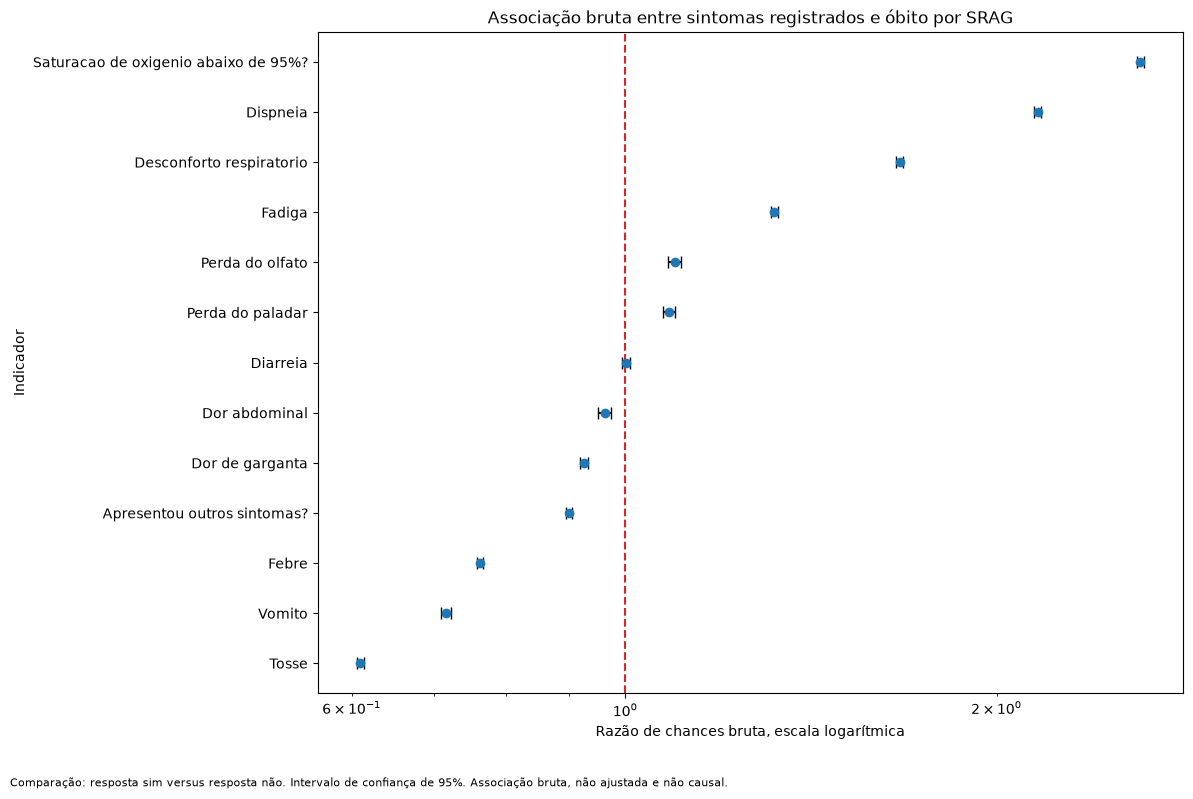

Figura salva em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\eda_02_odds_ratio_sintomas.png


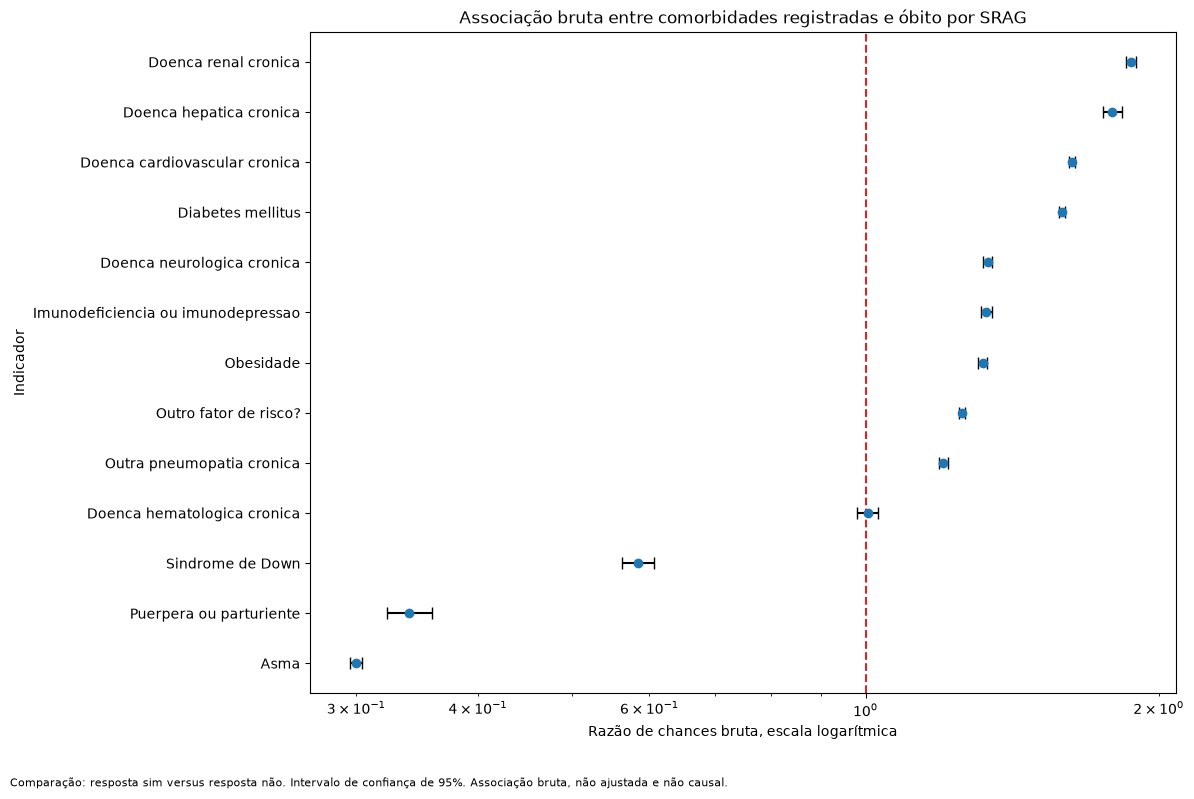

Figura salva em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\eda_02_odds_ratio_comorbidades.png


In [74]:
criar_grafico_odds_ratio(
    tabela=obito_sintomas,
    titulo=(
        "Associação bruta entre sintomas registrados "
        "e óbito por SRAG"
    ),
    caminho_saida=(
        CAMINHO_FIGURA_OR_SINTOMAS
    ),
)

criar_grafico_odds_ratio(
    tabela=obito_comorbidades,
    titulo=(
        "Associação bruta entre comorbidades registradas "
        "e óbito por SRAG"
    ),
    caminho_saida=(
        CAMINHO_FIGURA_OR_COMORBIDADES
    ),
)

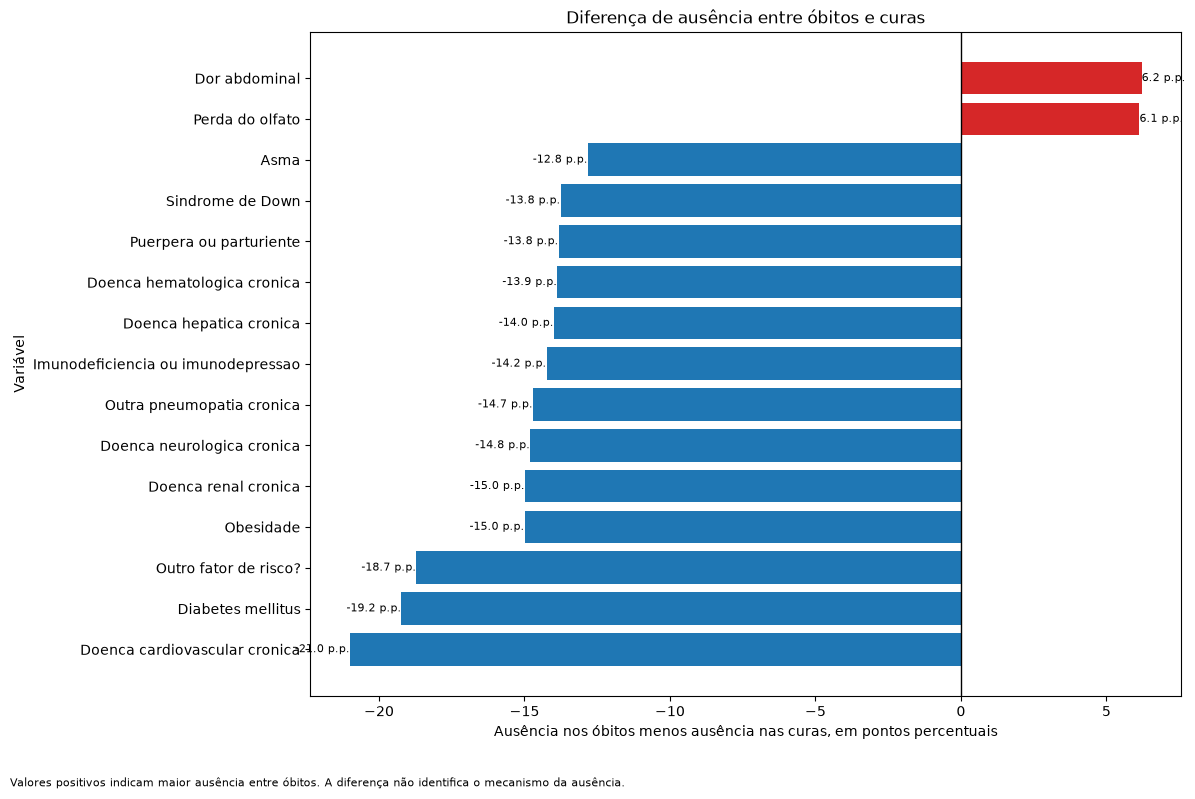

Figura salva em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\eda_02_ausencia_por_desfecho.png


In [75]:
QUANTIDADE_VARIAVEIS_AUSENCIA_GRAFICO = 15

ausencia_grafico = (
    ausencia_por_desfecho.head(
        QUANTIDADE_VARIAVEIS_AUSENCIA_GRAFICO
    )
    .sort_values(
        "diferenca_pp_obito_menos_cura"
    )
    .copy()
)

figura_ausencia, eixo_ausencia = plt.subplots(
    figsize=(
        12,
        8,
    )
)

cores_ausencia = [
    (
        "tab:red"
        if diferenca > 0
        else "tab:blue"
    )
    for diferenca in ausencia_grafico[
        "diferenca_pp_obito_menos_cura"
    ]
]

barras_ausencia = eixo_ausencia.barh(
    ausencia_grafico[
        "nome_amigavel"
    ],
    ausencia_grafico[
        "diferenca_pp_obito_menos_cura"
    ],
    color=cores_ausencia,
)

eixo_ausencia.axvline(
    x=0,
    color="black",
    linewidth=1,
)

eixo_ausencia.set_title(
    "Diferença de ausência entre óbitos e curas"
)

eixo_ausencia.set_xlabel(
    "Ausência nos óbitos menos ausência nas curas, em pontos percentuais"
)

eixo_ausencia.set_ylabel(
    "Variável"
)

for barra, diferenca in zip(
    barras_ausencia,
    ausencia_grafico[
        "diferenca_pp_obito_menos_cura"
    ],
):
    alinhamento = (
        "left"
        if diferenca >= 0
        else "right"
    )

    eixo_ausencia.text(
        diferenca,
        barra.get_y()
        + barra.get_height()
        / 2,
        f"{diferenca:.1f} p.p.",
        va="center",
        ha=alinhamento,
        fontsize=8,
    )

figura_ausencia.text(
    0.01,
    0.01,
    (
        "Valores positivos indicam maior ausência entre óbitos. "
        "A diferença não identifica o mecanismo da ausência."
    ),
    fontsize=8,
)

figura_ausencia.tight_layout(
    rect=[
        0,
        0.05,
        1,
        1,
    ]
)

figura_ausencia.savefig(
    CAMINHO_FIGURA_AUSENCIA_DESFECHO,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figura salva em:",
    CAMINHO_FIGURA_AUSENCIA_DESFECHO,
)

In [76]:
quantidade_base_desfecho = len(
    base_analise_desfecho
)

quantidade_obitos_desfecho = int(
    base_analise_desfecho[
        "alvo_obito_srag"
    ]
    .sum()
)

quantidade_curas_desfecho = (
    quantidade_base_desfecho
    - quantidade_obitos_desfecho
)

percentual_obito_global = (
    quantidade_obitos_desfecho
    / quantidade_base_desfecho
    * 100
)

ic_global_obito = calcular_ic_wilson(
    quantidade_eventos=(
        quantidade_obitos_desfecho
    ),
    quantidade_total=(
        quantidade_base_desfecho
    ),
)

resumo_analise_desfecho = pd.DataFrame(
    {
        "metrica": [
            "origem_analise",
            "quantidade_registros",
            "quantidade_curas",
            "quantidade_obitos_srag",
            "percentual_obito_srag",
            "ic95_obito_inferior",
            "ic95_obito_superior",
            "quantidade_sintomas_analisados",
            "quantidade_comorbidades_analisadas",
            "quantidade_variaveis_ausencia",
        ],
        "valor": [
            origem_analise_desfecho,
            quantidade_base_desfecho,
            quantidade_curas_desfecho,
            quantidade_obitos_desfecho,
            percentual_obito_global,
            ic_global_obito[0],
            ic_global_obito[1],
            len(
                obito_sintomas
            ),
            len(
                obito_comorbidades
            ),
            len(
                ausencia_por_desfecho
            ),
        ],
    }
)

display(
    resumo_analise_desfecho
)

,metrica,valor
0,origem_analise,coorte_sem_particao
1,quantidade_registros,3884728
2,quantidade_curas,3037008
3,quantidade_obitos_srag,847720
4,percentual_obito_srag,21.821862
5,ic95_obito_inferior,21.780817
6,ic95_obito_superior,21.862963
7,quantidade_sintomas_analisados,13
8,quantidade_comorbidades_analisadas,13
9,quantidade_variaveis_ausencia,26


In [77]:
obito_faixa_etaria.to_csv(
    CAMINHO_OBITO_FAIXA_ETARIA,
    index=False,
    encoding="utf-8-sig",
)

obito_numero_comorbidades.to_csv(
    CAMINHO_OBITO_NUMERO_COMORBIDADES,
    index=False,
    encoding="utf-8-sig",
)

obito_sintomas.to_csv(
    CAMINHO_OBITO_SINTOMAS,
    index=False,
    encoding="utf-8-sig",
)

obito_comorbidades.to_csv(
    CAMINHO_OBITO_COMORBIDADES,
    index=False,
    encoding="utf-8-sig",
)

ausencia_por_desfecho.to_csv(
    CAMINHO_AUSENCIA_DESFECHO,
    index=False,
    encoding="utf-8-sig",
)

resumo_analise_desfecho.to_csv(
    CAMINHO_RESUMO_DESFECHO,
    index=False,
    encoding="utf-8-sig",
)

percentuais_faixa_validos = (
    obito_faixa_etaria[
        "percentual_obito_srag"
    ]
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

percentuais_comorbidades_validos = (
    obito_numero_comorbidades[
        "percentual_obito_srag"
    ]
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

odds_ratios_sintomas_validas = (
    obito_sintomas[
        "odds_ratio_bruta"
    ]
    .dropna()
    .gt(0)
    .all()
)

odds_ratios_comorbidades_validas = (
    obito_comorbidades[
        "odds_ratio_bruta"
    ]
    .dropna()
    .gt(0)
    .all()
)

verificacoes_desfecho = {
    "base_desfecho_nao_vazia": (
        not base_analise_desfecho.empty
    ),
    "cura_presente": (
        quantidade_curas_desfecho > 0
    ),
    "obito_presente": (
        quantidade_obitos_desfecho > 0
    ),
    "tabela_faixa_etaria_nao_vazia": (
        not obito_faixa_etaria.empty
    ),
    "tabela_numero_comorbidades_nao_vazia": (
        not obito_numero_comorbidades.empty
    ),
    "tabela_sintomas_nao_vazia": (
        not obito_sintomas.empty
    ),
    "tabela_comorbidades_nao_vazia": (
        not obito_comorbidades.empty
    ),
    "tabela_ausencia_nao_vazia": (
        not ausencia_por_desfecho.empty
    ),
    "percentuais_faixa_validos": (
        percentuais_faixa_validos
    ),
    "percentuais_comorbidades_validos": (
        percentuais_comorbidades_validos
    ),
    "odds_ratios_sintomas_positivas": (
        odds_ratios_sintomas_validas
    ),
    "odds_ratios_comorbidades_positivas": (
        odds_ratios_comorbidades_validas
    ),
    "arquivo_faixa_etaria_criado": (
        CAMINHO_OBITO_FAIXA_ETARIA.exists()
    ),
    "arquivo_numero_comorbidades_criado": (
        CAMINHO_OBITO_NUMERO_COMORBIDADES.exists()
    ),
    "arquivo_sintomas_criado": (
        CAMINHO_OBITO_SINTOMAS.exists()
    ),
    "arquivo_comorbidades_criado": (
        CAMINHO_OBITO_COMORBIDADES.exists()
    ),
    "arquivo_ausencia_criado": (
        CAMINHO_AUSENCIA_DESFECHO.exists()
    ),
    "arquivo_resumo_criado": (
        CAMINHO_RESUMO_DESFECHO.exists()
    ),
    "figura_faixa_etaria_criada": (
        CAMINHO_FIGURA_OBITO_FAIXA_ETARIA.exists()
    ),
    "figura_numero_comorbidades_criada": (
        CAMINHO_FIGURA_OBITO_COMORBIDADES.exists()
    ),
    "figura_or_sintomas_criada": (
        CAMINHO_FIGURA_OR_SINTOMAS.exists()
    ),
    "figura_or_comorbidades_criada": (
        CAMINHO_FIGURA_OR_COMORBIDADES.exists()
    ),
    "figura_ausencia_criada": (
        CAMINHO_FIGURA_AUSENCIA_DESFECHO.exists()
    ),
}

verificacoes_desfecho_df = pd.DataFrame(
    {
        "verificacao": list(
            verificacoes_desfecho.keys()
        ),
        "resultado": list(
            verificacoes_desfecho.values()
        ),
    }
)

display(
    verificacoes_desfecho_df
)

if not all(
    verificacoes_desfecho.values()
):
    falhas_desfecho = [
        verificacao
        for verificacao, resultado
        in verificacoes_desfecho.items()
        if not resultado
    ]

    raise RuntimeError(
        "A análise do desfecho terminou com falhas: "
        f"{falhas_desfecho}"
    )

print(
    "Análise de óbito validada com sucesso."
)

,verificacao,resultado
0,base_desfecho_nao_vazia,True
1,cura_presente,True
2,obito_presente,True
3,tabela_faixa_etaria_nao_vazia,True
4,tabela_numero_comorbidades_nao_vazia,True
5,tabela_sintomas_nao_vazia,True
6,tabela_comorbidades_nao_vazia,True
7,tabela_ausencia_nao_vazia,True
8,percentuais_faixa_validos,True
9,percentuais_comorbidades_validos,True


Análise de óbito validada com sucesso.


## 8. Painéis visuais dos indicadores clínicos

Esta seção consolida visualmente os padrões anuais de sintomas e
comorbidades.

Os primeiros painéis mostram a proporção de resposta afirmativa entre
registros com resposta válida, definida como sim ou não.

Os painéis seguintes mostram o percentual sem resposta válida, reunindo:

- ausente;
- ignorado;
- código inesperado.

A leitura conjunta dos dois tipos de gráfico é importante. Uma mudança
na proporção registrada de uma condição pode refletir tanto mudança na
população quanto mudança na cobertura do preenchimento.

In [78]:
import seaborn as sns


def preparar_matriz_clinica_heatmap(
    tabela_clinica: pd.DataFrame,
    coluna_valor: str,
) -> tuple:
    """
    Transforma a tabela clínica longa em uma matriz variável por ano.

    Retorna a matriz numérica e os rótulos amigáveis das linhas.
    """

    COLUNAS_NECESSARIAS = [
        "ano_internacao",
        "coluna",
        "nome_amigavel",
        coluna_valor,
    ]

    colunas_ausentes = [
        coluna
        for coluna in COLUNAS_NECESSARIAS
        if coluna not in tabela_clinica.columns
    ]

    if colunas_ausentes:
        raise KeyError(
            "A tabela clínica não contém as colunas necessárias: "
            f"{colunas_ausentes}"
        )

    dados_heatmap = (
        tabela_clinica[
            COLUNAS_NECESSARIAS
        ]
        .copy()
    )

    dados_heatmap[
        coluna_valor
    ] = pd.to_numeric(
        dados_heatmap[
            coluna_valor
        ],
        errors="coerce",
    )

    matriz_heatmap = (
        dados_heatmap.pivot(
            index="coluna",
            columns="ano_internacao",
            values=coluna_valor,
        )
        .sort_index(
            axis=1
        )
    )

    nomes_amigaveis_heatmap = (
        dados_heatmap[
            [
                "coluna",
                "nome_amigavel",
            ]
        ]
        .drop_duplicates(
            subset=[
                "coluna",
            ]
        )
        .set_index(
            "coluna"
        )[
            "nome_amigavel"
        ]
        .astype("string")
    )

    rotulos_linhas = []

    for coluna in matriz_heatmap.index:
        nome_amigavel = nomes_amigaveis_heatmap.get(
            coluna,
            coluna,
        )

        if pd.isna(
            nome_amigavel
        ):
            nome_amigavel = coluna

        nome_amigavel = str(
            nome_amigavel
        ).strip()

        if not nome_amigavel:
            nome_amigavel = coluna

        if nome_amigavel.lower() == coluna.lower():
            rotulo = nome_amigavel
        else:
            rotulo = (
                f"{nome_amigavel} ({coluna})"
            )

        rotulos_linhas.append(
            rotulo
        )

    matriz_heatmap.index = (
        rotulos_linhas
    )

    matriz_heatmap.columns = [
        int(
            ano
        )
        for ano in matriz_heatmap.columns
    ]

    return (
        matriz_heatmap,
        rotulos_linhas,
    )


def exibir_heatmap_percentual(
    matriz: pd.DataFrame,
    titulo: str,
    rotulo_escala: str,
    mapa_cores: str,
) -> None:
    """
    Exibe um heatmap percentual diretamente no notebook.
    """

    if matriz.empty:
        raise ValueError(
            "A matriz recebida para o heatmap está vazia."
        )

    valores_validos = (
        matriz.stack(
            future_stack=True
        )
        .dropna()
    )

    if valores_validos.empty:
        raise ValueError(
            "A matriz do heatmap não contém valores numéricos."
        )

    if not valores_validos.between(
        0,
        100,
        inclusive="both",
    ).all():
        raise ValueError(
            "O heatmap percentual contém valores "
            "fora do intervalo de zero a cem."
        )

    altura_figura = max(
        5,
        len(
            matriz
        )
        * 0.48,
    )

    figura, eixo = plt.subplots(
        figsize=(
            12,
            altura_figura,
        )
    )

    sns.heatmap(
        matriz,
        annot=True,
        fmt=".1f",
        cmap=mapa_cores,
        vmin=0,
        vmax=100,
        linewidths=0.5,
        linecolor="white",
        cbar_kws={
            "label": rotulo_escala,
        },
        annot_kws={
            "fontsize": 8,
        },
        ax=eixo,
    )

    eixo.set_title(
        titulo
    )

    eixo.set_xlabel(
        "Ano da internação"
    )

    eixo.set_ylabel(
        "Indicador"
    )

    eixo.set_xticklabels(
        eixo.get_xticklabels(),
        rotation=0,
    )

    eixo.set_yticklabels(
        eixo.get_yticklabels(),
        rotation=0,
    )

    figura.tight_layout()

    plt.show()

    plt.close(
        figura
    )

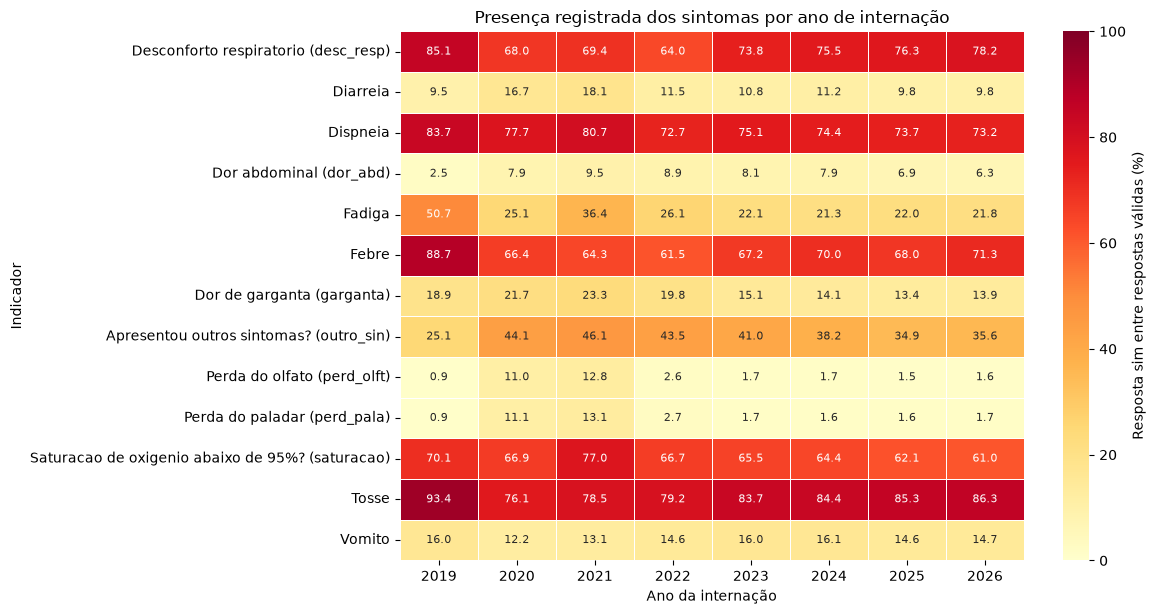

In [79]:
matriz_sintomas_presenca, rotulos_sintomas = (
    preparar_matriz_clinica_heatmap(
        tabela_clinica=sintomas_por_ano,
        coluna_valor="percentual_sim_validos",
    )
)

exibir_heatmap_percentual(
    matriz=matriz_sintomas_presenca,
    titulo=(
        "Presença registrada dos sintomas por ano de internação"
    ),
    rotulo_escala=(
        "Resposta sim entre respostas válidas (%)"
    ),
    mapa_cores="YlOrRd",
)

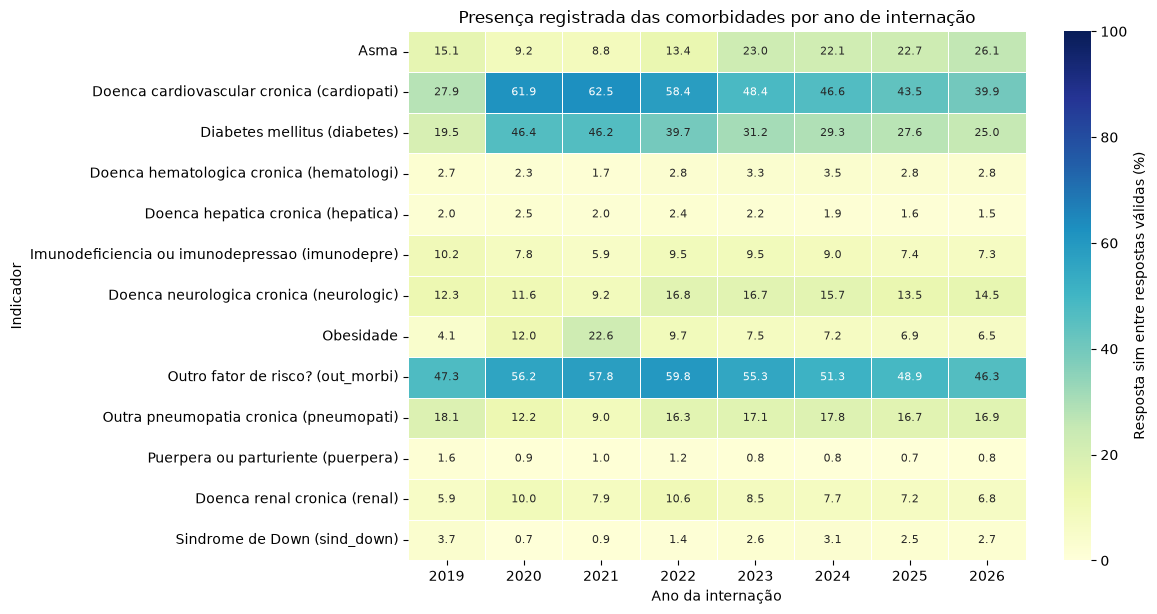

In [80]:
matriz_comorbidades_presenca, rotulos_comorbidades = (
    preparar_matriz_clinica_heatmap(
        tabela_clinica=comorbidades_por_ano,
        coluna_valor="percentual_sim_validos",
    )
)

exibir_heatmap_percentual(
    matriz=matriz_comorbidades_presenca,
    titulo=(
        "Presença registrada das comorbidades por ano de internação"
    ),
    rotulo_escala=(
        "Resposta sim entre respostas válidas (%)"
    ),
    mapa_cores="YlGnBu",
)

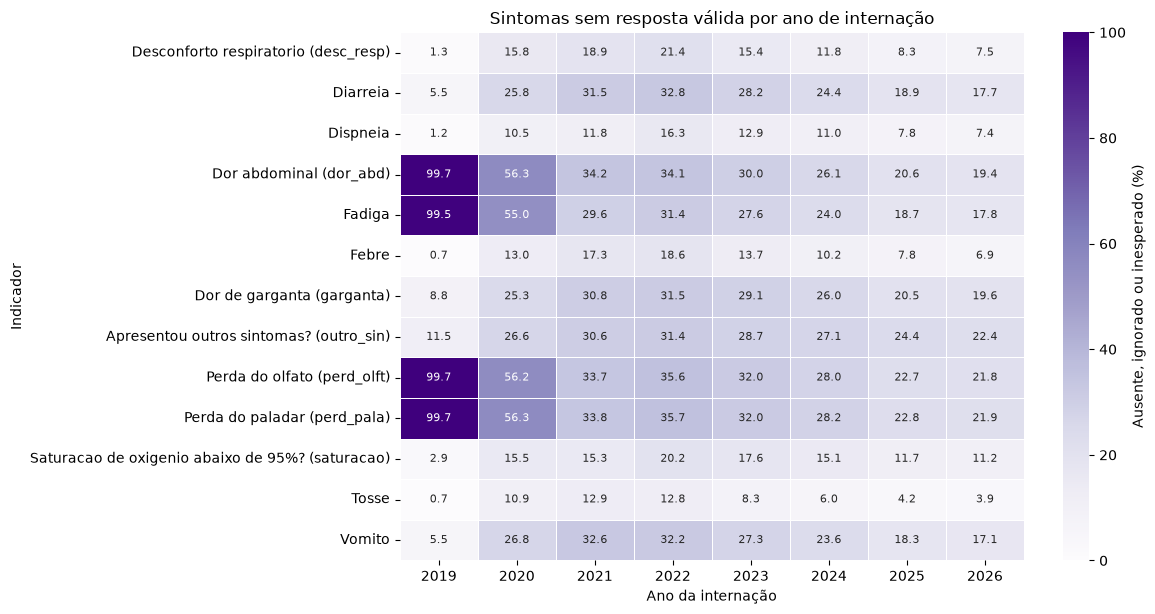

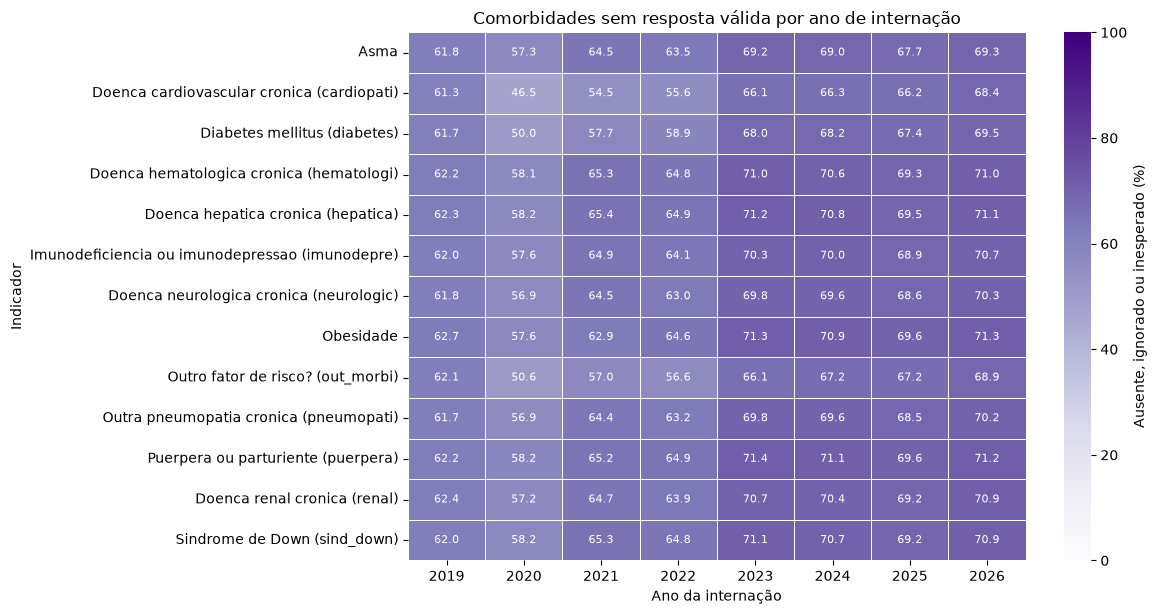

In [81]:
matriz_sintomas_sem_resposta, rotulos_sintomas_sem_resposta = (
    preparar_matriz_clinica_heatmap(
        tabela_clinica=sintomas_por_ano,
        coluna_valor=(
            "percentual_sem_resposta_valida"
        ),
    )
)

matriz_comorbidades_sem_resposta, rotulos_comorbidades_sem_resposta = (
    preparar_matriz_clinica_heatmap(
        tabela_clinica=comorbidades_por_ano,
        coluna_valor=(
            "percentual_sem_resposta_valida"
        ),
    )
)

exibir_heatmap_percentual(
    matriz=matriz_sintomas_sem_resposta,
    titulo=(
        "Sintomas sem resposta válida por ano de internação"
    ),
    rotulo_escala=(
        "Ausente, ignorado ou inesperado (%)"
    ),
    mapa_cores="Purples",
)

exibir_heatmap_percentual(
    matriz=matriz_comorbidades_sem_resposta,
    titulo=(
        "Comorbidades sem resposta válida por ano de internação"
    ),
    rotulo_escala=(
        "Ausente, ignorado ou inesperado (%)"
    ),
    mapa_cores="Purples",
)

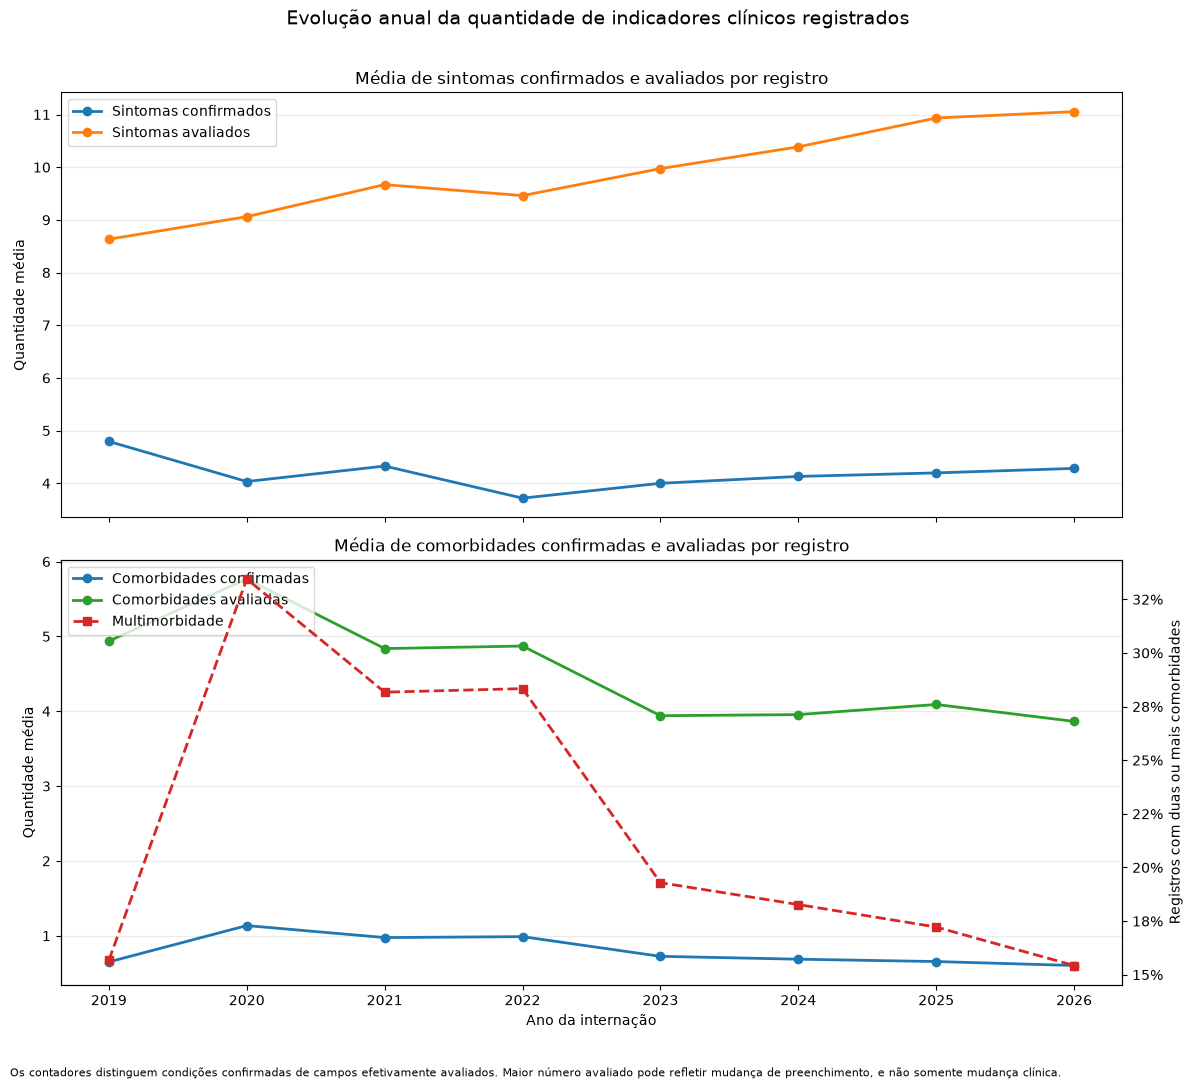

In [82]:
COLUNAS_CONTADORES_GRAFICO = [
    "ano_internacao",
    "sintomas_confirmados_media",
    "sintomas_avaliados_media",
    "comorbidades_confirmadas_media",
    "comorbidades_avaliadas_media",
    "percentual_multimorbidade",
]

colunas_contadores_ausentes = [
    coluna
    for coluna in COLUNAS_CONTADORES_GRAFICO
    if coluna not in contadores_clinicos_por_ano.columns
]

if colunas_contadores_ausentes:
    raise KeyError(
        "A tabela de contadores clínicos não contém: "
        f"{colunas_contadores_ausentes}"
    )

dados_contadores_grafico = (
    contadores_clinicos_por_ano[
        COLUNAS_CONTADORES_GRAFICO
    ]
    .sort_values(
        "ano_internacao"
    )
    .copy()
)

anos_contadores = (
    dados_contadores_grafico[
        "ano_internacao"
    ]
    .astype(int)
    .to_numpy()
)

figura_contadores, eixos_contadores = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(
        12,
        11,
    ),
    sharex=True,
)

eixo_sintomas = (
    eixos_contadores[0]
)

eixo_sintomas.plot(
    anos_contadores,
    dados_contadores_grafico[
        "sintomas_confirmados_media"
    ],
    marker="o",
    linewidth=2,
    label="Sintomas confirmados",
)

eixo_sintomas.plot(
    anos_contadores,
    dados_contadores_grafico[
        "sintomas_avaliados_media"
    ],
    marker="o",
    linewidth=2,
    label="Sintomas avaliados",
)

eixo_sintomas.set_title(
    "Média de sintomas confirmados e avaliados por registro"
)

eixo_sintomas.set_ylabel(
    "Quantidade média"
)

eixo_sintomas.legend()

eixo_sintomas.grid(
    axis="y",
    alpha=0.25,
)

eixo_comorbidades = (
    eixos_contadores[1]
)

eixo_comorbidades.plot(
    anos_contadores,
    dados_contadores_grafico[
        "comorbidades_confirmadas_media"
    ],
    marker="o",
    linewidth=2,
    color="tab:blue",
    label="Comorbidades confirmadas",
)

eixo_comorbidades.plot(
    anos_contadores,
    dados_contadores_grafico[
        "comorbidades_avaliadas_media"
    ],
    marker="o",
    linewidth=2,
    color="tab:green",
    label="Comorbidades avaliadas",
)

eixo_comorbidades.set_title(
    "Média de comorbidades confirmadas e avaliadas por registro"
)

eixo_comorbidades.set_xlabel(
    "Ano da internação"
)

eixo_comorbidades.set_ylabel(
    "Quantidade média"
)

eixo_comorbidades.set_xticks(
    anos_contadores
)

eixo_comorbidades.legend(
    loc="upper left"
)

eixo_comorbidades.grid(
    axis="y",
    alpha=0.25,
)

eixo_multimorbidade = (
    eixo_comorbidades.twinx()
)

eixo_multimorbidade.plot(
    anos_contadores,
    dados_contadores_grafico[
        "percentual_multimorbidade"
    ],
    marker="s",
    linewidth=2,
    linestyle="--",
    color="tab:red",
    label="Multimorbidade",
)

eixo_multimorbidade.set_ylabel(
    "Registros com duas ou mais comorbidades"
)

eixo_multimorbidade.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

linhas_comorbidades, rotulos_comorbidades_grafico = (
    eixo_comorbidades.get_legend_handles_labels()
)

linhas_multimorbidade, rotulos_multimorbidade = (
    eixo_multimorbidade.get_legend_handles_labels()
)

eixo_comorbidades.legend(
    linhas_comorbidades
    + linhas_multimorbidade,
    rotulos_comorbidades_grafico
    + rotulos_multimorbidade,
    loc="upper left",
)

figura_contadores.suptitle(
    "Evolução anual da quantidade de indicadores clínicos registrados",
    fontsize=14,
)

figura_contadores.text(
    0.01,
    0.01,
    (
        "Os contadores distinguem condições confirmadas de campos "
        "efetivamente avaliados. Maior número avaliado pode refletir "
        "mudança de preenchimento, e não somente mudança clínica."
    ),
    fontsize=8,
)

figura_contadores.tight_layout(
    rect=[
        0,
        0.04,
        1,
        0.97,
    ]
)

plt.show()

plt.close(
    figura_contadores
)

In [83]:
verificacoes_paineis_clinicos = {
    "matriz_sintomas_presenca_nao_vazia": (
        not matriz_sintomas_presenca.empty
    ),
    "matriz_comorbidades_presenca_nao_vazia": (
        not matriz_comorbidades_presenca.empty
    ),
    "matriz_sintomas_sem_resposta_nao_vazia": (
        not matriz_sintomas_sem_resposta.empty
    ),
    "matriz_comorbidades_sem_resposta_nao_vazia": (
        not matriz_comorbidades_sem_resposta.empty
    ),
    "todos_sintomas_representados": (
        matriz_sintomas_presenca.shape[0]
        == len(
            COLUNAS_SINTOMAS
        )
    ),
    "todas_comorbidades_representadas": (
        matriz_comorbidades_presenca.shape[0]
        == len(
            COLUNAS_COMORBIDADES
        )
    ),
    "todos_anos_sintomas_representados": (
        matriz_sintomas_presenca.shape[1]
        == coorte[
            "ano_internacao"
        ]
        .nunique(
            dropna=True
        )
    ),
    "todos_anos_comorbidades_representados": (
        matriz_comorbidades_presenca.shape[1]
        == coorte[
            "ano_internacao"
        ]
        .nunique(
            dropna=True
        )
    ),
    "contadores_clinicos_nao_vazios": (
        not dados_contadores_grafico.empty
    ),
}

verificacoes_paineis_clinicos_df = pd.DataFrame(
    {
        "verificacao": list(
            verificacoes_paineis_clinicos.keys()
        ),
        "resultado": list(
            verificacoes_paineis_clinicos.values()
        ),
    }
)

display(
    verificacoes_paineis_clinicos_df
)

if not all(
    verificacoes_paineis_clinicos.values()
):
    falhas_paineis_clinicos = [
        verificacao
        for verificacao, resultado
        in verificacoes_paineis_clinicos.items()
        if not resultado
    ]

    raise RuntimeError(
        "Os painéis clínicos terminaram com falhas: "
        f"{falhas_paineis_clinicos}"
    )

print(
    "Painéis clínicos exibidos e validados com sucesso."
)

,verificacao,resultado
0,matriz_sintomas_presenca_nao_vazia,True
1,matriz_comorbidades_presenca_nao_vazia,True
2,matriz_sintomas_sem_resposta_nao_vazia,True
3,matriz_comorbidades_sem_resposta_nao_vazia,True
4,todos_sintomas_representados,True
5,todas_comorbidades_representadas,True
6,todos_anos_sintomas_representados,True
7,todos_anos_comorbidades_representados,True
8,contadores_clinicos_nao_vazios,True


Painéis clínicos exibidos e validados com sucesso.


## 9. Painéis visuais do desfecho

Esta seção complementa a análise global de óbito por SRAG com
visualizações estratificadas por ano e por características registradas
na admissão.

Serão apresentados:

- óbito por faixa etária e ano;
- óbito por número de comorbidades e ano;
- comparação entre a presença e a ausência de sintomas;
- comparação entre a presença e a ausência de comorbidades;
- composição do sexo registrado por ano;
- óbito por sexo registrado, globalmente e por ano.

Os percentuais de óbito utilizam somente os registros elegíveis para o
alvo principal.

As comparações são descritivas e não representam efeitos causais ou
associações ajustadas.

In [84]:
def criar_tabela_obito_categoria_ano(
    dataframe: pd.DataFrame,
    coluna_categoria: str,
    nome_categoria_saida: str,
) -> pd.DataFrame:
    """
    Calcula quantidade, proporção de óbito e intervalo de confiança
    de Wilson por categoria e ano de internação.

    O percentual é calculado como:

        quantidade de óbitos
        -------------------- × 100
        quantidade total
    """

    COLUNAS_NECESSARIAS = [
        "ano_internacao",
        "alvo_obito_srag",
        coluna_categoria,
    ]

    colunas_ausentes = [
        coluna
        for coluna in COLUNAS_NECESSARIAS
        if coluna not in dataframe.columns
    ]

    if colunas_ausentes:
        raise KeyError(
            "A base não contém as colunas necessárias: "
            f"{colunas_ausentes}"
        )

    tabela = (
        dataframe.groupby(
            [
                "ano_internacao",
                coluna_categoria,
            ],
            dropna=False,
        )
        .agg(
            quantidade_total=(
                "alvo_obito_srag",
                "size",
            ),
            quantidade_obito_srag=(
                "alvo_obito_srag",
                "sum",
            ),
        )
        .reset_index()
        .rename(
            columns={
                coluna_categoria: (
                    nome_categoria_saida
                ),
            }
        )
    )

    tabela[
        "quantidade_cura"
    ] = (
        tabela[
            "quantidade_total"
        ]
        .sub(
            tabela[
                "quantidade_obito_srag"
            ]
        )
    )

    tabela[
        "percentual_obito_srag"
    ] = (
        tabela[
            "quantidade_obito_srag"
        ]
        .div(
            tabela[
                "quantidade_total"
            ]
            .replace(
                0,
                np.nan,
            )
        )
        .mul(100)
    )

    intervalos = []

    for _, linha in tabela.iterrows():
        intervalo = calcular_ic_wilson(
            quantidade_eventos=int(
                linha[
                    "quantidade_obito_srag"
                ]
            ),
            quantidade_total=int(
                linha[
                    "quantidade_total"
                ]
            ),
        )

        intervalos.append(
            intervalo
        )

    tabela[
        "ic95_inferior"
    ] = [
        intervalo[0]
        for intervalo in intervalos
    ]

    tabela[
        "ic95_superior"
    ] = [
        intervalo[1]
        for intervalo in intervalos
    ]

    tabela[
        "ano_internacao"
    ] = (
        tabela[
            "ano_internacao"
        ]
        .astype("Int64")
    )

    tabela[
        "quantidade_total"
    ] = (
        tabela[
            "quantidade_total"
        ]
        .astype("int64")
    )

    tabela[
        "quantidade_obito_srag"
    ] = (
        tabela[
            "quantidade_obito_srag"
        ]
        .astype("int64")
    )

    tabela[
        "quantidade_cura"
    ] = (
        tabela[
            "quantidade_cura"
        ]
        .astype("int64")
    )

    percentuais_validos = (
        tabela[
            "percentual_obito_srag"
        ]
        .dropna()
        .between(
            0,
            100,
            inclusive="both",
        )
        .all()
    )

    if not percentuais_validos:
        raise RuntimeError(
            "Foram produzidos percentuais de óbito "
            "fora do intervalo de 0% a 100%."
        )

    total_tabela = int(
        tabela[
            "quantidade_total"
        ]
        .sum()
    )

    if total_tabela != len(
        dataframe
    ):
        raise RuntimeError(
            "A soma dos denominadores da tabela por categoria "
            "e ano não corresponde ao total da base analisada."
        )

    tabela = (
        tabela.sort_values(
            [
                "ano_internacao",
                nome_categoria_saida,
            ]
        )
        .reset_index(drop=True)
    )

    return tabela

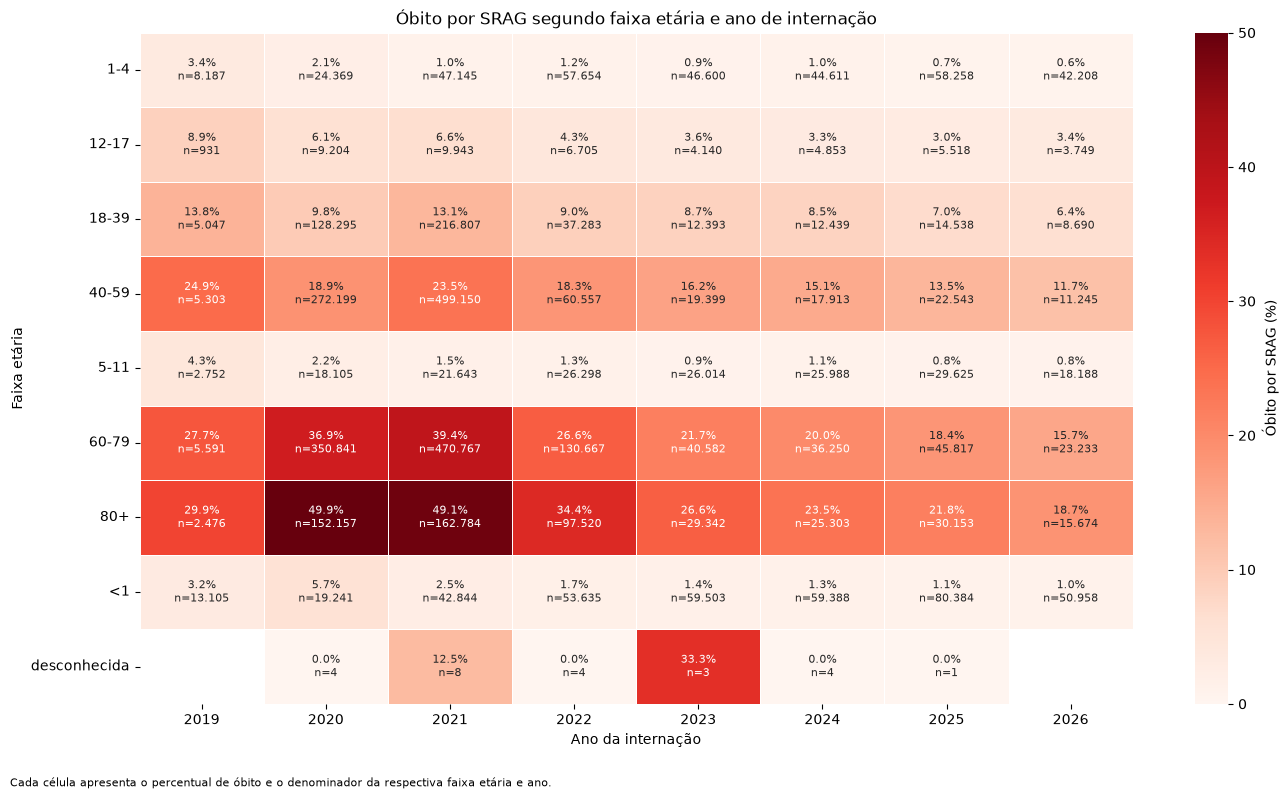

,ano_internacao,faixa_etaria,quantidade_total,quantidade_obito_srag,quantidade_cura,percentual_obito_srag,ic95_inferior,ic95_superior
0,2019,1-4,8187,282,7905,3.444485,3.070773,3.861866
1,2019,12-17,931,83,848,8.915145,7.249490,10.918453
2,2019,18-39,5047,697,4350,13.810184,12.885843,14.789574
3,2019,40-59,5303,1318,3985,24.853856,23.709183,26.034935
4,2019,5-11,2752,119,2633,4.324128,3.625731,5.149863
5,2019,60-79,5591,1546,4045,27.651583,26.494824,28.839031
6,2019,80+,2476,740,1736,29.886914,28.116128,31.720014
7,2019,<1,13105,421,12684,3.212514,2.924059,3.528391
8,2020,1-4,24369,520,23849,2.133859,1.959822,2.322983
9,2020,12-17,9204,563,8641,6.116906,5.645398,6.625029


In [85]:
if "faixa_etaria" not in base_analise_desfecho.columns:
    raise KeyError(
        "A coluna faixa_etaria não está disponível. "
        "Execute primeiro a seção demográfica."
    )

obito_faixa_etaria_ano = (
    criar_tabela_obito_categoria_ano(
        dataframe=base_analise_desfecho,
        coluna_categoria="faixa_etaria",
        nome_categoria_saida="faixa_etaria",
    )
)

ordem_faixas_disponiveis = [
    faixa
    for faixa in ORDEM_FAIXA_OBITO
    if faixa in set(
        obito_faixa_etaria_ano[
            "faixa_etaria"
        ]
        .astype("string")
        .tolist()
    )
]

matriz_obito_faixa_etaria_ano = (
    obito_faixa_etaria_ano.pivot(
        index="faixa_etaria",
        columns="ano_internacao",
        values="percentual_obito_srag",
    )
    .reindex(
        ordem_faixas_disponiveis
    )
    .sort_index(
        axis=1
    )
)

matriz_n_faixa_etaria_ano = (
    obito_faixa_etaria_ano.pivot(
        index="faixa_etaria",
        columns="ano_internacao",
        values="quantidade_total",
    )
    .reindex(
        ordem_faixas_disponiveis
    )
    .reindex(
        columns=(
            matriz_obito_faixa_etaria_ano.columns
        )
    )
)

if matriz_obito_faixa_etaria_ano.empty:
    raise ValueError(
        "A matriz de óbito por faixa etária e ano está vazia."
    )

valores_obito_faixa = (
    matriz_obito_faixa_etaria_ano
    .stack(
        future_stack=True
    )
    .dropna()
)

if valores_obito_faixa.empty:
    raise ValueError(
        "A matriz não contém percentuais de óbito válidos."
    )

if not valores_obito_faixa.between(
    0,
    100,
    inclusive="both",
).all():
    raise RuntimeError(
        "A matriz contém percentuais fora "
        "do intervalo de 0% a 100%."
    )

if valores_obito_faixa.eq(0).all():
    raise RuntimeError(
        "Todos os percentuais de óbito ficaram iguais a zero. "
        "Verifique o cálculo de percentual_obito_srag."
    )

valor_maximo_observado = float(
    valores_obito_faixa.max()
)

limite_superior_escala = max(
    10.0,
    np.ceil(
        valor_maximo_observado
        / 5
    )
    * 5,
)

anotacoes_heatmap = (
    matriz_obito_faixa_etaria_ano
    .copy()
    .astype("object")
)

for faixa in matriz_obito_faixa_etaria_ano.index:
    for ano in matriz_obito_faixa_etaria_ano.columns:
        percentual = (
            matriz_obito_faixa_etaria_ano.loc[
                faixa,
                ano,
            ]
        )

        quantidade = (
            matriz_n_faixa_etaria_ano.loc[
                faixa,
                ano,
            ]
        )

        if pd.isna(
            percentual
        ):
            anotacao = ""
        else:
            percentual_formatado = (
                f"{float(percentual):.1f}%"
            )

            if pd.isna(
                quantidade
            ):
                anotacao = percentual_formatado
            else:
                quantidade_formatada = (
                    f"{int(quantidade):,}"
                    .replace(
                        ",",
                        ".",
                    )
                )

                anotacao = (
                    f"{percentual_formatado}\n"
                    f"n={quantidade_formatada}"
                )

        anotacoes_heatmap.loc[
            faixa,
            ano,
        ] = anotacao

matriz_obito_faixa_etaria_ano_plot = pd.DataFrame(
    matriz_obito_faixa_etaria_ano.to_numpy(
        dtype=np.float64,
        na_value=np.nan,
    ),
    index=matriz_obito_faixa_etaria_ano.index.copy(),
    columns=matriz_obito_faixa_etaria_ano.columns.copy(),
)

anotacoes_heatmap_plot = pd.DataFrame(
    anotacoes_heatmap.to_numpy(
        dtype=object,
        copy=True,
    ),
    index=anotacoes_heatmap.index.copy(),
    columns=anotacoes_heatmap.columns.copy(),
)

if (
    matriz_obito_faixa_etaria_ano_plot.shape
    != anotacoes_heatmap_plot.shape
):
    raise RuntimeError(
        "A matriz numérica e a matriz de anotações "
        "possuem dimensões diferentes."
    )

if not matriz_obito_faixa_etaria_ano_plot.index.equals(
    anotacoes_heatmap_plot.index
):
    raise RuntimeError(
        "A matriz numérica e a matriz de anotações "
        "possuem índices diferentes."
    )

if not matriz_obito_faixa_etaria_ano_plot.columns.equals(
    anotacoes_heatmap_plot.columns
):
    raise RuntimeError(
        "A matriz numérica e a matriz de anotações "
        "possuem colunas diferentes."
    )

valores_finitos_heatmap = (
    matriz_obito_faixa_etaria_ano_plot
    .to_numpy(
        dtype=np.float64,
        copy=False,
    )
)

mascara_valores_validos_heatmap = np.isfinite(
    valores_finitos_heatmap
)

if not mascara_valores_validos_heatmap.any():
    raise ValueError(
        "A matriz do heatmap não contém nenhum "
        "percentual numérico válido."
    )

valores_validos_heatmap = (
    valores_finitos_heatmap[
        mascara_valores_validos_heatmap
    ]
)

if not (
    (
        valores_validos_heatmap
        >= 0
    )
    & (
        valores_validos_heatmap
        <= 100
    )
).all():
    raise RuntimeError(
        "A matriz do heatmap contém percentuais "
        "fora do intervalo de 0% a 100%."
    )

mascara_heatmap = (
    matriz_obito_faixa_etaria_ano_plot
    .isna()
)

figura_obito_faixa_ano, eixo_obito_faixa_ano = plt.subplots(
    figsize=(
        14,
        8,
    )
)

sns.heatmap(
    matriz_obito_faixa_etaria_ano_plot,
    mask=mascara_heatmap,
    annot=anotacoes_heatmap_plot,
    fmt="",
    cmap="Reds",
    vmin=0,
    vmax=limite_superior_escala,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Óbito por SRAG (%)",
    },
    annot_kws={
        "fontsize": 8,
    },
    ax=eixo_obito_faixa_ano,
)

eixo_obito_faixa_ano.set_title(
    "Óbito por SRAG segundo faixa etária e ano de internação"
)

eixo_obito_faixa_ano.set_xlabel(
    "Ano da internação"
)

eixo_obito_faixa_ano.set_ylabel(
    "Faixa etária"
)

eixo_obito_faixa_ano.set_xticklabels(
    eixo_obito_faixa_ano.get_xticklabels(),
    rotation=0,
)

eixo_obito_faixa_ano.set_yticklabels(
    eixo_obito_faixa_ano.get_yticklabels(),
    rotation=0,
)

figura_obito_faixa_ano.text(
    0.01,
    0.01,
    (
        "Cada célula apresenta o percentual de óbito e o "
        "denominador da respectiva faixa etária e ano."
    ),
    fontsize=8,
)

figura_obito_faixa_ano.tight_layout(
    rect=[
        0,
        0.04,
        1,
        1,
    ]
)

plt.show()

plt.close(
    figura_obito_faixa_ano
)

display(
    obito_faixa_etaria_ano.head(30)
)

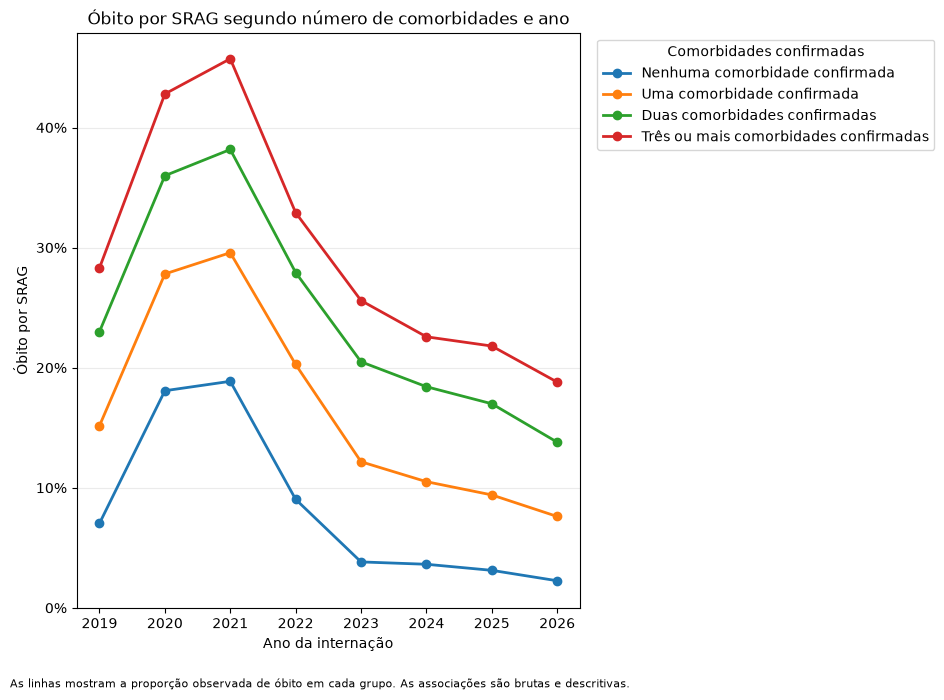

,ano_internacao,grupo_numero_comorbidades,quantidade_total,quantidade_obito_srag,quantidade_cura,percentual_obito_srag,ic95_inferior,ic95_superior
0,2019,Duas comorbidades confirmadas,4617,1062,3555,23.001949,21.810770,24.238017
1,2019,Nenhuma comorbidade confirmada,24896,1752,23144,7.037275,6.726142,7.361664
2,2019,Três ou mais comorbidades confirmadas,2183,618,1565,28.309666,26.459230,30.236304
3,2019,Uma comorbidade confirmada,11696,1774,9922,15.167579,14.528939,15.829092
4,2020,Duas comorbidades confirmadas,213141,76705,136436,35.987914,35.784406,36.191927
5,2020,Nenhuma comorbidade confirmada,341277,61704,279573,18.080328,17.951568,18.209806
6,2020,Três ou mais comorbidades confirmadas,112785,48270,64515,42.798244,42.509733,43.087247
7,2020,Uma comorbidade confirmada,307212,85425,221787,27.806531,27.648374,27.965243
8,2021,Duas comorbidades confirmadas,277878,106067,171811,38.170348,37.989886,38.351137
9,2021,Nenhuma comorbidade confirmada,626223,118132,508091,18.864207,18.767501,18.961294


In [86]:
if (
    "grupo_numero_comorbidades"
    not in base_analise_desfecho.columns
):
    raise KeyError(
        "A coluna grupo_numero_comorbidades não está disponível. "
        "Execute primeiro a análise de óbito por comorbidades."
    )

obito_numero_comorbidades_ano = (
    criar_tabela_obito_categoria_ano(
        dataframe=base_analise_desfecho,
        coluna_categoria=(
            "grupo_numero_comorbidades"
        ),
        nome_categoria_saida=(
            "grupo_numero_comorbidades"
        ),
    )
)

grupos_comorbidades_disponiveis = [
    grupo
    for grupo in ORDEM_NUMERO_COMORBIDADES
    if grupo in set(
        obito_numero_comorbidades_ano[
            "grupo_numero_comorbidades"
        ]
        .astype("string")
        .tolist()
    )
]

figura_obito_comorbidades_ano, eixo_obito_comorbidades_ano = plt.subplots(
    figsize=(
        12,
        7,
    )
)

for grupo in grupos_comorbidades_disponiveis:
    dados_grupo = (
        obito_numero_comorbidades_ano.loc[
            obito_numero_comorbidades_ano[
                "grupo_numero_comorbidades"
            ]
            .astype("string")
            .eq(
                grupo
            )
        ]
        .sort_values(
            "ano_internacao"
        )
    )

    eixo_obito_comorbidades_ano.plot(
        dados_grupo[
            "ano_internacao"
        ]
        .astype(int),
        dados_grupo[
            "percentual_obito_srag"
        ],
        marker="o",
        linewidth=2,
        label=grupo,
    )

anos_comorbidades_obito = (
    obito_numero_comorbidades_ano[
        "ano_internacao"
    ]
    .dropna()
    .astype(int)
    .sort_values()
    .unique()
)

eixo_obito_comorbidades_ano.set_title(
    "Óbito por SRAG segundo número de comorbidades e ano"
)

eixo_obito_comorbidades_ano.set_xlabel(
    "Ano da internação"
)

eixo_obito_comorbidades_ano.set_ylabel(
    "Óbito por SRAG"
)

eixo_obito_comorbidades_ano.set_xticks(
    anos_comorbidades_obito
)

eixo_obito_comorbidades_ano.set_ylim(
    bottom=0
)

eixo_obito_comorbidades_ano.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

eixo_obito_comorbidades_ano.legend(
    title="Comorbidades confirmadas",
    bbox_to_anchor=(
        1.02,
        1,
    ),
    loc="upper left",
)

eixo_obito_comorbidades_ano.grid(
    axis="y",
    alpha=0.25,
)

figura_obito_comorbidades_ano.text(
    0.01,
    0.01,
    (
        "As linhas mostram a proporção observada de óbito em cada "
        "grupo. As associações são brutas e descritivas."
    ),
    fontsize=8,
)

figura_obito_comorbidades_ano.tight_layout(
    rect=[
        0,
        0.04,
        0.8,
        1,
    ]
)

plt.show()

plt.close(
    figura_obito_comorbidades_ano
)

display(
    obito_numero_comorbidades_ano.head(20)
)

In [87]:
def exibir_letalidade_sim_nao(
    tabela: pd.DataFrame,
    titulo: str,
    quantidade_indicadores: int,
) -> pd.DataFrame:
    """
    Exibe a letalidade observada para respostas sim e não.

    Os indicadores são ordenados pela maior diferença absoluta
    entre as duas categorias.
    """

    COLUNAS_NECESSARIAS = [
        "coluna",
        "nome_amigavel",
        "quantidade_sim",
        "percentual_obito_sim",
        "quantidade_nao",
        "percentual_obito_nao",
    ]

    colunas_ausentes = [
        coluna
        for coluna in COLUNAS_NECESSARIAS
        if coluna not in tabela.columns
    ]

    if colunas_ausentes:
        raise KeyError(
            "A tabela não contém as colunas necessárias: "
            f"{colunas_ausentes}"
        )

    dados_grafico = (
        tabela[
            COLUNAS_NECESSARIAS
        ]
        .dropna(
            subset=[
                "percentual_obito_sim",
                "percentual_obito_nao",
            ]
        )
        .copy()
    )

    dados_grafico[
        "diferenca_absoluta_pp"
    ] = (
        dados_grafico[
            "percentual_obito_sim"
        ]
        .sub(
            dados_grafico[
                "percentual_obito_nao"
            ]
        )
        .abs()
    )

    dados_grafico = (
        dados_grafico.sort_values(
            "diferenca_absoluta_pp",
            ascending=False,
        )
        .head(
            quantidade_indicadores
        )
        .sort_values(
            "diferenca_absoluta_pp",
            ascending=True,
        )
        .reset_index(drop=True)
    )

    if dados_grafico.empty:
        raise ValueError(
            "Não existem indicadores válidos para o gráfico."
        )

    dados_grafico[
        "rotulo"
    ] = (
        dados_grafico[
            "nome_amigavel"
        ]
        .astype("string")
        .str.strip()
    )

    mascara_rotulo_vazio = (
        dados_grafico[
            "rotulo"
        ]
        .eq("")
        | dados_grafico[
            "rotulo"
        ]
        .isna()
    )

    dados_grafico.loc[
        mascara_rotulo_vazio,
        "rotulo",
    ] = dados_grafico.loc[
        mascara_rotulo_vazio,
        "coluna",
    ]

    posicoes = np.arange(
        len(
            dados_grafico
        )
    )

    altura_barra = 0.36

    figura, eixo = plt.subplots(
        figsize=(
            12,
            8,
        )
    )

    barras_sim = eixo.barh(
        posicoes
        + altura_barra
        / 2,
        dados_grafico[
            "percentual_obito_sim"
        ],
        height=altura_barra,
        color="tab:red",
        label="Resposta sim",
    )

    barras_nao = eixo.barh(
        posicoes
        - altura_barra
        / 2,
        dados_grafico[
            "percentual_obito_nao"
        ],
        height=altura_barra,
        color="tab:blue",
        label="Resposta não",
    )

    eixo.set_yticks(
        posicoes
    )

    eixo.set_yticklabels(
        dados_grafico[
            "rotulo"
        ]
    )

    eixo.set_title(
        titulo
    )

    eixo.set_xlabel(
        "Óbito por SRAG"
    )

    eixo.set_ylabel(
        "Indicador"
    )

    eixo.xaxis.set_major_formatter(
        plt.FuncFormatter(
            lambda valor, posicao: (
                f"{valor:.0f}%"
            )
        )
    )

    eixo.legend()

    eixo.grid(
        axis="x",
        alpha=0.25,
    )

    for barras in [
        barras_sim,
        barras_nao,
    ]:
        for barra in barras:
            valor = (
                barra.get_width()
            )

            eixo.text(
                valor,
                barra.get_y()
                + barra.get_height()
                / 2,
                f"{valor:.1f}%",
                va="center",
                ha="left",
                fontsize=8,
            )

    figura.text(
        0.01,
        0.01,
        (
            "Denominadores específicos de cada resposta estão "
            "disponíveis na tabela exibida abaixo do gráfico."
        ),
        fontsize=8,
    )

    figura.tight_layout(
        rect=[
            0,
            0.04,
            1,
            1,
        ]
    )

    plt.show()

    plt.close(
        figura
    )

    return dados_grafico

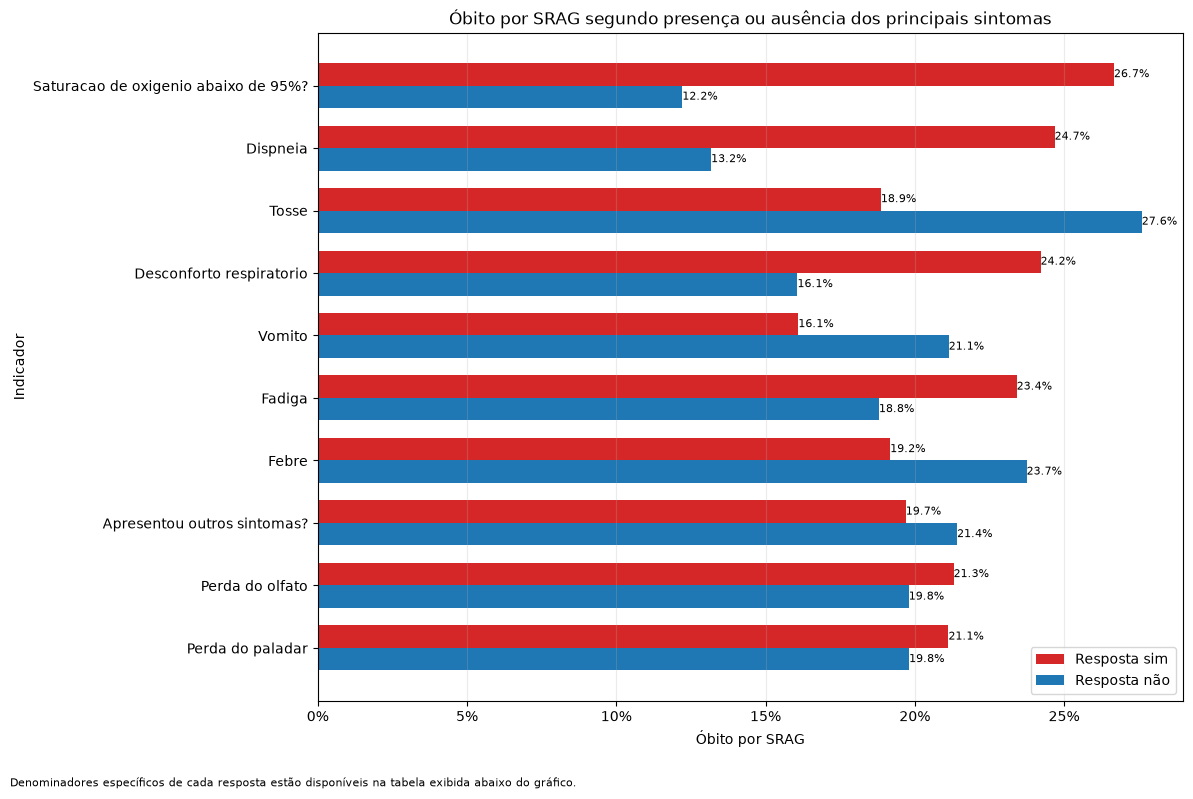

,coluna,rotulo,quantidade_sim,percentual_obito_sim,quantidade_nao,percentual_obito_nao,diferenca_absoluta_pp
0,perd_pala,Perda do paladar,194276,21.127159,2189663,19.809806,1.317353
1,perd_olft,Perda do olfato,190997,21.299811,2196927,19.797654,1.502157
2,outro_sin,Apresentou outros sintomas?,1192832,19.698667,1591654,21.416464,1.717797
3,febre,Febre,2195714,19.176496,1130528,23.745277,4.568781
4,fadiga,Fadiga,728808,23.412751,1788552,18.798727,4.614024
5,vomito,Vomito,381289,16.099074,2407459,21.136684,5.037609
6,desc_resp,Desconforto respiratorio,2284833,24.212579,966073,16.070007,8.142572
7,tosse,Tosse,2773345,18.864043,702670,27.603996,8.739953
8,dispneia,Dispneia,2665358,24.684001,775064,13.177105,11.506896
9,saturacao,Saturacao de oxigenio abaixo de 95%?,2294927,26.671567,988407,12.212985,14.458582


In [88]:
letalidade_sintomas_grafico = (
    exibir_letalidade_sim_nao(
        tabela=obito_sintomas,
        titulo=(
            "Óbito por SRAG segundo presença ou ausência "
            "dos principais sintomas"
        ),
        quantidade_indicadores=10,
    )
)

display(
    letalidade_sintomas_grafico[
        [
            "coluna",
            "rotulo",
            "quantidade_sim",
            "percentual_obito_sim",
            "quantidade_nao",
            "percentual_obito_nao",
            "diferenca_absoluta_pp",
        ]
    ]
)

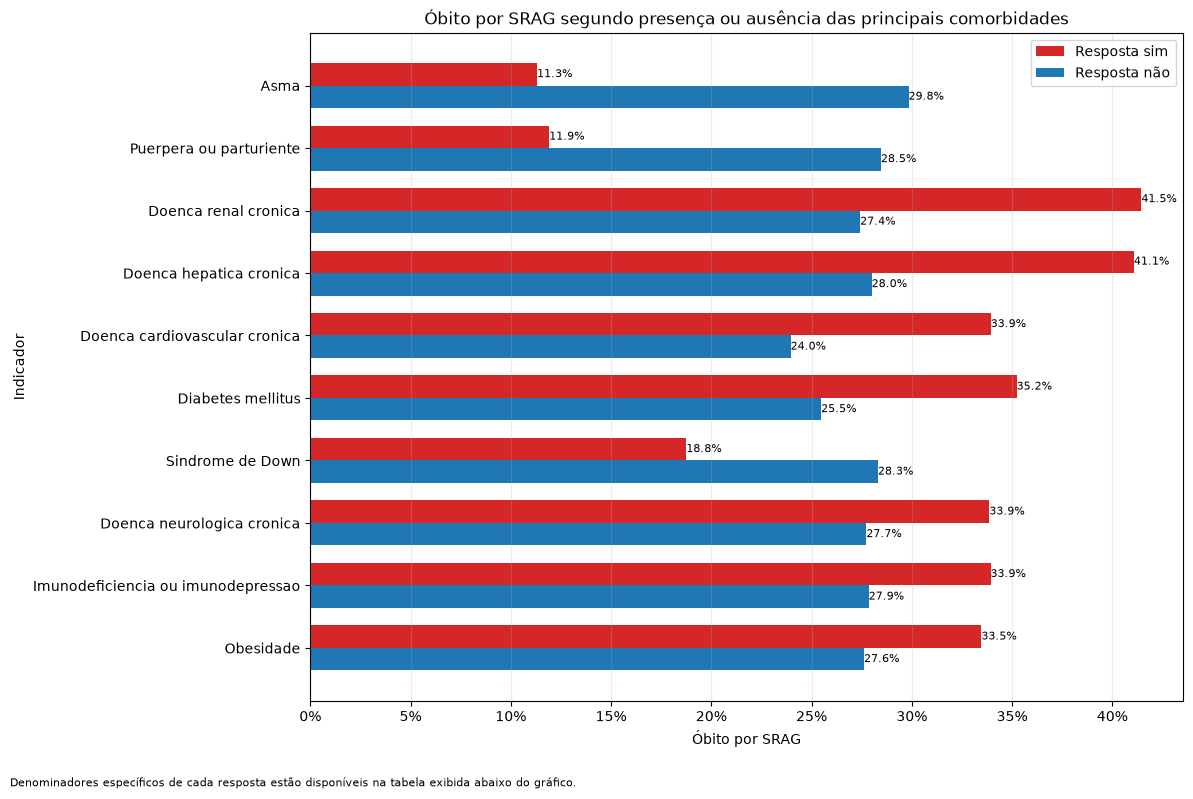

,coluna,rotulo,quantidade_sim,percentual_obito_sim,quantidade_nao,percentual_obito_nao,diferenca_absoluta_pp
0,obesidade,Obesidade,209272,33.471750,1203367,27.619504,5.852245
1,imunodepre,Imunodeficiencia ou imunodepressao,103332,33.926567,1289670,27.850923,6.075644
2,neurologic,Doenca neurologica cronica,170738,33.868266,1245236,27.733940,6.134326
3,sind_down,Sindrome de Down,17664,18.755661,1356640,28.312817,9.557156
4,diabetes,Diabetes mellitus,676931,35.230031,936019,25.480038,9.749992
5,cardiopati,Doenca cardiovascular cronica,1006384,33.935357,718379,23.957688,9.977669
6,hepatica,Doenca hepatica cronica,29302,41.079107,1341175,28.000000,13.079107
7,renal,Doenca renal cronica,122725,41.453657,1276283,27.424247,14.029410
8,puerpera,Puerpera ou parturiente,12874,11.915489,1358493,28.462127,16.546638
9,asma,Asma,177222,11.310672,1239925,29.838176,18.527503


In [89]:
letalidade_comorbidades_grafico = (
    exibir_letalidade_sim_nao(
        tabela=obito_comorbidades,
        titulo=(
            "Óbito por SRAG segundo presença ou ausência "
            "das principais comorbidades"
        ),
        quantidade_indicadores=10,
    )
)

display(
    letalidade_comorbidades_grafico[
        [
            "coluna",
            "rotulo",
            "quantidade_sim",
            "percentual_obito_sim",
            "quantidade_nao",
            "percentual_obito_nao",
            "diferenca_absoluta_pp",
        ]
    ]
)

In [90]:
if "ORDEM_SEXO" not in globals():
    raise NameError(
        "A ordem centralizada das categorias de sexo não foi criada. "
        "Execute primeiro a seção demográfica."
    )

if not ORDEM_SEXO:
    raise ValueError(
        "A ordem centralizada das categorias de sexo está vazia."
    )

PALETA_SEXO = [
    "tab:blue",
    "tab:orange",
    "tab:gray",
    "tab:red",
    "tab:purple",
    "tab:brown",
]

if len(ORDEM_SEXO) > len(PALETA_SEXO):
    raise ValueError(
        "A quantidade de categorias de sexo excede a paleta disponível: "
        f"{len(ORDEM_SEXO)} categorias para {len(PALETA_SEXO)} cores."
    )

CORES_SEXO = {
    categoria: PALETA_SEXO[posicao]
    for posicao, categoria in enumerate(ORDEM_SEXO)
}

COLUNAS_SEXO_NECESSARIAS = [
    "sexo_categoria",
]

colunas_sexo_ausentes_coorte = [
    coluna
    for coluna in COLUNAS_SEXO_NECESSARIAS
    if coluna not in coorte.columns
]

if colunas_sexo_ausentes_coorte:
    raise KeyError(
        "A coorte não contém as colunas necessárias "
        "para os gráficos de sexo: "
        f"{colunas_sexo_ausentes_coorte}"
    )

colunas_sexo_ausentes_desfecho = [
    coluna
    for coluna in COLUNAS_SEXO_NECESSARIAS
    if coluna not in base_analise_desfecho.columns
]

if colunas_sexo_ausentes_desfecho:
    raise KeyError(
        "A base da análise do desfecho não contém "
        "as colunas necessárias para os gráficos de sexo: "
        f"{colunas_sexo_ausentes_desfecho}"
    )

categorias_observadas_coorte = set(
    coorte[
        "sexo_categoria"
    ]
    .dropna()
    .astype("string")
    .tolist()
)

categorias_observadas_desfecho = set(
    base_analise_desfecho[
        "sexo_categoria"
    ]
    .dropna()
    .astype("string")
    .tolist()
)

categorias_sexo_presentes_coorte = [
    categoria
    for categoria in ORDEM_SEXO
    if categoria in categorias_observadas_coorte
]

categorias_sexo_presentes_desfecho = [
    categoria
    for categoria in ORDEM_SEXO
    if categoria in categorias_observadas_desfecho
]

categorias_nao_previstas_coorte = sorted(
    categoria
    for categoria in categorias_observadas_coorte
    if categoria not in ORDEM_SEXO
)

categorias_nao_previstas_desfecho = sorted(
    categoria
    for categoria in categorias_observadas_desfecho
    if categoria not in ORDEM_SEXO
)

if categorias_nao_previstas_coorte:
    raise ValueError(
        "Foram encontradas categorias de sexo não previstas "
        "na coorte: "
        f"{categorias_nao_previstas_coorte}"
    )

if categorias_nao_previstas_desfecho:
    raise ValueError(
        "Foram encontradas categorias de sexo não previstas "
        "na base da análise do desfecho: "
        f"{categorias_nao_previstas_desfecho}"
    )

if not categorias_sexo_presentes_coorte:
    raise ValueError(
        "Nenhuma categoria de sexo prevista foi encontrada "
        "na coorte."
    )

if not categorias_sexo_presentes_desfecho:
    raise ValueError(
        "Nenhuma categoria de sexo prevista foi encontrada "
        "na base da análise do desfecho."
    )

print(
    "Categorias presentes na coorte:",
    categorias_sexo_presentes_coorte,
)

print(
    "Categorias presentes na análise do desfecho:",
    categorias_sexo_presentes_desfecho,
)

Categorias presentes na coorte: ['feminino', 'ignorado', 'masculino']
Categorias presentes na análise do desfecho: ['feminino', 'ignorado', 'masculino']


In [91]:
resumo_sexo_observado = (
    coorte.groupby(
        "sexo_categoria",
        dropna=False,
    )
    .agg(
        quantidade_registros=(
            "sexo_categoria",
            "size",
        ),
    )
    .reset_index()
)

resumo_sexo_observado[
    "percentual_coorte"
] = (
    resumo_sexo_observado[
        "quantidade_registros"
    ]
    .div(
        len(
            coorte
        )
    )
    .mul(100)
)

resumo_sexo_observado = (
    resumo_sexo_observado.sort_values(
        "quantidade_registros",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(
    resumo_sexo_observado
)

,sexo_categoria,quantidade_registros,percentual_coorte
0,masculino,2073315,53.370918
1,feminino,1810867,46.615027
2,ignorado,546,0.014055


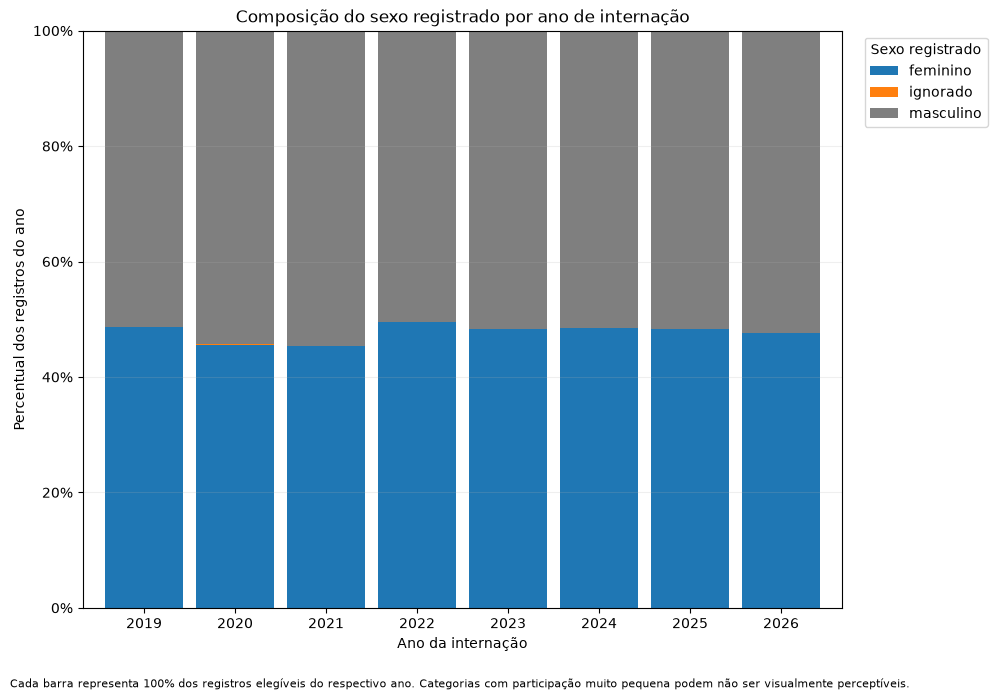

,ano_internacao,sexo_categoria,quantidade,percentual_ano
0,2019,feminino,21110,48.649521
1,2019,ignorado,12,0.027655
2,2019,masculino,22270,51.322824
3,2020,feminino,444414,45.608288
4,2020,ignorado,216,0.022167
5,2020,masculino,529785,54.369545
6,2021,feminino,666186,45.285166
7,2021,ignorado,175,0.011896
8,2021,masculino,804730,54.702938
9,2022,feminino,232830,49.504277


In [92]:
sexo_grafico = (
    sexo_por_ano.pivot(
        index="ano_internacao",
        columns="sexo_categoria",
        values="percentual_ano",
    )
    .reindex(
        columns=(
            categorias_sexo_presentes_coorte
        )
    )
    .fillna(0)
    .sort_index()
)

cores_composicao_sexo = [
    CORES_SEXO[
        categoria
    ]
    for categoria in sexo_grafico.columns
]

figura_sexo_ano, eixo_sexo_ano = plt.subplots(
    figsize=(
        12,
        7,
    )
)

sexo_grafico.plot(
    kind="bar",
    stacked=True,
    width=0.85,
    color=cores_composicao_sexo,
    ax=eixo_sexo_ano,
)

eixo_sexo_ano.set_title(
    "Composição do sexo registrado por ano de internação"
)

eixo_sexo_ano.set_xlabel(
    "Ano da internação"
)

eixo_sexo_ano.set_ylabel(
    "Percentual dos registros do ano"
)

eixo_sexo_ano.set_ylim(
    0,
    100,
)

eixo_sexo_ano.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

eixo_sexo_ano.set_xticklabels(
    eixo_sexo_ano.get_xticklabels(),
    rotation=0,
)

eixo_sexo_ano.legend(
    title="Sexo registrado",
    bbox_to_anchor=(
        1.02,
        1,
    ),
    loc="upper left",
)

eixo_sexo_ano.grid(
    axis="y",
    alpha=0.20,
)

figura_sexo_ano.text(
    0.01,
    0.01,
    (
        "Cada barra representa 100% dos registros elegíveis "
        "do respectivo ano. Categorias com participação muito "
        "pequena podem não ser visualmente perceptíveis."
    ),
    fontsize=8,
)

figura_sexo_ano.tight_layout(
    rect=[
        0,
        0.04,
        0.84,
        1,
    ]
)

plt.show()

plt.close(
    figura_sexo_ano
)

display(
    sexo_por_ano.loc[
        sexo_por_ano[
            "sexo_categoria"
        ]
        .isin(
            categorias_sexo_presentes_coorte
        )
    ]
    .sort_values(
        [
            "ano_internacao",
            "sexo_categoria",
        ]
    )
    .reset_index(drop=True)
)

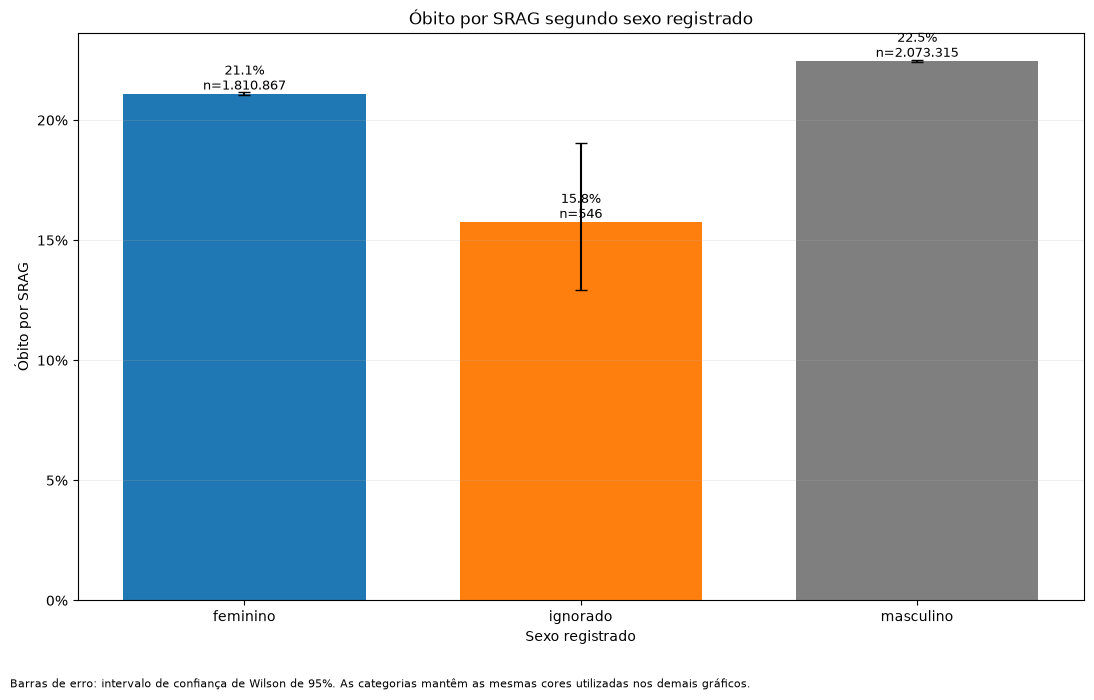

,sexo_categoria,quantidade_total,quantidade_obito_srag,quantidade_cura,percentual_obito_srag,ic95_inferior,ic95_superior
0,feminino,1810867,381994,1428873,21.094536,21.035176,21.154019
1,ignorado,546,86,460,15.750916,12.935966,19.044427
2,masculino,2073315,465640,1607675,22.458719,22.401967,22.515574


In [93]:
obito_por_sexo = (
    criar_tabela_obito_categorica(
        dataframe=base_analise_desfecho,
        coluna_categoria="sexo_categoria",
        nome_categoria_saida="sexo_categoria",
    )
)

ordem_sexo_obito = {
    categoria: posicao
    for posicao, categoria in enumerate(
        ORDEM_SEXO
    )
}

obito_por_sexo[
    "ordem_sexo"
] = (
    obito_por_sexo[
        "sexo_categoria"
    ]
    .astype("string")
    .map(
        ordem_sexo_obito
    )
    .fillna(
        len(
            ordem_sexo_obito
        )
    )
)

obito_por_sexo = (
    obito_por_sexo.loc[
        obito_por_sexo[
            "sexo_categoria"
        ]
        .astype("string")
        .isin(
            categorias_sexo_presentes_desfecho
        )
    ]
    .sort_values(
        "ordem_sexo"
    )
    .drop(
        columns=[
            "ordem_sexo",
        ]
    )
    .reset_index(drop=True)
)

dados_obito_sexo_grafico = (
    obito_por_sexo.loc[
        obito_por_sexo[
            "quantidade_total"
        ].gt(0)
    ]
    .copy()
)

posicoes_sexo = np.arange(
    len(
        dados_obito_sexo_grafico
    )
)

percentuais_obito_sexo = (
    dados_obito_sexo_grafico[
        "percentual_obito_srag"
    ]
    .astype(float)
    .to_numpy()
)

erros_inferiores_sexo = (
    dados_obito_sexo_grafico[
        "percentual_obito_srag"
    ]
    .sub(
        dados_obito_sexo_grafico[
            "ic95_inferior"
        ]
    )
    .clip(
        lower=0
    )
    .astype(float)
    .to_numpy()
)

erros_superiores_sexo = (
    dados_obito_sexo_grafico[
        "ic95_superior"
    ]
    .sub(
        dados_obito_sexo_grafico[
            "percentual_obito_srag"
        ]
    )
    .clip(
        lower=0
    )
    .astype(float)
    .to_numpy()
)

cores_obito_sexo = [
    CORES_SEXO[
        categoria
    ]
    for categoria in dados_obito_sexo_grafico[
        "sexo_categoria"
    ]
]

figura_obito_sexo, eixo_obito_sexo = plt.subplots(
    figsize=(
        11,
        7,
    )
)

barras_obito_sexo = eixo_obito_sexo.bar(
    posicoes_sexo,
    percentuais_obito_sexo,
    color=cores_obito_sexo,
    width=0.72,
)

eixo_obito_sexo.errorbar(
    posicoes_sexo,
    percentuais_obito_sexo,
    yerr=[
        erros_inferiores_sexo,
        erros_superiores_sexo,
    ],
    fmt="none",
    ecolor="black",
    capsize=4,
)

eixo_obito_sexo.set_xticks(
    posicoes_sexo
)

eixo_obito_sexo.set_xticklabels(
    dados_obito_sexo_grafico[
        "sexo_categoria"
    ]
)

eixo_obito_sexo.set_title(
    "Óbito por SRAG segundo sexo registrado"
)

eixo_obito_sexo.set_xlabel(
    "Sexo registrado"
)

eixo_obito_sexo.set_ylabel(
    "Óbito por SRAG"
)

eixo_obito_sexo.set_ylim(
    bottom=0
)

eixo_obito_sexo.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

eixo_obito_sexo.grid(
    axis="y",
    alpha=0.20,
)

for barra, percentual, quantidade in zip(
    barras_obito_sexo,
    percentuais_obito_sexo,
    dados_obito_sexo_grafico[
        "quantidade_total"
    ],
):
    quantidade_formatada = (
        f"{int(quantidade):,}"
        .replace(
            ",",
            ".",
        )
    )

    eixo_obito_sexo.text(
        barra.get_x()
        + barra.get_width()
        / 2,
        barra.get_height(),
        (
            f"{percentual:.1f}%\n"
            f"n={quantidade_formatada}"
        ),
        ha="center",
        va="bottom",
        fontsize=9,
    )

figura_obito_sexo.text(
    0.01,
    0.01,
    (
        "Barras de erro: intervalo de confiança de Wilson de 95%. "
        "As categorias mantêm as mesmas cores utilizadas "
        "nos demais gráficos."
    ),
    fontsize=8,
)

figura_obito_sexo.tight_layout(
    rect=[
        0,
        0.05,
        1,
        1,
    ]
)

plt.show()

plt.close(
    figura_obito_sexo
)

display(
    obito_por_sexo
)

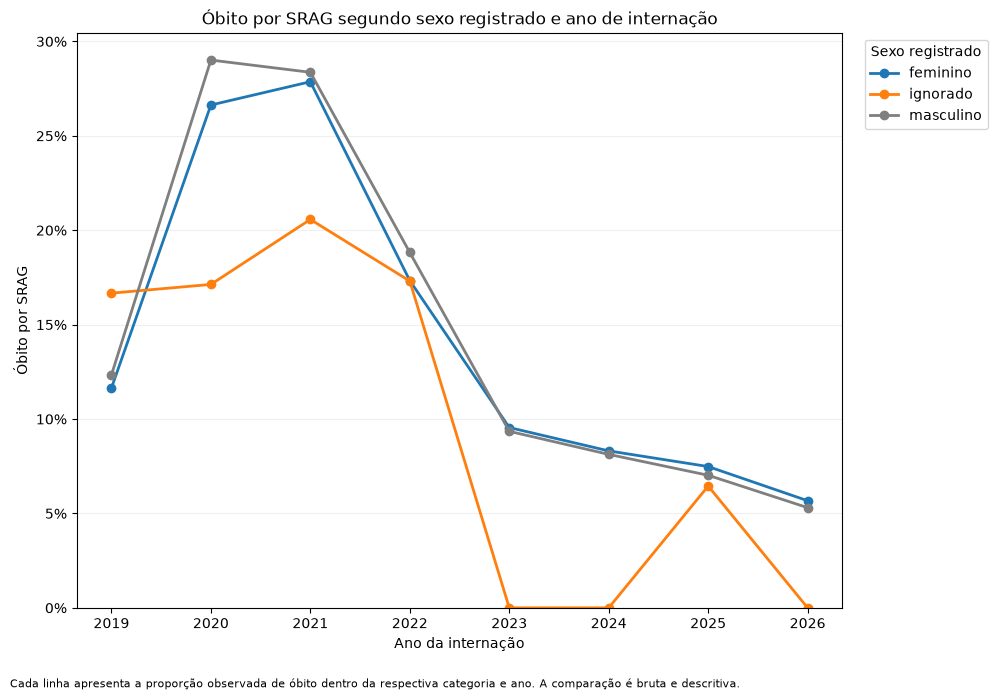

,ano_internacao,sexo_categoria,quantidade_total,quantidade_obito_srag,quantidade_cura,percentual_obito_srag,ic95_inferior,ic95_superior
0,2019,feminino,21110,2457,18653,11.639034,1.121339e+01,12.078636
1,2019,ignorado,12,2,10,16.666667,4.696514e+00,44.803086
2,2019,masculino,22270,2747,19523,12.33498,1.190958e+01,12.773375
3,2020,feminino,444414,118356,326058,26.631924,2.650217e+01,26.762086
4,2020,ignorado,216,37,179,17.12963,1.269056e+01,22.717440
5,2020,masculino,529785,153711,376074,29.013845,2.889179e+01,29.136202
6,2021,feminino,666186,185640,480546,27.866091,2.775856e+01,27.973880
7,2021,ignorado,175,36,139,20.571429,1.524565e+01,27.161440
8,2021,masculino,804730,228264,576466,28.36529,2.826691e+01,28.463880
9,2022,feminino,232830,40352,192478,17.3311,1.717789e+01,17.485388


In [94]:
COLUNAS_OBITO_SEXO_ANO_NECESSARIAS = [
    "ano_internacao",
    "sexo_categoria",
    "alvo_obito_srag",
]

colunas_obito_sexo_ano_ausentes = [
    coluna
    for coluna in COLUNAS_OBITO_SEXO_ANO_NECESSARIAS
    if coluna not in base_analise_desfecho.columns
]

if colunas_obito_sexo_ano_ausentes:
    raise KeyError(
        "A base da análise do desfecho não contém "
        "as colunas necessárias para calcular óbito "
        "por sexo e ano: "
        f"{colunas_obito_sexo_ano_ausentes}"
    )

if "categorias_sexo_presentes_desfecho" not in globals():
    raise NameError(
        "A lista categorias_sexo_presentes_desfecho "
        "não foi criada. Execute primeiro a célula de "
        "configuração das categorias de sexo."
    )

if not categorias_sexo_presentes_desfecho:
    raise ValueError(
        "Nenhuma categoria de sexo está disponível "
        "para a análise anual do desfecho."
    )

obito_sexo_ano = (
    criar_tabela_obito_categoria_ano(
        dataframe=base_analise_desfecho,
        coluna_categoria="sexo_categoria",
        nome_categoria_saida="sexo_categoria",
    )
)

obito_sexo_ano = (
    obito_sexo_ano.loc[
        obito_sexo_ano[
            "sexo_categoria"
        ]
        .astype("string")
        .isin(
            categorias_sexo_presentes_desfecho
        )
    ]
    .copy()
)

ordem_sexo_ano = {
    categoria: posicao
    for posicao, categoria in enumerate(
        ORDEM_SEXO
    )
}

obito_sexo_ano[
    "ordem_sexo"
] = (
    obito_sexo_ano[
        "sexo_categoria"
    ]
    .astype("string")
    .map(
        ordem_sexo_ano
    )
    .fillna(
        len(
            ordem_sexo_ano
        )
    )
)

obito_sexo_ano = (
    obito_sexo_ano
    .sort_values(
        [
            "ano_internacao",
            "ordem_sexo",
        ]
    )
    .drop(
        columns=[
            "ordem_sexo",
        ]
    )
    .reset_index(drop=True)
)

if obito_sexo_ano.empty:
    raise ValueError(
        "A tabela de óbito por sexo e ano está vazia."
    )

percentuais_obito_sexo_ano_validos = (
    obito_sexo_ano[
        "percentual_obito_srag"
    ]
    .dropna()
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

if not percentuais_obito_sexo_ano_validos:
    raise RuntimeError(
        "A tabela de óbito por sexo e ano contém "
        "percentuais fora do intervalo de 0% a 100%."
    )

categorias_obito_sexo_ano = [
    categoria
    for categoria in ORDEM_SEXO
    if categoria in set(
        obito_sexo_ano[
            "sexo_categoria"
        ]
        .astype("string")
        .tolist()
    )
]

if not categorias_obito_sexo_ano:
    raise ValueError(
        "Nenhuma categoria de sexo prevista foi encontrada "
        "na tabela anual do desfecho."
    )

figura_obito_sexo_ano, eixo_obito_sexo_ano = plt.subplots(
    figsize=(
        12,
        7,
    )
)

for categoria in categorias_obito_sexo_ano:
    dados_categoria = (
        obito_sexo_ano.loc[
            obito_sexo_ano[
                "sexo_categoria"
            ]
            .astype("string")
            .eq(
                categoria
            )
        ]
        .sort_values(
            "ano_internacao"
        )
        .copy()
    )

    if dados_categoria.empty:
        continue

    eixo_obito_sexo_ano.plot(
        dados_categoria[
            "ano_internacao"
        ]
        .astype(int),
        dados_categoria[
            "percentual_obito_srag"
        ],
        marker="o",
        linewidth=2,
        color=CORES_SEXO[
            categoria
        ],
        label=categoria,
    )

anos_obito_sexo = (
    obito_sexo_ano[
        "ano_internacao"
    ]
    .dropna()
    .astype(int)
    .sort_values()
    .unique()
)

eixo_obito_sexo_ano.set_title(
    "Óbito por SRAG segundo sexo registrado e ano de internação"
)

eixo_obito_sexo_ano.set_xlabel(
    "Ano da internação"
)

eixo_obito_sexo_ano.set_ylabel(
    "Óbito por SRAG"
)

eixo_obito_sexo_ano.set_xticks(
    anos_obito_sexo
)

eixo_obito_sexo_ano.set_ylim(
    bottom=0
)

eixo_obito_sexo_ano.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

eixo_obito_sexo_ano.legend(
    title="Sexo registrado",
    bbox_to_anchor=(
        1.02,
        1,
    ),
    loc="upper left",
)

eixo_obito_sexo_ano.grid(
    axis="y",
    alpha=0.20,
)

figura_obito_sexo_ano.text(
    0.01,
    0.01,
    (
        "Cada linha apresenta a proporção observada de óbito "
        "dentro da respectiva categoria e ano. "
        "A comparação é bruta e descritiva."
    ),
    fontsize=8,
)

figura_obito_sexo_ano.tight_layout(
    rect=[
        0,
        0.04,
        0.84,
        1,
    ]
)

plt.show()

plt.close(
    figura_obito_sexo_ano
)

display(
    obito_sexo_ano
)

In [95]:
verificacoes_paineis_desfecho = {
    "tabela_obito_faixa_etaria_ano_nao_vazia": (
        not obito_faixa_etaria_ano.empty
    ),
    "matriz_obito_faixa_etaria_ano_nao_vazia": (
        not matriz_obito_faixa_etaria_ano.empty
    ),
    "tabela_obito_comorbidades_ano_nao_vazia": (
        not obito_numero_comorbidades_ano.empty
    ),
    "letalidade_sintomas_nao_vazia": (
        not letalidade_sintomas_grafico.empty
    ),
    "letalidade_comorbidades_nao_vazia": (
        not letalidade_comorbidades_grafico.empty
    ),
    "composicao_sexo_nao_vazia": (
        not sexo_grafico.empty
    ),
    "obito_por_sexo_nao_vazio": (
        not obito_por_sexo.empty
    ),
    "obito_sexo_ano_nao_vazio": (
        not obito_sexo_ano.empty
    ),
    "percentuais_faixa_ano_validos": (
        obito_faixa_etaria_ano[
            "percentual_obito_srag"
        ]
        .between(
            0,
            100,
            inclusive="both",
        )
        .all()
    ),
    "percentuais_comorbidades_ano_validos": (
        obito_numero_comorbidades_ano[
            "percentual_obito_srag"
        ]
        .between(
            0,
            100,
            inclusive="both",
        )
        .all()
    ),
    "percentuais_sexo_globais_validos": (
        obito_por_sexo[
            "percentual_obito_srag"
        ]
        .dropna()
        .between(
            0,
            100,
            inclusive="both",
        )
        .all()
    ),
    "percentuais_sexo_anuais_validos": (
        obito_sexo_ano[
            "percentual_obito_srag"
        ]
        .dropna()
        .between(
            0,
            100,
            inclusive="both",
        )
        .all()
    ),
}

verificacoes_paineis_desfecho_df = pd.DataFrame(
    {
        "verificacao": list(
            verificacoes_paineis_desfecho.keys()
        ),
        "resultado": list(
            verificacoes_paineis_desfecho.values()
        ),
    }
)

display(
    verificacoes_paineis_desfecho_df
)

if not all(
    verificacoes_paineis_desfecho.values()
):
    falhas_paineis_desfecho = [
        verificacao
        for verificacao, resultado
        in verificacoes_paineis_desfecho.items()
        if not resultado
    ]

    raise RuntimeError(
        "Os painéis visuais do desfecho terminaram "
        "com falhas: "
        f"{falhas_paineis_desfecho}"
    )

print(
    "Painéis visuais do desfecho exibidos "
    "e validados com sucesso."
)

,verificacao,resultado
0,tabela_obito_faixa_etaria_ano_nao_vazia,True
1,matriz_obito_faixa_etaria_ano_nao_vazia,True
2,tabela_obito_comorbidades_ano_nao_vazia,True
3,letalidade_sintomas_nao_vazia,True
4,letalidade_comorbidades_nao_vazia,True
5,composicao_sexo_nao_vazia,True
6,obito_por_sexo_nao_vazio,True
7,obito_sexo_ano_nao_vazio,True
8,percentuais_faixa_ano_validos,True
9,percentuais_comorbidades_ano_validos,True


Painéis visuais do desfecho exibidos e validados com sucesso.


## 10. Distribuição mensal e sazonalidade

A análise anual pode ocultar ondas epidemiológicas e mudanças ocorridas
dentro de cada ano.

Nesta seção, serão avaliados:

- volume mensal de internações;
- proporção mensal de óbito por SRAG;
- média móvel de três meses;
- distribuição do volume por ano e mês;
- distribuição do óbito por ano e mês.

Os meses posteriores à data máxima disponível na coorte não serão
representados como volume zero. Eles permanecerão ausentes para evitar
a interpretação incorreta de períodos ainda não observados.

In [96]:
COLUNAS_SERIE_MENSAL_NECESSARIAS = [
    "dt_interna_convertida",
    "ano_internacao",
    "alvo_obito_srag",
]

colunas_serie_mensal_ausentes = [
    coluna
    for coluna in COLUNAS_SERIE_MENSAL_NECESSARIAS
    if coluna not in coorte.columns
]

if colunas_serie_mensal_ausentes:
    raise KeyError(
        "A coorte não contém as colunas necessárias "
        "para a análise mensal: "
        f"{colunas_serie_mensal_ausentes}"
    )

# Converter somente a série usada na análise mensal
# para datetime64[ns] nativo do pandas/NumPy.
# Isso habilita .dt.to_period(), que não existe
# no acessor temporal do backend PyArrow.

data_internacao_mensal_arrow = pd.to_datetime(
    coorte[
        "dt_interna_convertida"
    ],
    errors="coerce",
)

data_internacao_mensal = pd.Series(
    data_internacao_mensal_arrow.to_numpy(
        dtype="datetime64[ns]",
        na_value=np.datetime64("NaT"),
        copy=False,
    ),
    index=coorte.index,
    name="dt_interna_convertida",
    dtype="datetime64[ns]",
)

del data_internacao_mensal_arrow

quantidade_datas_mensais_ausentes = int(
    data_internacao_mensal
    .isna()
    .sum()
)

if quantidade_datas_mensais_ausentes > 0:
    raise ValueError(
        "Existem datas de internação ausentes ou inválidas "
        "na coorte analítica: "
        f"{quantidade_datas_mensais_ausentes}"
    )

if not coorte[
    "alvo_obito_srag"
].isin(
    [
        0,
        1,
    ]
).all():
    raise ValueError(
        "A coluna alvo_obito_srag contém valores "
        "diferentes de zero e um."
    )

ano_data_internacao = (
    data_internacao_mensal
    .dt.year
    .astype("Int64")
)

ano_coorte = (
    pd.to_numeric(
        coorte[
            "ano_internacao"
        ],
        errors="coerce",
    )
    .astype("Int64")
)

mascara_ano_divergente = (
    ano_data_internacao.ne(
        ano_coorte
    )
)

quantidade_anos_divergentes = int(
    mascara_ano_divergente
    .fillna(True)
    .sum()
)

if quantidade_anos_divergentes > 0:
    raise RuntimeError(
        "O ano extraído de dt_interna_convertida diverge "
        "de ano_internacao em "
        f"{quantidade_anos_divergentes} registros."
    )

coorte[
    "mes_internacao"
] = (
    data_internacao_mensal
    .dt.month
    .astype("Int8")
)

coorte[
    "ano_mes_internacao"
] = (
    data_internacao_mensal
    .dt.to_period("M")
    .dt.to_timestamp()
)

if not coorte[
    "mes_internacao"
].between(
    1,
    12,
    inclusive="both",
).all():
    raise RuntimeError(
        "Foram identificados meses fora do intervalo "
        "de janeiro a dezembro."
    )

data_minima_internacao = (
    data_internacao_mensal.min()
)

data_maxima_internacao = (
    data_internacao_mensal.max()
)

primeiro_mes_observado = (
    data_minima_internacao
    .to_period("M")
    .to_timestamp()
)

ultimo_mes_observado = (
    data_maxima_internacao
    .to_period("M")
    .to_timestamp()
)

ultimo_dia_mes_maximo = (
    ultimo_mes_observado
    + pd.offsets.MonthEnd(0)
)

ultimo_mes_completo = (
    data_maxima_internacao.normalize()
    >= ultimo_dia_mes_maximo.normalize()
)

calendario_mensal = pd.DataFrame(
    {
        "ano_mes_internacao": pd.date_range(
            start=primeiro_mes_observado,
            end=ultimo_mes_observado,
            freq="MS",
        ),
    }
)

calendario_mensal[
    "ano_internacao"
] = (
    calendario_mensal[
        "ano_mes_internacao"
    ]
    .dt.year
    .astype("Int64")
)

calendario_mensal[
    "mes_internacao"
] = (
    calendario_mensal[
        "ano_mes_internacao"
    ]
    .dt.month
    .astype("Int8")
)

calendario_mensal[
    "mes_observado"
] = True

calendario_mensal[
    "mes_completo"
] = True

if not ultimo_mes_completo:
    calendario_mensal.loc[
        calendario_mensal[
            "ano_mes_internacao"
        ].eq(
            ultimo_mes_observado
        ),
        "mes_completo",
    ] = False

contagem_alvo_mensal = (
    coorte.groupby(
        [
            "ano_mes_internacao",
            "alvo_obito_srag",
        ],
        dropna=False,
    )
    .size()
    .unstack(
        fill_value=0
    )
)

contagem_alvo_mensal = (
    contagem_alvo_mensal.reindex(
        columns=[
            0,
            1,
        ],
        fill_value=0,
    )
    .rename(
        columns={
            0: "quantidade_cura",
            1: "quantidade_obito_srag",
        }
    )
    .reset_index()
)

serie_mensal = (
    calendario_mensal.merge(
        contagem_alvo_mensal,
        on="ano_mes_internacao",
        how="left",
        validate="one_to_one",
    )
)

COLUNAS_CONTAGEM_MENSAL = [
    "quantidade_cura",
    "quantidade_obito_srag",
]

for coluna in COLUNAS_CONTAGEM_MENSAL:
    serie_mensal[
        coluna
    ] = (
        pd.to_numeric(
            serie_mensal[
                coluna
            ],
            errors="coerce",
        )
        .fillna(0)
        .astype("int64")
    )

serie_mensal[
    "quantidade_registros"
] = (
    serie_mensal[
        "quantidade_cura"
    ]
    .add(
        serie_mensal[
            "quantidade_obito_srag"
        ]
    )
    .astype("int64")
)

serie_mensal[
    "percentual_cura"
] = (
    serie_mensal[
        "quantidade_cura"
    ]
    .div(
        serie_mensal[
            "quantidade_registros"
        ]
        .replace(
            0,
            np.nan,
        )
    )
    .mul(100)
)

serie_mensal[
    "percentual_obito_srag"
] = (
    serie_mensal[
        "quantidade_obito_srag"
    ]
    .div(
        serie_mensal[
            "quantidade_registros"
        ]
        .replace(
            0,
            np.nan,
        )
    )
    .mul(100)
)

serie_mensal[
    "rotulo_ano_mes"
] = (
    serie_mensal[
        "ano_mes_internacao"
    ]
    .dt.strftime(
        "%Y-%m"
    )
)

serie_mensal = (
    serie_mensal[
        [
            "ano_mes_internacao",
            "rotulo_ano_mes",
            "ano_internacao",
            "mes_internacao",
            "mes_observado",
            "mes_completo",
            "quantidade_registros",
            "quantidade_cura",
            "quantidade_obito_srag",
            "percentual_cura",
            "percentual_obito_srag",
        ]
    ]
    .sort_values(
        "ano_mes_internacao"
    )
    .reset_index(drop=True)
)

total_registros_serie_mensal = int(
    serie_mensal[
        "quantidade_registros"
    ]
    .sum()
)

if total_registros_serie_mensal != len(
    coorte
):
    raise RuntimeError(
        "A soma mensal dos registros não corresponde "
        "ao total da coorte."
    )

total_obitos_serie_mensal = int(
    serie_mensal[
        "quantidade_obito_srag"
    ]
    .sum()
)

total_obitos_coorte = int(
    coorte[
        "alvo_obito_srag"
    ]
    .sum()
)

if total_obitos_serie_mensal != total_obitos_coorte:
    raise RuntimeError(
        "A soma mensal dos óbitos não corresponde "
        "ao total de óbitos da coorte."
    )

percentuais_mensais_validos = (
    serie_mensal[
        "percentual_obito_srag"
    ]
    .dropna()
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

if not percentuais_mensais_validos:
    raise RuntimeError(
        "A série mensal contém percentuais de óbito "
        "fora do intervalo de 0% a 100%."
    )

meses_sem_registros = (
    serie_mensal.loc[
        serie_mensal[
            "quantidade_registros"
        ].eq(0),
        "rotulo_ano_mes",
    ]
    .tolist()
)

print(
    "Primeiro mês observado:",
    primeiro_mes_observado.strftime(
        "%Y-%m"
    ),
)

print(
    "Último mês observado:",
    ultimo_mes_observado.strftime(
        "%Y-%m"
    ),
)

print(
    "Data máxima de internação:",
    data_maxima_internacao.strftime(
        "%Y-%m-%d"
    ),
)

print(
    "Último mês está completo:",
    bool(
        ultimo_mes_completo
    ),
)

print(
    "Quantidade de meses no calendário:",
    len(
        serie_mensal
    ),
)

print(
    "Meses sem registros:",
    len(
        meses_sem_registros
    ),
)

if meses_sem_registros:
    print(
        "Lista de meses sem registros:",
        meses_sem_registros,
    )

display(
    serie_mensal
)

C:\Users\olivem85\AppData\Local\Temp\1\ipykernel_60312\3723131606.py:35: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  na_value=np.datetime64("NaT"),


Primeiro mês observado: 2019-01
Último mês observado: 2026-09
Data máxima de internação: 2026-09-25
Último mês está completo: False
Quantidade de meses no calendário: 93
Meses sem registros: 0


,ano_mes_internacao,rotulo_ano_mes,ano_internacao,mes_internacao,mes_observado,mes_completo,quantidade_registros,quantidade_cura,quantidade_obito_srag,percentual_cura,percentual_obito_srag
0,2019-01-01,2019-01,2019,1,True,True,1072,906,166,84.514925,15.485075
1,2019-02-01,2019-02,2019,2,True,True,1698,1494,204,87.985866,12.014134
2,2019-03-01,2019-03,2019,3,True,True,3787,3459,328,91.338791,8.661209
3,2019-04-01,2019-04,2019,4,True,True,5550,4987,563,89.855856,10.144144
4,2019-05-01,2019-05,2019,5,True,True,7505,6627,878,88.301133,11.698867
...,...,...,...,...,...,...,...,...,...,...,...
88,2026-05-01,2026-05,2026,5,True,True,31055,29557,1498,95.176300,4.823700
89,2026-06-01,2026-06,2026,6,True,True,30477,28983,1494,95.097943,4.902057
90,2026-07-01,2026-07,2026,7,True,True,23134,21930,1204,94.795539,5.204461
91,2026-08-01,2026-08,2026,8,True,True,14301,13545,756,94.713656,5.286344


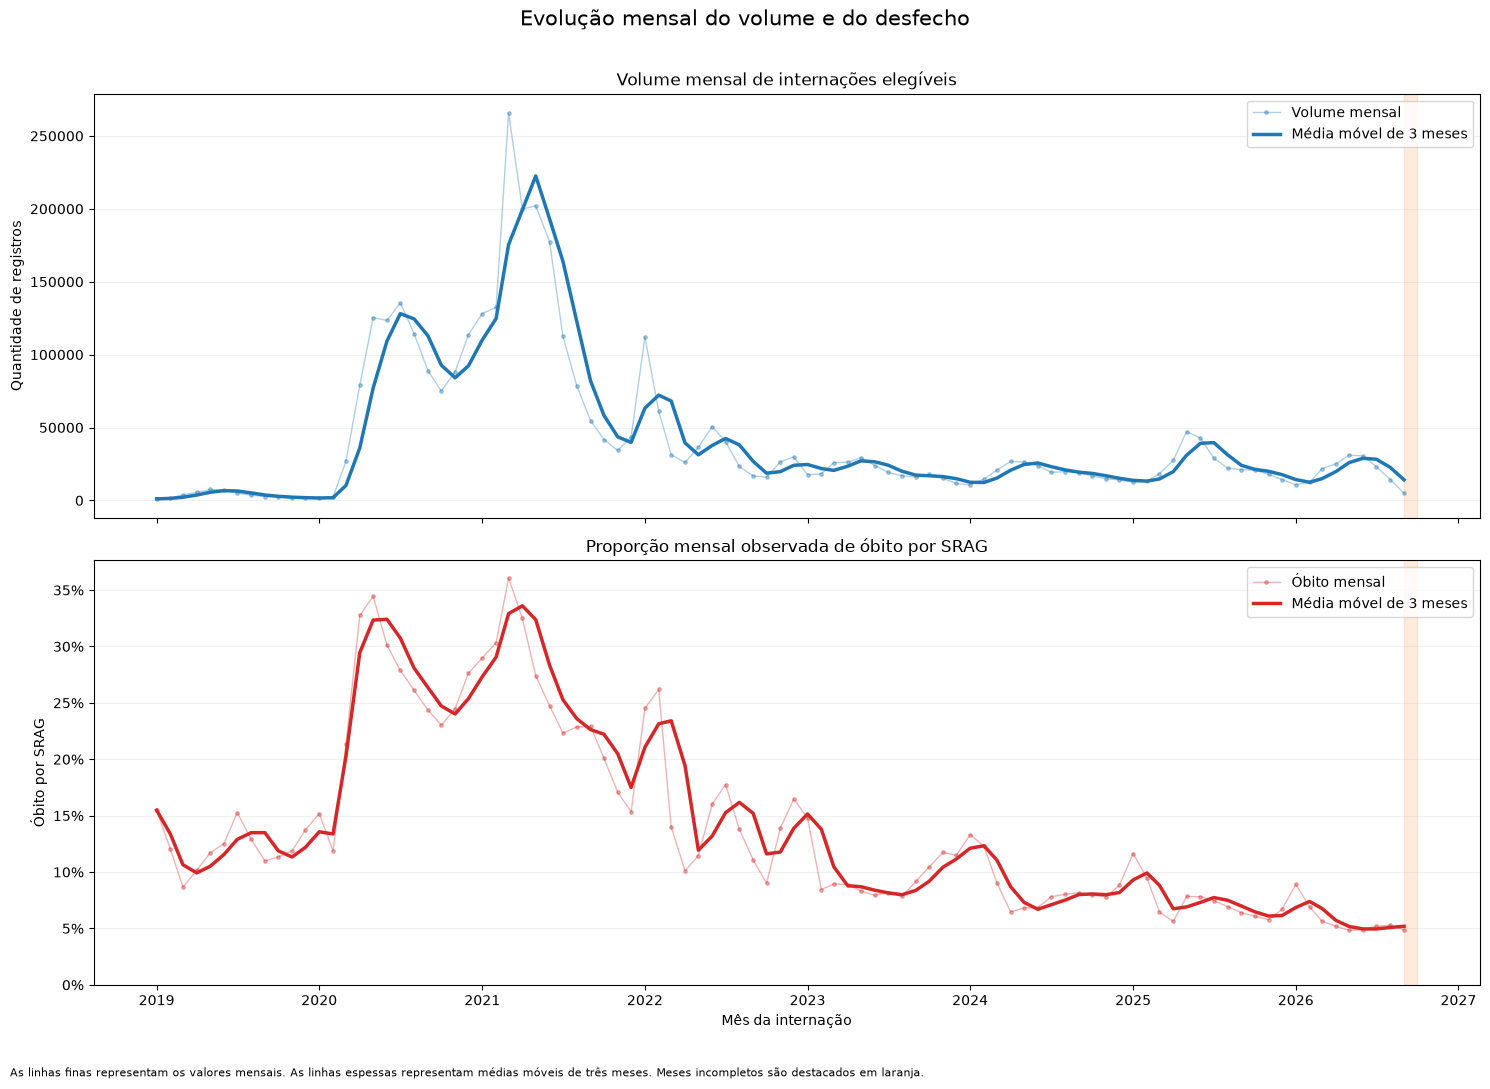

,ano_mes_internacao,mes_completo,quantidade_registros,volume_media_movel_3_meses,percentual_obito_srag,obito_media_movel_3_meses
0,2019-01-01,True,1072,1072.000000,15.485075,15.485075
1,2019-02-01,True,1698,1385.000000,12.014134,13.357401
2,2019-03-01,True,3787,2185.666667,8.661209,10.645112
3,2019-04-01,True,5550,3678.333333,10.144144,9.922972
4,2019-05-01,True,7505,5614.000000,11.698867,10.503503
...,...,...,...,...,...,...
88,2026-05-01,True,31055,26000.333333,4.823700,5.167882
89,2026-06-01,True,30477,28898.333333,4.902057,4.956457
90,2026-07-01,True,23134,28222.000000,5.204461,4.955945
91,2026-08-01,True,14301,22637.333333,5.286344,5.085994


In [97]:
JANELA_MEDIA_MOVEL_MESES = 3

if "serie_mensal" not in globals():
    raise NameError(
        "A tabela serie_mensal não foi criada. "
        "Execute primeiro a célula de construção da série mensal."
    )

COLUNAS_SERIE_GRAFICO_NECESSARIAS = [
    "ano_mes_internacao",
    "mes_completo",
    "quantidade_registros",
    "quantidade_obito_srag",
    "percentual_obito_srag",
]

colunas_serie_grafico_ausentes = [
    coluna
    for coluna in COLUNAS_SERIE_GRAFICO_NECESSARIAS
    if coluna not in serie_mensal.columns
]

if colunas_serie_grafico_ausentes:
    raise KeyError(
        "A série mensal não contém as colunas necessárias: "
        f"{colunas_serie_grafico_ausentes}"
    )

serie_mensal_grafico = (
    serie_mensal[
        COLUNAS_SERIE_GRAFICO_NECESSARIAS
    ]
    .copy()
    .sort_values(
        "ano_mes_internacao"
    )
    .reset_index(drop=True)
)

serie_mensal_grafico[
    "ano_mes_internacao"
] = pd.to_datetime(
    serie_mensal_grafico[
        "ano_mes_internacao"
    ],
    errors="coerce",
)

if serie_mensal_grafico[
    "ano_mes_internacao"
].isna().any():
    raise ValueError(
        "A série mensal contém referências mensais inválidas."
    )

serie_mensal_grafico[
    "quantidade_registros"
] = pd.to_numeric(
    serie_mensal_grafico[
        "quantidade_registros"
    ],
    errors="coerce",
)

serie_mensal_grafico[
    "quantidade_obito_srag"
] = pd.to_numeric(
    serie_mensal_grafico[
        "quantidade_obito_srag"
    ],
    errors="coerce",
)

if serie_mensal_grafico[
    [
        "quantidade_registros",
        "quantidade_obito_srag",
    ]
].isna().any().any():
    raise ValueError(
        "A série mensal contém contagens não numéricas."
    )

serie_mensal_grafico[
    "volume_media_movel_3_meses"
] = (
    serie_mensal_grafico[
        "quantidade_registros"
    ]
    .rolling(
        window=JANELA_MEDIA_MOVEL_MESES,
        min_periods=1,
    )
    .mean()
)

obitos_moveis_3_meses = (
    serie_mensal_grafico[
        "quantidade_obito_srag"
    ]
    .rolling(
        window=JANELA_MEDIA_MOVEL_MESES,
        min_periods=1,
    )
    .sum()
)

registros_moveis_3_meses = (
    serie_mensal_grafico[
        "quantidade_registros"
    ]
    .rolling(
        window=JANELA_MEDIA_MOVEL_MESES,
        min_periods=1,
    )
    .sum()
)

serie_mensal_grafico[
    "obito_media_movel_3_meses"
] = (
    obitos_moveis_3_meses
    .div(
        registros_moveis_3_meses
        .replace(
            0,
            np.nan,
        )
    )
    .mul(100)
)

percentuais_moveis_validos = (
    serie_mensal_grafico[
        "obito_media_movel_3_meses"
    ]
    .dropna()
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

if not percentuais_moveis_validos:
    raise RuntimeError(
        "A média móvel do óbito contém valores "
        "fora do intervalo de 0% a 100%."
    )

meses_incompletos = (
    serie_mensal_grafico.loc[
        serie_mensal_grafico[
            "mes_completo"
        ].eq(False),
        "ano_mes_internacao",
    ]
    .tolist()
)

figura_serie_mensal, eixos_serie_mensal = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(
        15,
        11,
    ),
    sharex=True,
)

eixo_volume_mensal = eixos_serie_mensal[0]

eixo_volume_mensal.plot(
    serie_mensal_grafico[
        "ano_mes_internacao"
    ],
    serie_mensal_grafico[
        "quantidade_registros"
    ],
    color="tab:blue",
    linewidth=1,
    marker="o",
    markersize=2.5,
    alpha=0.35,
    label="Volume mensal",
)

eixo_volume_mensal.plot(
    serie_mensal_grafico[
        "ano_mes_internacao"
    ],
    serie_mensal_grafico[
        "volume_media_movel_3_meses"
    ],
    color="tab:blue",
    linewidth=2.5,
    label="Média móvel de 3 meses",
)

eixo_volume_mensal.set_title(
    "Volume mensal de internações elegíveis"
)

eixo_volume_mensal.set_ylabel(
    "Quantidade de registros"
)

eixo_volume_mensal.ticklabel_format(
    style="plain",
    axis="y",
)

eixo_volume_mensal.grid(
    axis="y",
    alpha=0.20,
)

eixo_volume_mensal.legend(
    loc="upper right"
)

eixo_obito_mensal = eixos_serie_mensal[1]

eixo_obito_mensal.plot(
    serie_mensal_grafico[
        "ano_mes_internacao"
    ],
    serie_mensal_grafico[
        "percentual_obito_srag"
    ],
    color="tab:red",
    linewidth=1,
    marker="o",
    markersize=2.5,
    alpha=0.35,
    label="Óbito mensal",
)

eixo_obito_mensal.plot(
    serie_mensal_grafico[
        "ano_mes_internacao"
    ],
    serie_mensal_grafico[
        "obito_media_movel_3_meses"
    ],
    color="tab:red",
    linewidth=2.5,
    label="Média móvel de 3 meses",
)

eixo_obito_mensal.set_title(
    "Proporção mensal observada de óbito por SRAG"
)

eixo_obito_mensal.set_xlabel(
    "Mês da internação"
)

eixo_obito_mensal.set_ylabel(
    "Óbito por SRAG"
)

eixo_obito_mensal.set_ylim(
    bottom=0
)

eixo_obito_mensal.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

eixo_obito_mensal.grid(
    axis="y",
    alpha=0.20,
)

eixo_obito_mensal.legend(
    loc="upper right"
)

for mes_incompleto in meses_incompletos:
    inicio_mes_incompleto = pd.Timestamp(
        mes_incompleto
    )

    fim_mes_incompleto = (
        inicio_mes_incompleto
        + pd.offsets.MonthEnd(1)
    )

    eixo_volume_mensal.axvspan(
        inicio_mes_incompleto,
        fim_mes_incompleto,
        color="tab:orange",
        alpha=0.15,
    )

    eixo_obito_mensal.axvspan(
        inicio_mes_incompleto,
        fim_mes_incompleto,
        color="tab:orange",
        alpha=0.15,
    )

figura_serie_mensal.suptitle(
    "Evolução mensal do volume e do desfecho",
    fontsize=15,
)

figura_serie_mensal.text(
    0.01,
    0.01,
    (
        "As linhas finas representam os valores mensais. "
        "As linhas espessas representam médias móveis de três meses. "
        "Meses incompletos são destacados em laranja."
    ),
    fontsize=8,
)

figura_serie_mensal.tight_layout(
    rect=[
        0,
        0.04,
        1,
        0.97,
    ]
)

plt.show()

plt.close(
    figura_serie_mensal
)

display(
    serie_mensal_grafico[
        [
            "ano_mes_internacao",
            "mes_completo",
            "quantidade_registros",
            "volume_media_movel_3_meses",
            "percentual_obito_srag",
            "obito_media_movel_3_meses",
        ]
    ]
)

In [98]:
ORDEM_MESES = [
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
]

ROTULOS_MESES = [
    "Jan",
    "Fev",
    "Mar",
    "Abr",
    "Mai",
    "Jun",
    "Jul",
    "Ago",
    "Set",
    "Out",
    "Nov",
    "Dez",
]

COLUNAS_MATRIZES_MENSAIS_NECESSARIAS = [
    "ano_internacao",
    "mes_internacao",
    "mes_completo",
    "quantidade_registros",
    "quantidade_obito_srag",
    "percentual_obito_srag",
]

colunas_matrizes_mensais_ausentes = [
    coluna
    for coluna in COLUNAS_MATRIZES_MENSAIS_NECESSARIAS
    if coluna not in serie_mensal.columns
]

if colunas_matrizes_mensais_ausentes:
    raise KeyError(
        "A série mensal não contém as colunas necessárias: "
        f"{colunas_matrizes_mensais_ausentes}"
    )

dados_matrizes_mensais = (
    serie_mensal[
        COLUNAS_MATRIZES_MENSAIS_NECESSARIAS
    ]
    .copy()
)

dados_matrizes_mensais[
    "ano_internacao"
] = pd.to_numeric(
    dados_matrizes_mensais[
        "ano_internacao"
    ],
    errors="coerce",
).astype("Int64")

dados_matrizes_mensais[
    "mes_internacao"
] = pd.to_numeric(
    dados_matrizes_mensais[
        "mes_internacao"
    ],
    errors="coerce",
).astype("Int64")

if dados_matrizes_mensais[
    [
        "ano_internacao",
        "mes_internacao",
    ]
].isna().any().any():
    raise ValueError(
        "A série mensal contém ano ou mês inválido."
    )

if not dados_matrizes_mensais[
    "mes_internacao"
].between(
    1,
    12,
    inclusive="both",
).all():
    raise RuntimeError(
        "A série mensal contém mês fora do intervalo "
        "de janeiro a dezembro."
    )

matriz_volume_ano_mes = (
    dados_matrizes_mensais.pivot(
        index="ano_internacao",
        columns="mes_internacao",
        values="quantidade_registros",
    )
    .reindex(
        columns=ORDEM_MESES
    )
    .sort_index()
)

matriz_obito_ano_mes = (
    dados_matrizes_mensais.pivot(
        index="ano_internacao",
        columns="mes_internacao",
        values="percentual_obito_srag",
    )
    .reindex(
        columns=ORDEM_MESES
    )
    .sort_index()
)

matriz_denominador_ano_mes = (
    dados_matrizes_mensais.pivot(
        index="ano_internacao",
        columns="mes_internacao",
        values="quantidade_registros",
    )
    .reindex(
        columns=ORDEM_MESES
    )
    .sort_index()
)

matriz_mes_completo_ano_mes = (
    dados_matrizes_mensais.pivot(
        index="ano_internacao",
        columns="mes_internacao",
        values="mes_completo",
    )
    .reindex(
        columns=ORDEM_MESES
    )
    .sort_index()
)

matriz_volume_ano_mes.columns = (
    ROTULOS_MESES
)

matriz_obito_ano_mes.columns = (
    ROTULOS_MESES
)

matriz_denominador_ano_mes.columns = (
    ROTULOS_MESES
)

matriz_mes_completo_ano_mes.columns = (
    ROTULOS_MESES
)

if matriz_volume_ano_mes.empty:
    raise ValueError(
        "A matriz mensal de volume está vazia."
    )

if matriz_obito_ano_mes.empty:
    raise ValueError(
        "A matriz mensal de óbito está vazia."
    )

valores_obito_mensais = (
    matriz_obito_ano_mes
    .stack()
    .dropna()
)

if valores_obito_mensais.empty:
    raise ValueError(
        "A matriz mensal de óbito não possui "
        "percentuais válidos."
    )

if not valores_obito_mensais.between(
    0,
    100,
    inclusive="both",
).all():
    raise RuntimeError(
        "A matriz mensal de óbito contém percentuais "
        "fora do intervalo de 0% a 100%."
    )

print(
    "Dimensão da matriz de volume:",
    matriz_volume_ano_mes.shape,
)

print(
    "Dimensão da matriz de óbito:",
    matriz_obito_ano_mes.shape,
)

display(
    matriz_volume_ano_mes
)

display(
    matriz_obito_ano_mes
)

Dimensão da matriz de volume: (8, 12)
Dimensão da matriz de óbito: (8, 12)


,Jan,Fev,Mar,Abr,Mai,Jun,Jul,Ago,Set,Out,Nov,Dez
ano_internacao,,,,,,,,,,,,
2019,1072.0,1698.0,3787.0,5550.0,7505.0,6973.0,4933.0,3546.0,2668.0,2313.0,1716.0,1631.0
2020,1620.0,2327.0,26899.0,78875.0,125425.0,123497.0,135429.0,114420.0,88942.0,75004.0,88288.0,113689.0
2021,128189.0,132364.0,265742.0,199837.0,202076.0,177460.0,112548.0,78665.0,54719.0,41756.0,34240.0,43495.0
2022,112040.0,61181.0,31285.0,26035.0,36483.0,50628.0,40340.0,23277.0,16811.0,15952.0,26455.0,29836.0
2023,17640.0,18156.0,25970.0,26174.0,29323.0,23935.0,19246.0,16855.0,15947.0,17977.0,15104.0,11649.0
2024,10603.0,14624.0,20801.0,26779.0,26355.0,23877.0,19266.0,19747.0,19148.0,16685.0,14864.0,14000.0
2025,12443.0,13284.0,18446.0,27454.0,47247.0,42742.0,28964.0,22090.0,21066.0,20824.0,17988.0,14289.0
2026,10647.0,12434.0,21783.0,25163.0,31055.0,30477.0,23134.0,14301.0,4951.0,NaN,NaN,NaN


,Jan,Fev,Mar,Abr,Mai,Jun,Jul,Ago,Set,Out,Nov,Dez
ano_internacao,,,,,,,,,,,,
2019,15.485075,12.014134,8.661209,10.144144,11.698867,12.519719,15.264545,12.915962,10.982009,11.327281,11.888112,13.733906
2020,15.185185,11.860765,21.309342,32.746751,34.450867,30.118950,27.876600,26.109946,24.373187,23.020106,24.491437,27.636799
2021,28.996248,30.342087,36.073711,32.494983,27.386231,24.746422,22.314035,22.865315,22.931706,20.078552,17.082360,15.335096
2022,24.512674,26.189503,14.013105,10.113309,11.460132,16.026705,17.746653,13.786141,11.070133,9.008275,13.883954,16.466685
2023,14.801587,8.443490,8.944936,8.879040,8.317703,7.938166,8.178323,7.849303,9.161598,10.446682,11.751854,11.477380
2024,13.316986,12.294858,9.042834,6.452818,6.818441,6.839218,7.816879,8.026536,8.167955,7.965238,7.797363,8.835714
2025,11.637065,9.447456,6.456684,5.620310,7.833302,7.816667,7.464439,6.926211,6.389443,6.084326,5.776073,6.690461
2026,8.903917,6.908477,5.637424,5.186186,4.823700,4.902057,5.204461,5.286344,4.867703,NaN,NaN,NaN


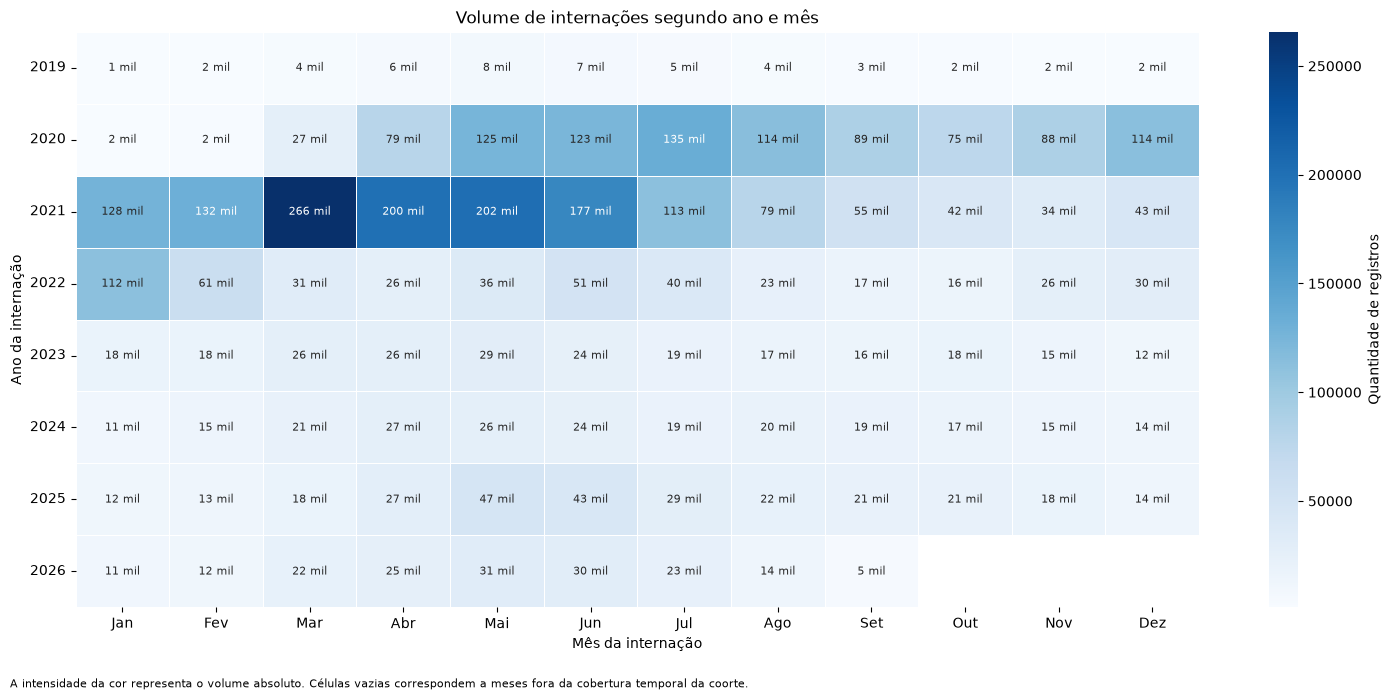

In [99]:
anotacoes_volume_ano_mes = (
    matriz_volume_ano_mes
    .copy()
    .astype("object")
)

for ano in matriz_volume_ano_mes.index:
    for mes in matriz_volume_ano_mes.columns:
        quantidade = (
            matriz_volume_ano_mes.loc[
                ano,
                mes,
            ]
        )

        if pd.isna(
            quantidade
        ):
            anotacao = ""
        else:
            quantidade_inteira = int(
                quantidade
            )

            if quantidade_inteira >= 1_000_000:
                anotacao = (
                    f"{quantidade_inteira / 1_000_000:.1f} mi"
                )
            elif quantidade_inteira >= 1_000:
                anotacao = (
                    f"{quantidade_inteira / 1_000:.0f} mil"
                )
            else:
                anotacao = str(
                    quantidade_inteira
                )

        anotacoes_volume_ano_mes.loc[
            ano,
            mes,
        ] = anotacao

figura_heatmap_volume, eixo_heatmap_volume = plt.subplots(
    figsize=(
        15,
        7,
    )
)

sns.heatmap(
    matriz_volume_ano_mes,
    annot=anotacoes_volume_ano_mes,
    fmt="",
    cmap="Blues",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Quantidade de registros",
    },
    annot_kws={
        "fontsize": 8,
    },
    ax=eixo_heatmap_volume,
)

eixo_heatmap_volume.set_title(
    "Volume de internações segundo ano e mês"
)

eixo_heatmap_volume.set_xlabel(
    "Mês da internação"
)

eixo_heatmap_volume.set_ylabel(
    "Ano da internação"
)

eixo_heatmap_volume.set_xticklabels(
    eixo_heatmap_volume.get_xticklabels(),
    rotation=0,
)

eixo_heatmap_volume.set_yticklabels(
    eixo_heatmap_volume.get_yticklabels(),
    rotation=0,
)

figura_heatmap_volume.text(
    0.01,
    0.01,
    (
        "A intensidade da cor representa o volume absoluto. "
        "Células vazias correspondem a meses fora da cobertura "
        "temporal da coorte."
    ),
    fontsize=8,
)

figura_heatmap_volume.tight_layout(
    rect=[
        0,
        0.04,
        1,
        1,
    ]
)

plt.show()

plt.close(
    figura_heatmap_volume
)

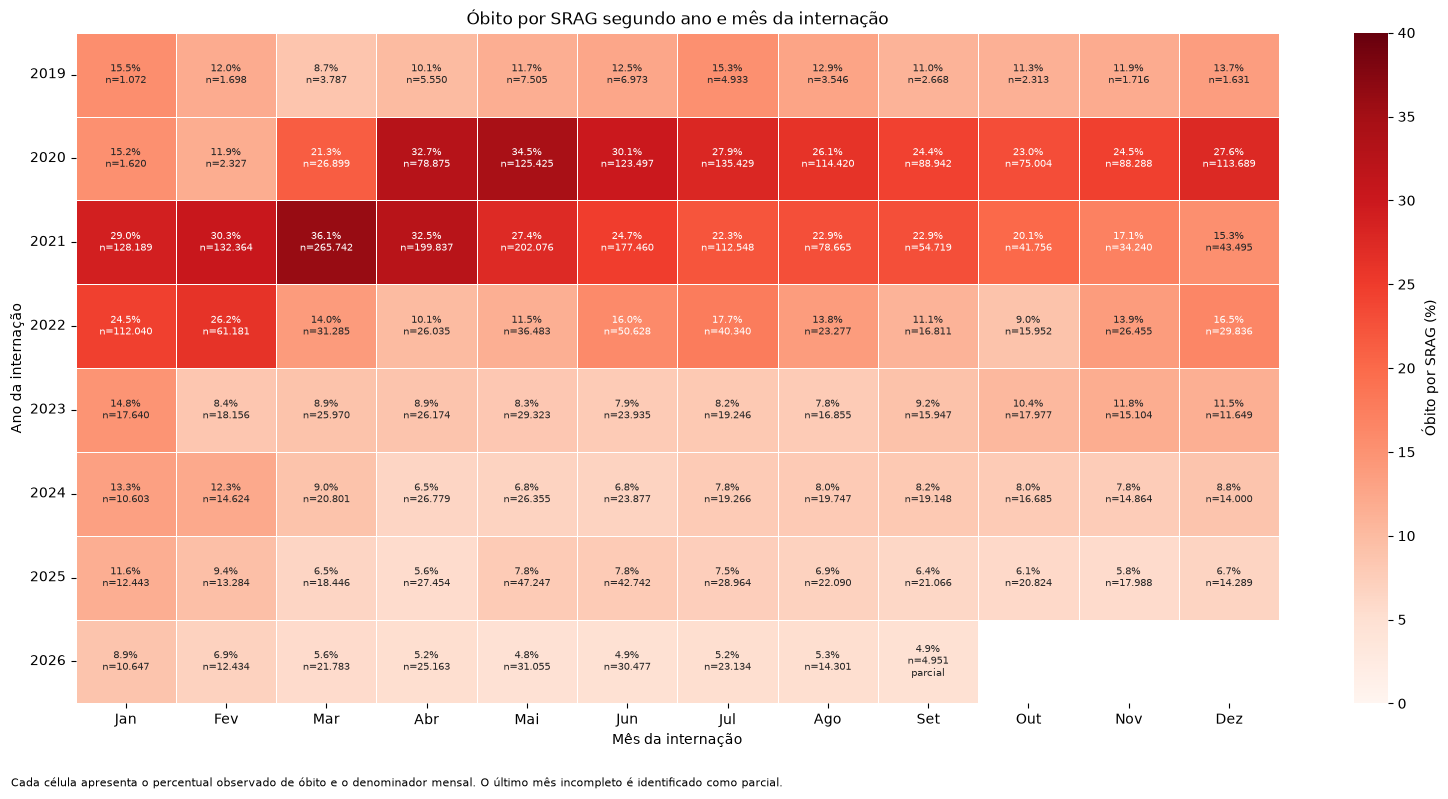

In [100]:
valor_maximo_obito_mensal = float(
    valores_obito_mensais.max()
)

limite_superior_escala_obito = max(
    10.0,
    float(
        np.ceil(
            valor_maximo_obito_mensal
            / 5
        )
        * 5
    ),
)

anotacoes_obito_ano_mes = (
    matriz_obito_ano_mes
    .copy()
    .astype("object")
)

for ano in matriz_obito_ano_mes.index:
    for mes in matriz_obito_ano_mes.columns:
        percentual = (
            matriz_obito_ano_mes.loc[
                ano,
                mes,
            ]
        )

        denominador = (
            matriz_denominador_ano_mes.loc[
                ano,
                mes,
            ]
        )

        mes_completo = (
            matriz_mes_completo_ano_mes.loc[
                ano,
                mes,
            ]
        )

        if pd.isna(
            percentual
        ):
            anotacao = ""
        else:
            percentual_formatado = (
                f"{float(percentual):.1f}%"
            )

            if pd.isna(
                denominador
            ):
                anotacao = percentual_formatado
            else:
                denominador_formatado = (
                    f"{int(denominador):,}"
                    .replace(
                        ",",
                        ".",
                    )
                )

                anotacao = (
                    f"{percentual_formatado}\n"
                    f"n={denominador_formatado}"
                )

                if (
                    not pd.isna(
                        mes_completo
                    )
                    and not bool(
                        mes_completo
                    )
                ):
                    anotacao = (
                        f"{anotacao}\n"
                        "parcial"
                    )

        anotacoes_obito_ano_mes.loc[
            ano,
            mes,
        ] = anotacao

figura_heatmap_obito, eixo_heatmap_obito = plt.subplots(
    figsize=(
        16,
        8,
    )
)

sns.heatmap(
    matriz_obito_ano_mes,
    annot=anotacoes_obito_ano_mes,
    fmt="",
    cmap="Reds",
    vmin=0,
    vmax=limite_superior_escala_obito,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Óbito por SRAG (%)",
    },
    annot_kws={
        "fontsize": 7,
    },
    ax=eixo_heatmap_obito,
)

eixo_heatmap_obito.set_title(
    "Óbito por SRAG segundo ano e mês da internação"
)

eixo_heatmap_obito.set_xlabel(
    "Mês da internação"
)

eixo_heatmap_obito.set_ylabel(
    "Ano da internação"
)

eixo_heatmap_obito.set_xticklabels(
    eixo_heatmap_obito.get_xticklabels(),
    rotation=0,
)

eixo_heatmap_obito.set_yticklabels(
    eixo_heatmap_obito.get_yticklabels(),
    rotation=0,
)

figura_heatmap_obito.text(
    0.01,
    0.01,
    (
        "Cada célula apresenta o percentual observado de óbito "
        "e o denominador mensal. O último mês incompleto é "
        "identificado como parcial."
    ),
    fontsize=8,
)

figura_heatmap_obito.tight_layout(
    rect=[
        0,
        0.04,
        1,
        1,
    ]
)

plt.show()

plt.close(
    figura_heatmap_obito
)

In [101]:
total_volume_matriz = int(
    matriz_volume_ano_mes
    .fillna(0)
    .to_numpy()
    .sum()
)

total_volume_serie = int(
    serie_mensal[
        "quantidade_registros"
    ]
    .sum()
)

if total_volume_matriz != total_volume_serie:
    raise RuntimeError(
        "A soma da matriz mensal de volume não corresponde "
        "ao total da série mensal."
    )

anos_matriz_volume = set(
    matriz_volume_ano_mes.index
    .astype(int)
    .tolist()
)

anos_matriz_obito = set(
    matriz_obito_ano_mes.index
    .astype(int)
    .tolist()
)

anos_serie_mensal = set(
    serie_mensal[
        "ano_internacao"
    ]
    .dropna()
    .astype(int)
    .tolist()
)

verificacoes_sazonalidade = {
    "serie_mensal_nao_vazia": (
        not serie_mensal.empty
    ),
    "matriz_volume_nao_vazia": (
        not matriz_volume_ano_mes.empty
    ),
    "matriz_obito_nao_vazia": (
        not matriz_obito_ano_mes.empty
    ),
    "matriz_volume_tem_12_meses": (
        matriz_volume_ano_mes.shape[1]
        == 12
    ),
    "matriz_obito_tem_12_meses": (
        matriz_obito_ano_mes.shape[1]
        == 12
    ),
    "volume_matriz_igual_serie": (
        total_volume_matriz
        == total_volume_serie
    ),
    "anos_volume_iguais_serie": (
        anos_matriz_volume
        == anos_serie_mensal
    ),
    "anos_obito_iguais_serie": (
        anos_matriz_obito
        == anos_serie_mensal
    ),
    "percentuais_obito_validos": (
        valores_obito_mensais
        .between(
            0,
            100,
            inclusive="both",
        )
        .all()
    ),
    "ordem_mensal_correta": (
        serie_mensal[
            "ano_mes_internacao"
        ]
        .is_monotonic_increasing
    ),
}

verificacoes_sazonalidade_df = pd.DataFrame(
    {
        "verificacao": list(
            verificacoes_sazonalidade.keys()
        ),
        "resultado": list(
            verificacoes_sazonalidade.values()
        ),
    }
)

display(
    verificacoes_sazonalidade_df
)

if not all(
    verificacoes_sazonalidade.values()
):
    falhas_sazonalidade = [
        verificacao
        for verificacao, resultado
        in verificacoes_sazonalidade.items()
        if not resultado
    ]

    raise RuntimeError(
        "A análise mensal e sazonal terminou com falhas: "
        f"{falhas_sazonalidade}"
    )

print(
    "Análise mensal e sazonal validada com sucesso."
)

,verificacao,resultado
0,serie_mensal_nao_vazia,True
1,matriz_volume_nao_vazia,True
2,matriz_obito_nao_vazia,True
3,matriz_volume_tem_12_meses,True
4,matriz_obito_tem_12_meses,True
5,volume_matriz_igual_serie,True
6,anos_volume_iguais_serie,True
7,anos_obito_iguais_serie,True
8,percentuais_obito_validos,True
9,ordem_mensal_correta,True


Análise mensal e sazonal validada com sucesso.


## 11. Preparação auditável das variáveis para clustering

O clustering será desenvolvido sem utilizar o desfecho, identificadores
ou informações posteriores à admissão.

A preparação será dividida em duas alternativas:

### Matriz clínica principal

Inclui características clínicas e demográficas disponíveis ou
deriváveis no momento da admissão:

- idade;
- sexo registrado;
- intervalo entre sintomas e internação;
- sintomas estruturados;
- comorbidades estruturadas;
- contadores clínicos derivados.

### Matriz ampliada

Acrescenta variáveis de contexto cuja cobertura e interpretação exigem
maior cautela:

- vacinação;
- escolaridade;
- UF de residência;
- características gestacionais, quando aplicáveis.

As variáveis serão classificadas antes da transformação. Nenhuma coluna
será incluída apenas por estar disponível no arquivo.

O desfecho será utilizado somente depois que a solução de clustering
estiver definida, para caracterização descritiva dos grupos.

In [102]:
COLUNAS_IDENTIFICADORAS = [
    "nu_notific",
    "id_registro",
    "arquivo_origem",
]

COLUNAS_DESFECHO = [
    "evolucao",
    "evolucao_normalizada",
    "alvo_obito_srag",
    "dt_evoluca",
    "dt_evoluca_convertida",
]

COLUNAS_POSTERIORES_ADMISSAO = [
    "uti",
    "dt_entuti",
    "dt_saiduti",
    "suport_ven",
    "antiviral",
    "tp_antivir",
    "out_antiv",
    "dt_antivir",
    "dt_antivir_convertida",
    "dt_encerra",
    "dt_encerra_convertida",
    "dt_digita",
    "dt_digita_convertida",
]

COLUNAS_TEMPORAIS_BRUTAS = [
    "dt_notific",
    "dt_notific_convertida",
    "dt_sin_pri",
    "dt_sin_pri_convertida",
    "dt_interna",
    "dt_interna_convertida",
]

COLUNAS_CONTEXTO_TEMPORAL = [
    "ano_internacao",
    "mes_internacao",
    "ano_notificacao",
    "ano_sintomas",
    "ano_mes_internacao",
    "periodo_incompleto",
]

COLUNAS_AUDITORIA_QUALIDADE = [
    "flag_internacao_antes_sintomas",
    "flag_notificacao_apos_internacao",
    "flag_notificacao_fora_periodo",
    "flag_sintomas_fora_periodo",
    "flag_dt_sin_pri_ausente",
    "flag_dt_notific_ausente",
    "flag_intervalo_negativo_sem_nosocomial",
    "flag_nu_notific_repetido",
    "flag_nu_notific_ausente",
    "quantidade_ocorrencias_nu_notific",
    "status_coorte",
    "data_corte_coorte",
]

COLUNAS_NUMERICAS_NUCLEO = [
    "idade_anos",
    "dias_sintomas_ate_internacao",
    "n_sintomas_confirmados",
    "n_sintomas_avaliados",
    "n_comorbidades_confirmadas",
    "n_comorbidades_avaliadas",
]

COLUNAS_CATEGORICAS_NUCLEO = [
    "sexo_categoria",
]

COLUNAS_BINARIAS_NUCLEO = list(
    dict.fromkeys(
        COLUNAS_SINTOMAS
        + COLUNAS_COMORBIDADES
    )
)

COLUNAS_NUMERICAS_AMPLIADAS = []

COLUNAS_CATEGORICAS_AMPLIADAS = [
    "cs_escol_n",
    "uf_residencia_categoria",
]

COLUNAS_BINARIAS_AMPLIADAS = list(
    dict.fromkeys(
        COLUNAS_VACINACAO
    )
)

COLUNAS_CANDIDATAS_NUCLEO = list(
    dict.fromkeys(
        COLUNAS_NUMERICAS_NUCLEO
        + COLUNAS_CATEGORICAS_NUCLEO
        + COLUNAS_BINARIAS_NUCLEO
    )
)

COLUNAS_CANDIDATAS_AMPLIADAS = list(
    dict.fromkeys(
        COLUNAS_CANDIDATAS_NUCLEO
        + COLUNAS_NUMERICAS_AMPLIADAS
        + COLUNAS_CATEGORICAS_AMPLIADAS
        + COLUNAS_BINARIAS_AMPLIADAS
    )
)

grupos_inventario_clustering = {
    "candidata_numerica_nucleo": (
        COLUNAS_NUMERICAS_NUCLEO
    ),
    "candidata_categorica_nucleo": (
        COLUNAS_CATEGORICAS_NUCLEO
    ),
    "candidata_binaria_nucleo": (
        COLUNAS_BINARIAS_NUCLEO
    ),
    "candidata_numerica_ampliada": (
        COLUNAS_NUMERICAS_AMPLIADAS
    ),
    "candidata_categorica_ampliada": (
        COLUNAS_CATEGORICAS_AMPLIADAS
    ),
    "candidata_binaria_ampliada": (
        COLUNAS_BINARIAS_AMPLIADAS
    ),
    "identificador": (
        COLUNAS_IDENTIFICADORAS
    ),
    "desfecho": (
        COLUNAS_DESFECHO
    ),
    "posterior_admissao": (
        COLUNAS_POSTERIORES_ADMISSAO
    ),
    "data_bruta": (
        COLUNAS_TEMPORAIS_BRUTAS
    ),
    "contexto_temporal": (
        COLUNAS_CONTEXTO_TEMPORAL
    ),
    "auditoria_qualidade": (
        COLUNAS_AUDITORIA_QUALIDADE
    ),
}

registros_inventario_clustering = []

for classificacao, colunas_classificacao in (
    grupos_inventario_clustering.items()
):
    for coluna in colunas_classificacao:
        registros_inventario_clustering.append(
            {
                "coluna": coluna,
                "classificacao": classificacao,
                "existe_na_coorte": (
                    coluna in coorte.columns
                ),
                "tipo_pandas": (
                    str(
                        coorte[
                            coluna
                        ].dtype
                    )
                    if coluna in coorte.columns
                    else pd.NA
                ),
                "quantidade_preenchida": (
                    int(
                        coorte[
                            coluna
                        ]
                        .notna()
                        .sum()
                    )
                    if coluna in coorte.columns
                    else 0
                ),
                "quantidade_ausente": (
                    int(
                        coorte[
                            coluna
                        ]
                        .isna()
                        .sum()
                    )
                    if coluna in coorte.columns
                    else 0
                ),
                "quantidade_valores_distintos": (
                    int(
                        coorte[
                            coluna
                        ]
                        .nunique(
                            dropna=True
                        )
                    )
                    if coluna in coorte.columns
                    else 0
                ),
            }
        )

inventario_clustering = pd.DataFrame(
    registros_inventario_clustering
)

inventario_clustering = (
    inventario_clustering
    .drop_duplicates(
        subset=[
            "coluna",
            "classificacao",
        ],
        keep="first",
    )
    .reset_index(drop=True)
)

inventario_clustering[
    "percentual_preenchido"
] = (
    inventario_clustering[
        "quantidade_preenchida"
    ]
    .div(
        len(
            coorte
        )
    )
    .mul(100)
)

inventario_clustering[
    "incluir_matriz_nucleo"
] = (
    inventario_clustering[
        "classificacao"
    ]
    .isin(
        [
            "candidata_numerica_nucleo",
            "candidata_categorica_nucleo",
            "candidata_binaria_nucleo",
        ]
    )
    & inventario_clustering[
        "existe_na_coorte"
    ]
)

inventario_clustering[
    "incluir_matriz_ampliada"
] = (
    inventario_clustering[
        "classificacao"
    ]
    .str.startswith(
        "candidata_"
    )
    & inventario_clustering[
        "existe_na_coorte"
    ]
)

inventario_clustering[
    "motivo_nao_inclusao"
] = pd.NA

inventario_clustering.loc[
    inventario_clustering[
        "existe_na_coorte"
    ]
    .eq(False),
    "motivo_nao_inclusao",
] = "coluna_ausente_na_coorte"

inventario_clustering.loc[
    inventario_clustering[
        "classificacao"
    ]
    .eq("identificador"),
    "motivo_nao_inclusao",
] = "identificador_sem_significado_clinico"

inventario_clustering.loc[
    inventario_clustering[
        "classificacao"
    ]
    .eq("desfecho"),
    "motivo_nao_inclusao",
] = "desfecho_excluido_da_formacao_dos_clusters"

inventario_clustering.loc[
    inventario_clustering[
        "classificacao"
    ]
    .eq("posterior_admissao"),
    "motivo_nao_inclusao",
] = "informacao_posterior_a_admissao"

inventario_clustering.loc[
    inventario_clustering[
        "classificacao"
    ]
    .eq("data_bruta"),
    "motivo_nao_inclusao",
] = "data_bruta_substituida_por_atributo_derivado"

inventario_clustering.loc[
    inventario_clustering[
        "classificacao"
    ]
    .eq("contexto_temporal"),
    "motivo_nao_inclusao",
] = "contexto_temporal_reservado_para_caracterizacao"

inventario_clustering.loc[
    inventario_clustering[
        "classificacao"
    ]
    .eq("auditoria_qualidade"),
    "motivo_nao_inclusao",
] = "variavel_reservada_para_auditoria"

duplicidades_inventario = (
    inventario_clustering.groupby(
        "coluna",
        dropna=False,
    )[
        "classificacao"
    ]
    .nunique()
)

colunas_com_classificacoes_multiplas = (
    duplicidades_inventario.loc[
        duplicidades_inventario.gt(1)
    ]
    .index
    .tolist()
)

if colunas_com_classificacoes_multiplas:
    display(
        inventario_clustering.loc[
            inventario_clustering[
                "coluna"
            ].isin(
                colunas_com_classificacoes_multiplas
            )
        ]
        .sort_values(
            [
                "coluna",
                "classificacao",
            ]
        )
        .reset_index(drop=True)
    )

    raise RuntimeError(
        "Existem colunas classificadas em mais de um grupo: "
        f"{colunas_com_classificacoes_multiplas}"
    )

colunas_nucleo_disponiveis = (
    inventario_clustering.loc[
        inventario_clustering[
            "incluir_matriz_nucleo"
        ],
        "coluna",
    ]
    .tolist()
)

colunas_ampliadas_disponiveis = (
    inventario_clustering.loc[
        inventario_clustering[
            "incluir_matriz_ampliada"
        ],
        "coluna",
    ]
    .tolist()
)

colunas_excluidas_clustering = (
    inventario_clustering.loc[
        inventario_clustering[
            "incluir_matriz_ampliada"
        ]
        .eq(False),
        "coluna",
    ]
    .drop_duplicates()
    .tolist()
)

COLUNAS_PROIBIDAS_CLUSTERING = set(
    COLUNAS_IDENTIFICADORAS
    + COLUNAS_DESFECHO
    + COLUNAS_POSTERIORES_ADMISSAO
)

colunas_proibidas_no_nucleo = sorted(
    set(
        colunas_nucleo_disponiveis
    )
    .intersection(
        COLUNAS_PROIBIDAS_CLUSTERING
    )
)

colunas_proibidas_na_ampliada = sorted(
    set(
        colunas_ampliadas_disponiveis
    )
    .intersection(
        COLUNAS_PROIBIDAS_CLUSTERING
    )
)

if colunas_proibidas_no_nucleo:
    raise RuntimeError(
        "A matriz núcleo contém colunas proibidas: "
        f"{colunas_proibidas_no_nucleo}"
    )

if colunas_proibidas_na_ampliada:
    raise RuntimeError(
        "A matriz ampliada contém colunas proibidas: "
        f"{colunas_proibidas_na_ampliada}"
    )

if not colunas_nucleo_disponiveis:
    raise ValueError(
        "Nenhuma variável foi selecionada para a matriz núcleo."
    )

if not colunas_ampliadas_disponiveis:
    raise ValueError(
        "Nenhuma variável foi selecionada para a matriz ampliada."
    )

resumo_inventario_clustering = (
    inventario_clustering.groupby(
        "classificacao",
        dropna=False,
    )
    .agg(
        quantidade_variaveis=(
            "coluna",
            "nunique",
        ),
        quantidade_disponiveis=(
            "existe_na_coorte",
            "sum",
        ),
        preenchimento_mediano=(
            "percentual_preenchido",
            "median",
        ),
    )
    .reset_index()
    .sort_values(
        "classificacao"
    )
    .reset_index(drop=True)
)

print(
    "Variáveis disponíveis na matriz núcleo:",
    len(
        colunas_nucleo_disponiveis
    ),
)

print(
    "Variáveis disponíveis na matriz ampliada:",
    len(
        colunas_ampliadas_disponiveis
    ),
)

print(
    "Colunas excluídas ou reservadas para auditoria:",
    len(
        colunas_excluidas_clustering
    ),
)

display(
    resumo_inventario_clustering
)

display(
    inventario_clustering.sort_values(
        [
            "classificacao",
            "coluna",
        ]
    )
    .reset_index(drop=True)
)

Variáveis disponíveis na matriz núcleo: 33
Variáveis disponíveis na matriz ampliada: 37
Colunas excluídas ou reservadas para auditoria: 45


,classificacao,quantidade_variaveis,quantidade_disponiveis,preenchimento_mediano
0,auditoria_qualidade,12,1,0.000000
1,candidata_binaria_ampliada,2,2,72.189327
2,candidata_binaria_nucleo,26,26,54.358555
3,candidata_categorica_ampliada,2,2,83.803216
4,candidata_categorica_nucleo,1,1,100.000000
5,candidata_numerica_nucleo,6,6,100.000000
6,contexto_temporal,6,3,50.000000
7,data_bruta,6,4,100.000000
8,desfecho,5,2,0.000000
9,identificador,3,1,0.000000


,coluna,classificacao,existe_na_coorte,tipo_pandas,quantidade_preenchida,quantidade_ausente,quantidade_valores_distintos,percentual_preenchido,incluir_matriz_nucleo,incluir_matriz_ampliada,motivo_nao_inclusao
0,data_corte_coorte,auditoria_qualidade,False,NaN,0,0,0,0.0,False,False,variavel_reservada_para_auditoria
1,flag_dt_notific_ausente,auditoria_qualidade,False,NaN,0,0,0,0.0,False,False,variavel_reservada_para_auditoria
2,flag_dt_sin_pri_ausente,auditoria_qualidade,False,NaN,0,0,0,0.0,False,False,variavel_reservada_para_auditoria
3,flag_internacao_antes_sintomas,auditoria_qualidade,True,int8,3884728,0,1,100.0,False,False,variavel_reservada_para_auditoria
4,flag_intervalo_negativo_sem_nosocomial,auditoria_qualidade,False,NaN,0,0,0,0.0,False,False,variavel_reservada_para_auditoria
...,...,...,...,...,...,...,...,...,...,...,...
77,dt_saiduti,posterior_admissao,False,NaN,0,0,0,0.0,False,False,informacao_posterior_a_admissao
78,out_antiv,posterior_admissao,False,NaN,0,0,0,0.0,False,False,informacao_posterior_a_admissao
79,suport_ven,posterior_admissao,False,NaN,0,0,0,0.0,False,False,informacao_posterior_a_admissao
80,tp_antivir,posterior_admissao,False,NaN,0,0,0,0.0,False,False,informacao_posterior_a_admissao


### Contrato de transformação das variáveis

Antes de materializar a matriz de clustering, cada variável candidata
receberá uma regra explícita de transformação.

O contrato distinguirá:

- variáveis numéricas;
- respostas clínicas binárias;
- categorias nominais;
- indicadores de ausência;
- variáveis reservadas para caracterização;
- variáveis excluídas da formação dos clusters.

As respostas clínicas serão transformadas da seguinte forma:

- sim: 1;
- não: 0;
- ignorado: ausente;
- valor ausente: ausente;
- código inesperado: ausente e sinalizado na auditoria.

A imputação e a padronização serão definidas somente depois da análise
de cobertura e distribuição das variáveis transformadas.

In [103]:
COLUNAS_CONTRATO_CLUSTERING = [
    "coluna",
    "classificacao",
    "existe_na_coorte",
    "tipo_pandas",
    "quantidade_preenchida",
    "quantidade_ausente",
    "quantidade_valores_distintos",
    "percentual_preenchido",
    "incluir_matriz_nucleo",
    "incluir_matriz_ampliada",
    "motivo_nao_inclusao",
]

colunas_contrato_ausentes = [
    coluna
    for coluna in COLUNAS_CONTRATO_CLUSTERING
    if coluna not in inventario_clustering.columns
]

if colunas_contrato_ausentes:
    raise KeyError(
        "O inventário do clustering não contém "
        "as colunas necessárias: "
        f"{colunas_contrato_ausentes}"
    )

contrato_transformacao = (
    inventario_clustering[
        COLUNAS_CONTRATO_CLUSTERING
    ]
    .copy()
)

contrato_transformacao[
    "papel_na_matriz"
] = "excluida"

contrato_transformacao.loc[
    contrato_transformacao[
        "classificacao"
    ]
    .eq(
        "candidata_numerica_nucleo"
    ),
    "papel_na_matriz",
] = "numerica"

contrato_transformacao.loc[
    contrato_transformacao[
        "classificacao"
    ]
    .eq(
        "candidata_binaria_nucleo"
    ),
    "papel_na_matriz",
] = "binaria_clinica"

contrato_transformacao.loc[
    contrato_transformacao[
        "classificacao"
    ]
    .eq(
        "candidata_categorica_nucleo"
    ),
    "papel_na_matriz",
] = "categorica_nominal"

contrato_transformacao.loc[
    contrato_transformacao[
        "classificacao"
    ]
    .eq(
        "candidata_numerica_ampliada"
    ),
    "papel_na_matriz",
] = "numerica"

contrato_transformacao.loc[
    contrato_transformacao[
        "classificacao"
    ]
    .eq(
        "candidata_binaria_ampliada"
    ),
    "papel_na_matriz",
] = "binaria_contexto"

contrato_transformacao.loc[
    contrato_transformacao[
        "classificacao"
    ]
    .eq(
        "candidata_categorica_ampliada"
    ),
    "papel_na_matriz",
] = "categorica_nominal"

contrato_transformacao[
    "transformacao_planejada"
] = "nao_aplicavel"

contrato_transformacao.loc[
    contrato_transformacao[
        "papel_na_matriz"
    ]
    .eq(
        "numerica"
    ),
    "transformacao_planejada",
] = "conversao_numerica_e_padronizacao"

contrato_transformacao.loc[
    contrato_transformacao[
        "papel_na_matriz"
    ]
    .eq(
        "binaria_clinica"
    ),
    "transformacao_planejada",
] = "sim_1_nao_0_demais_ausente"

contrato_transformacao.loc[
    contrato_transformacao[
        "papel_na_matriz"
    ]
    .eq(
        "binaria_contexto"
    ),
    "transformacao_planejada",
] = "sim_1_nao_0_demais_ausente"

contrato_transformacao.loc[
    contrato_transformacao[
        "papel_na_matriz"
    ]
    .eq(
        "categorica_nominal"
    ),
    "transformacao_planejada",
] = "codificacao_one_hot"

contrato_transformacao[
    "tratamento_ausencia_planejado"
] = "nao_aplicavel"

contrato_transformacao.loc[
    contrato_transformacao[
        "papel_na_matriz"
    ]
    .eq(
        "numerica"
    ),
    "tratamento_ausencia_planejado",
] = "avaliar_mediana_e_indicador_ausencia"

contrato_transformacao.loc[
    contrato_transformacao[
        "papel_na_matriz"
    ]
    .isin(
        [
            "binaria_clinica",
            "binaria_contexto",
        ]
    ),
    "tratamento_ausencia_planejado",
] = "avaliar_indicador_ausencia"

contrato_transformacao.loc[
    contrato_transformacao[
        "papel_na_matriz"
    ]
    .eq(
        "categorica_nominal"
    ),
    "tratamento_ausencia_planejado",
] = "categoria_ausente_explicita"

contrato_transformacao[
    "exige_padronizacao"
] = (
    contrato_transformacao[
        "papel_na_matriz"
    ]
    .eq(
        "numerica"
    )
)

contrato_transformacao[
    "exige_codificacao"
] = (
    contrato_transformacao[
        "papel_na_matriz"
    ]
    .isin(
        [
            "binaria_clinica",
            "binaria_contexto",
            "categorica_nominal",
        ]
    )
)

contrato_transformacao[
    "matriz_prevista"
] = "nenhuma"

contrato_transformacao.loc[
    contrato_transformacao[
        "incluir_matriz_nucleo"
    ],
    "matriz_prevista",
] = "nucleo_e_ampliada"

contrato_transformacao.loc[
    contrato_transformacao[
        "incluir_matriz_ampliada"
    ]
    & contrato_transformacao[
        "incluir_matriz_nucleo"
    ]
    .eq(False),
    "matriz_prevista",
] = "somente_ampliada"

contrato_transformacao[
    "flag_baixa_cobertura_50"
] = (
    contrato_transformacao[
        "percentual_preenchido"
    ]
    .lt(50)
    & contrato_transformacao[
        "incluir_matriz_ampliada"
    ]
)

contrato_transformacao[
    "flag_cardinalidade_alta"
] = (
    contrato_transformacao[
        "quantidade_valores_distintos"
    ]
    .gt(30)
    & contrato_transformacao[
        "papel_na_matriz"
    ]
    .eq(
        "categorica_nominal"
    )
)

contrato_transformacao[
    "status_revisao"
] = "aprovada_para_preparacao"

contrato_transformacao.loc[
    contrato_transformacao[
        "incluir_matriz_ampliada"
    ]
    .eq(False),
    "status_revisao",
] = "fora_da_matriz"

contrato_transformacao.loc[
    contrato_transformacao[
        "incluir_matriz_ampliada"
    ]
    & contrato_transformacao[
        "existe_na_coorte"
    ]
    .eq(False),
    "status_revisao",
] = "coluna_ausente"

contrato_transformacao.loc[
    contrato_transformacao[
        "flag_cardinalidade_alta"
    ],
    "status_revisao",
] = "revisar_cardinalidade"

contrato_transformacao.loc[
    contrato_transformacao[
        "flag_baixa_cobertura_50"
    ],
    "status_revisao",
] = "revisar_cobertura"

COLUNAS_PROIBIDAS_CONTRATO = set(
    COLUNAS_IDENTIFICADORAS
    + COLUNAS_DESFECHO
    + COLUNAS_POSTERIORES_ADMISSAO
)

colunas_proibidas_aprovadas = sorted(
    set(
        contrato_transformacao.loc[
            contrato_transformacao[
                "status_revisao"
            ]
            .isin(
                [
                    "aprovada_para_preparacao",
                    "revisar_cardinalidade",
                    "revisar_cobertura",
                ]
            ),
            "coluna",
        ]
        .tolist()
    )
    .intersection(
        COLUNAS_PROIBIDAS_CONTRATO
    )
)

if colunas_proibidas_aprovadas:
    raise RuntimeError(
        "O contrato aprovou colunas proibidas: "
        f"{colunas_proibidas_aprovadas}"
    )

candidatas_sem_transformacao = (
    contrato_transformacao.loc[
        contrato_transformacao[
            "incluir_matriz_ampliada"
        ]
        & contrato_transformacao[
            "transformacao_planejada"
        ]
        .eq(
            "nao_aplicavel"
        ),
        "coluna",
    ]
    .tolist()
)

if candidatas_sem_transformacao:
    raise RuntimeError(
        "Existem variáveis candidatas sem transformação definida: "
        f"{candidatas_sem_transformacao}"
    )

resumo_contrato_transformacao = (
    contrato_transformacao.groupby(
        [
            "matriz_prevista",
            "papel_na_matriz",
            "status_revisao",
        ],
        dropna=False,
    )
    .agg(
        quantidade_variaveis=(
            "coluna",
            "nunique",
        ),
        cobertura_mediana=(
            "percentual_preenchido",
            "median",
        ),
        cardinalidade_maxima=(
            "quantidade_valores_distintos",
            "max",
        ),
    )
    .reset_index()
    .sort_values(
        [
            "matriz_prevista",
            "papel_na_matriz",
            "status_revisao",
        ]
    )
    .reset_index(drop=True)
)

variaveis_para_revisao = (
    contrato_transformacao.loc[
        contrato_transformacao[
            "status_revisao"
        ]
        .isin(
            [
                "revisar_cardinalidade",
                "revisar_cobertura",
            ]
        )
    ]
    .sort_values(
        [
            "status_revisao",
            "percentual_preenchido",
            "coluna",
        ]
    )
    .reset_index(drop=True)
)

print(
    "Variáveis aprovadas para preparação:",
    int(
        contrato_transformacao[
            "status_revisao"
        ]
        .eq(
            "aprovada_para_preparacao"
        )
        .sum()
    ),
)

print(
    "Variáveis marcadas para revisão:",
    len(
        variaveis_para_revisao
    ),
)

display(
    resumo_contrato_transformacao
)

display(
    variaveis_para_revisao[
        [
            "coluna",
            "classificacao",
            "papel_na_matriz",
            "matriz_prevista",
            "percentual_preenchido",
            "quantidade_valores_distintos",
            "status_revisao",
            "transformacao_planejada",
            "tratamento_ausencia_planejado",
        ]
    ]
)

Variáveis aprovadas para preparação: 24
Variáveis marcadas para revisão: 13


,matriz_prevista,papel_na_matriz,status_revisao,quantidade_variaveis,cobertura_mediana,cardinalidade_maxima
0,nenhuma,excluida,fora_da_matriz,45,0.000000,3884725
1,nucleo_e_ampliada,binaria_clinica,aprovada_para_preparacao,13,73.850782,3
2,nucleo_e_ampliada,binaria_clinica,revisar_cobertura,13,37.151147,3
3,nucleo_e_ampliada,categorica_nominal,aprovada_para_preparacao,1,100.000000,3
4,nucleo_e_ampliada,numerica,aprovada_para_preparacao,6,100.000000,193
5,somente_ampliada,binaria_contexto,aprovada_para_preparacao,2,72.189327,3
6,somente_ampliada,categorica_nominal,aprovada_para_preparacao,2,83.803216,28


,coluna,classificacao,papel_na_matriz,matriz_prevista,percentual_preenchido,quantidade_valores_distintos,status_revisao,transformacao_planejada,tratamento_ausencia_planejado
0,puerpera,candidata_binaria_nucleo,binaria_clinica,nucleo_e_ampliada,35.979507,3,revisar_cobertura,sim_1_nao_0_demais_ausente,avaliar_indicador_ausencia
1,hepatica,candidata_binaria_nucleo,binaria_clinica,nucleo_e_ampliada,36.026666,3,revisar_cobertura,sim_1_nao_0_demais_ausente,avaliar_indicador_ausencia
2,sind_down,candidata_binaria_nucleo,binaria_clinica,nucleo_e_ampliada,36.054313,3,revisar_cobertura,sim_1_nao_0_demais_ausente,avaliar_indicador_ausencia
3,hematologi,candidata_binaria_nucleo,binaria_clinica,nucleo_e_ampliada,36.164849,3,revisar_cobertura,sim_1_nao_0_demais_ausente,avaliar_indicador_ausencia
4,imunodepre,candidata_binaria_nucleo,binaria_clinica,nucleo_e_ampliada,36.598882,3,revisar_cobertura,sim_1_nao_0_demais_ausente,avaliar_indicador_ausencia
5,renal,candidata_binaria_nucleo,binaria_clinica,nucleo_e_ampliada,36.713098,3,revisar_cobertura,sim_1_nao_0_demais_ausente,avaliar_indicador_ausencia
6,neurologic,candidata_binaria_nucleo,binaria_clinica,nucleo_e_ampliada,37.151147,3,revisar_cobertura,sim_1_nao_0_demais_ausente,avaliar_indicador_ausencia
7,asma,candidata_binaria_nucleo,binaria_clinica,nucleo_e_ampliada,37.169295,3,revisar_cobertura,sim_1_nao_0_demais_ausente,avaliar_indicador_ausencia
8,pneumopati,candidata_binaria_nucleo,binaria_clinica,nucleo_e_ampliada,37.178279,3,revisar_cobertura,sim_1_nao_0_demais_ausente,avaliar_indicador_ausencia
9,obesidade,candidata_binaria_nucleo,binaria_clinica,nucleo_e_ampliada,37.308120,3,revisar_cobertura,sim_1_nao_0_demais_ausente,avaliar_indicador_ausencia


### Amostra de desenvolvimento para clustering

A escolha das transformações, do número de clusters e dos métodos de
agrupamento será desenvolvida sobre uma amostra reprodutível.

A amostra será estratificada pelo ano da internação para evitar que os
anos com maior volume dominem integralmente os diagnósticos.

A seleção não utilizará o desfecho. O alvo será preservado somente em
uma tabela auxiliar para caracterização posterior dos clusters.

A amostra de desenvolvimento não substitui a aplicação posterior da
solução escolhida à população analítica completa.

In [104]:
SEMENTE_CLUSTERING = 42

QUANTIDADE_MAXIMA_POR_ANO = 10_000

COLUNAS_AMOSTRA_NECESSARIAS = [
    "ano_internacao",
    "alvo_obito_srag",
]

colunas_amostra_ausentes = [
    coluna
    for coluna in COLUNAS_AMOSTRA_NECESSARIAS
    if coluna not in coorte.columns
]

if colunas_amostra_ausentes:
    raise KeyError(
        "A coorte não contém as colunas necessárias "
        "para a amostragem: "
        f"{colunas_amostra_ausentes}"
    )

if QUANTIDADE_MAXIMA_POR_ANO <= 0:
    raise ValueError(
        "A quantidade máxima por ano deve ser positiva."
    )

anos_disponiveis_amostra = (
    coorte[
        "ano_internacao"
    ]
    .dropna()
    .astype(int)
    .sort_values()
    .unique()
    .tolist()
)

if not anos_disponiveis_amostra:
    raise ValueError(
        "Nenhum ano de internação está disponível "
        "para a amostragem."
    )

indices_amostra_por_ano = []

resumo_amostragem_registros = []

for ano in anos_disponiveis_amostra:
    indices_ano = (
        coorte.index[
            coorte[
                "ano_internacao"
            ]
            .astype("Int64")
            .eq(
                ano
            )
        ]
    )

    quantidade_disponivel = len(
        indices_ano
    )

    quantidade_selecionada = min(
        quantidade_disponivel,
        QUANTIDADE_MAXIMA_POR_ANO,
    )

    if quantidade_selecionada == 0:
        continue

    indices_selecionados_ano = (
        pd.Series(
            indices_ano,
            dtype="int64",
        )
        .sample(
            n=quantidade_selecionada,
            replace=False,
            random_state=(
                SEMENTE_CLUSTERING
                + int(
                    ano
                )
            ),
        )
        .sort_values()
        .tolist()
    )

    indices_amostra_por_ano.extend(
        indices_selecionados_ano
    )

    resumo_amostragem_registros.append(
        {
            "ano_internacao": int(
                ano
            ),
            "quantidade_disponivel": int(
                quantidade_disponivel
            ),
            "quantidade_selecionada": int(
                quantidade_selecionada
            ),
        }
    )

if not indices_amostra_por_ano:
    raise ValueError(
        "Nenhum registro foi selecionado para "
        "a amostra de desenvolvimento."
    )

if len(
    indices_amostra_por_ano
) != len(
    set(
        indices_amostra_por_ano
    )
):
    raise RuntimeError(
        "Foram encontrados índices duplicados "
        "na amostra de desenvolvimento."
    )

COLUNAS_RASTREABILIDADE_AMOSTRA = [
    "ano_internacao",
    "mes_internacao",
    "alvo_obito_srag",
]

COLUNAS_RASTREABILIDADE_DISPONIVEIS = [
    coluna
    for coluna in COLUNAS_RASTREABILIDADE_AMOSTRA
    if coluna in coorte.columns
]

COLUNAS_AMOSTRA_DESENVOLVIMENTO = list(
    dict.fromkeys(
        colunas_ampliadas_disponiveis
        + COLUNAS_RASTREABILIDADE_DISPONIVEIS
    )
)

amostra_desenvolvimento = (
    coorte.loc[
        indices_amostra_por_ano,
        COLUNAS_AMOSTRA_DESENVOLVIMENTO,
    ]
    .copy()
)

amostra_desenvolvimento.insert(
    0,
    "indice_coorte",
    indices_amostra_por_ano,
)

amostra_desenvolvimento = (
    amostra_desenvolvimento
    .sort_values(
        [
            "ano_internacao",
            "indice_coorte",
        ]
    )
    .reset_index(drop=True)
)

resumo_amostragem = pd.DataFrame(
    resumo_amostragem_registros
)

resumo_amostragem[
    "percentual_amostrado_no_ano"
] = (
    resumo_amostragem[
        "quantidade_selecionada"
    ]
    .div(
        resumo_amostragem[
            "quantidade_disponivel"
        ]
    )
    .mul(100)
)

resumo_amostragem[
    "percentual_da_amostra"
] = (
    resumo_amostragem[
        "quantidade_selecionada"
    ]
    .div(
        len(
            amostra_desenvolvimento
        )
    )
    .mul(100)
)

resumo_amostragem = (
    resumo_amostragem
    .sort_values(
        "ano_internacao"
    )
    .reset_index(drop=True)
)

quantidade_esperada_amostra = int(
    resumo_amostragem[
        "quantidade_selecionada"
    ]
    .sum()
)

if quantidade_esperada_amostra != len(
    amostra_desenvolvimento
):
    raise RuntimeError(
        "A quantidade registrada no resumo da amostragem "
        "não corresponde ao tamanho da amostra."
    )

anos_presentes_amostra = set(
    amostra_desenvolvimento[
        "ano_internacao"
    ]
    .dropna()
    .astype(int)
    .tolist()
)

if anos_presentes_amostra != set(
    anos_disponiveis_amostra
):
    raise RuntimeError(
        "A amostra não preservou todos os anos disponíveis."
    )

if not amostra_desenvolvimento[
    "indice_coorte"
].is_unique:
    raise RuntimeError(
        "O identificador de rastreabilidade da amostra "
        "não é único."
    )

colunas_proibidas_na_amostra = sorted(
    set(
        COLUNAS_AMOSTRA_DESENVOLVIMENTO
    )
    .intersection(
        set(
            COLUNAS_IDENTIFICADORAS
            + COLUNAS_POSTERIORES_ADMISSAO
        )
    )
)

if colunas_proibidas_na_amostra:
    raise RuntimeError(
        "A amostra contém colunas proibidas: "
        f"{colunas_proibidas_na_amostra}"
    )

if "alvo_obito_srag" not in (
    amostra_desenvolvimento.columns
):
    raise KeyError(
        "O alvo auxiliar não foi preservado "
        "para caracterização posterior."
    )

COLUNAS_FEATURES_AMOSTRA = [
    coluna
    for coluna in colunas_ampliadas_disponiveis
    if coluna in amostra_desenvolvimento.columns
]

if "alvo_obito_srag" in COLUNAS_FEATURES_AMOSTRA:
    raise RuntimeError(
        "O alvo foi incluído indevidamente "
        "na lista de features."
    )

if "ano_internacao" in COLUNAS_FEATURES_AMOSTRA:
    raise RuntimeError(
        "O ano da internação foi incluído indevidamente "
        "na lista de features."
    )

if not COLUNAS_FEATURES_AMOSTRA:
    raise ValueError(
        "Nenhuma feature foi preservada "
        "na amostra de desenvolvimento."
    )

metadados_amostra_desenvolvimento = pd.DataFrame(
    {
        "indice_coorte": (
            amostra_desenvolvimento[
                "indice_coorte"
            ]
        ),
        "ano_internacao": (
            amostra_desenvolvimento[
                "ano_internacao"
            ]
        ),
        "alvo_obito_srag": (
            amostra_desenvolvimento[
                "alvo_obito_srag"
            ]
        ),
    }
)

if "mes_internacao" in (
    amostra_desenvolvimento.columns
):
    metadados_amostra_desenvolvimento[
        "mes_internacao"
    ] = (
        amostra_desenvolvimento[
            "mes_internacao"
        ]
    )

display(
    resumo_amostragem
)

print(
    "Quantidade total da amostra:",
    len(
        amostra_desenvolvimento
    ),
)

print(
    "Quantidade de features brutas:",
    len(
        COLUNAS_FEATURES_AMOSTRA
    ),
)

print(
    "Quantidade de anos preservados:",
    len(
        anos_presentes_amostra
    ),
)

print(
    "Semente utilizada:",
    SEMENTE_CLUSTERING,
)

,ano_internacao,quantidade_disponivel,quantidade_selecionada,percentual_amostrado_no_ano,percentual_da_amostra
0,2019,43392,10000,23.045723,12.5
1,2020,974415,10000,1.026257,12.5
2,2021,1471091,10000,0.679768,12.5
3,2022,470323,10000,2.126198,12.5
4,2023,237976,10000,4.202104,12.5
5,2024,226749,10000,4.410163,12.5
6,2025,286837,10000,3.486301,12.5
7,2026,173945,10000,5.748944,12.5


Quantidade total da amostra: 80000
Quantidade de features brutas: 37
Quantidade de anos preservados: 8
Semente utilizada: 42


### Transformação bruta da amostra

As variáveis candidatas serão convertidas para representações adequadas
ao clustering, mas ainda sem imputação ou padronização.

Nesta etapa:

- variáveis numéricas serão convertidas para tipo numérico;
- respostas clínicas e de vacinação serão convertidas em 1 para sim e
  0 para não;
- respostas ignoradas, ausentes ou inesperadas permanecerão ausentes;
- categorias nominais serão normalizadas como texto;
- o alvo e as variáveis temporais de caracterização permanecerão fora
  das matrizes.

A matriz núcleo e a matriz ampliada permanecerão separadas para permitir
a comparação posterior entre uma solução clínica mais simples e uma
solução com variáveis adicionais de contexto.

In [105]:
if "amostra_desenvolvimento" not in globals():
    raise NameError(
        "A amostra de desenvolvimento não foi criada. "
        "Execute primeiro a etapa de amostragem."
    )

if "contrato_transformacao" not in globals():
    raise NameError(
        "O contrato de transformação não foi criado. "
        "Execute primeiro a etapa de definição do contrato."
    )

if "normalizar_resposta_clinica" not in globals():
    raise NameError(
        "A função normalizar_resposta_clinica não está disponível. "
        "Execute primeiro a seção de sintomas e comorbidades."
    )

if amostra_desenvolvimento.empty:
    raise ValueError(
        "A amostra de desenvolvimento está vazia."
    )

colunas_numericas_nucleo_amostra = [
    coluna
    for coluna in COLUNAS_NUMERICAS_NUCLEO
    if coluna in amostra_desenvolvimento.columns
]

colunas_binarias_nucleo_amostra = [
    coluna
    for coluna in COLUNAS_BINARIAS_NUCLEO
    if coluna in amostra_desenvolvimento.columns
]

colunas_categoricas_nucleo_amostra = [
    coluna
    for coluna in COLUNAS_CATEGORICAS_NUCLEO
    if coluna in amostra_desenvolvimento.columns
]

colunas_numericas_ampliadas_amostra = [
    coluna
    for coluna in COLUNAS_NUMERICAS_AMPLIADAS
    if coluna in amostra_desenvolvimento.columns
]

colunas_binarias_ampliadas_amostra = [
    coluna
    for coluna in COLUNAS_BINARIAS_AMPLIADAS
    if coluna in amostra_desenvolvimento.columns
]

colunas_categoricas_ampliadas_amostra = [
    coluna
    for coluna in COLUNAS_CATEGORICAS_AMPLIADAS
    if coluna in amostra_desenvolvimento.columns
]

if not colunas_numericas_nucleo_amostra:
    raise ValueError(
        "Nenhuma variável numérica do núcleo "
        "foi encontrada na amostra."
    )

if not colunas_binarias_nucleo_amostra:
    raise ValueError(
        "Nenhuma variável binária do núcleo "
        "foi encontrada na amostra."
    )

matriz_numerica_nucleo_bruta = pd.DataFrame(
    index=amostra_desenvolvimento.index
)

for coluna in colunas_numericas_nucleo_amostra:
    matriz_numerica_nucleo_bruta[
        coluna
    ] = pd.to_numeric(
        amostra_desenvolvimento[
            coluna
        ],
        errors="coerce",
    ).astype("float32")

matriz_binaria_nucleo_bruta = pd.DataFrame(
    index=amostra_desenvolvimento.index
)

for coluna in colunas_binarias_nucleo_amostra:
    resposta_normalizada = (
        normalizar_resposta_clinica(
            amostra_desenvolvimento[
                coluna
            ]
        )
    )

    valores_binarios = resposta_normalizada.map(
        {
            "sim": 1.0,
            "nao": 0.0,
        }
    )

    matriz_binaria_nucleo_bruta[
        coluna
    ] = pd.to_numeric(
        valores_binarios,
        errors="coerce",
    ).astype("float32")

matriz_categorica_nucleo_bruta = pd.DataFrame(
    index=amostra_desenvolvimento.index
)

for coluna in colunas_categoricas_nucleo_amostra:
    categoria_normalizada = (
        amostra_desenvolvimento[
            coluna
        ]
        .astype("string")
        .str.strip()
        .replace(
            {
                "": pd.NA,
                "nan": pd.NA,
                "NaN": pd.NA,
                "None": pd.NA,
                "NONE": pd.NA,
                "<NA>": pd.NA,
            }
        )
        .fillna(
            "Ausente"
        )
    )

    matriz_categorica_nucleo_bruta[
        coluna
    ] = categoria_normalizada

matriz_numerica_ampliada_bruta = pd.DataFrame(
    index=amostra_desenvolvimento.index
)

for coluna in colunas_numericas_ampliadas_amostra:
    matriz_numerica_ampliada_bruta[
        coluna
    ] = pd.to_numeric(
        amostra_desenvolvimento[
            coluna
        ],
        errors="coerce",
    ).astype("float32")

matriz_binaria_ampliada_bruta = pd.DataFrame(
    index=amostra_desenvolvimento.index
)

for coluna in colunas_binarias_ampliadas_amostra:
    resposta_normalizada = (
        normalizar_resposta_clinica(
            amostra_desenvolvimento[
                coluna
            ]
        )
    )

    valores_binarios = resposta_normalizada.map(
        {
            "sim": 1.0,
            "nao": 0.0,
        }
    )

    matriz_binaria_ampliada_bruta[
        coluna
    ] = pd.to_numeric(
        valores_binarios,
        errors="coerce",
    ).astype("float32")

matriz_categorica_ampliada_bruta = pd.DataFrame(
    index=amostra_desenvolvimento.index
)

for coluna in colunas_categoricas_ampliadas_amostra:
    categoria_normalizada = (
        amostra_desenvolvimento[
            coluna
        ]
        .astype("string")
        .str.strip()
        .str.replace(
            r"\.0$",
            "",
            regex=True,
        )
        .replace(
            {
                "": pd.NA,
                "nan": pd.NA,
                "NaN": pd.NA,
                "None": pd.NA,
                "NONE": pd.NA,
                "<NA>": pd.NA,
            }
        )
        .fillna(
            "Ausente"
        )
    )

    matriz_categorica_ampliada_bruta[
        coluna
    ] = categoria_normalizada

matriz_nucleo_bruta = pd.concat(
    [
        matriz_numerica_nucleo_bruta,
        matriz_binaria_nucleo_bruta,
        matriz_categorica_nucleo_bruta,
    ],
    axis=1,
)

matriz_ampliada_bruta = pd.concat(
    [
        matriz_nucleo_bruta,
        matriz_numerica_ampliada_bruta,
        matriz_binaria_ampliada_bruta,
        matriz_categorica_ampliada_bruta,
    ],
    axis=1,
)

if len(
    matriz_nucleo_bruta
) != len(
    amostra_desenvolvimento
):
    raise RuntimeError(
        "A matriz núcleo não preservou a quantidade "
        "de registros da amostra."
    )

if len(
    matriz_ampliada_bruta
) != len(
    amostra_desenvolvimento
):
    raise RuntimeError(
        "A matriz ampliada não preservou a quantidade "
        "de registros da amostra."
    )

if not matriz_nucleo_bruta.index.equals(
    amostra_desenvolvimento.index
):
    raise RuntimeError(
        "O índice da matriz núcleo não corresponde "
        "ao índice da amostra."
    )

if not matriz_ampliada_bruta.index.equals(
    amostra_desenvolvimento.index
):
    raise RuntimeError(
        "O índice da matriz ampliada não corresponde "
        "ao índice da amostra."
    )

colunas_duplicadas_nucleo = (
    matriz_nucleo_bruta.columns[
        matriz_nucleo_bruta.columns.duplicated()
    ]
    .tolist()
)

colunas_duplicadas_ampliada = (
    matriz_ampliada_bruta.columns[
        matriz_ampliada_bruta.columns.duplicated()
    ]
    .tolist()
)

if colunas_duplicadas_nucleo:
    raise RuntimeError(
        "A matriz núcleo contém colunas duplicadas: "
        f"{colunas_duplicadas_nucleo}"
    )

if colunas_duplicadas_ampliada:
    raise RuntimeError(
        "A matriz ampliada contém colunas duplicadas: "
        f"{colunas_duplicadas_ampliada}"
    )

COLUNAS_PROIBIDAS_MATRIZ = set(
    COLUNAS_IDENTIFICADORAS
    + COLUNAS_DESFECHO
    + COLUNAS_POSTERIORES_ADMISSAO
    + COLUNAS_CONTEXTO_TEMPORAL
)

colunas_proibidas_nucleo_bruto = sorted(
    set(
        matriz_nucleo_bruta.columns
    )
    .intersection(
        COLUNAS_PROIBIDAS_MATRIZ
    )
)

colunas_proibidas_ampliada_bruta = sorted(
    set(
        matriz_ampliada_bruta.columns
    )
    .intersection(
        COLUNAS_PROIBIDAS_MATRIZ
    )
)

if colunas_proibidas_nucleo_bruto:
    raise RuntimeError(
        "A matriz núcleo contém colunas proibidas: "
        f"{colunas_proibidas_nucleo_bruto}"
    )

if colunas_proibidas_ampliada_bruta:
    raise RuntimeError(
        "A matriz ampliada contém colunas proibidas: "
        f"{colunas_proibidas_ampliada_bruta}"
    )

colunas_binarias_transformadas = (
    colunas_binarias_nucleo_amostra
    + colunas_binarias_ampliadas_amostra
)

valores_binarios_invalidos = {}

for coluna in colunas_binarias_transformadas:
    matriz_origem = (
        matriz_binaria_nucleo_bruta
        if coluna in matriz_binaria_nucleo_bruta.columns
        else matriz_binaria_ampliada_bruta
    )

    valores_observados = set(
        matriz_origem[
            coluna
        ]
        .dropna()
        .unique()
        .tolist()
    )

    valores_invalidos = sorted(
        valor
        for valor in valores_observados
        if valor not in {
            0.0,
            1.0,
        }
    )

    if valores_invalidos:
        valores_binarios_invalidos[
            coluna
        ] = valores_invalidos

if valores_binarios_invalidos:
    raise RuntimeError(
        "Foram encontrados valores inválidos "
        "nas variáveis binárias: "
        f"{valores_binarios_invalidos}"
    )

registros_auditoria_transformacao = []

for coluna in matriz_nucleo_bruta.columns:
    papel = (
        contrato_transformacao.loc[
            contrato_transformacao[
                "coluna"
            ]
            .eq(
                coluna
            ),
            "papel_na_matriz",
        ]
        .iloc[0]
    )

    registros_auditoria_transformacao.append(
        {
            "matriz": "nucleo",
            "coluna": coluna,
            "papel_na_matriz": papel,
            "quantidade_registros": len(
                matriz_nucleo_bruta
            ),
            "quantidade_preenchida": int(
                matriz_nucleo_bruta[
                    coluna
                ]
                .notna()
                .sum()
            ),
            "quantidade_ausente": int(
                matriz_nucleo_bruta[
                    coluna
                ]
                .isna()
                .sum()
            ),
            "quantidade_valores_distintos": int(
                matriz_nucleo_bruta[
                    coluna
                ]
                .nunique(
                    dropna=True
                )
            ),
        }
    )

colunas_exclusivas_ampliada = [
    coluna
    for coluna in matriz_ampliada_bruta.columns
    if coluna not in matriz_nucleo_bruta.columns
]

for coluna in colunas_exclusivas_ampliada:
    papel = (
        contrato_transformacao.loc[
            contrato_transformacao[
                "coluna"
            ]
            .eq(
                coluna
            ),
            "papel_na_matriz",
        ]
        .iloc[0]
    )

    registros_auditoria_transformacao.append(
        {
            "matriz": "ampliada",
            "coluna": coluna,
            "papel_na_matriz": papel,
            "quantidade_registros": len(
                matriz_ampliada_bruta
            ),
            "quantidade_preenchida": int(
                matriz_ampliada_bruta[
                    coluna
                ]
                .notna()
                .sum()
            ),
            "quantidade_ausente": int(
                matriz_ampliada_bruta[
                    coluna
                ]
                .isna()
                .sum()
            ),
            "quantidade_valores_distintos": int(
                matriz_ampliada_bruta[
                    coluna
                ]
                .nunique(
                    dropna=True
                )
            ),
        }
    )

auditoria_transformacao_amostra = pd.DataFrame(
    registros_auditoria_transformacao
)

auditoria_transformacao_amostra[
    "percentual_preenchido"
] = (
    auditoria_transformacao_amostra[
        "quantidade_preenchida"
    ]
    .div(
        auditoria_transformacao_amostra[
            "quantidade_registros"
        ]
    )
    .mul(100)
)

auditoria_transformacao_amostra[
    "percentual_ausente"
] = (
    100
    - auditoria_transformacao_amostra[
        "percentual_preenchido"
    ]
)

auditoria_transformacao_amostra = (
    auditoria_transformacao_amostra
    .sort_values(
        [
            "matriz",
            "percentual_preenchido",
            "coluna",
        ]
    )
    .reset_index(drop=True)
)

resumo_matrizes_brutas = pd.DataFrame(
    {
        "matriz": [
            "nucleo",
            "ampliada",
        ],
        "quantidade_registros": [
            len(
                matriz_nucleo_bruta
            ),
            len(
                matriz_ampliada_bruta
            ),
        ],
        "quantidade_colunas": [
            matriz_nucleo_bruta.shape[1],
            matriz_ampliada_bruta.shape[1],
        ],
        "quantidade_colunas_numericas": [
            len(
                colunas_numericas_nucleo_amostra
            ),
            (
                len(
                    colunas_numericas_nucleo_amostra
                )
                + len(
                    colunas_numericas_ampliadas_amostra
                )
            ),
        ],
        "quantidade_colunas_binarias": [
            len(
                colunas_binarias_nucleo_amostra
            ),
            (
                len(
                    colunas_binarias_nucleo_amostra
                )
                + len(
                    colunas_binarias_ampliadas_amostra
                )
            ),
        ],
        "quantidade_colunas_categoricas": [
            len(
                colunas_categoricas_nucleo_amostra
            ),
            (
                len(
                    colunas_categoricas_nucleo_amostra
                )
                + len(
                    colunas_categoricas_ampliadas_amostra
                )
            ),
        ],
    }
)

display(
    resumo_matrizes_brutas
)

display(
    auditoria_transformacao_amostra
)

,matriz,quantidade_registros,quantidade_colunas,quantidade_colunas_numericas,quantidade_colunas_binarias,quantidade_colunas_categoricas
0,nucleo,80000,33,6,26,1
1,ampliada,80000,37,6,28,3


,matriz,coluna,papel_na_matriz,quantidade_registros,quantidade_preenchida,quantidade_ausente,quantidade_valores_distintos,percentual_preenchido,percentual_ausente
0,ampliada,vacina,binaria_contexto,80000,46332,33668,2,57.91500,42.08500
1,ampliada,vacina_cov,binaria_contexto,80000,56012,23988,2,70.01500,29.98500
2,ampliada,cs_escol_n,categorica_nominal,80000,80000,0,8,100.00000,0.00000
3,ampliada,uf_residencia_categoria,categorica_nominal,80000,80000,0,28,100.00000,0.00000
4,nucleo,puerpera,binaria_clinica,80000,26732,53268,2,33.41500,66.58500
5,nucleo,hepatica,binaria_clinica,80000,26772,53228,2,33.46500,66.53500
6,nucleo,hematologi,binaria_clinica,80000,26896,53104,2,33.62000,66.38000
7,nucleo,sind_down,binaria_clinica,80000,26921,53079,2,33.65125,66.34875
8,nucleo,obesidade,binaria_clinica,80000,27016,52984,2,33.77000,66.23000
9,nucleo,renal,binaria_clinica,80000,27190,52810,2,33.98750,66.01250


### Diagnóstico pré-imputação

Antes da imputação e da padronização, as matrizes brutas serão avaliadas
quanto à cobertura e à capacidade de diferenciação dos registros.

A análise identificará:

- variáveis completamente ausentes;
- variáveis constantes;
- variáveis binárias quase constantes;
- percentuais de ausência;
- variáveis com cobertura inferior a 50%;
- contadores clínicos agregados que serão avaliados posteriormente
  quanto à redundância.

Nenhuma variável será excluída silenciosamente. As decisões serão
registradas em uma tabela de diagnóstico.

In [106]:
if "matriz_nucleo_bruta" not in globals():
    raise NameError(
        "A matriz núcleo bruta não foi criada. "
        "Execute primeiro a etapa de transformação bruta."
    )

if "matriz_ampliada_bruta" not in globals():
    raise NameError(
        "A matriz ampliada bruta não foi criada. "
        "Execute primeiro a etapa de transformação bruta."
    )

if matriz_nucleo_bruta.empty:
    raise ValueError(
        "A matriz núcleo bruta está vazia."
    )

if matriz_ampliada_bruta.empty:
    raise ValueError(
        "A matriz ampliada bruta está vazia."
    )

LIMITE_BAIXA_COBERTURA = 50.0

LIMITE_QUASE_CONSTANTE = 99.0

CONTADORES_CLINICOS_AGREGADOS = [
    "n_sintomas_confirmados",
    "n_sintomas_avaliados",
    "n_comorbidades_confirmadas",
    "n_comorbidades_avaliadas",
]

registros_diagnostico_features = []

matrizes_diagnostico = {
    "nucleo": matriz_nucleo_bruta,
    "ampliada": matriz_ampliada_bruta,
}

for nome_matriz, matriz_diagnostico in (
    matrizes_diagnostico.items()
):
    for coluna in matriz_diagnostico.columns:
        serie = matriz_diagnostico[
            coluna
        ]

        quantidade_registros = len(
            serie
        )

        quantidade_preenchida = int(
            serie.notna().sum()
        )

        quantidade_ausente = int(
            serie.isna().sum()
        )

        percentual_preenchido = (
            quantidade_preenchida
            / quantidade_registros
            * 100
            if quantidade_registros > 0
            else np.nan
        )

        percentual_ausente = (
            quantidade_ausente
            / quantidade_registros
            * 100
            if quantidade_registros > 0
            else np.nan
        )

        quantidade_valores_distintos = int(
            serie.nunique(
                dropna=True
            )
        )

        valor_mais_frequente = pd.NA

        quantidade_valor_mais_frequente = 0

        percentual_valor_mais_frequente = np.nan

        contagem_valores = (
            serie.value_counts(
                dropna=True
            )
        )

        if not contagem_valores.empty:
            valor_mais_frequente = (
                contagem_valores.index[0]
            )

            quantidade_valor_mais_frequente = int(
                contagem_valores.iloc[0]
            )

            percentual_valor_mais_frequente = (
                quantidade_valor_mais_frequente
                / quantidade_preenchida
                * 100
                if quantidade_preenchida > 0
                else np.nan
            )

        flag_totalmente_ausente = (
            quantidade_preenchida == 0
        )

        flag_constante = (
            quantidade_valores_distintos == 1
        )

        flag_quase_constante = (
            quantidade_valores_distintos > 1
            and not pd.isna(
                percentual_valor_mais_frequente
            )
            and percentual_valor_mais_frequente
            >= LIMITE_QUASE_CONSTANTE
        )

        flag_baixa_cobertura = (
            percentual_preenchido
            < LIMITE_BAIXA_COBERTURA
        )

        flag_contador_agregado = (
            coluna
            in CONTADORES_CLINICOS_AGREGADOS
        )

        status_diagnostico = (
            "manter_para_preparacao"
        )

        if flag_totalmente_ausente:
            status_diagnostico = (
                "excluir_totalmente_ausente"
            )
        elif flag_constante:
            status_diagnostico = (
                "excluir_constante"
            )
        elif flag_quase_constante:
            status_diagnostico = (
                "revisar_quase_constante"
            )
        elif flag_baixa_cobertura:
            status_diagnostico = (
                "revisar_baixa_cobertura"
            )
        elif flag_contador_agregado:
            status_diagnostico = (
                "revisar_redundancia_contador"
            )

        registros_diagnostico_features.append(
            {
                "matriz": nome_matriz,
                "coluna": coluna,
                "tipo_pandas": str(
                    serie.dtype
                ),
                "quantidade_registros": (
                    quantidade_registros
                ),
                "quantidade_preenchida": (
                    quantidade_preenchida
                ),
                "quantidade_ausente": (
                    quantidade_ausente
                ),
                "percentual_preenchido": (
                    percentual_preenchido
                ),
                "percentual_ausente": (
                    percentual_ausente
                ),
                "quantidade_valores_distintos": (
                    quantidade_valores_distintos
                ),
                "valor_mais_frequente": (
                    valor_mais_frequente
                ),
                "quantidade_valor_mais_frequente": (
                    quantidade_valor_mais_frequente
                ),
                "percentual_valor_mais_frequente": (
                    percentual_valor_mais_frequente
                ),
                "flag_totalmente_ausente": (
                    flag_totalmente_ausente
                ),
                "flag_constante": (
                    flag_constante
                ),
                "flag_quase_constante": (
                    flag_quase_constante
                ),
                "flag_baixa_cobertura": (
                    flag_baixa_cobertura
                ),
                "flag_contador_agregado": (
                    flag_contador_agregado
                ),
                "status_diagnostico": (
                    status_diagnostico
                ),
            }
        )

diagnostico_features_brutas = pd.DataFrame(
    registros_diagnostico_features
)

diagnostico_features_brutas = (
    diagnostico_features_brutas
    .sort_values(
        [
            "matriz",
            "status_diagnostico",
            "percentual_preenchido",
            "coluna",
        ]
    )
    .reset_index(drop=True)
)

if diagnostico_features_brutas.empty:
    raise ValueError(
        "O diagnóstico das features brutas está vazio."
    )

percentuais_preenchimento_validos = (
    diagnostico_features_brutas[
        "percentual_preenchido"
    ]
    .dropna()
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

if not percentuais_preenchimento_validos:
    raise RuntimeError(
        "O diagnóstico contém percentuais de preenchimento "
        "fora do intervalo de 0% a 100%."
    )

percentuais_frequencia_validos = (
    diagnostico_features_brutas[
        "percentual_valor_mais_frequente"
    ]
    .dropna()
    .between(
        0,
        100,
        inclusive="both",
    )
    .all()
)

if not percentuais_frequencia_validos:
    raise RuntimeError(
        "O diagnóstico contém percentuais de frequência "
        "fora do intervalo de 0% a 100%."
    )

resumo_diagnostico_features = (
    diagnostico_features_brutas.groupby(
        [
            "matriz",
            "status_diagnostico",
        ],
        dropna=False,
    )
    .agg(
        quantidade_features=(
            "coluna",
            "nunique",
        ),
        preenchimento_mediano=(
            "percentual_preenchido",
            "median",
        ),
        preenchimento_minimo=(
            "percentual_preenchido",
            "min",
        ),
        cardinalidade_maxima=(
            "quantidade_valores_distintos",
            "max",
        ),
    )
    .reset_index()
    .sort_values(
        [
            "matriz",
            "status_diagnostico",
        ]
    )
    .reset_index(drop=True)
)

features_que_exigem_revisao = (
    diagnostico_features_brutas.loc[
        diagnostico_features_brutas[
            "status_diagnostico"
        ]
        .ne(
            "manter_para_preparacao"
        )
    ]
    .copy()
    .sort_values(
        [
            "matriz",
            "status_diagnostico",
            "percentual_preenchido",
            "coluna",
        ]
    )
    .reset_index(drop=True)
)

features_totalmente_ausentes = (
    diagnostico_features_brutas.loc[
        diagnostico_features_brutas[
            "flag_totalmente_ausente"
        ],
        [
            "matriz",
            "coluna",
        ],
    ]
    .copy()
)

features_constantes = (
    diagnostico_features_brutas.loc[
        diagnostico_features_brutas[
            "flag_constante"
        ],
        [
            "matriz",
            "coluna",
        ],
    ]
    .copy()
)

print(
    "Features totalmente ausentes:",
    len(
        features_totalmente_ausentes
    ),
)

print(
    "Features constantes:",
    len(
        features_constantes
    ),
)

print(
    "Features que exigem revisão:",
    len(
        features_que_exigem_revisao
    ),
)

display(
    resumo_diagnostico_features
)

display(
    features_que_exigem_revisao[
        [
            "matriz",
            "coluna",
            "tipo_pandas",
            "percentual_preenchido",
            "quantidade_valores_distintos",
            "valor_mais_frequente",
            "percentual_valor_mais_frequente",
            "status_diagnostico",
        ]
    ]
)

Features totalmente ausentes: 0
Features constantes: 0
Features que exigem revisão: 34


,matriz,status_diagnostico,quantidade_features,preenchimento_mediano,preenchimento_minimo,cardinalidade_maxima
0,ampliada,manter_para_preparacao,20,81.843750,57.91500,154
1,ampliada,revisar_baixa_cobertura,12,34.285625,33.46500,2
2,ampliada,revisar_quase_constante,1,33.415000,33.41500,2
3,ampliada,revisar_redundancia_contador,4,100.000000,100.00000,14
4,nucleo,manter_para_preparacao,16,81.843750,58.81125,154
5,nucleo,revisar_baixa_cobertura,12,34.285625,33.46500,2
6,nucleo,revisar_quase_constante,1,33.415000,33.41500,2
7,nucleo,revisar_redundancia_contador,4,100.000000,100.00000,14


,matriz,coluna,tipo_pandas,percentual_preenchido,quantidade_valores_distintos,valor_mais_frequente,percentual_valor_mais_frequente,status_diagnostico
0,ampliada,hepatica,float32,33.46500,2,0.0,98.050202,revisar_baixa_cobertura
1,ampliada,hematologi,float32,33.62000,2,0.0,97.293278,revisar_baixa_cobertura
2,ampliada,sind_down,float32,33.65125,2,0.0,97.826975,revisar_baixa_cobertura
3,ampliada,obesidade,float32,33.77000,2,0.0,89.950400,revisar_baixa_cobertura
4,ampliada,renal,float32,33.98750,2,0.0,91.757999,revisar_baixa_cobertura
5,ampliada,imunodepre,float32,34.04125,2,0.0,91.767341,revisar_baixa_cobertura
6,ampliada,pneumopati,float32,34.53000,2,0.0,84.774109,revisar_baixa_cobertura
7,ampliada,neurologic,float32,34.60750,2,0.0,86.357726,revisar_baixa_cobertura
8,ampliada,asma,float32,34.88500,2,0.0,83.108786,revisar_baixa_cobertura
9,ampliada,diabetes,float32,37.32875,2,0.0,66.051636,revisar_baixa_cobertura


### Redundância dos contadores clínicos agregados

Os contadores de sintomas e comorbidades foram derivados das mesmas
variáveis clínicas individuais disponíveis na matriz núcleo.

Nesta etapa, serão comparados:

- contador de condições confirmadas e soma das respostas afirmativas;
- contador de condições avaliadas e quantidade de respostas válidas;
- correlação entre os valores derivados por abordagens equivalentes;
- quantidade de divergências por registro.

Quando um contador puder ser reconstruído exatamente pelos indicadores
individuais, ele será retirado da formação dos clusters para evitar
atribuir peso duplicado à mesma informação.

O contador continuará disponível nos metadados para caracterização
posterior dos clusters.

In [107]:
COLUNAS_CONTADORES_REDUNDANCIA = [
    "n_sintomas_confirmados",
    "n_sintomas_avaliados",
    "n_comorbidades_confirmadas",
    "n_comorbidades_avaliadas",
]

colunas_contadores_ausentes = [
    coluna
    for coluna in COLUNAS_CONTADORES_REDUNDANCIA
    if coluna not in matriz_nucleo_bruta.columns
]

if colunas_contadores_ausentes:
    raise KeyError(
        "A matriz núcleo não contém os contadores necessários: "
        f"{colunas_contadores_ausentes}"
    )

colunas_sintomas_binarias = [
    coluna
    for coluna in COLUNAS_SINTOMAS
    if coluna in matriz_binaria_nucleo_bruta.columns
]

colunas_comorbidades_binarias = [
    coluna
    for coluna in COLUNAS_COMORBIDADES
    if coluna in matriz_binaria_nucleo_bruta.columns
]

if not colunas_sintomas_binarias:
    raise ValueError(
        "Nenhuma variável binária de sintomas está disponível."
    )

if not colunas_comorbidades_binarias:
    raise ValueError(
        "Nenhuma variável binária de comorbidades está disponível."
    )

sintomas_confirmados_recalculados = (
    matriz_binaria_nucleo_bruta[
        colunas_sintomas_binarias
    ]
    .eq(1.0)
    .sum(
        axis=1
    )
    .astype("float32")
)

sintomas_avaliados_recalculados = (
    matriz_binaria_nucleo_bruta[
        colunas_sintomas_binarias
    ]
    .notna()
    .sum(
        axis=1
    )
    .astype("float32")
)

comorbidades_confirmadas_recalculadas = (
    matriz_binaria_nucleo_bruta[
        colunas_comorbidades_binarias
    ]
    .eq(1.0)
    .sum(
        axis=1
    )
    .astype("float32")
)

comorbidades_avaliadas_recalculadas = (
    matriz_binaria_nucleo_bruta[
        colunas_comorbidades_binarias
    ]
    .notna()
    .sum(
        axis=1
    )
    .astype("float32")
)

contadores_recalculados = pd.DataFrame(
    {
        "n_sintomas_confirmados_recalculado": (
            sintomas_confirmados_recalculados
        ),
        "n_sintomas_avaliados_recalculado": (
            sintomas_avaliados_recalculados
        ),
        "n_comorbidades_confirmadas_recalculado": (
            comorbidades_confirmadas_recalculadas
        ),
        "n_comorbidades_avaliadas_recalculado": (
            comorbidades_avaliadas_recalculadas
        ),
    },
    index=matriz_nucleo_bruta.index,
)

MAPA_CONTADORES_REDUNDANCIA = {
    "n_sintomas_confirmados": (
        "n_sintomas_confirmados_recalculado"
    ),
    "n_sintomas_avaliados": (
        "n_sintomas_avaliados_recalculado"
    ),
    "n_comorbidades_confirmadas": (
        "n_comorbidades_confirmadas_recalculado"
    ),
    "n_comorbidades_avaliadas": (
        "n_comorbidades_avaliadas_recalculado"
    ),
}

registros_redundancia_contadores = []

for coluna_original, coluna_recalculada in (
    MAPA_CONTADORES_REDUNDANCIA.items()
):
    serie_original = pd.to_numeric(
        matriz_nucleo_bruta[
            coluna_original
        ],
        errors="coerce",
    )

    serie_recalculada = pd.to_numeric(
        contadores_recalculados[
            coluna_recalculada
        ],
        errors="coerce",
    )

    mascara_comparavel = (
        serie_original.notna()
        & serie_recalculada.notna()
    )

    quantidade_comparavel = int(
        mascara_comparavel.sum()
    )

    if quantidade_comparavel == 0:
        correlacao = np.nan
        quantidade_divergencias = 0
        diferenca_maxima_absoluta = np.nan
        reconstrucao_exata = False
    else:
        diferencas = (
            serie_original.loc[
                mascara_comparavel
            ]
            .sub(
                serie_recalculada.loc[
                    mascara_comparavel
                ]
            )
        )

        quantidade_divergencias = int(
            diferencas.ne(0).sum()
        )

        diferenca_maxima_absoluta = float(
            diferencas.abs().max()
        )

        if (
            serie_original.loc[
                mascara_comparavel
            ]
            .nunique(
                dropna=True
            )
            > 1
            and serie_recalculada.loc[
                mascara_comparavel
            ]
            .nunique(
                dropna=True
            )
            > 1
        ):
            correlacao = float(
                serie_original.loc[
                    mascara_comparavel
                ]
                .corr(
                    serie_recalculada.loc[
                        mascara_comparavel
                    ]
                )
            )
        else:
            correlacao = np.nan

        reconstrucao_exata = (
            quantidade_divergencias == 0
            and quantidade_comparavel
            == len(
                matriz_nucleo_bruta
            )
        )

    registros_redundancia_contadores.append(
        {
            "contador_original": coluna_original,
            "contador_recalculado": coluna_recalculada,
            "quantidade_registros": len(
                matriz_nucleo_bruta
            ),
            "quantidade_comparavel": quantidade_comparavel,
            "quantidade_divergencias": (
                quantidade_divergencias
            ),
            "diferenca_maxima_absoluta": (
                diferenca_maxima_absoluta
            ),
            "correlacao": correlacao,
            "reconstrucao_exata": reconstrucao_exata,
        }
    )

auditoria_redundancia_contadores = pd.DataFrame(
    registros_redundancia_contadores
)

auditoria_redundancia_contadores[
    "decisao_clustering"
] = np.where(
    auditoria_redundancia_contadores[
        "reconstrucao_exata"
    ],
    "excluir_da_formacao_dos_clusters",
    "manter_para_revisao",
)

contadores_redundantes = (
    auditoria_redundancia_contadores.loc[
        auditoria_redundancia_contadores[
            "reconstrucao_exata"
        ],
        "contador_original",
    ]
    .tolist()
)

contadores_para_revisao = (
    auditoria_redundancia_contadores.loc[
        auditoria_redundancia_contadores[
            "reconstrucao_exata"
        ]
        .eq(False),
        "contador_original",
    ]
    .tolist()
)

if contadores_para_revisao:
    print(
        "Contadores que apresentaram divergência:",
        contadores_para_revisao,
    )

COLUNAS_EXCLUIDAS_REDUNDANCIA = list(
    dict.fromkeys(
        contadores_redundantes
    )
)

COLUNAS_NUCLEO_POS_REDUNDANCIA = [
    coluna
    for coluna in matriz_nucleo_bruta.columns
    if coluna not in COLUNAS_EXCLUIDAS_REDUNDANCIA
]

COLUNAS_AMPLIADA_POS_REDUNDANCIA = [
    coluna
    for coluna in matriz_ampliada_bruta.columns
    if coluna not in COLUNAS_EXCLUIDAS_REDUNDANCIA
]

if not COLUNAS_NUCLEO_POS_REDUNDANCIA:
    raise ValueError(
        "A lista de features do núcleo ficou vazia "
        "após a análise de redundância."
    )

if not COLUNAS_AMPLIADA_POS_REDUNDANCIA:
    raise ValueError(
        "A lista de features ampliada ficou vazia "
        "após a análise de redundância."
    )

if any(
    coluna in COLUNAS_NUCLEO_POS_REDUNDANCIA
    for coluna in contadores_redundantes
):
    raise RuntimeError(
        "Um contador redundante permaneceu "
        "na lista de features do núcleo."
    )

if any(
    coluna in COLUNAS_AMPLIADA_POS_REDUNDANCIA
    for coluna in contadores_redundantes
):
    raise RuntimeError(
        "Um contador redundante permaneceu "
        "na lista de features ampliada."
    )

contadores_para_caracterizacao = (
    amostra_desenvolvimento[
        [
            coluna
            for coluna in COLUNAS_CONTADORES_REDUNDANCIA
            if coluna in amostra_desenvolvimento.columns
        ]
    ]
    .copy()
)

contadores_para_caracterizacao.insert(
    0,
    "indice_coorte",
    amostra_desenvolvimento[
        "indice_coorte"
    ]
    .to_numpy(),
)

if len(
    contadores_para_caracterizacao
) != len(
    amostra_desenvolvimento
):
    raise RuntimeError(
        "A tabela de contadores para caracterização "
        "não preservou o tamanho da amostra."
    )

print(
    "Contadores reconstruídos exatamente:",
    len(
        contadores_redundantes
    ),
)

print(
    "Features do núcleo antes da revisão:",
    matriz_nucleo_bruta.shape[1],
)

print(
    "Features do núcleo após a revisão:",
    len(
        COLUNAS_NUCLEO_POS_REDUNDANCIA
    ),
)

print(
    "Features ampliadas antes da revisão:",
    matriz_ampliada_bruta.shape[1],
)

print(
    "Features ampliadas após a revisão:",
    len(
        COLUNAS_AMPLIADA_POS_REDUNDANCIA
    ),
)

display(
    auditoria_redundancia_contadores
)

Contadores reconstruídos exatamente: 4
Features do núcleo antes da revisão: 33
Features do núcleo após a revisão: 29
Features ampliadas antes da revisão: 37
Features ampliadas após a revisão: 33


,contador_original,contador_recalculado,quantidade_registros,quantidade_comparavel,quantidade_divergencias,diferenca_maxima_absoluta,correlacao,reconstrucao_exata,decisao_clustering
0,n_sintomas_confirmados,n_sintomas_confirmados_recalculado,80000,80000,0,0.0,1.0,True,excluir_da_formacao_dos_clusters
1,n_sintomas_avaliados,n_sintomas_avaliados_recalculado,80000,80000,0,0.0,1.0,True,excluir_da_formacao_dos_clusters
2,n_comorbidades_confirmadas,n_comorbidades_confirmadas_recalculado,80000,80000,0,0.0,1.0,True,excluir_da_formacao_dos_clusters
3,n_comorbidades_avaliadas,n_comorbidades_avaliadas_recalculado,80000,80000,0,0.0,1.0,True,excluir_da_formacao_dos_clusters


### Definição das features antes da imputação

As listas de features serão consolidadas antes da criação do pipeline de
pré-processamento.

Serão excluídas da formação dos clusters:

- variáveis totalmente ausentes;
- variáveis constantes;
- contadores clínicos reconstruídos exatamente pelos indicadores
  individuais;
- variáveis já classificadas como identificador, desfecho, auditoria ou
  informação posterior à admissão.

Variáveis com baixa cobertura ou distribuição quase constante serão
mantidas provisoriamente. Essas condições serão consideradas na análise
de sensibilidade e na interpretação dos clusters.

Nenhuma ausência será imputada nesta etapa.

In [108]:
OBJETOS_NECESSARIOS = [
    "diagnostico_features_brutas",
    "COLUNAS_NUCLEO_POS_REDUNDANCIA",
    "COLUNAS_AMPLIADA_POS_REDUNDANCIA",
    "COLUNAS_EXCLUIDAS_REDUNDANCIA",
    "matriz_nucleo_bruta",
    "matriz_ampliada_bruta",
    "amostra_desenvolvimento",
]

objetos_ausentes = [
    nome
    for nome in OBJETOS_NECESSARIOS
    if nome not in globals()
]

if objetos_ausentes:
    raise NameError(
        "Execute primeiro as etapas anteriores. Objetos ausentes: "
        f"{objetos_ausentes}"
    )

STATUS_EXCLUSAO_AUTOMATICA = {
    "excluir_totalmente_ausente",
    "excluir_constante",
}

diagnostico_nucleo = (
    diagnostico_features_brutas.loc[
        diagnostico_features_brutas["matriz"].eq("nucleo")
    ]
    .copy()
)

diagnostico_ampliada = (
    diagnostico_features_brutas.loc[
        diagnostico_features_brutas["matriz"].eq("ampliada")
    ]
    .copy()
)

if diagnostico_nucleo.empty:
    raise ValueError("O diagnóstico da matriz núcleo está vazio.")

if diagnostico_ampliada.empty:
    raise ValueError("O diagnóstico da matriz ampliada está vazio.")

colunas_excluir_diagnostico_nucleo = (
    diagnostico_nucleo.loc[
        diagnostico_nucleo["status_diagnostico"].isin(
            STATUS_EXCLUSAO_AUTOMATICA
        ),
        "coluna",
    ]
    .drop_duplicates()
    .tolist()
)

colunas_excluir_diagnostico_ampliada = (
    diagnostico_ampliada.loc[
        diagnostico_ampliada["status_diagnostico"].isin(
            STATUS_EXCLUSAO_AUTOMATICA
        ),
        "coluna",
    ]
    .drop_duplicates()
    .tolist()
)

COLUNAS_EXCLUIDAS_NUCLEO = list(
    dict.fromkeys(
        COLUNAS_EXCLUIDAS_REDUNDANCIA
        + colunas_excluir_diagnostico_nucleo
    )
)

COLUNAS_EXCLUIDAS_AMPLIADA = list(
    dict.fromkeys(
        COLUNAS_EXCLUIDAS_REDUNDANCIA
        + colunas_excluir_diagnostico_ampliada
    )
)

COLUNAS_FINAIS_NUCLEO = [
    coluna
    for coluna in COLUNAS_NUCLEO_POS_REDUNDANCIA
    if coluna not in COLUNAS_EXCLUIDAS_NUCLEO
]

COLUNAS_FINAIS_AMPLIADA = [
    coluna
    for coluna in COLUNAS_AMPLIADA_POS_REDUNDANCIA
    if coluna not in COLUNAS_EXCLUIDAS_AMPLIADA
]

if not COLUNAS_FINAIS_NUCLEO:
    raise ValueError("A lista final de features do núcleo ficou vazia.")

if not COLUNAS_FINAIS_AMPLIADA:
    raise ValueError("A lista final de features ampliadas ficou vazia.")

if not set(COLUNAS_FINAIS_NUCLEO).issubset(
    set(COLUNAS_FINAIS_AMPLIADA)
):
    colunas_nucleo_fora_ampliada = sorted(
        set(COLUNAS_FINAIS_NUCLEO).difference(
            COLUNAS_FINAIS_AMPLIADA
        )
    )

    raise RuntimeError(
        "A matriz ampliada não contém todas as features do núcleo: "
        f"{colunas_nucleo_fora_ampliada}"
    )

colunas_finais_nucleo_ausentes = [
    coluna
    for coluna in COLUNAS_FINAIS_NUCLEO
    if coluna not in matriz_nucleo_bruta.columns
]

if colunas_finais_nucleo_ausentes:
    raise RuntimeError(
        "Existem features finais do núcleo ausentes na matriz bruta: "
        f"{colunas_finais_nucleo_ausentes}"
    )

colunas_finais_ampliada_ausentes = [
    coluna
    for coluna in COLUNAS_FINAIS_AMPLIADA
    if coluna not in matriz_ampliada_bruta.columns
]

if colunas_finais_ampliada_ausentes:
    raise RuntimeError(
        "Existem features finais ampliadas ausentes na matriz bruta: "
        f"{colunas_finais_ampliada_ausentes}"
    )

COLUNAS_PROIBIDAS_LISTA_FINAL = set(
    COLUNAS_IDENTIFICADORAS
    + COLUNAS_DESFECHO
    + COLUNAS_POSTERIORES_ADMISSAO
    + COLUNAS_CONTEXTO_TEMPORAL
)

colunas_proibidas_finais_nucleo = sorted(
    set(COLUNAS_FINAIS_NUCLEO).intersection(
        COLUNAS_PROIBIDAS_LISTA_FINAL
    )
)

colunas_proibidas_finais_ampliada = sorted(
    set(COLUNAS_FINAIS_AMPLIADA).intersection(
        COLUNAS_PROIBIDAS_LISTA_FINAL
    )
)

if colunas_proibidas_finais_nucleo:
    raise RuntimeError(
        "A lista final do núcleo contém colunas proibidas: "
        f"{colunas_proibidas_finais_nucleo}"
    )

if colunas_proibidas_finais_ampliada:
    raise RuntimeError(
        "A lista final ampliada contém colunas proibidas: "
        f"{colunas_proibidas_finais_ampliada}"
    )

if any(
    coluna in COLUNAS_FINAIS_NUCLEO
    for coluna in COLUNAS_EXCLUIDAS_REDUNDANCIA
):
    raise RuntimeError(
        "Um contador redundante permaneceu na lista final do núcleo."
    )

if any(
    coluna in COLUNAS_FINAIS_AMPLIADA
    for coluna in COLUNAS_EXCLUIDAS_REDUNDANCIA
):
    raise RuntimeError(
        "Um contador redundante permaneceu na lista final ampliada."
    )

matriz_nucleo_pre_imputacao = (
    matriz_nucleo_bruta[COLUNAS_FINAIS_NUCLEO].copy()
)

matriz_ampliada_pre_imputacao = (
    matriz_ampliada_bruta[COLUNAS_FINAIS_AMPLIADA].copy()
)

if len(matriz_nucleo_pre_imputacao) != len(amostra_desenvolvimento):
    raise RuntimeError(
        "A matriz núcleo pré-imputação não preservou "
        "a quantidade de registros da amostra."
    )

if len(matriz_ampliada_pre_imputacao) != len(amostra_desenvolvimento):
    raise RuntimeError(
        "A matriz ampliada pré-imputação não preservou "
        "a quantidade de registros da amostra."
    )

registros_decisao_features = []

configuracoes_matrizes = [
    {
        "nome": "nucleo",
        "matriz_original": matriz_nucleo_bruta,
        "colunas_finais": COLUNAS_FINAIS_NUCLEO,
    },
    {
        "nome": "ampliada",
        "matriz_original": matriz_ampliada_bruta,
        "colunas_finais": COLUNAS_FINAIS_AMPLIADA,
    },
]

for configuracao in configuracoes_matrizes:
    nome_matriz = configuracao["nome"]
    matriz_original = configuracao["matriz_original"]
    colunas_finais = configuracao["colunas_finais"]

    diagnostico_matriz = (
        diagnostico_features_brutas.loc[
            diagnostico_features_brutas["matriz"].eq(nome_matriz)
        ]
        .drop_duplicates(subset=["coluna"], keep="first")
        .set_index("coluna")
    )

    for coluna in matriz_original.columns:
        if coluna in diagnostico_matriz.index:
            status_diagnostico = diagnostico_matriz.at[
                coluna,
                "status_diagnostico",
            ]
            percentual_preenchido = diagnostico_matriz.at[
                coluna,
                "percentual_preenchido",
            ]
            quantidade_valores_distintos = diagnostico_matriz.at[
                coluna,
                "quantidade_valores_distintos",
            ]
        else:
            status_diagnostico = pd.NA
            percentual_preenchido = np.nan
            quantidade_valores_distintos = np.nan

        if coluna in COLUNAS_EXCLUIDAS_REDUNDANCIA:
            decisao = "excluir"
            motivo = "contador_clinico_redundante"
        elif status_diagnostico == "excluir_totalmente_ausente":
            decisao = "excluir"
            motivo = "feature_totalmente_ausente"
        elif status_diagnostico == "excluir_constante":
            decisao = "excluir"
            motivo = "feature_constante"
        elif status_diagnostico == "revisar_quase_constante":
            decisao = "manter_provisoriamente"
            motivo = "quase_constante_para_sensibilidade"
        elif status_diagnostico == "revisar_baixa_cobertura":
            decisao = "manter_provisoriamente"
            motivo = "baixa_cobertura_com_indicador_ausencia"
        elif coluna in colunas_finais:
            decisao = "manter"
            motivo = "feature_elegivel"
        else:
            decisao = "excluir"
            motivo = "fora_da_lista_final"

        registros_decisao_features.append(
            {
                "matriz": nome_matriz,
                "coluna": coluna,
                "decisao": decisao,
                "motivo": motivo,
                "status_diagnostico": status_diagnostico,
                "percentual_preenchido": percentual_preenchido,
                "quantidade_valores_distintos": (
                    quantidade_valores_distintos
                ),
            }
        )

decisoes_features_pre_imputacao = pd.DataFrame(
    registros_decisao_features
)

decisoes_features_pre_imputacao = (
    decisoes_features_pre_imputacao.sort_values(
        [
            "matriz",
            "decisao",
            "motivo",
            "coluna",
        ]
    )
    .reset_index(drop=True)
)

resumo_decisoes_pre_imputacao = (
    decisoes_features_pre_imputacao.groupby(
        [
            "matriz",
            "decisao",
            "motivo",
        ],
        dropna=False,
    )
    .agg(
        quantidade_features=(
            "coluna",
            "nunique",
        )
    )
    .reset_index()
    .sort_values(
        [
            "matriz",
            "decisao",
            "motivo",
        ]
    )
    .reset_index(drop=True)
)

resumo_listas_finais = pd.DataFrame(
    {
        "matriz": [
            "nucleo",
            "ampliada",
        ],
        "features_antes_da_revisao": [
            matriz_nucleo_bruta.shape[1],
            matriz_ampliada_bruta.shape[1],
        ],
        "features_excluidas": [
            matriz_nucleo_bruta.shape[1]
            - len(COLUNAS_FINAIS_NUCLEO),
            matriz_ampliada_bruta.shape[1]
            - len(COLUNAS_FINAIS_AMPLIADA),
        ],
        "features_finais": [
            len(COLUNAS_FINAIS_NUCLEO),
            len(COLUNAS_FINAIS_AMPLIADA),
        ],
        "quantidade_registros": [
            len(matriz_nucleo_pre_imputacao),
            len(matriz_ampliada_pre_imputacao),
        ],
    }
)

print(
    "Features finais do núcleo:",
    len(COLUNAS_FINAIS_NUCLEO),
)

print(
    "Features finais ampliadas:",
    len(COLUNAS_FINAIS_AMPLIADA),
)

print(
    "Features exclusivas da matriz ampliada:",
    len(
        set(COLUNAS_FINAIS_AMPLIADA).difference(
            COLUNAS_FINAIS_NUCLEO
        )
    ),
)

display(resumo_listas_finais)
display(resumo_decisoes_pre_imputacao)
display(decisoes_features_pre_imputacao)


Features finais do núcleo: 29
Features finais ampliadas: 33
Features exclusivas da matriz ampliada: 4


,matriz,features_antes_da_revisao,features_excluidas,features_finais,quantidade_registros
0,nucleo,33,4,29,80000
1,ampliada,37,4,33,80000


,matriz,decisao,motivo,quantidade_features
0,ampliada,excluir,contador_clinico_redundante,4
1,ampliada,manter,feature_elegivel,20
2,ampliada,manter_provisoriamente,baixa_cobertura_com_indicador_ausencia,12
3,ampliada,manter_provisoriamente,quase_constante_para_sensibilidade,1
4,nucleo,excluir,contador_clinico_redundante,4
5,nucleo,manter,feature_elegivel,16
6,nucleo,manter_provisoriamente,baixa_cobertura_com_indicador_ausencia,12
7,nucleo,manter_provisoriamente,quase_constante_para_sensibilidade,1


,matriz,coluna,decisao,motivo,status_diagnostico,percentual_preenchido,quantidade_valores_distintos
0,ampliada,n_comorbidades_avaliadas,excluir,contador_clinico_redundante,revisar_redundancia_contador,100.00000,14
1,ampliada,n_comorbidades_confirmadas,excluir,contador_clinico_redundante,revisar_redundancia_contador,100.00000,13
2,ampliada,n_sintomas_avaliados,excluir,contador_clinico_redundante,revisar_redundancia_contador,100.00000,14
3,ampliada,n_sintomas_confirmados,excluir,contador_clinico_redundante,revisar_redundancia_contador,100.00000,14
4,ampliada,cs_escol_n,manter,feature_elegivel,manter_para_preparacao,100.00000,8
...,...,...,...,...,...,...,...
65,nucleo,out_morbi,manter_provisoriamente,baixa_cobertura_com_indicador_ausencia,revisar_baixa_cobertura,38.07875,2
66,nucleo,pneumopati,manter_provisoriamente,baixa_cobertura_com_indicador_ausencia,revisar_baixa_cobertura,34.53000,2
67,nucleo,renal,manter_provisoriamente,baixa_cobertura_com_indicador_ausencia,revisar_baixa_cobertura,33.98750,2
68,nucleo,sind_down,manter_provisoriamente,baixa_cobertura_com_indicador_ausencia,revisar_baixa_cobertura,33.65125,2


### Imputação, codificação e padronização

As matrizes núcleo e ampliada serão transformadas por pipelines
independentes.

O processamento seguirá estas regras:

- variáveis numéricas serão imputadas pela mediana e padronizadas;
- variáveis binárias serão imputadas pelo valor mais frequente;
- a ausência nas variáveis numéricas e binárias será preservada por
  indicadores adicionais;
- variáveis categóricas serão codificadas por one-hot encoding;
- categorias desconhecidas em aplicações posteriores serão ignoradas
  pelo codificador;
- todas as features processadas serão armazenadas como `float32`.

A ausência em variáveis clínicas binárias não será interpretada
silenciosamente como resposta negativa. O pipeline adicionará um
indicador específico quando houver imputação.

In [109]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


OBJETOS_PREPROCESSAMENTO_NECESSARIOS = [
    "matriz_nucleo_pre_imputacao",
    "matriz_ampliada_pre_imputacao",
    "COLUNAS_FINAIS_NUCLEO",
    "COLUNAS_FINAIS_AMPLIADA",
    "COLUNAS_NUMERICAS_NUCLEO",
    "COLUNAS_NUMERICAS_AMPLIADAS",
    "COLUNAS_BINARIAS_NUCLEO",
    "COLUNAS_BINARIAS_AMPLIADAS",
    "COLUNAS_CATEGORICAS_NUCLEO",
    "COLUNAS_CATEGORICAS_AMPLIADAS",
]

objetos_preprocessamento_ausentes = [
    nome
    for nome in OBJETOS_PREPROCESSAMENTO_NECESSARIOS
    if nome not in globals()
]

if objetos_preprocessamento_ausentes:
    raise NameError(
        "Execute primeiro as etapas anteriores. Objetos ausentes: "
        f"{objetos_preprocessamento_ausentes}"
    )


def selecionar_colunas_por_tipo(
    colunas_finais,
    colunas_numericas,
    colunas_binarias,
    colunas_categoricas,
):
    colunas_numericas_selecionadas = [
        coluna
        for coluna in colunas_numericas
        if coluna in colunas_finais
    ]

    colunas_binarias_selecionadas = [
        coluna
        for coluna in colunas_binarias
        if coluna in colunas_finais
    ]

    colunas_categoricas_selecionadas = [
        coluna
        for coluna in colunas_categoricas
        if coluna in colunas_finais
    ]

    colunas_classificadas = set(
        colunas_numericas_selecionadas
        + colunas_binarias_selecionadas
        + colunas_categoricas_selecionadas
    )

    colunas_sem_tipo = [
        coluna
        for coluna in colunas_finais
        if coluna not in colunas_classificadas
    ]

    if colunas_sem_tipo:
        raise RuntimeError(
            "Existem features finais sem tipo de transformação: "
            f"{colunas_sem_tipo}"
        )

    return {
        "numericas": colunas_numericas_selecionadas,
        "binarias": colunas_binarias_selecionadas,
        "categoricas": colunas_categoricas_selecionadas,
    }


def criar_preprocessador_clustering(
    grupos_colunas,
):
    transformadores = []

    if grupos_colunas["numericas"]:
        pipeline_numerico = Pipeline(
            steps=[
                (
                    "imputacao",
                    SimpleImputer(
                        strategy="median",
                        add_indicator=True,
                    ),
                ),
                (
                    "padronizacao",
                    StandardScaler(),
                ),
            ]
        )

        transformadores.append(
            (
                "numericas",
                pipeline_numerico,
                grupos_colunas["numericas"],
            )
        )

    if grupos_colunas["binarias"]:
        pipeline_binario = Pipeline(
            steps=[
                (
                    "imputacao",
                    SimpleImputer(
                        strategy="most_frequent",
                        add_indicator=True,
                    ),
                ),
            ]
        )

        transformadores.append(
            (
                "binarias",
                pipeline_binario,
                grupos_colunas["binarias"],
            )
        )

    if grupos_colunas["categoricas"]:
        pipeline_categorico = Pipeline(
            steps=[
                (
                    "imputacao",
                    SimpleImputer(
                        strategy="most_frequent",
                    ),
                ),
                (
                    "one_hot",
                    OneHotEncoder(
                        handle_unknown="ignore",
                        sparse_output=False,
                        dtype=np.float32,
                    ),
                ),
            ]
        )

        transformadores.append(
            (
                "categoricas",
                pipeline_categorico,
                grupos_colunas["categoricas"],
            )
        )

    if not transformadores:
        raise ValueError(
            "Nenhum transformador foi definido para a matriz."
        )

    return ColumnTransformer(
        transformers=transformadores,
        remainder="drop",
        verbose_feature_names_out=True,
    )

# A saída categórica permanece densa de forma deliberada.
# O clustering utiliza amostra reprodutível limitada a 80.000 registros,
# as matrizes processadas usam float32 e a dimensão observada é controlada.
# Na execução de validação, a matriz ampliada teve 97 colunas e o aumento
# de memória durante a transformação foi de aproximadamente 0,06 GB.

def preparar_matriz_clustering(
    nome_matriz,
    matriz_pre_imputacao,
    colunas_finais,
    grupos_colunas,
):
    if matriz_pre_imputacao.empty:
        raise ValueError(
            f"A matriz {nome_matriz} pré-imputação está vazia."
        )

    if list(matriz_pre_imputacao.columns) != list(colunas_finais):
        raise RuntimeError(
            f"A ordem das colunas da matriz {nome_matriz} "
            "não corresponde à lista final de features."
        )

    preprocessador = criar_preprocessador_clustering(
        grupos_colunas=grupos_colunas,
    )

    memoria_antes_transformacao = memoria_processo_gb()

    print(
        f"[{nome_matriz}] memória antes da transformação:",
        f"{memoria_antes_transformacao:.2f} GB",
    )

    valores_transformados = preprocessador.fit_transform(
        matriz_pre_imputacao
    )

    nomes_features_transformadas = (
        preprocessador.get_feature_names_out().tolist()
    )

    matriz_transformada = pd.DataFrame(
        valores_transformados,
        index=matriz_pre_imputacao.index,
        columns=nomes_features_transformadas,
        dtype="float32",
    )

    memoria_depois_transformacao = memoria_processo_gb()

    memoria_matriz_gb = (
        matriz_transformada.memory_usage(
            index=True,
            deep=True,
        ).sum()
        / (1024 ** 3)
    )

    print(
        f"[{nome_matriz}] memória após a transformação:",
        f"{memoria_depois_transformacao:.2f} GB",
    )

    print(
        f"[{nome_matriz}] tamanho da matriz transformada:",
        f"{memoria_matriz_gb:.2f} GB",
    )

    print(
        f"[{nome_matriz}] crescimento observado do processo:",
        f"{memoria_depois_transformacao - memoria_antes_transformacao:.2f} GB",
    )

    if len(matriz_transformada) != len(matriz_pre_imputacao):
        raise RuntimeError(
            f"A matriz transformada {nome_matriz} não preservou "
            "a quantidade de registros."
        )

    if matriz_transformada.columns.duplicated().any():
        colunas_duplicadas = (
            matriz_transformada.columns[
                matriz_transformada.columns.duplicated()
            ]
            .tolist()
        )

        raise RuntimeError(
            f"A matriz transformada {nome_matriz} contém "
            f"colunas duplicadas: {colunas_duplicadas}"
        )

    quantidade_ausencias = int(
        matriz_transformada.isna().sum().sum()
    )

    if quantidade_ausencias > 0:
        raise RuntimeError(
            f"A matriz transformada {nome_matriz} contém "
            f"{quantidade_ausencias} valores ausentes."
        )

    valores_finitos = np.isfinite(
        matriz_transformada.to_numpy(
            dtype=np.float32,
            copy=False,
        )
    ).all()

    if not valores_finitos:
        raise RuntimeError(
            f"A matriz transformada {nome_matriz} contém "
            "valores infinitos ou não numéricos."
        )

    return (
        preprocessador,
        matriz_transformada,
        nomes_features_transformadas,
    )


GRUPOS_COLUNAS_NUCLEO = selecionar_colunas_por_tipo(
    colunas_finais=COLUNAS_FINAIS_NUCLEO,
    colunas_numericas=COLUNAS_NUMERICAS_NUCLEO,
    colunas_binarias=COLUNAS_BINARIAS_NUCLEO,
    colunas_categoricas=COLUNAS_CATEGORICAS_NUCLEO,
)

GRUPOS_COLUNAS_AMPLIADA = selecionar_colunas_por_tipo(
    colunas_finais=COLUNAS_FINAIS_AMPLIADA,
    colunas_numericas=(
        COLUNAS_NUMERICAS_NUCLEO
        + COLUNAS_NUMERICAS_AMPLIADAS
    ),
    colunas_binarias=(
        COLUNAS_BINARIAS_NUCLEO
        + COLUNAS_BINARIAS_AMPLIADAS
    ),
    colunas_categoricas=(
        COLUNAS_CATEGORICAS_NUCLEO
        + COLUNAS_CATEGORICAS_AMPLIADAS
    ),
)

(
    preprocessador_nucleo,
    matriz_nucleo_processada,
    NOMES_FEATURES_NUCLEO_PROCESSADAS,
) = preparar_matriz_clustering(
    nome_matriz="nucleo",
    matriz_pre_imputacao=matriz_nucleo_pre_imputacao,
    colunas_finais=COLUNAS_FINAIS_NUCLEO,
    grupos_colunas=GRUPOS_COLUNAS_NUCLEO,
)

(
    preprocessador_ampliada,
    matriz_ampliada_processada,
    NOMES_FEATURES_AMPLIADA_PROCESSADAS,
) = preparar_matriz_clustering(
    nome_matriz="ampliada",
    matriz_pre_imputacao=matriz_ampliada_pre_imputacao,
    colunas_finais=COLUNAS_FINAIS_AMPLIADA,
    grupos_colunas=GRUPOS_COLUNAS_AMPLIADA,
)

if not matriz_nucleo_processada.index.equals(
    matriz_ampliada_processada.index
):
    raise RuntimeError(
        "As matrizes processadas não possuem índices equivalentes."
    )

if not matriz_nucleo_processada.index.equals(
    amostra_desenvolvimento.index
):
    raise RuntimeError(
        "O índice das matrizes processadas não corresponde "
        "ao índice da amostra de desenvolvimento."
    )

registros_resumo_preprocessamento = []

for nome_matriz, matriz_antes, matriz_depois, grupos in [
    (
        "nucleo",
        matriz_nucleo_pre_imputacao,
        matriz_nucleo_processada,
        GRUPOS_COLUNAS_NUCLEO,
    ),
    (
        "ampliada",
        matriz_ampliada_pre_imputacao,
        matriz_ampliada_processada,
        GRUPOS_COLUNAS_AMPLIADA,
    ),
]:
    registros_resumo_preprocessamento.append(
        {
            "matriz": nome_matriz,
            "quantidade_registros": len(matriz_depois),
            "features_brutas": matriz_antes.shape[1],
            "features_numericas_brutas": len(
                grupos["numericas"]
            ),
            "features_binarias_brutas": len(
                grupos["binarias"]
            ),
            "features_categoricas_brutas": len(
                grupos["categoricas"]
            ),
            "features_apos_processamento": matriz_depois.shape[1],
            "ausencias_antes": int(
                matriz_antes.isna().sum().sum()
            ),
            "ausencias_depois": int(
                matriz_depois.isna().sum().sum()
            ),
            "memoria_mb": float(
                matriz_depois.memory_usage(
                    index=True,
                    deep=True,
                ).sum()
                / (1024 ** 2)
            ),
        }
    )

resumo_preprocessamento = pd.DataFrame(
    registros_resumo_preprocessamento
)

if not resumo_preprocessamento[
    "ausencias_depois"
].eq(0).all():
    raise RuntimeError(
        "Uma das matrizes processadas ainda contém ausências."
    )

print(
    "Matriz núcleo processada:",
    matriz_nucleo_processada.shape,
)

print(
    "Matriz ampliada processada:",
    matriz_ampliada_processada.shape,
)

print(
    "Dtype das matrizes processadas:",
    matriz_nucleo_processada.dtypes.unique().tolist(),
)

display(
    resumo_preprocessamento
)

display(
    pd.DataFrame(
        {
            "feature_processada_nucleo": (
                NOMES_FEATURES_NUCLEO_PROCESSADAS
            )
        }
    )
)

display(
    pd.DataFrame(
        {
            "feature_processada_ampliada": (
                NOMES_FEATURES_AMPLIADA_PROCESSADAS
            )
        }
    )
)


[nucleo] memória antes da transformação: 1.78 GB


[nucleo] memória após a transformação: 1.82 GB
[nucleo] tamanho da matriz transformada: 0.02 GB
[nucleo] crescimento observado do processo: 0.05 GB
[ampliada] memória antes da transformação: 1.81 GB


[ampliada] memória após a transformação: 1.87 GB
[ampliada] tamanho da matriz transformada: 0.03 GB
[ampliada] crescimento observado do processo: 0.06 GB
Matriz núcleo processada: (80000, 58)
Matriz ampliada processada: (80000, 98)
Dtype das matrizes processadas: [dtype('float32')]


,matriz,quantidade_registros,features_brutas,features_numericas_brutas,features_binarias_brutas,features_categoricas_brutas,features_apos_processamento,ausencias_antes,ausencias_depois,memoria_mb
0,nucleo,80000,29,2,26,1,58,923215,0,17.700321
1,ampliada,80000,33,2,28,3,98,980871,0,29.907352


,feature_processada_nucleo
0,numericas__idade_anos
1,numericas__dias_sintomas_ate_internacao
2,numericas__missingindicator_idade_anos
3,binarias__febre
4,binarias__tosse
5,binarias__garganta
6,binarias__dispneia
7,binarias__desc_resp
8,binarias__saturacao
9,binarias__diarreia


,feature_processada_ampliada
0,numericas__idade_anos
1,numericas__dias_sintomas_ate_internacao
2,numericas__missingindicator_idade_anos
3,binarias__febre
4,binarias__tosse
...,...
93,categoricas__uf_residencia_categoria_RS
94,categoricas__uf_residencia_categoria_SC
95,categoricas__uf_residencia_categoria_SE
96,categoricas__uf_residencia_categoria_SP


### Diagnóstico das matrizes processadas

Antes da redução de dimensionalidade e do clustering, as features
processadas serão avaliadas quanto à variância e ao bloco de origem.

Nesta etapa:

- features com variância zero serão excluídas;
- features com variância muito baixa serão sinalizadas, mas mantidas;
- será verificada a presença de valores ausentes ou infinitos;
- será registrada a composição das matrizes após imputação, indicadores
  de ausência e codificação one-hot;
- serão criadas as matrizes finais utilizadas nos próximos diagnósticos
  de clustering.

A exclusão por variância zero não remove informação discriminante,
porque essas features apresentam o mesmo valor em todos os registros da
amostra.

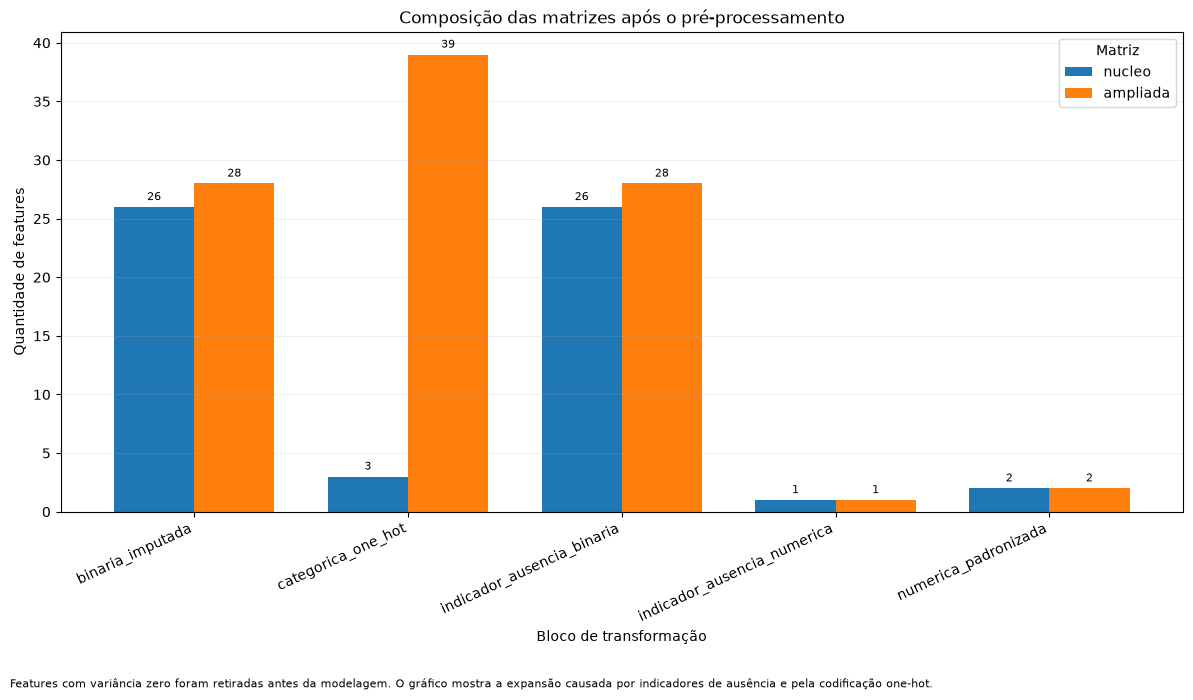

Features de variância zero no núcleo: 0
Features de variância zero na ampliada: 0


,matriz,quantidade_registros,features_processadas,features_variancia_zero_excluidas,features_modelagem,memoria_mb
0,nucleo,80000,58,0,58,17.700321
1,ampliada,80000,98,0,98,29.907352


,matriz,bloco_transformacao,status_variancia,quantidade_features,variancia_mediana,variancia_minima,variancia_maxima
0,ampliada,binaria_imputada,adequada,28,0.092425,0.003252,0.226396
1,ampliada,categorica_one_hot,adequada,39,0.027534,0.000137,0.249477
2,ampliada,indicador_ausencia_binaria,adequada,28,0.223465,0.068300,0.243735
3,ampliada,indicador_ausencia_numerica,adequada,1,1.000000,1.000000,1.000000
4,ampliada,numerica_padronizada,adequada,2,1.000000,1.000000,1.000000
5,nucleo,binaria_imputada,adequada,26,0.069688,0.003252,0.204743
6,nucleo,categorica_one_hot,adequada,3,0.249471,0.000137,0.249477
7,nucleo,indicador_ausencia_binaria,adequada,26,0.223465,0.068300,0.242236
8,nucleo,indicador_ausencia_numerica,adequada,1,1.000000,1.000000,1.000000
9,nucleo,numerica_padronizada,adequada,2,1.000000,1.000000,1.000000


,matriz,feature_processada,media,desvio_padrao,variancia,valor_minimo,valor_maximo,quantidade_valores_distintos,bloco_transformacao,flag_variancia_zero,flag_variancia_muito_baixa,status_variancia


In [110]:
OBJETOS_DIAGNOSTICO_PROCESSADO_NECESSARIOS = [
    "matriz_nucleo_processada",
    "matriz_ampliada_processada",
    "NOMES_FEATURES_NUCLEO_PROCESSADAS",
    "NOMES_FEATURES_AMPLIADA_PROCESSADAS",
]

objetos_diagnostico_processado_ausentes = [
    nome
    for nome in OBJETOS_DIAGNOSTICO_PROCESSADO_NECESSARIOS
    if nome not in globals()
]

if objetos_diagnostico_processado_ausentes:
    raise NameError(
        "Execute primeiro o pré-processamento. Objetos ausentes: "
        f"{objetos_diagnostico_processado_ausentes}"
    )


LIMITE_VARIANCIA_ZERO = 1e-12
LIMITE_VARIANCIA_MUITO_BAIXA = 1e-4


def identificar_bloco_feature(nome_feature):
    if nome_feature.startswith("numericas__missingindicator_"):
        return "indicador_ausencia_numerica"

    if nome_feature.startswith("numericas__"):
        return "numerica_padronizada"

    if nome_feature.startswith("binarias__missingindicator_"):
        return "indicador_ausencia_binaria"

    if nome_feature.startswith("binarias__"):
        return "binaria_imputada"

    if nome_feature.startswith("categoricas__"):
        return "categorica_one_hot"

    return "bloco_nao_identificado"


def diagnosticar_matriz_processada(
    nome_matriz,
    matriz_processada,
):
    if matriz_processada.empty:
        raise ValueError(
            f"A matriz processada {nome_matriz} está vazia."
        )

    estatisticas = pd.DataFrame(
        {
            "feature_processada": matriz_processada.columns,
            "media": matriz_processada.mean(axis=0).to_numpy(),
            "desvio_padrao": matriz_processada.std(
                axis=0,
                ddof=0,
            ).to_numpy(),
            "variancia": matriz_processada.var(
                axis=0,
                ddof=0,
            ).to_numpy(),
            "valor_minimo": matriz_processada.min(axis=0).to_numpy(),
            "valor_maximo": matriz_processada.max(axis=0).to_numpy(),
            "quantidade_valores_distintos": [
                int(
                    matriz_processada[coluna].nunique(
                        dropna=True
                    )
                )
                for coluna in matriz_processada.columns
            ],
        }
    )

    estatisticas.insert(
        0,
        "matriz",
        nome_matriz,
    )

    estatisticas[
        "bloco_transformacao"
    ] = estatisticas[
        "feature_processada"
    ].map(
        identificar_bloco_feature
    )

    estatisticas[
        "flag_variancia_zero"
    ] = estatisticas[
        "variancia"
    ].le(
        LIMITE_VARIANCIA_ZERO
    )

    estatisticas[
        "flag_variancia_muito_baixa"
    ] = (
        estatisticas[
            "variancia"
        ].gt(
            LIMITE_VARIANCIA_ZERO
        )
        & estatisticas[
            "variancia"
        ].lt(
            LIMITE_VARIANCIA_MUITO_BAIXA
        )
    )

    estatisticas[
        "status_variancia"
    ] = "adequada"

    estatisticas.loc[
        estatisticas[
            "flag_variancia_muito_baixa"
        ],
        "status_variancia",
    ] = "revisar_variancia_muito_baixa"

    estatisticas.loc[
        estatisticas[
            "flag_variancia_zero"
        ],
        "status_variancia",
    ] = "excluir_variancia_zero"

    return estatisticas


diagnostico_nucleo_processado = diagnosticar_matriz_processada(
    nome_matriz="nucleo",
    matriz_processada=matriz_nucleo_processada,
)

diagnostico_ampliada_processado = diagnosticar_matriz_processada(
    nome_matriz="ampliada",
    matriz_processada=matriz_ampliada_processada,
)

diagnostico_matrizes_processadas = pd.concat(
    [
        diagnostico_nucleo_processado,
        diagnostico_ampliada_processado,
    ],
    ignore_index=True,
)

if diagnostico_matrizes_processadas[
    "bloco_transformacao"
].eq("bloco_nao_identificado").any():
    features_sem_bloco = (
        diagnostico_matrizes_processadas.loc[
            diagnostico_matrizes_processadas[
                "bloco_transformacao"
            ].eq("bloco_nao_identificado"),
            "feature_processada",
        ]
        .drop_duplicates()
        .tolist()
    )

    raise RuntimeError(
        "Existem features processadas sem bloco identificado: "
        f"{features_sem_bloco}"
    )

features_variancia_zero_nucleo = (
    diagnostico_nucleo_processado.loc[
        diagnostico_nucleo_processado[
            "flag_variancia_zero"
        ],
        "feature_processada",
    ]
    .tolist()
)

features_variancia_zero_ampliada = (
    diagnostico_ampliada_processado.loc[
        diagnostico_ampliada_processado[
            "flag_variancia_zero"
        ],
        "feature_processada",
    ]
    .tolist()
)

FEATURES_MODELAGEM_NUCLEO = [
    coluna
    for coluna in matriz_nucleo_processada.columns
    if coluna not in features_variancia_zero_nucleo
]

FEATURES_MODELAGEM_AMPLIADA = [
    coluna
    for coluna in matriz_ampliada_processada.columns
    if coluna not in features_variancia_zero_ampliada
]

if not FEATURES_MODELAGEM_NUCLEO:
    raise ValueError(
        "Nenhuma feature permaneceu na matriz núcleo."
    )

if not FEATURES_MODELAGEM_AMPLIADA:
    raise ValueError(
        "Nenhuma feature permaneceu na matriz ampliada."
    )

matriz_nucleo_modelagem = (
    matriz_nucleo_processada[
        FEATURES_MODELAGEM_NUCLEO
    ]
    .copy()
)

matriz_ampliada_modelagem = (
    matriz_ampliada_processada[
        FEATURES_MODELAGEM_AMPLIADA
    ]
    .copy()
)

if matriz_nucleo_modelagem.isna().any().any():
    raise RuntimeError(
        "A matriz núcleo de modelagem contém ausências."
    )

if matriz_ampliada_modelagem.isna().any().any():
    raise RuntimeError(
        "A matriz ampliada de modelagem contém ausências."
    )

if not np.isfinite(
    matriz_nucleo_modelagem.to_numpy(
        dtype=np.float32,
        copy=False,
    )
).all():
    raise RuntimeError(
        "A matriz núcleo de modelagem contém valores não finitos."
    )

if not np.isfinite(
    matriz_ampliada_modelagem.to_numpy(
        dtype=np.float32,
        copy=False,
    )
).all():
    raise RuntimeError(
        "A matriz ampliada de modelagem contém valores não finitos."
    )

resumo_variancia_processada = (
    diagnostico_matrizes_processadas.groupby(
        [
            "matriz",
            "bloco_transformacao",
            "status_variancia",
        ],
        dropna=False,
    )
    .agg(
        quantidade_features=(
            "feature_processada",
            "nunique",
        ),
        variancia_mediana=(
            "variancia",
            "median",
        ),
        variancia_minima=(
            "variancia",
            "min",
        ),
        variancia_maxima=(
            "variancia",
            "max",
        ),
    )
    .reset_index()
    .sort_values(
        [
            "matriz",
            "bloco_transformacao",
            "status_variancia",
        ]
    )
    .reset_index(drop=True)
)

resumo_matrizes_modelagem = pd.DataFrame(
    {
        "matriz": [
            "nucleo",
            "ampliada",
        ],
        "quantidade_registros": [
            len(matriz_nucleo_modelagem),
            len(matriz_ampliada_modelagem),
        ],
        "features_processadas": [
            matriz_nucleo_processada.shape[1],
            matriz_ampliada_processada.shape[1],
        ],
        "features_variancia_zero_excluidas": [
            len(features_variancia_zero_nucleo),
            len(features_variancia_zero_ampliada),
        ],
        "features_modelagem": [
            matriz_nucleo_modelagem.shape[1],
            matriz_ampliada_modelagem.shape[1],
        ],
        "memoria_mb": [
            float(
                matriz_nucleo_modelagem.memory_usage(
                    index=True,
                    deep=True,
                ).sum()
                / (1024 ** 2)
            ),
            float(
                matriz_ampliada_modelagem.memory_usage(
                    index=True,
                    deep=True,
                ).sum()
                / (1024 ** 2)
            ),
        ],
    }
)

composicao_features_processadas = (
    diagnostico_matrizes_processadas.loc[
        diagnostico_matrizes_processadas[
            "flag_variancia_zero"
        ].eq(False)
    ]
    .groupby(
        [
            "matriz",
            "bloco_transformacao",
        ],
        dropna=False,
    )
    .agg(
        quantidade_features=(
            "feature_processada",
            "nunique",
        )
    )
    .reset_index()
)

matriz_composicao_features = (
    composicao_features_processadas.pivot(
        index="bloco_transformacao",
        columns="matriz",
        values="quantidade_features",
    )
    .fillna(0)
    .astype(int)
)

matriz_composicao_features = (
    matriz_composicao_features.reindex(
        columns=[
            "nucleo",
            "ampliada",
        ],
        fill_value=0,
    )
)

figura_composicao_features, eixo_composicao_features = plt.subplots(
    figsize=(
        12,
        7,
    )
)

matriz_composicao_features.plot(
    kind="bar",
    ax=eixo_composicao_features,
    color=[
        "tab:blue",
        "tab:orange",
    ],
    width=0.75,
)

eixo_composicao_features.set_title(
    "Composição das matrizes após o pré-processamento"
)

eixo_composicao_features.set_xlabel(
    "Bloco de transformação"
)

eixo_composicao_features.set_ylabel(
    "Quantidade de features"
)

eixo_composicao_features.set_xticklabels(
    eixo_composicao_features.get_xticklabels(),
    rotation=25,
    ha="right",
)

eixo_composicao_features.legend(
    title="Matriz"
)

eixo_composicao_features.grid(
    axis="y",
    alpha=0.20,
)

for contenedor in eixo_composicao_features.containers:
    eixo_composicao_features.bar_label(
        contenedor,
        padding=3,
        fontsize=8,
    )

figura_composicao_features.text(
    0.01,
    0.01,
    (
        "Features com variância zero foram retiradas antes da modelagem. "
        "O gráfico mostra a expansão causada por indicadores de ausência "
        "e pela codificação one-hot."
    ),
    fontsize=8,
)

figura_composicao_features.tight_layout(
    rect=[
        0,
        0.05,
        1,
        1,
    ]
)

plt.show()

plt.close(
    figura_composicao_features
)

print(
    "Features de variância zero no núcleo:",
    len(features_variancia_zero_nucleo),
)

print(
    "Features de variância zero na ampliada:",
    len(features_variancia_zero_ampliada),
)

display(
    resumo_matrizes_modelagem
)

display(
    resumo_variancia_processada
)

display(
    diagnostico_matrizes_processadas.loc[
        diagnostico_matrizes_processadas[
            "status_variancia"
        ].ne("adequada")
    ]
    .sort_values(
        [
            "matriz",
            "status_variancia",
            "variancia",
            "feature_processada",
        ]
    )
    .reset_index(drop=True)
)


## 12. Diagnóstico de dimensionalidade

A análise de componentes principais será aplicada às matrizes núcleo e
ampliada para avaliar a concentração da variância.

Nesta etapa, o PCA será utilizado para:

- comparar a dimensionalidade das duas matrizes;
- identificar quantos componentes são necessários para explicar 80%,
  90% e 95% da variância;
- produzir coordenadas bidimensionais para visualizações posteriores;
- apoiar a decisão sobre o espaço utilizado nos testes de clustering.

O PCA não utilizará o desfecho.

A projeção em duas dimensões será utilizada apenas para diagnóstico
visual. A ausência de separação visual clara não implica, isoladamente,
ausência de estrutura multivariada.

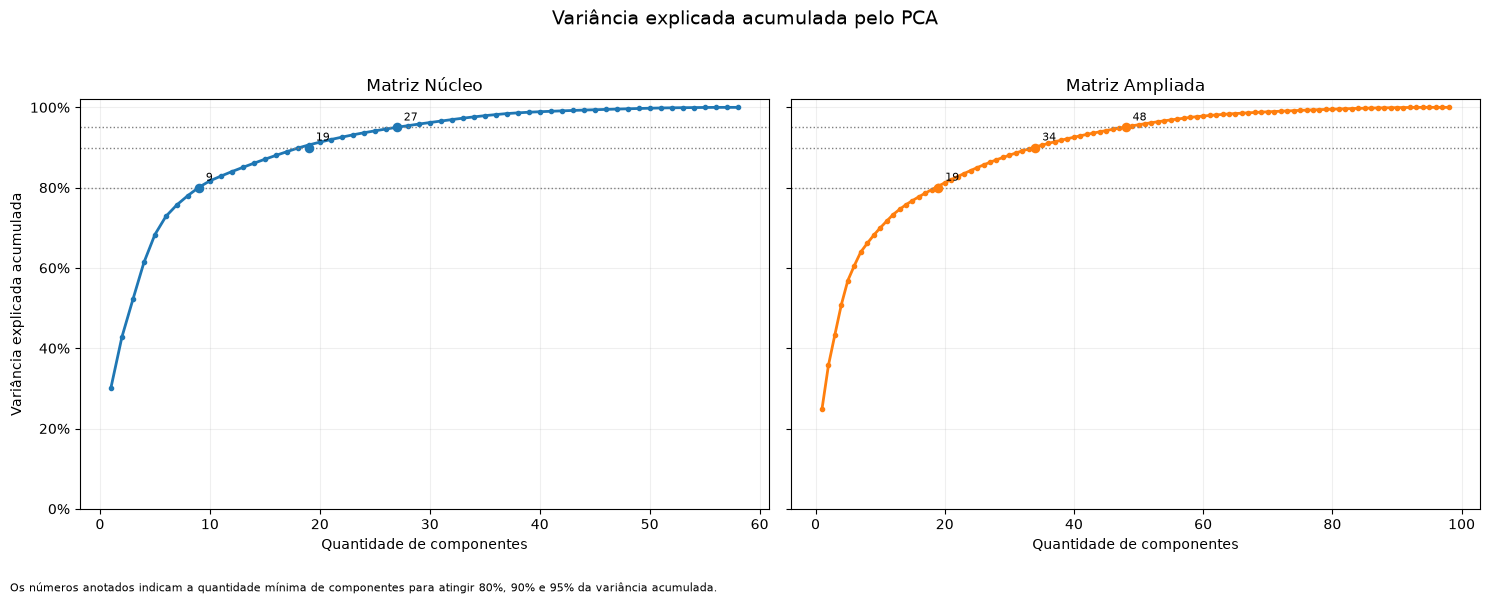

Componentes disponíveis no núcleo: 58
Componentes disponíveis na ampliada: 98


matriz,limite_variancia_percentual,ampliada,nucleo
0,80.0,19,9
1,90.0,34,19
2,95.0,48,27


,matriz,componente,variancia_explicada,variancia_explicada_percentual,variancia_acumulada,variancia_acumulada_percentual
0,nucleo,1,3.017517e-01,3.017517e+01,0.301752,30.175171
1,nucleo,2,1.264844e-01,1.264844e+01,0.428236,42.823608
2,nucleo,3,9.363012e-02,9.363012e+00,0.521866,52.186619
3,nucleo,4,9.181182e-02,9.181182e+00,0.613678,61.367805
4,nucleo,5,6.952327e-02,6.952327e+00,0.683201,68.320129
...,...,...,...,...,...,...
151,ampliada,94,3.188790e-05,3.188790e-03,0.999985,99.998474
152,ampliada,95,1.538949e-05,1.538949e-03,1.000000,100.000015
153,ampliada,96,1.412768e-14,1.412767e-12,1.000000,100.000015
154,ampliada,97,4.739871e-16,4.739871e-14,1.000000,100.000015


In [111]:
from sklearn.decomposition import PCA


OBJETOS_PCA_NECESSARIOS = [
    "matriz_nucleo_modelagem",
    "matriz_ampliada_modelagem",
    "FEATURES_MODELAGEM_NUCLEO",
    "FEATURES_MODELAGEM_AMPLIADA",
]

objetos_pca_ausentes = [
    nome
    for nome in OBJETOS_PCA_NECESSARIOS
    if nome not in globals()
]

if objetos_pca_ausentes:
    raise NameError(
        "Execute primeiro o diagnóstico das matrizes processadas. "
        "Objetos ausentes: "
        f"{objetos_pca_ausentes}"
    )


LIMITES_VARIANCIA_ACUMULADA = [
    0.80,
    0.90,
    0.95,
]


def executar_pca_diagnostico(
    nome_matriz,
    matriz_modelagem,
):
    if matriz_modelagem.empty:
        raise ValueError(
            f"A matriz {nome_matriz} está vazia."
        )

    quantidade_componentes_maxima = min(
        matriz_modelagem.shape[0],
        matriz_modelagem.shape[1],
    )

    if quantidade_componentes_maxima < 2:
        raise ValueError(
            f"A matriz {nome_matriz} não possui dimensão "
            "suficiente para PCA."
        )

    pca = PCA(
        n_components=None,
        svd_solver="full",
    )

    coordenadas = pca.fit_transform(
        matriz_modelagem.to_numpy(
            dtype=np.float32,
            copy=False,
        )
    )

    variancia_explicada = pca.explained_variance_ratio_
    variancia_acumulada = np.cumsum(
        variancia_explicada
    )

    if not np.isfinite(variancia_explicada).all():
        raise RuntimeError(
            f"O PCA da matriz {nome_matriz} produziu "
            "variância explicada não finita."
        )

    if not np.isclose(
        variancia_explicada.sum(),
        1.0,
        atol=1e-5,
    ):
        raise RuntimeError(
            f"A variância explicada do PCA da matriz {nome_matriz} "
            "não soma aproximadamente 100%."
        )

    tabela_variancia = pd.DataFrame(
        {
            "matriz": nome_matriz,
            "componente": np.arange(
                1,
                len(variancia_explicada) + 1,
            ),
            "variancia_explicada": variancia_explicada,
            "variancia_explicada_percentual": (
                variancia_explicada
                * 100
            ),
            "variancia_acumulada": variancia_acumulada,
            "variancia_acumulada_percentual": (
                variancia_acumulada
                * 100
            ),
        }
    )

    resumo_limites = []

    for limite in LIMITES_VARIANCIA_ACUMULADA:
        quantidade_componentes = int(
            np.searchsorted(
                variancia_acumulada,
                limite,
                side="left",
            )
            + 1
        )

        resumo_limites.append(
            {
                "matriz": nome_matriz,
                "limite_variancia": limite,
                "limite_variancia_percentual": limite * 100,
                "quantidade_componentes": quantidade_componentes,
            }
        )

    resumo_limites = pd.DataFrame(
        resumo_limites
    )

    coordenadas_duas_dimensoes = pd.DataFrame(
        coordenadas[
            :,
            :2,
        ],
        index=matriz_modelagem.index,
        columns=[
            "componente_1",
            "componente_2",
        ],
        dtype="float32",
    )

    return (
        pca,
        tabela_variancia,
        resumo_limites,
        coordenadas_duas_dimensoes,
    )


(
    pca_nucleo,
    variancia_pca_nucleo,
    resumo_limites_pca_nucleo,
    coordenadas_pca_nucleo_2d,
) = executar_pca_diagnostico(
    nome_matriz="nucleo",
    matriz_modelagem=matriz_nucleo_modelagem,
)

(
    pca_ampliada,
    variancia_pca_ampliada,
    resumo_limites_pca_ampliada,
    coordenadas_pca_ampliada_2d,
) = executar_pca_diagnostico(
    nome_matriz="ampliada",
    matriz_modelagem=matriz_ampliada_modelagem,
)

variancia_pca = pd.concat(
    [
        variancia_pca_nucleo,
        variancia_pca_ampliada,
    ],
    ignore_index=True,
)

resumo_limites_pca = pd.concat(
    [
        resumo_limites_pca_nucleo,
        resumo_limites_pca_ampliada,
    ],
    ignore_index=True,
)

if not coordenadas_pca_nucleo_2d.index.equals(
    matriz_nucleo_modelagem.index
):
    raise RuntimeError(
        "As coordenadas PCA do núcleo perderam "
        "o alinhamento com a matriz."
    )

if not coordenadas_pca_ampliada_2d.index.equals(
    matriz_ampliada_modelagem.index
):
    raise RuntimeError(
        "As coordenadas PCA da matriz ampliada perderam "
        "o alinhamento com a matriz."
    )

figura_pca, eixos_pca = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(
        15,
        6,
    ),
    sharey=True,
)

configuracoes_pca = [
    {
        "nome": "Núcleo",
        "tabela": variancia_pca_nucleo,
        "cor": "tab:blue",
        "eixo": eixos_pca[0],
    },
    {
        "nome": "Ampliada",
        "tabela": variancia_pca_ampliada,
        "cor": "tab:orange",
        "eixo": eixos_pca[1],
    },
]

for configuracao in configuracoes_pca:
    eixo = configuracao["eixo"]
    tabela = configuracao["tabela"]
    cor = configuracao["cor"]

    eixo.plot(
        tabela["componente"],
        tabela["variancia_acumulada_percentual"],
        marker="o",
        markersize=3,
        linewidth=2,
        color=cor,
    )

    for limite in LIMITES_VARIANCIA_ACUMULADA:
        eixo.axhline(
            y=limite * 100,
            color="tab:gray",
            linestyle=":",
            linewidth=1,
        )

    tabela_limites = resumo_limites_pca.loc[
        resumo_limites_pca["matriz"].eq(
            configuracao["nome"].lower()
            .replace("ú", "u")
        )
    ]

    for _, linha_limite in tabela_limites.iterrows():
        eixo.scatter(
            linha_limite["quantidade_componentes"],
            linha_limite["limite_variancia_percentual"],
            color=cor,
            s=35,
            zorder=3,
        )

        eixo.annotate(
            str(
                int(
                    linha_limite["quantidade_componentes"]
                )
            ),
            (
                linha_limite["quantidade_componentes"],
                linha_limite["limite_variancia_percentual"],
            ),
            textcoords="offset points",
            xytext=(
                5,
                5,
            ),
            fontsize=8,
        )

    eixo.set_title(
        f"Matriz {configuracao['nome']}"
    )

    eixo.set_xlabel(
        "Quantidade de componentes"
    )

    eixo.set_ylim(
        0,
        102,
    )

    eixo.grid(
        alpha=0.20,
    )

    eixo.yaxis.set_major_formatter(
        plt.FuncFormatter(
            lambda valor, posicao: (
                f"{valor:.0f}%"
            )
        )
    )


eixos_pca[0].set_ylabel(
    "Variância explicada acumulada"
)

figura_pca.suptitle(
    "Variância explicada acumulada pelo PCA",
    fontsize=14,
)

figura_pca.text(
    0.01,
    0.01,
    (
        "Os números anotados indicam a quantidade mínima de componentes "
        "para atingir 80%, 90% e 95% da variância acumulada."
    ),
    fontsize=8,
)

figura_pca.tight_layout(
    rect=[
        0,
        0.05,
        1,
        0.95,
    ]
)

plt.show()

plt.close(
    figura_pca
)

resumo_pca = (
    resumo_limites_pca.pivot(
        index="limite_variancia_percentual",
        columns="matriz",
        values="quantidade_componentes",
    )
    .reset_index()
    .sort_values(
        "limite_variancia_percentual"
    )
    .reset_index(drop=True)
)

print(
    "Componentes disponíveis no núcleo:",
    len(variancia_pca_nucleo),
)

print(
    "Componentes disponíveis na ampliada:",
    len(variancia_pca_ampliada),
)

display(
    resumo_pca
)

display(
    variancia_pca
)


### Diagnóstico do número de clusters

As matrizes núcleo e ampliada serão avaliadas no espaço PCA necessário
para preservar 90% da variância.

Serão testados valores de `k` entre 2 e 10 por meio de
MiniBatch K-Means.

A comparação considerará conjuntamente:

- inércia por registro;
- silhouette médio;
- participação do menor cluster;
- participação do maior cluster;
- presença de clusters com menos de 1% da amostra;
- interpretabilidade clínica;
- estabilidade em diferentes inicializações.

O maior silhouette não determinará sozinho a solução final.

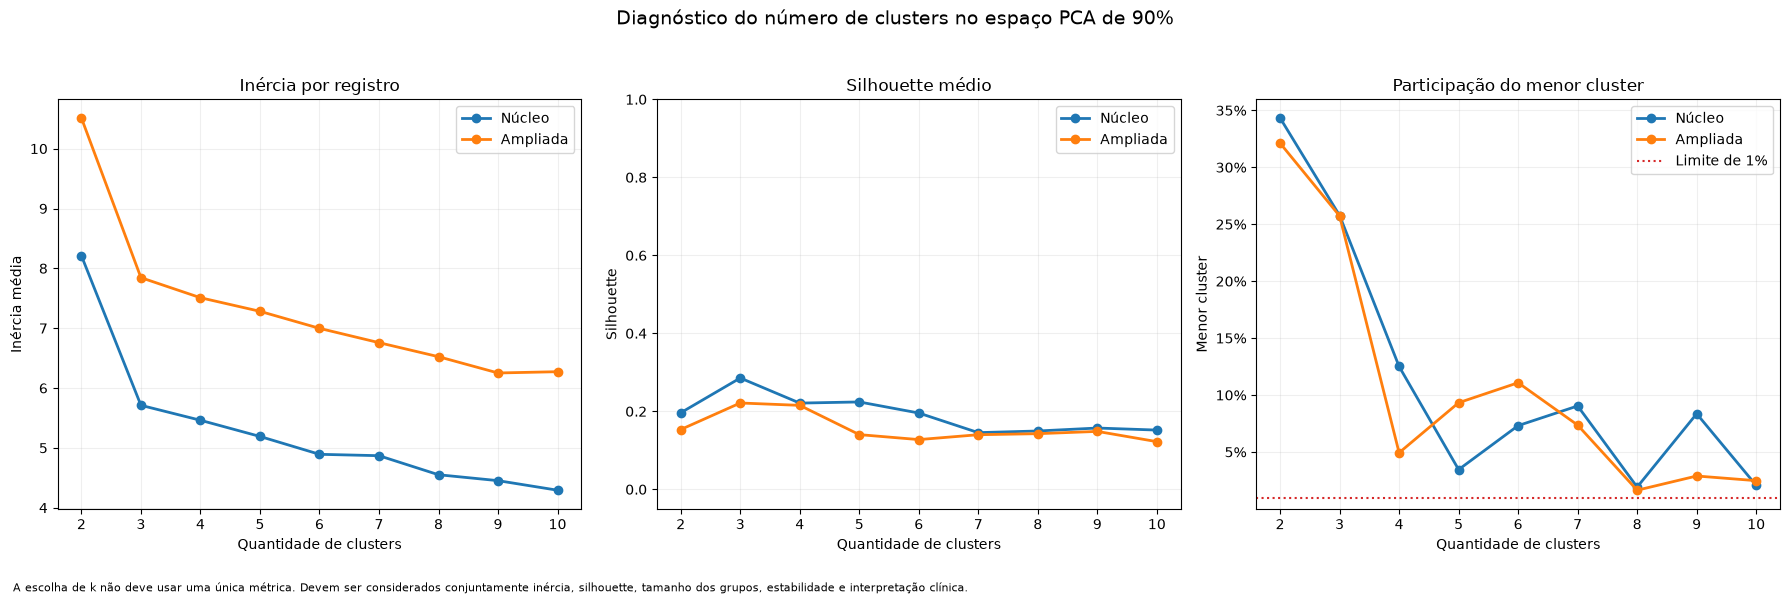

Diagnóstico de k concluído para: [2, 3, 4, 5, 6, 7, 8, 9, 10]
Silhouette calculado com amostra máxima de: 10000


,matriz,quantidade_clusters,quantidade_registros,quantidade_componentes_pca,inercia_total,inercia_por_registro,silhouette_medio,tamanho_amostra_silhouette,menor_cluster_quantidade,menor_cluster_percentual,maior_cluster_quantidade,maior_cluster_percentual,flag_cluster_muito_pequeno,numero_iteracoes
0,ampliada,3,80000,34,627568.9375,7.844612,0.221385,10000,20581,25.72625,32606,40.7575,False,1
1,nucleo,3,80000,19,456932.5000,5.711656,0.285447,10000,20613,25.76625,32578,40.7225,False,1


,matriz,quantidade_clusters,quantidade_registros,quantidade_componentes_pca,inercia_total,inercia_por_registro,silhouette_medio,tamanho_amostra_silhouette,menor_cluster_quantidade,menor_cluster_percentual,maior_cluster_quantidade,maior_cluster_percentual,flag_cluster_muito_pequeno,numero_iteracoes
0,nucleo,2,80000,19,656888.93750,8.211112,0.196304,10000,27467,34.33375,52533,65.66625,False,1
1,nucleo,3,80000,19,456932.50000,5.711656,0.285447,10000,20613,25.76625,32578,40.72250,False,1
2,nucleo,4,80000,19,436958.84375,5.461986,0.221113,10000,10005,12.50625,32045,40.05625,False,2
3,nucleo,5,80000,19,415321.18750,5.191515,0.224065,10000,2762,3.45250,26220,32.77500,False,2
4,nucleo,6,80000,19,391444.62500,4.893058,0.195654,10000,5852,7.31500,20951,26.18875,False,2
5,nucleo,7,80000,19,389606.03125,4.870075,0.145340,10000,7233,9.04125,14006,17.50750,False,1
6,nucleo,8,80000,19,364133.75000,4.551672,0.149593,10000,1534,1.91750,14141,17.67625,False,1
7,nucleo,9,80000,19,356238.65625,4.452983,0.157168,10000,6686,8.35750,12161,15.20125,False,1
8,nucleo,10,80000,19,343451.40625,4.293143,0.151942,10000,1652,2.06500,12486,15.60750,False,2
9,ampliada,2,80000,34,841036.93750,10.512962,0.153334,10000,25697,32.12125,54303,67.87875,False,1


In [112]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score


OBJETOS_DIAGNOSTICO_K_NECESSARIOS = [
    "matriz_nucleo_modelagem",
    "matriz_ampliada_modelagem",
    "pca_nucleo",
    "pca_ampliada",
    "resumo_limites_pca_nucleo",
    "resumo_limites_pca_ampliada",
    "SEMENTE_CLUSTERING",
]

objetos_diagnostico_k_ausentes = [
    nome
    for nome in OBJETOS_DIAGNOSTICO_K_NECESSARIOS
    if nome not in globals()
]

if objetos_diagnostico_k_ausentes:
    raise NameError(
        "Execute primeiro o PCA diagnóstico. Objetos ausentes: "
        f"{objetos_diagnostico_k_ausentes}"
    )


VALORES_K_DIAGNOSTICO = list(
    range(
        2,
        11,
    )
)

LIMITE_VARIANCIA_PCA_CLUSTERING = 0.90
TAMANHO_AMOSTRA_SILHOUETTE = 10_000
TAMANHO_MINIMO_CLUSTER_PERCENTUAL = 1.0
TAMANHO_LOTE_MINIBATCH = 2_048
N_INIT_MINIBATCH = 10
MAX_ITER_MINIBATCH = 200


def obter_quantidade_componentes(
    resumo_limites,
    limite_variancia,
):
    linhas_limite = resumo_limites.loc[
        np.isclose(
            resumo_limites[
                "limite_variancia"
            ],
            limite_variancia,
        )
    ]

    if len(linhas_limite) != 1:
        raise RuntimeError(
            "Não foi possível identificar uma única quantidade "
            "de componentes para o limite informado."
        )

    return int(
        linhas_limite[
            "quantidade_componentes"
        ].iloc[0]
    )


def criar_representacao_pca(
    nome_matriz,
    matriz_modelagem,
    pca_ajustado,
    resumo_limites,
):
    quantidade_componentes = obter_quantidade_componentes(
        resumo_limites=resumo_limites,
        limite_variancia=LIMITE_VARIANCIA_PCA_CLUSTERING,
    )

    coordenadas_completas = pca_ajustado.transform(
        matriz_modelagem.to_numpy(
            dtype=np.float32,
            copy=False,
        )
    )

    coordenadas_selecionadas = coordenadas_completas[
        :,
        :quantidade_componentes,
    ]

    nomes_componentes = [
        f"componente_{numero}"
        for numero in range(
            1,
            quantidade_componentes + 1,
        )
    ]

    representacao = pd.DataFrame(
        coordenadas_selecionadas,
        index=matriz_modelagem.index,
        columns=nomes_componentes,
        dtype="float32",
    )

    if representacao.isna().any().any():
        raise RuntimeError(
            f"A representação PCA da matriz {nome_matriz} "
            "contém ausências."
        )

    if not np.isfinite(
        representacao.to_numpy(
            dtype=np.float32,
            copy=False,
        )
    ).all():
        raise RuntimeError(
            f"A representação PCA da matriz {nome_matriz} "
            "contém valores não finitos."
        )

    return representacao


def avaliar_valores_k(
    nome_matriz,
    representacao_pca,
):
    quantidade_registros = len(
        representacao_pca
    )

    if quantidade_registros <= max(
        VALORES_K_DIAGNOSTICO
    ):
        raise ValueError(
            f"A representação {nome_matriz} não possui registros "
            "suficientes para os valores de k avaliados."
        )

    valores = representacao_pca.to_numpy(
        dtype=np.float32,
        copy=False,
    )

    registros_resultados = []
    modelos = {}
    rotulos = {}

    for quantidade_clusters in VALORES_K_DIAGNOSTICO:
        modelo = MiniBatchKMeans(
            n_clusters=quantidade_clusters,
            init="k-means++",
            n_init=N_INIT_MINIBATCH,
            max_iter=MAX_ITER_MINIBATCH,
            batch_size=TAMANHO_LOTE_MINIBATCH,
            compute_labels=True,
            random_state=(
                SEMENTE_CLUSTERING
                + quantidade_clusters
            ),
            reassignment_ratio=0.01,
        )

        rotulos_modelo = modelo.fit_predict(
            valores
        )

        quantidade_rotulos = len(
            np.unique(
                rotulos_modelo
            )
        )

        if quantidade_rotulos != quantidade_clusters:
            raise RuntimeError(
                f"A solução {nome_matriz} com k={quantidade_clusters} "
                f"produziu {quantidade_rotulos} clusters observados."
            )

        contagens_clusters = pd.Series(
            rotulos_modelo
        ).value_counts()

        menor_cluster_quantidade = int(
            contagens_clusters.min()
        )

        maior_cluster_quantidade = int(
            contagens_clusters.max()
        )

        menor_cluster_percentual = (
            menor_cluster_quantidade
            / quantidade_registros
            * 100
        )

        maior_cluster_percentual = (
            maior_cluster_quantidade
            / quantidade_registros
            * 100
        )

        tamanho_silhouette = min(
            TAMANHO_AMOSTRA_SILHOUETTE,
            quantidade_registros,
        )

        silhouette_medio = float(
            silhouette_score(
                valores,
                rotulos_modelo,
                metric="euclidean",
                sample_size=tamanho_silhouette,
                random_state=(
                    SEMENTE_CLUSTERING
                    + 1_000
                    + quantidade_clusters
                ),
            )
        )

        inercia_total = float(
            modelo.inertia_
        )

        inercia_por_registro = (
            inercia_total
            / quantidade_registros
        )

        registros_resultados.append(
            {
                "matriz": nome_matriz,
                "quantidade_clusters": quantidade_clusters,
                "quantidade_registros": quantidade_registros,
                "quantidade_componentes_pca": (
                    representacao_pca.shape[1]
                ),
                "inercia_total": inercia_total,
                "inercia_por_registro": inercia_por_registro,
                "silhouette_medio": silhouette_medio,
                "tamanho_amostra_silhouette": tamanho_silhouette,
                "menor_cluster_quantidade": (
                    menor_cluster_quantidade
                ),
                "menor_cluster_percentual": (
                    menor_cluster_percentual
                ),
                "maior_cluster_quantidade": (
                    maior_cluster_quantidade
                ),
                "maior_cluster_percentual": (
                    maior_cluster_percentual
                ),
                "flag_cluster_muito_pequeno": (
                    menor_cluster_percentual
                    < TAMANHO_MINIMO_CLUSTER_PERCENTUAL
                ),
                "numero_iteracoes": int(
                    modelo.n_iter_
                ),
            }
        )

        modelos[
            quantidade_clusters
        ] = modelo

        rotulos[
            quantidade_clusters
        ] = rotulos_modelo

    resultados = pd.DataFrame(
        registros_resultados
    )

    return resultados, modelos, rotulos


representacao_pca_nucleo_90 = criar_representacao_pca(
    nome_matriz="nucleo",
    matriz_modelagem=matriz_nucleo_modelagem,
    pca_ajustado=pca_nucleo,
    resumo_limites=resumo_limites_pca_nucleo,
)

representacao_pca_ampliada_90 = criar_representacao_pca(
    nome_matriz="ampliada",
    matriz_modelagem=matriz_ampliada_modelagem,
    pca_ajustado=pca_ampliada,
    resumo_limites=resumo_limites_pca_ampliada,
)

(
    diagnostico_k_nucleo,
    modelos_k_nucleo,
    rotulos_k_nucleo,
) = avaliar_valores_k(
    nome_matriz="nucleo",
    representacao_pca=representacao_pca_nucleo_90,
)

(
    diagnostico_k_ampliada,
    modelos_k_ampliada,
    rotulos_k_ampliada,
) = avaliar_valores_k(
    nome_matriz="ampliada",
    representacao_pca=representacao_pca_ampliada_90,
)

diagnostico_k = pd.concat(
    [
        diagnostico_k_nucleo,
        diagnostico_k_ampliada,
    ],
    ignore_index=True,
)

if diagnostico_k[
    "silhouette_medio"
].isna().any():
    raise RuntimeError(
        "O diagnóstico de k contém silhouette ausente."
    )

if not diagnostico_k[
    "silhouette_medio"
].between(
    -1,
    1,
    inclusive="both",
).all():
    raise RuntimeError(
        "O diagnóstico de k contém silhouette fora "
        "do intervalo de -1 a 1."
    )

figura_diagnostico_k, eixos_diagnostico_k = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(
        18,
        6,
    ),
)

CORES_MATRIZES_CLUSTERING = {
    "nucleo": "tab:blue",
    "ampliada": "tab:orange",
}

ROTULOS_MATRIZES_CLUSTERING = {
    "nucleo": "Núcleo",
    "ampliada": "Ampliada",
}

for nome_matriz in [
    "nucleo",
    "ampliada",
]:
    dados_matriz = (
        diagnostico_k.loc[
            diagnostico_k[
                "matriz"
            ].eq(
                nome_matriz
            )
        ]
        .sort_values(
            "quantidade_clusters"
        )
    )

    cor = CORES_MATRIZES_CLUSTERING[
        nome_matriz
    ]

    rotulo = ROTULOS_MATRIZES_CLUSTERING[
        nome_matriz
    ]

    eixos_diagnostico_k[0].plot(
        dados_matriz[
            "quantidade_clusters"
        ],
        dados_matriz[
            "inercia_por_registro"
        ],
        marker="o",
        linewidth=2,
        color=cor,
        label=rotulo,
    )

    eixos_diagnostico_k[1].plot(
        dados_matriz[
            "quantidade_clusters"
        ],
        dados_matriz[
            "silhouette_medio"
        ],
        marker="o",
        linewidth=2,
        color=cor,
        label=rotulo,
    )

    eixos_diagnostico_k[2].plot(
        dados_matriz[
            "quantidade_clusters"
        ],
        dados_matriz[
            "menor_cluster_percentual"
        ],
        marker="o",
        linewidth=2,
        color=cor,
        label=rotulo,
    )


eixos_diagnostico_k[0].set_title(
    "Inércia por registro"
)

eixos_diagnostico_k[0].set_xlabel(
    "Quantidade de clusters"
)

eixos_diagnostico_k[0].set_ylabel(
    "Inércia média"
)

eixos_diagnostico_k[1].set_title(
    "Silhouette médio"
)

eixos_diagnostico_k[1].set_xlabel(
    "Quantidade de clusters"
)

eixos_diagnostico_k[1].set_ylabel(
    "Silhouette"
)

eixos_diagnostico_k[1].set_ylim(
    -0.05,
    1.0,
)

eixos_diagnostico_k[2].set_title(
    "Participação do menor cluster"
)

eixos_diagnostico_k[2].set_xlabel(
    "Quantidade de clusters"
)

eixos_diagnostico_k[2].set_ylabel(
    "Menor cluster"
)

eixos_diagnostico_k[2].yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

eixos_diagnostico_k[2].axhline(
    y=TAMANHO_MINIMO_CLUSTER_PERCENTUAL,
    color="tab:red",
    linestyle=":",
    linewidth=1.5,
    label="Limite de 1%",
)

for eixo in eixos_diagnostico_k:
    eixo.set_xticks(
        VALORES_K_DIAGNOSTICO
    )

    eixo.grid(
        alpha=0.20,
    )

    eixo.legend()

figura_diagnostico_k.suptitle(
    "Diagnóstico do número de clusters no espaço PCA de 90%",
    fontsize=14,
)

figura_diagnostico_k.text(
    0.01,
    0.01,
    (
        "A escolha de k não deve usar uma única métrica. "
        "Devem ser considerados conjuntamente inércia, silhouette, "
        "tamanho dos grupos, estabilidade e interpretação clínica."
    ),
    fontsize=8,
)

figura_diagnostico_k.tight_layout(
    rect=[
        0,
        0.05,
        1,
        0.95,
    ]
)

plt.show()

plt.close(
    figura_diagnostico_k
)

melhores_silhouettes = (
    diagnostico_k.loc[
        diagnostico_k.groupby(
            "matriz"
        )[
            "silhouette_medio"
        ].idxmax()
    ]
    .sort_values(
        "matriz"
    )
    .reset_index(drop=True)
)

print(
    "Diagnóstico de k concluído para:",
    VALORES_K_DIAGNOSTICO,
)

print(
    "Silhouette calculado com amostra máxima de:",
    TAMANHO_AMOSTRA_SILHOUETTE,
)

display(
    melhores_silhouettes
)

display(
    diagnostico_k
)


### Estabilidade das soluções candidatas

As soluções mais promissoras serão executadas com diferentes sementes
para avaliar a estabilidade dos agrupamentos.

A seleção inicial dos candidatos considerará:

- melhores valores de silhouette;
- redução da inércia entre valores consecutivos de `k`;
- ausência de clusters menores que 1% da amostra.

Cada solução candidata será repetida cinco vezes.

A concordância será avaliada pelo Adjusted Rand Index, que compara duas
partições sem depender da numeração atribuída aos clusters.

Uma solução estável deve manter estrutura semelhante entre diferentes
inicializações, sem produzir repetidamente grupos residuais muito
pequenos.

A pontuação desta etapa é diagnóstica. A decisão final também dependerá
da interpretação clínica e temporal dos perfis encontrados.

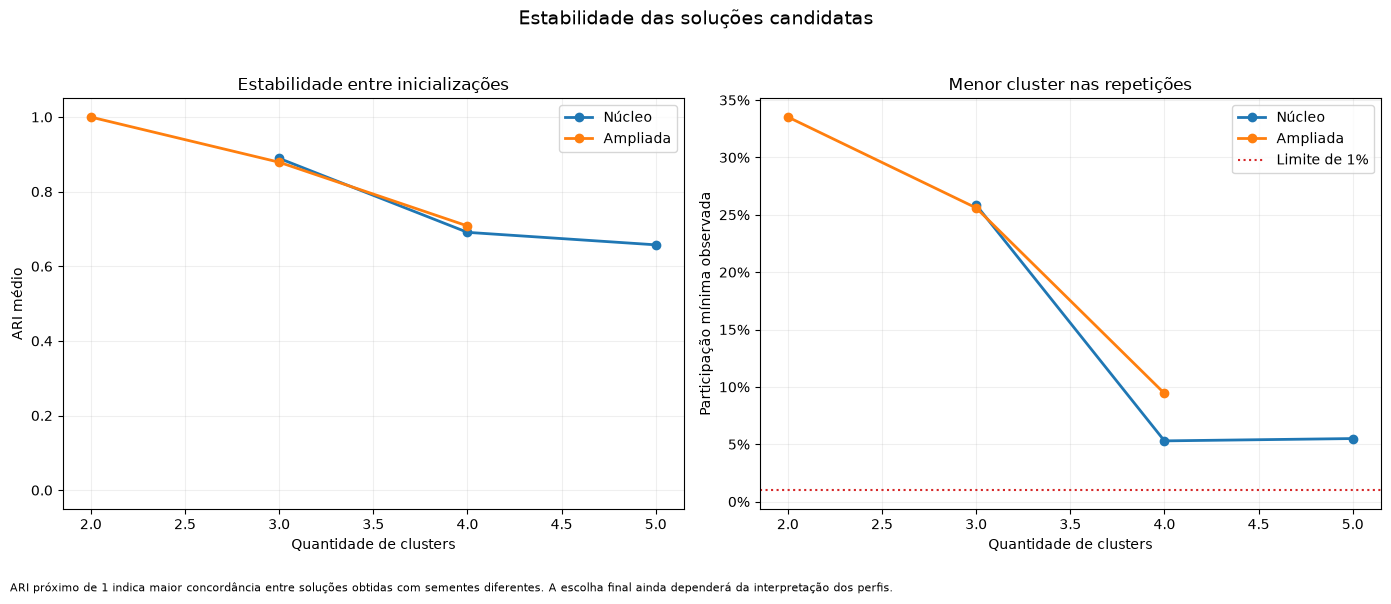

Candidatos avaliados por matriz: {'nucleo': [3, 4, 5], 'ampliada': [2, 3, 4]}
Repetições por candidato: 5


,matriz,quantidade_clusters,quantidade_repeticoes,ari_medio,ari_minimo,ari_maximo,inercia_media_por_registro,inercia_desvio_padrao,menor_cluster_percentual_minimo,maior_cluster_percentual_maximo,...,silhouette_medio,inercia_por_registro,menor_cluster_percentual,maior_cluster_percentual,flag_cluster_muito_pequeno,elegivel_sem_cluster_pequeno,rank_silhouette,rank_estabilidade,rank_tamanho_minimo,pontuacao_diagnostica
0,ampliada,2,5,0.999798,0.999696,0.999899,8.895490,0.000187,33.52500,66.47500,...,0.153334,10.512962,32.12125,67.87875,False,True,3.0,1.0,1.0,5.0
1,nucleo,3,5,0.889130,0.807285,0.996529,5.714928,0.002922,25.85625,40.62875,...,0.285447,5.711656,25.76625,40.72250,False,True,1.0,1.0,1.0,3.0


,matriz,quantidade_clusters,quantidade_repeticoes,ari_medio,ari_minimo,ari_maximo,inercia_media_por_registro,inercia_desvio_padrao,menor_cluster_percentual_minimo,maior_cluster_percentual_maximo,...,silhouette_medio,inercia_por_registro,menor_cluster_percentual,maior_cluster_percentual,flag_cluster_muito_pequeno,elegivel_sem_cluster_pequeno,rank_silhouette,rank_estabilidade,rank_tamanho_minimo,pontuacao_diagnostica
0,ampliada,2,5,0.999798,0.999696,0.999899,8.895490,0.000187,33.52500,66.47500,...,0.153334,10.512962,32.12125,67.87875,False,True,3.0,1.0,1.0,5.0
1,ampliada,3,5,0.878802,0.797340,0.997907,7.840668,0.004413,25.60250,40.88000,...,0.221385,7.844612,25.72625,40.75750,False,True,1.0,2.0,2.0,5.0
2,ampliada,4,5,0.708041,0.630206,0.975420,7.542564,0.052579,9.43250,40.51000,...,0.215308,7.509409,4.93250,32.99375,False,True,2.0,3.0,3.0,8.0
3,nucleo,3,5,0.889130,0.807285,0.996529,5.714928,0.002922,25.85625,40.62875,...,0.285447,5.711656,25.76625,40.72250,False,True,1.0,1.0,1.0,3.0
4,nucleo,4,5,0.690902,0.600466,0.858100,5.474009,0.034474,5.29625,40.14125,...,0.221113,5.461986,12.50625,40.05625,False,True,3.0,2.0,2.0,7.0
5,nucleo,5,5,0.657427,0.518696,0.790467,5.209415,0.073754,5.49875,36.42250,...,0.224065,5.191515,3.45250,32.77500,False,True,2.0,3.0,3.0,8.0


,matriz,quantidade_clusters,repeticao,semente,inercia_por_registro,menor_cluster_percentual,maior_cluster_percentual,flag_cluster_muito_pequeno
0,nucleo,3,0,342,5.717581,32.15250,34.33375,False
1,nucleo,3,1,343,5.717329,32.26875,34.21750,False
2,nucleo,3,2,344,5.711028,26.31375,40.17250,False
3,nucleo,3,3,345,5.711703,25.85625,40.62875,False
4,nucleo,3,4,346,5.716997,33.11875,33.51375,False
5,nucleo,4,0,442,5.458702,8.82625,33.36250,False
6,nucleo,4,1,443,5.520139,13.58625,39.60125,False
7,nucleo,4,2,444,5.422135,12.87375,33.49625,False
8,nucleo,4,3,445,5.502802,14.77875,40.14125,False
9,nucleo,4,4,446,5.466267,5.29625,33.72625,False


In [113]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import adjusted_rand_score


OBJETOS_ESTABILIDADE_NECESSARIOS = [
    "diagnostico_k",
    "representacao_pca_nucleo_90",
    "representacao_pca_ampliada_90",
    "SEMENTE_CLUSTERING",
]

objetos_estabilidade_ausentes = [
    nome
    for nome in OBJETOS_ESTABILIDADE_NECESSARIOS
    if nome not in globals()
]

if objetos_estabilidade_ausentes:
    raise NameError(
        "Execute primeiro o diagnóstico de k. Objetos ausentes: "
        f"{objetos_estabilidade_ausentes}"
    )


QUANTIDADE_CANDIDATOS_POR_MATRIZ = 3
QUANTIDADE_REPETICOES_ESTABILIDADE = 5
TAMANHO_LOTE_ESTABILIDADE = 2_048
N_INIT_ESTABILIDADE = 10
MAX_ITER_ESTABILIDADE = 200
LIMITE_CLUSTER_MUITO_PEQUENO = 1.0


def selecionar_candidatos_k(
    diagnostico_matriz,
):
    diagnostico_elegivel = (
        diagnostico_matriz.loc[
            diagnostico_matriz[
                "flag_cluster_muito_pequeno"
            ].eq(False)
        ]
        .copy()
    )

    if diagnostico_elegivel.empty:
        diagnostico_elegivel = diagnostico_matriz.copy()

    candidato_silhouette = (
        diagnostico_elegivel.sort_values(
            [
                "silhouette_medio",
                "quantidade_clusters",
            ],
            ascending=[
                False,
                True,
            ],
        )[
            "quantidade_clusters"
        ]
        .iloc[0]
    )

    diagnostico_ordenado = (
        diagnostico_elegivel.sort_values(
            "quantidade_clusters"
        )
        .reset_index(drop=True)
    )

    diagnostico_ordenado[
        "reducao_inercia_percentual"
    ] = (
        diagnostico_ordenado[
            "inercia_por_registro"
        ]
        .shift(1)
        .sub(
            diagnostico_ordenado[
                "inercia_por_registro"
            ]
        )
        .div(
            diagnostico_ordenado[
                "inercia_por_registro"
            ]
            .shift(1)
        )
        .mul(100)
    )

    reducoes_validas = (
        diagnostico_ordenado.dropna(
            subset=[
                "reducao_inercia_percentual",
            ]
        )
    )

    if reducoes_validas.empty:
        candidato_cotovelo = int(
            candidato_silhouette
        )
    else:
        candidato_cotovelo = int(
            reducoes_validas.sort_values(
                [
                    "reducao_inercia_percentual",
                    "quantidade_clusters",
                ],
                ascending=[
                    False,
                    True,
                ],
            )[
                "quantidade_clusters"
            ]
            .iloc[0]
        )

    melhores_silhouettes = (
        diagnostico_elegivel.sort_values(
            [
                "silhouette_medio",
                "quantidade_clusters",
            ],
            ascending=[
                False,
                True,
            ]
        )[
            "quantidade_clusters"
        ]
        .head(
            QUANTIDADE_CANDIDATOS_POR_MATRIZ
        )
        .astype(int)
        .tolist()
    )

    candidatos = list(
        dict.fromkeys(
            [
                int(candidato_silhouette),
                int(candidato_cotovelo),
            ]
            + melhores_silhouettes
        )
    )

    candidatos = sorted(
        candidatos
    )

    return candidatos, diagnostico_ordenado


def calcular_estabilidade_candidato(
    nome_matriz,
    representacao,
    quantidade_clusters,
):
    valores = representacao.to_numpy(
        dtype=np.float32,
        copy=False,
    )

    rotulos_repeticoes = []
    registros_repeticoes = []

    for repeticao in range(
        QUANTIDADE_REPETICOES_ESTABILIDADE
    ):
        semente_repeticao = (
            SEMENTE_CLUSTERING
            + quantidade_clusters * 100
            + repeticao
        )

        modelo = MiniBatchKMeans(
            n_clusters=quantidade_clusters,
            init="k-means++",
            n_init=N_INIT_ESTABILIDADE,
            max_iter=MAX_ITER_ESTABILIDADE,
            batch_size=TAMANHO_LOTE_ESTABILIDADE,
            compute_labels=True,
            random_state=semente_repeticao,
            reassignment_ratio=0.01,
        )

        rotulos = modelo.fit_predict(
            valores
        )

        contagens = pd.Series(
            rotulos
        ).value_counts()

        menor_cluster_percentual = float(
            contagens.min()
            / len(rotulos)
            * 100
        )

        maior_cluster_percentual = float(
            contagens.max()
            / len(rotulos)
            * 100
        )

        rotulos_repeticoes.append(
            rotulos
        )

        registros_repeticoes.append(
            {
                "matriz": nome_matriz,
                "quantidade_clusters": quantidade_clusters,
                "repeticao": repeticao,
                "semente": semente_repeticao,
                "inercia_por_registro": float(
                    modelo.inertia_
                    / len(rotulos)
                ),
                "menor_cluster_percentual": (
                    menor_cluster_percentual
                ),
                "maior_cluster_percentual": (
                    maior_cluster_percentual
                ),
                "flag_cluster_muito_pequeno": (
                    menor_cluster_percentual
                    < LIMITE_CLUSTER_MUITO_PEQUENO
                ),
            }
        )

    valores_ari = []

    for indice_a in range(
        len(rotulos_repeticoes)
    ):
        for indice_b in range(
            indice_a + 1,
            len(rotulos_repeticoes),
        ):
            valores_ari.append(
                adjusted_rand_score(
                    rotulos_repeticoes[indice_a],
                    rotulos_repeticoes[indice_b],
                )
            )

    if not valores_ari:
        raise RuntimeError(
            "Não foi possível calcular a estabilidade entre repetições."
        )

    tabela_repeticoes = pd.DataFrame(
        registros_repeticoes
    )

    resumo = {
        "matriz": nome_matriz,
        "quantidade_clusters": quantidade_clusters,
        "quantidade_repeticoes": (
            QUANTIDADE_REPETICOES_ESTABILIDADE
        ),
        "ari_medio": float(
            np.mean(valores_ari)
        ),
        "ari_minimo": float(
            np.min(valores_ari)
        ),
        "ari_maximo": float(
            np.max(valores_ari)
        ),
        "inercia_media_por_registro": float(
            tabela_repeticoes[
                "inercia_por_registro"
            ].mean()
        ),
        "inercia_desvio_padrao": float(
            tabela_repeticoes[
                "inercia_por_registro"
            ].std(ddof=0)
        ),
        "menor_cluster_percentual_minimo": float(
            tabela_repeticoes[
                "menor_cluster_percentual"
            ].min()
        ),
        "maior_cluster_percentual_maximo": float(
            tabela_repeticoes[
                "maior_cluster_percentual"
            ].max()
        ),
        "alguma_repeticao_cluster_muito_pequeno": bool(
            tabela_repeticoes[
                "flag_cluster_muito_pequeno"
            ].any()
        ),
    }

    return resumo, tabela_repeticoes


candidatos_k_por_matriz = {}

diagnosticos_com_reducao_inercia = []

for nome_matriz in [
    "nucleo",
    "ampliada",
]:
    diagnostico_matriz = (
        diagnostico_k.loc[
            diagnostico_k[
                "matriz"
            ].eq(
                nome_matriz
            )
        ]
        .copy()
    )

    if diagnostico_matriz.empty:
        raise ValueError(
            "Não foram encontrados resultados no diagnóstico "
            f"de k para a matriz {nome_matriz}."
        )

    candidatos, diagnostico_ordenado = (
        selecionar_candidatos_k(
            diagnostico_matriz=diagnostico_matriz,
        )
    )

    candidatos_k_por_matriz[
        nome_matriz
    ] = candidatos

    if "matriz" not in diagnostico_ordenado.columns:
        diagnostico_ordenado.insert(
            0,
            "matriz",
            nome_matriz,
        )
    else:
        diagnostico_ordenado[
            "matriz"
        ] = nome_matriz

    diagnostico_ordenado = (
        diagnostico_ordenado[
            [
                "matriz",
                *[
                    coluna
                    for coluna in diagnostico_ordenado.columns
                    if coluna != "matriz"
                ],
            ]
        ]
        .reset_index(drop=True)
    )

    diagnosticos_com_reducao_inercia.append(
        diagnostico_ordenado
    )

if not diagnosticos_com_reducao_inercia:
    raise ValueError(
        "Nenhum diagnóstico com redução de inércia "
        "foi criado."
    )

diagnostico_k_com_reducao = pd.concat(
    diagnosticos_com_reducao_inercia,
    ignore_index=True,
)

if diagnostico_k_com_reducao.empty:
    raise ValueError(
        "A tabela consolidada do diagnóstico de k "
        "está vazia."
    )

representacoes_por_matriz = {
    "nucleo": representacao_pca_nucleo_90,
    "ampliada": representacao_pca_ampliada_90,
}

registros_estabilidade = []
tabelas_repeticoes_estabilidade = []

for nome_matriz, candidatos in candidatos_k_por_matriz.items():
    representacao = representacoes_por_matriz[
        nome_matriz
    ]

    for quantidade_clusters in candidatos:
        resumo_estabilidade, tabela_repeticoes = (
            calcular_estabilidade_candidato(
                nome_matriz=nome_matriz,
                representacao=representacao,
                quantidade_clusters=quantidade_clusters,
            )
        )

        registros_estabilidade.append(
            resumo_estabilidade
        )

        tabelas_repeticoes_estabilidade.append(
            tabela_repeticoes
        )


estabilidade_candidatos = pd.DataFrame(
    registros_estabilidade
)

repeticoes_estabilidade = pd.concat(
    tabelas_repeticoes_estabilidade,
    ignore_index=True,
)

metricas_diagnostico_candidatos = (
    diagnostico_k[
        [
            "matriz",
            "quantidade_clusters",
            "silhouette_medio",
            "inercia_por_registro",
            "menor_cluster_percentual",
            "maior_cluster_percentual",
            "flag_cluster_muito_pequeno",
        ]
    ]
    .copy()
)

estabilidade_candidatos = (
    estabilidade_candidatos.merge(
        metricas_diagnostico_candidatos,
        on=[
            "matriz",
            "quantidade_clusters",
        ],
        how="left",
        validate="one_to_one",
    )
)

if estabilidade_candidatos[
    "silhouette_medio"
].isna().any():
    raise RuntimeError(
        "A tabela de estabilidade não recebeu todas "
        "as métricas do diagnóstico de k."
    )

estabilidade_candidatos[
    "elegivel_sem_cluster_pequeno"
] = (
    estabilidade_candidatos[
        "flag_cluster_muito_pequeno"
    ].eq(False)
    & estabilidade_candidatos[
        "alguma_repeticao_cluster_muito_pequeno"
    ].eq(False)
)

estabilidade_candidatos[
    "rank_silhouette"
] = (
    estabilidade_candidatos.groupby(
        "matriz"
    )[
        "silhouette_medio"
    ]
    .rank(
        method="min",
        ascending=False,
    )
)

estabilidade_candidatos[
    "rank_estabilidade"
] = (
    estabilidade_candidatos.groupby(
        "matriz"
    )[
        "ari_medio"
    ]
    .rank(
        method="min",
        ascending=False,
    )
)

estabilidade_candidatos[
    "rank_tamanho_minimo"
] = (
    estabilidade_candidatos.groupby(
        "matriz"
    )[
        "menor_cluster_percentual"
    ]
    .rank(
        method="min",
        ascending=False,
    )
)

estabilidade_candidatos[
    "pontuacao_diagnostica"
] = (
    estabilidade_candidatos[
        "rank_silhouette"
    ]
    + estabilidade_candidatos[
        "rank_estabilidade"
    ]
    + estabilidade_candidatos[
        "rank_tamanho_minimo"
    ]
)

estabilidade_candidatos = (
    estabilidade_candidatos.sort_values(
        [
            "matriz",
            "elegivel_sem_cluster_pequeno",
            "pontuacao_diagnostica",
            "quantidade_clusters",
        ],
        ascending=[
            True,
            False,
            True,
            True,
        ],
    )
    .reset_index(drop=True)
)

melhores_candidatos_estabilidade = (
    estabilidade_candidatos.groupby(
        "matriz",
        as_index=False,
        sort=True,
    )
    .head(1)
    .reset_index(drop=True)
)

figura_estabilidade, eixos_estabilidade = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(
        14,
        6,
    ),
)

for nome_matriz in [
    "nucleo",
    "ampliada",
]:
    dados_matriz = (
        estabilidade_candidatos.loc[
            estabilidade_candidatos[
                "matriz"
            ].eq(
                nome_matriz
            )
        ]
        .sort_values(
            "quantidade_clusters"
        )
    )

    cor = CORES_MATRIZES_CLUSTERING[
        nome_matriz
    ]

    rotulo = ROTULOS_MATRIZES_CLUSTERING[
        nome_matriz
    ]

    eixos_estabilidade[0].plot(
        dados_matriz[
            "quantidade_clusters"
        ],
        dados_matriz[
            "ari_medio"
        ],
        marker="o",
        linewidth=2,
        color=cor,
        label=rotulo,
    )

    eixos_estabilidade[1].plot(
        dados_matriz[
            "quantidade_clusters"
        ],
        dados_matriz[
            "menor_cluster_percentual_minimo"
        ],
        marker="o",
        linewidth=2,
        color=cor,
        label=rotulo,
    )


eixos_estabilidade[0].set_title(
    "Estabilidade entre inicializações"
)

eixos_estabilidade[0].set_xlabel(
    "Quantidade de clusters"
)

eixos_estabilidade[0].set_ylabel(
    "ARI médio"
)

eixos_estabilidade[0].set_ylim(
    -0.05,
    1.05,
)

eixos_estabilidade[1].set_title(
    "Menor cluster nas repetições"
)

eixos_estabilidade[1].set_xlabel(
    "Quantidade de clusters"
)

eixos_estabilidade[1].set_ylabel(
    "Participação mínima observada"
)

eixos_estabilidade[1].yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda valor, posicao: (
            f"{valor:.0f}%"
        )
    )
)

eixos_estabilidade[1].axhline(
    y=LIMITE_CLUSTER_MUITO_PEQUENO,
    color="tab:red",
    linestyle=":",
    linewidth=1.5,
    label="Limite de 1%",
)

for eixo in eixos_estabilidade:
    eixo.grid(
        alpha=0.20,
    )

    eixo.legend()

figura_estabilidade.suptitle(
    "Estabilidade das soluções candidatas",
    fontsize=14,
)

figura_estabilidade.text(
    0.01,
    0.01,
    (
        "ARI próximo de 1 indica maior concordância entre soluções "
        "obtidas com sementes diferentes. A escolha final ainda "
        "dependerá da interpretação dos perfis."
    ),
    fontsize=8,
)

figura_estabilidade.tight_layout(
    rect=[
        0,
        0.05,
        1,
        0.95,
    ]
)

plt.show()

plt.close(
    figura_estabilidade
)

print(
    "Candidatos avaliados por matriz:",
    candidatos_k_por_matriz,
)

print(
    "Repetições por candidato:",
    QUANTIDADE_REPETICOES_ESTABILIDADE,
)

display(
    melhores_candidatos_estabilidade
)

display(
    estabilidade_candidatos
)

display(
    repeticoes_estabilidade
)


### Materialização das soluções candidatas

O melhor candidato diagnóstico de cada matriz será ajustado novamente
com maior número de inicializações.

Nesta etapa, serão criados:

- rótulos de cluster para cada registro da amostra;
- tabela de tamanho e participação dos clusters;
- projeção bidimensional para inspeção visual;
- objetos dos modelos candidatos.

As soluções ainda não serão tratadas como definitivas.

A escolha entre matriz núcleo e matriz ampliada dependerá da avaliação
dos perfis clínicos, da composição temporal, da influência da ausência
e da utilidade das variáveis contextuais.

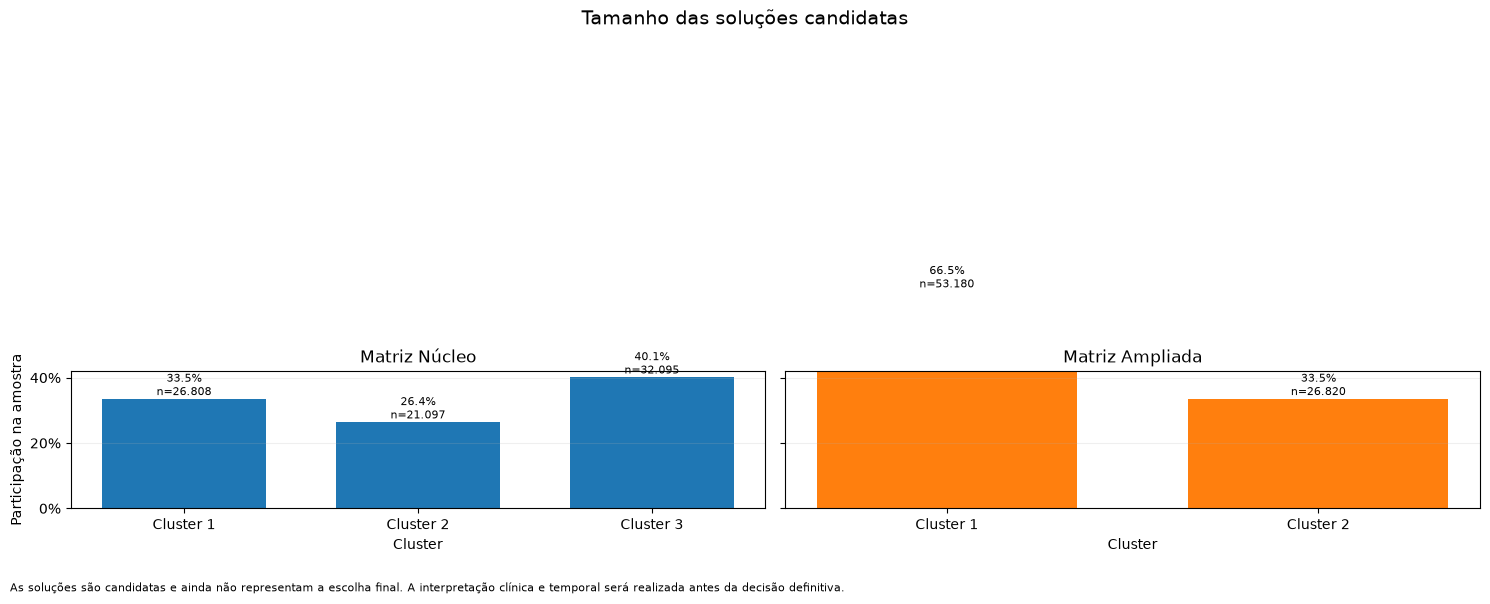

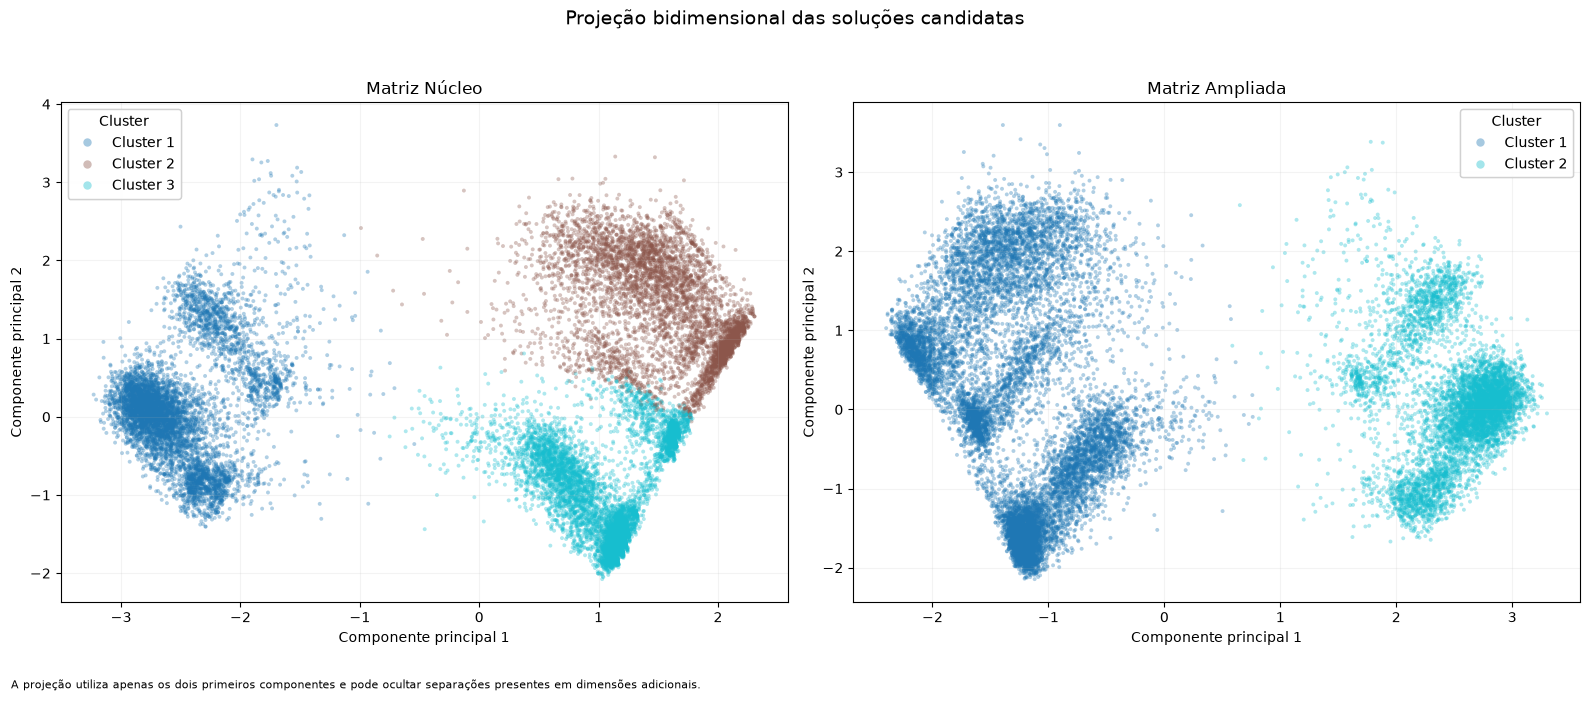

Soluções candidatas materializadas para: ['nucleo', 'ampliada']


,matriz,quantidade_clusters,quantidade_componentes_pca,quantidade_registros,inercia_total,inercia_por_registro,menor_cluster_percentual,maior_cluster_percentual
0,nucleo,3,19,80000,456975.6250,5.712195,26.37125,40.11875
1,ampliada,2,34,80000,711668.9375,8.895862,33.52500,66.47500


,matriz_clustering,cluster,cluster_rotulo,quantidade_registros,percentual_amostra
0,nucleo,0,Cluster 1,26808,33.51000
1,nucleo,1,Cluster 2,21097,26.37125
2,nucleo,2,Cluster 3,32095,40.11875
3,ampliada,0,Cluster 1,53180,66.47500
4,ampliada,1,Cluster 2,26820,33.52500


In [114]:
from sklearn.cluster import MiniBatchKMeans


OBJETOS_SOLUCOES_CANDIDATAS_NECESSARIOS = [
    "melhores_candidatos_estabilidade",
    "representacao_pca_nucleo_90",
    "representacao_pca_ampliada_90",
    "coordenadas_pca_nucleo_2d",
    "coordenadas_pca_ampliada_2d",
    "metadados_amostra_desenvolvimento",
    "SEMENTE_CLUSTERING",
]

objetos_solucoes_candidatas_ausentes = [
    nome
    for nome in OBJETOS_SOLUCOES_CANDIDATAS_NECESSARIOS
    if nome not in globals()
]

if objetos_solucoes_candidatas_ausentes:
    raise NameError(
        "Execute primeiro a análise de estabilidade. Objetos ausentes: "
        f"{objetos_solucoes_candidatas_ausentes}"
    )

if melhores_candidatos_estabilidade.empty:
    raise ValueError(
        "A tabela de melhores candidatos está vazia."
    )

MATRIZES_ESPERADAS_SOLUCAO = [
    "nucleo",
    "ampliada",
]

matrizes_candidatas_disponiveis = set(
    melhores_candidatos_estabilidade[
        "matriz"
    ]
    .astype("string")
    .tolist()
)

matrizes_candidatas_ausentes = [
    matriz
    for matriz in MATRIZES_ESPERADAS_SOLUCAO
    if matriz not in matrizes_candidatas_disponiveis
]

if matrizes_candidatas_ausentes:
    raise ValueError(
        "Não há melhor candidato registrado para as matrizes: "
        f"{matrizes_candidatas_ausentes}"
    )

TAMANHO_LOTE_SOLUCAO = 2_048
N_INIT_SOLUCAO = 30
MAX_ITER_SOLUCAO = 300
TAMANHO_MAXIMO_PROJECAO = 20_000

representacoes_solucao = {
    "nucleo": representacao_pca_nucleo_90,
    "ampliada": representacao_pca_ampliada_90,
}

coordenadas_2d_solucao = {
    "nucleo": coordenadas_pca_nucleo_2d,
    "ampliada": coordenadas_pca_ampliada_2d,
}

modelos_solucoes_candidatas = {}
rotulos_solucoes_candidatas = {}
atribuicoes_solucoes_candidatas = {}
tabelas_tamanho_clusters = []
registros_resumo_solucoes = []

for nome_matriz in MATRIZES_ESPERADAS_SOLUCAO:
    linha_candidata = (
        melhores_candidatos_estabilidade.loc[
            melhores_candidatos_estabilidade[
                "matriz"
            ].eq(nome_matriz)
        ]
        .copy()
    )

    if len(linha_candidata) != 1:
        raise RuntimeError(
            "Era esperado exatamente um candidato para a matriz "
            f"{nome_matriz}, mas foram encontrados {len(linha_candidata)}."
        )

    quantidade_clusters = int(
        linha_candidata[
            "quantidade_clusters"
        ].iloc[0]
    )

    representacao = representacoes_solucao[
        nome_matriz
    ]

    if not representacao.index.equals(
        metadados_amostra_desenvolvimento.index
    ):
        raise RuntimeError(
            "A representação PCA da matriz "
            f"{nome_matriz} não está alinhada aos metadados."
        )

    valores = representacao.to_numpy(
        dtype=np.float32,
        copy=False,
    )

    modelo = MiniBatchKMeans(
        n_clusters=quantidade_clusters,
        init="k-means++",
        n_init=N_INIT_SOLUCAO,
        max_iter=MAX_ITER_SOLUCAO,
        batch_size=TAMANHO_LOTE_SOLUCAO,
        compute_labels=True,
        random_state=(
            SEMENTE_CLUSTERING
            + 10_000
            + quantidade_clusters
            + (
                0
                if nome_matriz == "nucleo"
                else 1_000
            )
        ),
        reassignment_ratio=0.01,
    )

    rotulos = modelo.fit_predict(
        valores
    )

    clusters_observados = sorted(
        np.unique(rotulos).tolist()
    )

    if len(clusters_observados) != quantidade_clusters:
        raise RuntimeError(
            f"A solução {nome_matriz} esperava {quantidade_clusters} "
            f"clusters, mas produziu {len(clusters_observados)}."
        )

    atribuicoes = (
        metadados_amostra_desenvolvimento.copy()
    )

    atribuicoes[
        "matriz_clustering"
    ] = nome_matriz

    atribuicoes[
        "cluster"
    ] = rotulos.astype("int16")

    atribuicoes[
        "cluster_rotulo"
    ] = (
        "Cluster "
        + atribuicoes[
            "cluster"
        ]
        .add(1)
        .astype("string")
    )

    tamanho_clusters = (
        atribuicoes.groupby(
            [
                "matriz_clustering",
                "cluster",
                "cluster_rotulo",
            ],
            dropna=False,
        )
        .size()
        .rename(
            "quantidade_registros"
        )
        .reset_index()
    )

    tamanho_clusters[
        "percentual_amostra"
    ] = (
        tamanho_clusters[
            "quantidade_registros"
        ]
        .div(len(atribuicoes))
        .mul(100)
    )

    tamanho_clusters = (
        tamanho_clusters.sort_values(
            "cluster"
        )
        .reset_index(drop=True)
    )

    if int(
        tamanho_clusters[
            "quantidade_registros"
        ].sum()
    ) != len(atribuicoes):
        raise RuntimeError(
            f"A soma dos clusters da matriz {nome_matriz} "
            "não corresponde ao tamanho da amostra."
        )

    if not np.isclose(
        tamanho_clusters[
            "percentual_amostra"
        ].sum(),
        100.0,
        atol=1e-6,
    ):
        raise RuntimeError(
            f"Os percentuais dos clusters da matriz {nome_matriz} "
            "não somam aproximadamente 100%."
        )

    modelos_solucoes_candidatas[
        nome_matriz
    ] = modelo

    rotulos_solucoes_candidatas[
        nome_matriz
    ] = rotulos

    atribuicoes_solucoes_candidatas[
        nome_matriz
    ] = atribuicoes

    tabelas_tamanho_clusters.append(
        tamanho_clusters
    )

    registros_resumo_solucoes.append(
        {
            "matriz": nome_matriz,
            "quantidade_clusters": quantidade_clusters,
            "quantidade_componentes_pca": representacao.shape[1],
            "quantidade_registros": len(atribuicoes),
            "inercia_total": float(modelo.inertia_),
            "inercia_por_registro": float(
                modelo.inertia_
                / len(atribuicoes)
            ),
            "menor_cluster_percentual": float(
                tamanho_clusters[
                    "percentual_amostra"
                ].min()
            ),
            "maior_cluster_percentual": float(
                tamanho_clusters[
                    "percentual_amostra"
                ].max()
            ),
        }
    )


tamanho_clusters_candidatos = pd.concat(
    tabelas_tamanho_clusters,
    ignore_index=True,
)

resumo_solucoes_candidatas = pd.DataFrame(
    registros_resumo_solucoes
)

figura_tamanho_clusters, eixos_tamanho_clusters = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(
        15,
        6,
    ),
    sharey=True,
)

for indice_eixo, nome_matriz in enumerate(
    MATRIZES_ESPERADAS_SOLUCAO
):
    eixo = eixos_tamanho_clusters[
        indice_eixo
    ]

    dados_matriz = (
        tamanho_clusters_candidatos.loc[
            tamanho_clusters_candidatos[
                "matriz_clustering"
            ].eq(nome_matriz)
        ]
        .sort_values("cluster")
    )

    cor = CORES_MATRIZES_CLUSTERING[
        nome_matriz
    ]

    barras = eixo.bar(
        dados_matriz[
            "cluster_rotulo"
        ],
        dados_matriz[
            "percentual_amostra"
        ],
        color=cor,
        width=0.70,
    )

    eixo.set_title(
        f"Matriz {ROTULOS_MATRIZES_CLUSTERING[nome_matriz]}"
    )

    eixo.set_xlabel(
        "Cluster"
    )

    eixo.set_ylim(
        bottom=0
    )

    eixo.yaxis.set_major_formatter(
        plt.FuncFormatter(
            lambda valor, posicao: (
                f"{valor:.0f}%"
            )
        )
    )

    eixo.grid(
        axis="y",
        alpha=0.20,
    )

    for barra, percentual, quantidade in zip(
        barras,
        dados_matriz[
            "percentual_amostra"
        ],
        dados_matriz[
            "quantidade_registros"
        ],
    ):
        eixo.text(
            barra.get_x()
            + barra.get_width()
            / 2,
            barra.get_height(),
            (
                f"{percentual:.1f}%\n"
                f"n={int(quantidade):,}"
                .replace(",", ".")
            ),
            ha="center",
            va="bottom",
            fontsize=8,
        )


eixos_tamanho_clusters[0].set_ylabel(
    "Participação na amostra"
)

figura_tamanho_clusters.suptitle(
    "Tamanho das soluções candidatas",
    fontsize=14,
)

figura_tamanho_clusters.text(
    0.01,
    0.01,
    (
        "As soluções são candidatas e ainda não representam a escolha "
        "final. A interpretação clínica e temporal será realizada antes "
        "da decisão definitiva."
    ),
    fontsize=8,
)

figura_tamanho_clusters.tight_layout(
    rect=[
        0,
        0.05,
        1,
        0.95,
    ]
)

plt.show()

plt.close(
    figura_tamanho_clusters
)

figura_projecao_clusters, eixos_projecao_clusters = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(
        16,
        7,
    ),
)

for indice_eixo, nome_matriz in enumerate(
    MATRIZES_ESPERADAS_SOLUCAO
):
    eixo = eixos_projecao_clusters[
        indice_eixo
    ]

    coordenadas = coordenadas_2d_solucao[
        nome_matriz
    ].copy()

    atribuicoes = atribuicoes_solucoes_candidatas[
        nome_matriz
    ][
        [
            "cluster",
            "cluster_rotulo",
        ]
    ]

    dados_projecao = coordenadas.join(
        atribuicoes,
        how="inner",
        validate="one_to_one",
    )

    if len(dados_projecao) > TAMANHO_MAXIMO_PROJECAO:
        dados_projecao = dados_projecao.sample(
            n=TAMANHO_MAXIMO_PROJECAO,
            replace=False,
            random_state=(
                SEMENTE_CLUSTERING
                + (
                    20_000
                    if nome_matriz == "nucleo"
                    else 30_000
                )
            ),
        )

    dispersao = eixo.scatter(
        dados_projecao[
            "componente_1"
        ],
        dados_projecao[
            "componente_2"
        ],
        c=dados_projecao[
            "cluster"
        ],
        cmap="tab10",
        s=8,
        alpha=0.35,
        linewidths=0,
    )

    eixo.set_title(
        f"Matriz {ROTULOS_MATRIZES_CLUSTERING[nome_matriz]}"
    )

    eixo.set_xlabel(
        "Componente principal 1"
    )

    eixo.set_ylabel(
        "Componente principal 2"
    )

    eixo.grid(
        alpha=0.15,
    )

    legenda = eixo.legend(
        handles=dispersao.legend_elements()[0],
        labels=(
            dados_projecao[
                "cluster_rotulo"
            ]
            .drop_duplicates()
            .sort_values()
            .tolist()
        ),
        title="Cluster",
        loc="best",
    )

    eixo.add_artist(
        legenda
    )

figura_projecao_clusters.suptitle(
    "Projeção bidimensional das soluções candidatas",
    fontsize=14,
)

figura_projecao_clusters.text(
    0.01,
    0.01,
    (
        "A projeção utiliza apenas os dois primeiros componentes e pode "
        "ocultar separações presentes em dimensões adicionais."
    ),
    fontsize=8,
)

figura_projecao_clusters.tight_layout(
    rect=[
        0,
        0.05,
        1,
        0.95,
    ]
)

plt.show()

plt.close(
    figura_projecao_clusters
)

print(
    "Soluções candidatas materializadas para:",
    MATRIZES_ESPERADAS_SOLUCAO,
)

display(
    resumo_solucoes_candidatas
)

display(
    tamanho_clusters_candidatos
)


### Interpretação dos componentes e perfis dos clusters

As soluções candidatas serão caracterizadas utilizando as variáveis
originais da amostra.

A análise avaliará:

- features com maior contribuição para o primeiro componente principal;
- idade e intervalo entre sintomas e internação;
- quantidade de sintomas e comorbidades;
- prevalência dos sintomas e comorbidades entre respostas válidas;
- ausência de respostas clínicas;
- composição por sexo registrado;
- composição temporal;
- distribuição posterior do desfecho.

O desfecho não participou da formação dos clusters. Sua distribuição
será apresentada exclusivamente como caracterização posterior.

O sinal dos loadings do PCA pode ser invertido sem alterar a solução.
Por isso, a interpretação deve priorizar a magnitude absoluta e a
associação de cada lado do componente aos clusters observados.

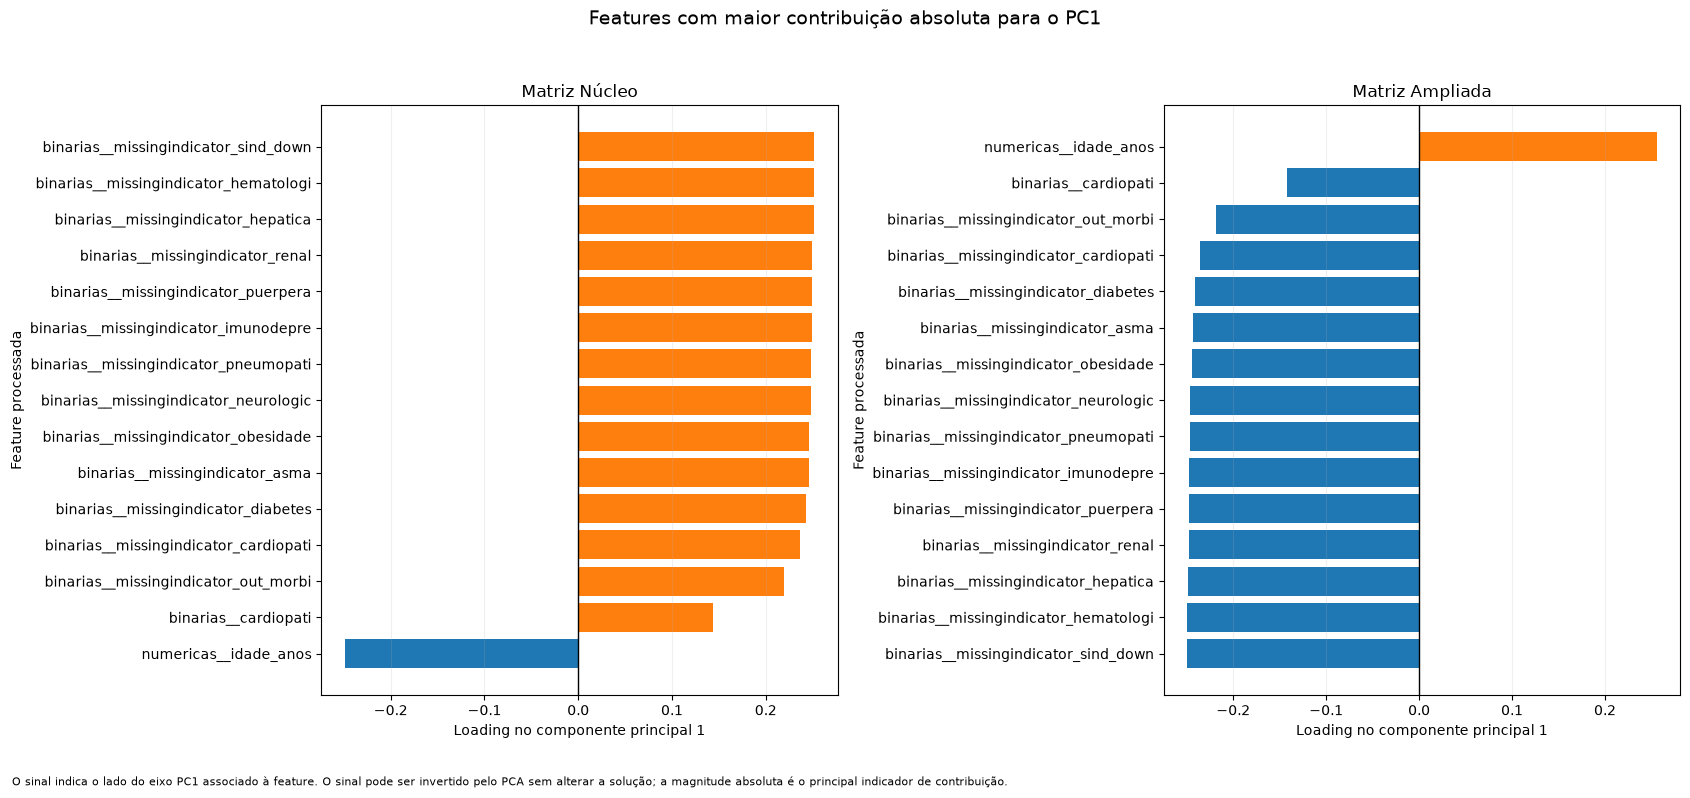

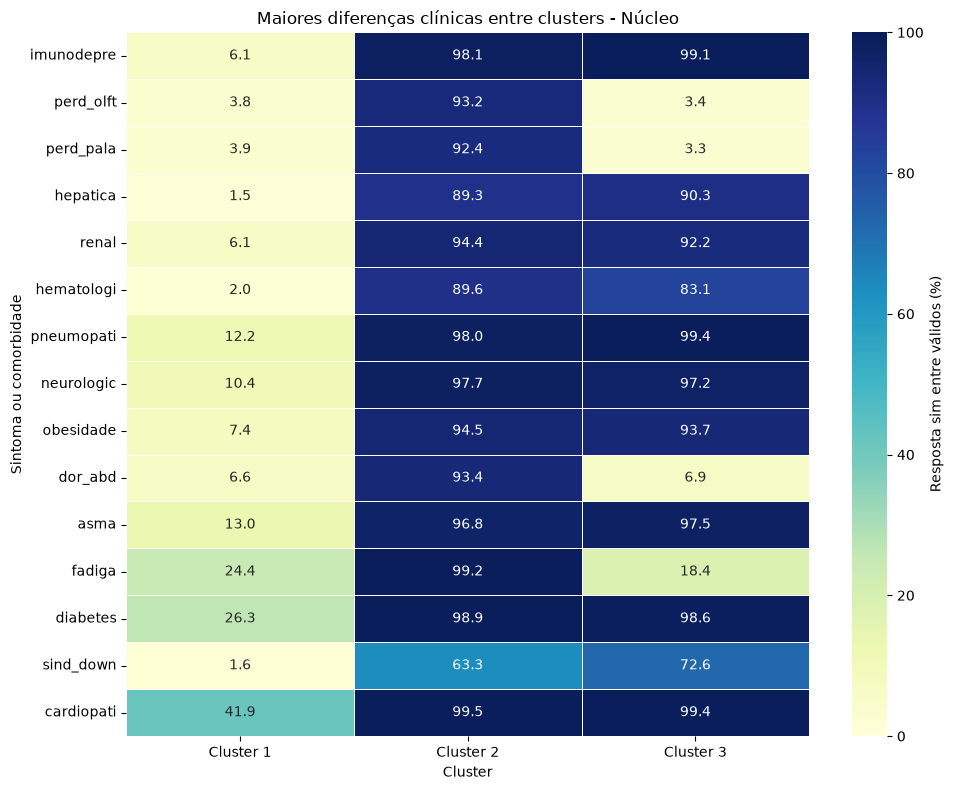

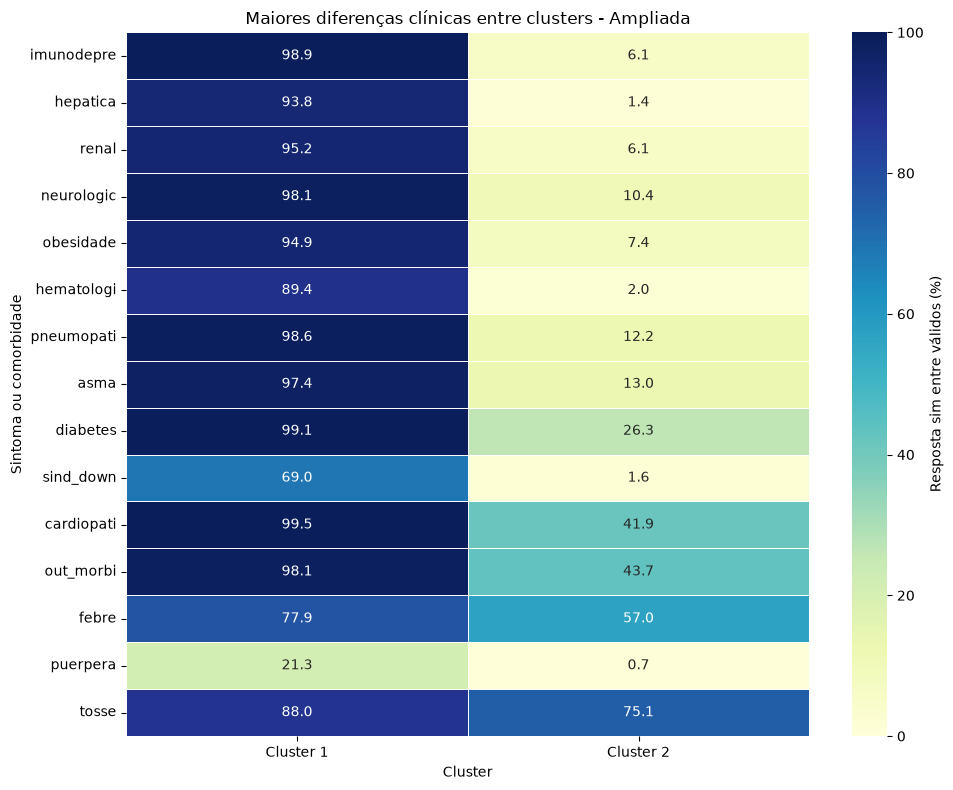

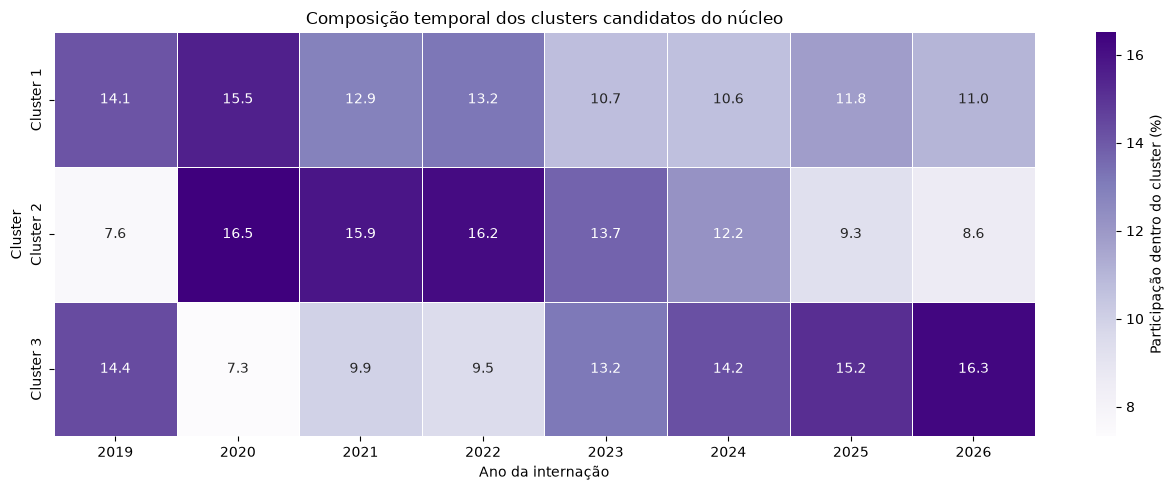

Loadings destacados por matriz: 15
Perfis clínicos e temporais calculados para: ['nucleo', 'ampliada']


,matriz,feature_processada,loading_pc1,loading_pc2,loading_absoluto_pc1,loading_absoluto_pc2
0,ampliada,numericas__idade_anos,0.255423,0.460646,0.255423,0.460646
1,ampliada,binarias__missingindicator_sind_down,-0.249444,-0.021137,0.249444,0.021137
2,ampliada,binarias__missingindicator_hematologi,-0.249225,-0.021780,0.249225,0.021780
3,ampliada,binarias__missingindicator_hepatica,-0.249126,-0.021660,0.249126,0.021660
4,ampliada,binarias__missingindicator_renal,-0.247305,-0.027748,0.247305,0.027748
5,ampliada,binarias__missingindicator_puerpera,-0.247192,-0.022439,0.247192,0.022439
6,ampliada,binarias__missingindicator_imunodepre,-0.247098,-0.026162,0.247098,0.026162
7,ampliada,binarias__missingindicator_pneumopati,-0.246855,-0.031934,0.246855,0.031934
8,ampliada,binarias__missingindicator_neurologic,-0.246424,-0.031060,0.246424,0.031060
9,ampliada,binarias__missingindicator_obesidade,-0.244049,-0.027513,0.244049,0.027513


,matriz,cluster_rotulo,variavel,quantidade_cluster,quantidade_preenchida,media,mediana,desvio_padrao,percentil_25,percentil_75
0,nucleo,Cluster 1,idade_anos,26808,26808,52.477665,62.0,29.880089,30.000000,76.0
1,nucleo,Cluster 1,dias_sintomas_ate_internacao,26808,26808,4.366420,3.0,4.963450,1.000000,6.0
2,nucleo,Cluster 1,n_sintomas_confirmados,26808,26808,4.374291,4.0,1.663191,3.000000,5.0
3,nucleo,Cluster 1,n_sintomas_avaliados,26808,26808,11.918681,13.0,1.942576,12.000000,13.0
4,nucleo,Cluster 1,n_comorbidades_confirmadas,26808,26808,1.695240,1.0,0.939257,1.000000,2.0
5,nucleo,Cluster 1,n_comorbidades_avaliadas,26808,26808,12.842211,13.0,0.520275,13.000000,13.0
6,nucleo,Cluster 2,idade_anos,21097,21096,41.788784,48.0,32.412201,3.000000,71.0
7,nucleo,Cluster 2,dias_sintomas_ate_internacao,21097,21097,4.537565,3.0,5.022274,1.000000,6.0
8,nucleo,Cluster 2,n_sintomas_confirmados,21097,21097,3.661658,4.0,1.647906,3.000000,5.0
9,nucleo,Cluster 2,n_sintomas_avaliados,21097,21097,4.075129,4.0,2.154064,3.000000,5.0


,matriz,cluster_rotulo,variavel,categoria,quantidade,percentual_cluster
0,nucleo,Cluster 1,sexo_categoria,feminino,13618,50.798269
1,nucleo,Cluster 1,sexo_categoria,masculino,13190,49.201731
2,nucleo,Cluster 1,alvo_obito_srag,0,21093,78.681737
3,nucleo,Cluster 1,alvo_obito_srag,1,5715,21.318263
4,nucleo,Cluster 2,sexo_categoria,masculino,11131,52.761056
5,nucleo,Cluster 2,sexo_categoria,feminino,9961,47.215244
6,nucleo,Cluster 2,sexo_categoria,ignorado,5,0.023700
7,nucleo,Cluster 2,alvo_obito_srag,0,17333,82.158601
8,nucleo,Cluster 2,alvo_obito_srag,1,3764,17.841399
9,nucleo,Cluster 3,sexo_categoria,masculino,17508,54.550553


,matriz,cluster_rotulo,variavel,quantidade_cluster,quantidade_resposta_valida,quantidade_sim,percentual_sim_validos,percentual_sem_resposta
0,nucleo,Cluster 1,febre,26808,26507,15113,57.015128,1.122799
1,nucleo,Cluster 1,tosse,26808,26592,19979,75.131619,0.805730
2,nucleo,Cluster 1,garganta,26808,25888,3592,13.875155,3.431811
3,nucleo,Cluster 1,dispneia,26808,26602,20347,76.486730,0.768427
4,nucleo,Cluster 1,desc_resp,26808,26549,18327,69.030849,0.966130
...,...,...,...,...,...,...,...,...
125,ampliada,Cluster 2,pneumopati,26820,26651,3247,12.183408,0.630127
126,ampliada,Cluster 2,imunodepre,26820,26599,1615,6.071657,0.824012
127,ampliada,Cluster 2,renal,26820,26549,1631,6.143358,1.010440
128,ampliada,Cluster 2,obesidade,26820,26212,1952,7.446971,2.266965


,matriz,cluster_rotulo,ano_internacao,quantidade,percentual_cluster
0,nucleo,Cluster 1,2020,4167,15.543868
1,nucleo,Cluster 1,2019,3790,14.137571
2,nucleo,Cluster 1,2022,3545,13.223665
3,nucleo,Cluster 1,2021,3453,12.880483
4,nucleo,Cluster 1,2025,3173,11.836019
5,nucleo,Cluster 1,2026,2954,11.019099
6,nucleo,Cluster 1,2023,2876,10.728141
7,nucleo,Cluster 1,2024,2850,10.631155
8,nucleo,Cluster 2,2020,3483,16.509456
9,nucleo,Cluster 2,2022,3409,16.158696


In [115]:
OBJETOS_PERFIS_NECESSARIOS = [
    "atribuicoes_solucoes_candidatas",
    "amostra_desenvolvimento",
    "matriz_binaria_nucleo_bruta",
    "pca_nucleo",
    "pca_ampliada",
    "FEATURES_MODELAGEM_NUCLEO",
    "FEATURES_MODELAGEM_AMPLIADA",
]

objetos_perfis_ausentes = [
    nome
    for nome in OBJETOS_PERFIS_NECESSARIOS
    if nome not in globals()
]

if objetos_perfis_ausentes:
    raise NameError(
        "Execute primeiro a materialização das soluções candidatas. "
        "Objetos ausentes: "
        f"{objetos_perfis_ausentes}"
    )


QUANTIDADE_LOADINGS_EXIBIDOS = 15


def criar_tabela_loadings(
    nome_matriz,
    pca_ajustado,
    nomes_features,
):
    quantidade_features_pca = pca_ajustado.components_.shape[1]

    if quantidade_features_pca != len(nomes_features):
        raise RuntimeError(
            f"O PCA da matriz {nome_matriz} possui "
            f"{quantidade_features_pca} features, mas a lista "
            f"de nomes possui {len(nomes_features)}."
        )

    tabela = pd.DataFrame(
        {
            "matriz": nome_matriz,
            "feature_processada": nomes_features,
            "loading_pc1": pca_ajustado.components_[0],
            "loading_pc2": pca_ajustado.components_[1],
        }
    )

    tabela[
        "loading_absoluto_pc1"
    ] = tabela[
        "loading_pc1"
    ].abs()

    tabela[
        "loading_absoluto_pc2"
    ] = tabela[
        "loading_pc2"
    ].abs()

    return tabela


loadings_nucleo = criar_tabela_loadings(
    nome_matriz="nucleo",
    pca_ajustado=pca_nucleo,
    nomes_features=FEATURES_MODELAGEM_NUCLEO,
)

loadings_ampliada = criar_tabela_loadings(
    nome_matriz="ampliada",
    pca_ajustado=pca_ampliada,
    nomes_features=FEATURES_MODELAGEM_AMPLIADA,
)

loadings_pca = pd.concat(
    [
        loadings_nucleo,
        loadings_ampliada,
    ],
    ignore_index=True,
)

loadings_pc1_destaque = (
    loadings_pca.sort_values(
        [
            "matriz",
            "loading_absoluto_pc1",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .groupby(
        "matriz",
        as_index=False,
        sort=False,
    )
    .head(
        QUANTIDADE_LOADINGS_EXIBIDOS
    )
    .reset_index(drop=True)
)

figura_loadings, eixos_loadings = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(
        17,
        8,
    ),
)

for indice_eixo, nome_matriz in enumerate(
    [
        "nucleo",
        "ampliada",
    ]
):
    eixo = eixos_loadings[indice_eixo]

    dados = (
        loadings_pc1_destaque.loc[
            loadings_pc1_destaque[
                "matriz"
            ].eq(nome_matriz)
        ]
        .sort_values(
            "loading_pc1"
        )
    )

    cores = [
        "tab:blue"
        if valor < 0
        else "tab:orange"
        for valor in dados[
            "loading_pc1"
        ]
    ]

    eixo.barh(
        dados[
            "feature_processada"
        ],
        dados[
            "loading_pc1"
        ],
        color=cores,
    )

    eixo.axvline(
        x=0,
        color="black",
        linewidth=1,
    )

    eixo.set_title(
        "Matriz "
        + ROTULOS_MATRIZES_CLUSTERING[
            nome_matriz
        ]
    )

    eixo.set_xlabel(
        "Loading no componente principal 1"
    )

    eixo.set_ylabel(
        "Feature processada"
    )

    eixo.grid(
        axis="x",
        alpha=0.20,
    )

figura_loadings.suptitle(
    "Features com maior contribuição absoluta para o PC1",
    fontsize=14,
)

figura_loadings.text(
    0.01,
    0.01,
    (
        "O sinal indica o lado do eixo PC1 associado à feature. "
        "O sinal pode ser invertido pelo PCA sem alterar a solução; "
        "a magnitude absoluta é o principal indicador de contribuição."
    ),
    fontsize=8,
)

figura_loadings.tight_layout(
    rect=[
        0,
        0.05,
        1,
        0.95,
    ]
)

plt.show()

plt.close(
    figura_loadings
)

COLUNAS_NUMERICAS_PERFIL = [
    "idade_anos",
    "dias_sintomas_ate_internacao",
    "n_sintomas_confirmados",
    "n_sintomas_avaliados",
    "n_comorbidades_confirmadas",
    "n_comorbidades_avaliadas",
]

colunas_numericas_perfil_disponiveis = [
    coluna
    for coluna in COLUNAS_NUMERICAS_PERFIL
    if coluna in amostra_desenvolvimento.columns
]

registros_perfis_numericos = []
registros_perfis_categoricos = []
registros_perfis_binarios = []
registros_perfis_temporais = []

for nome_matriz in [
    "nucleo",
    "ampliada",
]:
    atribuicoes = atribuicoes_solucoes_candidatas[
        nome_matriz
    ][
        [
            "cluster",
            "cluster_rotulo",
        ]
    ]

    if not atribuicoes.index.equals(
        amostra_desenvolvimento.index
    ):
        raise RuntimeError(
            f"As atribuições da matriz {nome_matriz} "
            "não estão alinhadas à amostra."
        )

    base_perfil = amostra_desenvolvimento.join(
        atribuicoes,
        how="inner",
        validate="one_to_one",
    )

    for cluster_rotulo, dados_cluster in base_perfil.groupby(
        "cluster_rotulo",
        dropna=False,
    ):
        quantidade_cluster = len(
            dados_cluster
        )

        for coluna in colunas_numericas_perfil_disponiveis:
            serie_numerica = pd.to_numeric(
                dados_cluster[
                    coluna
                ],
                errors="coerce",
            )

            registros_perfis_numericos.append(
                {
                    "matriz": nome_matriz,
                    "cluster_rotulo": cluster_rotulo,
                    "variavel": coluna,
                    "quantidade_cluster": quantidade_cluster,
                    "quantidade_preenchida": int(
                        serie_numerica.notna().sum()
                    ),
                    "media": float(
                        serie_numerica.mean()
                    ),
                    "mediana": float(
                        serie_numerica.median()
                    ),
                    "desvio_padrao": float(
                        serie_numerica.std(ddof=0)
                    ),
                    "percentil_25": float(
                        serie_numerica.quantile(0.25)
                    ),
                    "percentil_75": float(
                        serie_numerica.quantile(0.75)
                    ),
                }
            )

        for coluna_categorica in [
            "sexo_categoria",
            "alvo_obito_srag",
        ]:
            if coluna_categorica not in dados_cluster.columns:
                continue

            distribuicao = (
                dados_cluster[
                    coluna_categorica
                ]
                .astype("string")
                .fillna("Ausente")
                .value_counts(
                    dropna=False
                )
                .rename_axis("categoria")
                .rename("quantidade")
                .reset_index()
            )

            distribuicao[
                "percentual_cluster"
            ] = (
                distribuicao[
                    "quantidade"
                ]
                .div(quantidade_cluster)
                .mul(100)
            )

            for _, linha in distribuicao.iterrows():
                registros_perfis_categoricos.append(
                    {
                        "matriz": nome_matriz,
                        "cluster_rotulo": cluster_rotulo,
                        "variavel": coluna_categorica,
                        "categoria": linha[
                            "categoria"
                        ],
                        "quantidade": int(
                            linha[
                                "quantidade"
                            ]
                        ),
                        "percentual_cluster": float(
                            linha[
                                "percentual_cluster"
                            ]
                        ),
                    }
                )

        if "ano_internacao" in dados_cluster.columns:
            distribuicao_ano = (
                dados_cluster[
                    "ano_internacao"
                ]
                .value_counts(
                    dropna=False
                )
                .rename_axis("ano_internacao")
                .rename("quantidade")
                .reset_index()
            )

            distribuicao_ano[
                "percentual_cluster"
            ] = (
                distribuicao_ano[
                    "quantidade"
                ]
                .div(quantidade_cluster)
                .mul(100)
            )

            for _, linha in distribuicao_ano.iterrows():
                registros_perfis_temporais.append(
                    {
                        "matriz": nome_matriz,
                        "cluster_rotulo": cluster_rotulo,
                        "ano_internacao": linha[
                            "ano_internacao"
                        ],
                        "quantidade": int(
                            linha[
                                "quantidade"
                            ]
                        ),
                        "percentual_cluster": float(
                            linha[
                                "percentual_cluster"
                            ]
                        ),
                    }
                )

    matriz_binaria_com_cluster = matriz_binaria_nucleo_bruta.join(
        atribuicoes,
        how="inner",
        validate="one_to_one",
    )

    colunas_binarias_perfil = [
        coluna
        for coluna in (
            COLUNAS_SINTOMAS
            + COLUNAS_COMORBIDADES
        )
        if coluna in matriz_binaria_com_cluster.columns
    ]

    for cluster_rotulo, dados_cluster in (
        matriz_binaria_com_cluster.groupby(
            "cluster_rotulo",
            dropna=False,
        )
    ):
        quantidade_cluster = len(
            dados_cluster
        )

        for coluna in colunas_binarias_perfil:
            serie = dados_cluster[
                coluna
            ]

            quantidade_valida = int(
                serie.notna().sum()
            )

            quantidade_sim = int(
                serie.eq(1.0).sum()
            )

            percentual_sim_validos = (
                quantidade_sim
                / quantidade_valida
                * 100
                if quantidade_valida > 0
                else np.nan
            )

            percentual_sem_resposta = (
                serie.isna().sum()
                / quantidade_cluster
                * 100
                if quantidade_cluster > 0
                else np.nan
            )

            registros_perfis_binarios.append(
                {
                    "matriz": nome_matriz,
                    "cluster_rotulo": cluster_rotulo,
                    "variavel": coluna,
                    "quantidade_cluster": quantidade_cluster,
                    "quantidade_resposta_valida": quantidade_valida,
                    "quantidade_sim": quantidade_sim,
                    "percentual_sim_validos": percentual_sim_validos,
                    "percentual_sem_resposta": percentual_sem_resposta,
                }
            )


perfis_numericos_clusters = pd.DataFrame(
    registros_perfis_numericos
)

perfis_categoricos_clusters = pd.DataFrame(
    registros_perfis_categoricos
)

perfis_binarios_clusters = pd.DataFrame(
    registros_perfis_binarios
)

perfis_temporais_clusters = pd.DataFrame(
    registros_perfis_temporais
)

if perfis_numericos_clusters.empty:
    raise ValueError(
        "A tabela de perfis numéricos está vazia."
    )

if perfis_binarios_clusters.empty:
    raise ValueError(
        "A tabela de perfis binários está vazia."
    )

if perfis_temporais_clusters.empty:
    raise ValueError(
        "A tabela de perfis temporais está vazia."
    )

matriz_perfil_clinico = (
    perfis_binarios_clusters.pivot_table(
        index=[
            "matriz",
            "cluster_rotulo",
            "variavel",
        ],
        values="percentual_sim_validos",
        aggfunc="first",
    )
    .reset_index()
)

for nome_matriz in [
    "nucleo",
    "ampliada",
]:
    dados_matriz = matriz_perfil_clinico.loc[
        matriz_perfil_clinico[
            "matriz"
        ].eq(nome_matriz)
    ]

    matriz_heatmap = dados_matriz.pivot(
        index="variavel",
        columns="cluster_rotulo",
        values="percentual_sim_validos",
    )

    amplitude_por_variavel = (
        matriz_heatmap.max(axis=1)
        - matriz_heatmap.min(axis=1)
    )

    variaveis_destaque = (
        amplitude_por_variavel.sort_values(
            ascending=False
        )
        .head(15)
        .index
        .tolist()
    )

    matriz_heatmap = matriz_heatmap.loc[
        variaveis_destaque
    ]

    figura_perfil, eixo_perfil = plt.subplots(
        figsize=(
            10,
            8,
        )
    )

    sns.heatmap(
        matriz_heatmap,
        annot=True,
        fmt=".1f",
        cmap="YlGnBu",
        vmin=0,
        vmax=100,
        linewidths=0.5,
        linecolor="white",
        cbar_kws={
            "label": "Resposta sim entre válidos (%)",
        },
        ax=eixo_perfil,
    )

    eixo_perfil.set_title(
        "Maiores diferenças clínicas entre clusters - "
        + ROTULOS_MATRIZES_CLUSTERING[
            nome_matriz
        ]
    )

    eixo_perfil.set_xlabel(
        "Cluster"
    )

    eixo_perfil.set_ylabel(
        "Sintoma ou comorbidade"
    )

    figura_perfil.tight_layout()

    plt.show()

    plt.close(
        figura_perfil
    )


matriz_temporal_nucleo = (
    perfis_temporais_clusters.loc[
        perfis_temporais_clusters[
            "matriz"
        ].eq("nucleo")
    ]
    .pivot(
        index="cluster_rotulo",
        columns="ano_internacao",
        values="percentual_cluster",
    )
    .fillna(0)
)

figura_temporal, eixo_temporal = plt.subplots(
    figsize=(
        13,
        5,
    )
)

sns.heatmap(
    matriz_temporal_nucleo,
    annot=True,
    fmt=".1f",
    cmap="Purples",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Participação dentro do cluster (%)",
    },
    ax=eixo_temporal,
)

eixo_temporal.set_title(
    "Composição temporal dos clusters candidatos do núcleo"
)

eixo_temporal.set_xlabel(
    "Ano da internação"
)

eixo_temporal.set_ylabel(
    "Cluster"
)

figura_temporal.tight_layout()

plt.show()

plt.close(
    figura_temporal
)

print(
    "Loadings destacados por matriz:",
    QUANTIDADE_LOADINGS_EXIBIDOS,
)

print(
    "Perfis clínicos e temporais calculados para:",
    [
        "nucleo",
        "ampliada",
    ],
)

display(
    loadings_pc1_destaque
)

display(
    perfis_numericos_clusters
)

display(
    perfis_categoricos_clusters
)

display(
    perfis_binarios_clusters
)

display(
    perfis_temporais_clusters
)


### Sensibilidade sem indicadores de ausência

Os loadings do primeiro componente principal mostraram forte
contribuição dos indicadores de ausência das comorbidades.

Essa estrutura pode fazer com que os clusters representem padrões de
documentação e preenchimento, em vez de perfis predominantemente
clínicos.

Por esse motivo, será executada uma análise de sensibilidade que:

- remove as features com `missingindicator_`;
- mantém os valores imputados;
- refaz o PCA preservando 90% da variância;
- aplica MiniBatch K-Means com dois clusters;
- compara a nova partição com a solução original;
- recalcula silhouette, tamanho dos clusters e composição temporal.

O objetivo não é descartar a importância da ausência, mas verificar se
a estrutura dos clusters permanece quando o padrão de preenchimento
deixa de participar diretamente das distâncias.

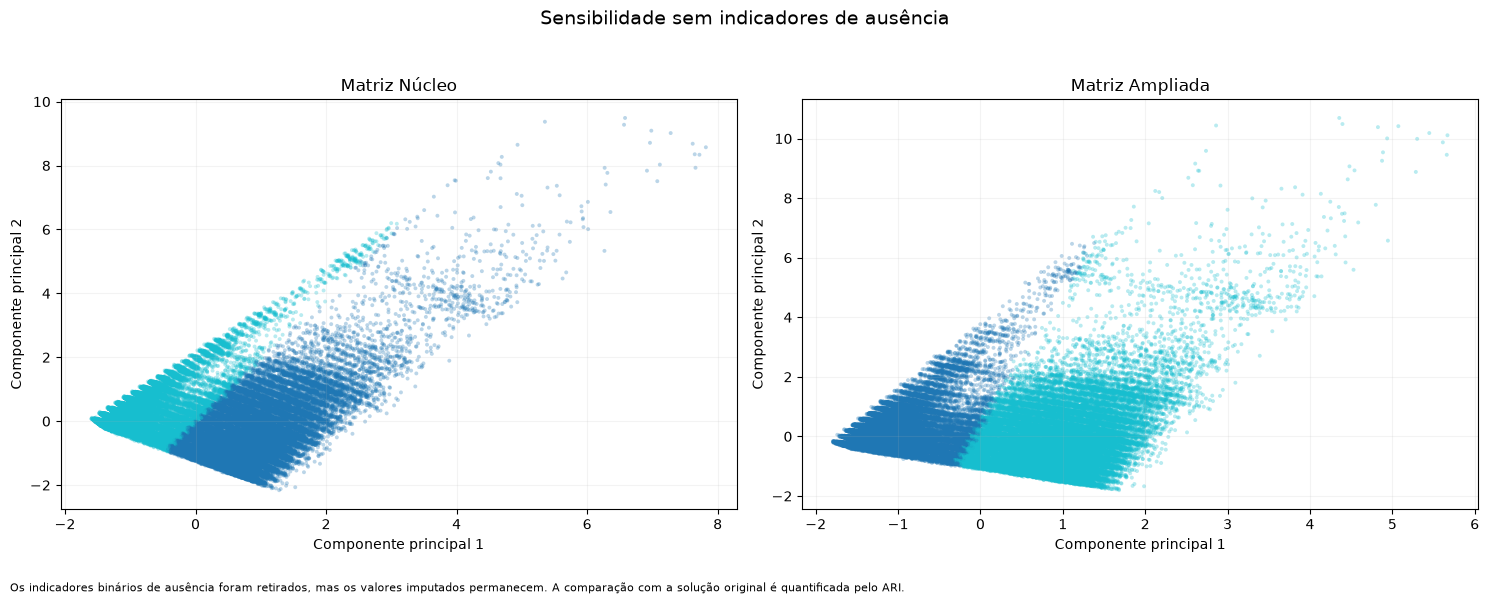

Sensibilidade concluída para k = 2
Interpretação do ARI: próximo de 1 indica solução semelhante; próximo de 0 indica mudança substancial na partição.


,matriz,k,features_processadas_originais,indicadores_ausencia_excluidos,features_variancia_zero_excluidas,features_sensibilidade,componentes_pca_90,variancia_pca_preservada,silhouette_medio,inercia_por_registro,menor_cluster_percentual,maior_cluster_percentual,ari_original_vs_sem_ausencia
0,nucleo,2,58,27,0,31,15,0.916152,0.209915,3.463636,49.87125,50.12875,0.127338
1,ampliada,2,98,29,0,69,30,0.905050,0.155497,5.169159,47.12625,52.87375,0.081700


,matriz,cluster_rotulo,ano_internacao,quantidade,percentual_cluster
0,nucleo,Cluster 1,2019,3175,7.957992
1,nucleo,Cluster 1,2020,8254,20.688272
2,nucleo,Cluster 1,2021,8282,20.758453
3,nucleo,Cluster 1,2022,6264,15.700429
4,nucleo,Cluster 1,2023,3827,9.592200
5,nucleo,Cluster 1,2024,3603,9.030754
6,nucleo,Cluster 1,2025,3499,8.770083
7,nucleo,Cluster 1,2026,2993,7.501817
8,nucleo,Cluster 2,2019,6825,17.018677
9,nucleo,Cluster 2,2020,1746,4.353789


In [116]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score


OBJETOS_SENSIBILIDADE_NECESSARIOS = [
    "matriz_nucleo_processada",
    "matriz_ampliada_processada",
    "atribuicoes_solucoes_candidatas",
    "metadados_amostra_desenvolvimento",
    "SEMENTE_CLUSTERING",
]

objetos_sensibilidade_ausentes = [
    nome
    for nome in OBJETOS_SENSIBILIDADE_NECESSARIOS
    if nome not in globals()
]

if objetos_sensibilidade_ausentes:
    raise NameError(
        "Execute primeiro as soluções candidatas. Objetos ausentes: "
        f"{objetos_sensibilidade_ausentes}"
    )


K_SENSIBILIDADE = 2
VARIANCIA_PCA_SENSIBILIDADE = 0.90
TAMANHO_AMOSTRA_SILHOUETTE_SENSIBILIDADE = 10_000
TAMANHO_LOTE_SENSIBILIDADE = 2_048
N_INIT_SENSIBILIDADE = 30
MAX_ITER_SENSIBILIDADE = 300
LIMITE_VARIANCIA_ZERO_SENSIBILIDADE = 1e-12


def preparar_sensibilidade_sem_ausencia(
    nome_matriz,
    matriz_processada,
):
    colunas_indicadores_ausencia = [
        coluna
        for coluna in matriz_processada.columns
        if "missingindicator_" in coluna
    ]

    colunas_sem_indicadores_ausencia = [
        coluna
        for coluna in matriz_processada.columns
        if coluna not in colunas_indicadores_ausencia
    ]

    if not colunas_sem_indicadores_ausencia:
        raise ValueError(
            f"A matriz {nome_matriz} ficou sem features "
            "após retirar indicadores de ausência."
        )

    matriz_sem_ausencia = (
        matriz_processada[
            colunas_sem_indicadores_ausencia
        ]
        .copy()
    )

    variancias = matriz_sem_ausencia.var(
        axis=0,
        ddof=0,
    )

    colunas_variancia_zero = (
        variancias.loc[
            variancias.le(
                LIMITE_VARIANCIA_ZERO_SENSIBILIDADE
            )
        ]
        .index
        .tolist()
    )

    colunas_modelagem = [
        coluna
        for coluna in matriz_sem_ausencia.columns
        if coluna not in colunas_variancia_zero
    ]

    if not colunas_modelagem:
        raise ValueError(
            f"A matriz {nome_matriz} ficou sem features "
            "após retirar variância zero."
        )

    matriz_modelagem = (
        matriz_sem_ausencia[
            colunas_modelagem
        ]
        .copy()
    )

    if matriz_modelagem.isna().any().any():
        raise RuntimeError(
            f"A matriz {nome_matriz} de sensibilidade contém ausências."
        )

    pca = PCA(
        n_components=VARIANCIA_PCA_SENSIBILIDADE,
        svd_solver="full",
    )

    valores_pca = pca.fit_transform(
        matriz_modelagem.to_numpy(
            dtype=np.float32,
            copy=False,
        )
    )

    representacao_pca = pd.DataFrame(
        valores_pca,
        index=matriz_modelagem.index,
        columns=[
            f"componente_{numero}"
            for numero in range(
                1,
                valores_pca.shape[1] + 1,
            )
        ],
        dtype="float32",
    )

    modelo = MiniBatchKMeans(
        n_clusters=K_SENSIBILIDADE,
        init="k-means++",
        n_init=N_INIT_SENSIBILIDADE,
        max_iter=MAX_ITER_SENSIBILIDADE,
        batch_size=TAMANHO_LOTE_SENSIBILIDADE,
        compute_labels=True,
        random_state=(
            SEMENTE_CLUSTERING
            + 50_000
            + (
                0
                if nome_matriz == "nucleo"
                else 1_000
            )
        ),
        reassignment_ratio=0.01,
    )

    rotulos = modelo.fit_predict(
        representacao_pca.to_numpy(
            dtype=np.float32,
            copy=False,
        )
    )

    tamanho_silhouette = min(
        TAMANHO_AMOSTRA_SILHOUETTE_SENSIBILIDADE,
        len(representacao_pca),
    )

    silhouette = float(
        silhouette_score(
            representacao_pca.to_numpy(
                dtype=np.float32,
                copy=False,
            ),
            rotulos,
            metric="euclidean",
            sample_size=tamanho_silhouette,
            random_state=(
                SEMENTE_CLUSTERING
                + 60_000
            ),
        )
    )

    contagens = pd.Series(
        rotulos
    ).value_counts()

    resumo = {
        "matriz": nome_matriz,
        "k": K_SENSIBILIDADE,
        "features_processadas_originais": matriz_processada.shape[1],
        "indicadores_ausencia_excluidos": len(
            colunas_indicadores_ausencia
        ),
        "features_variancia_zero_excluidas": len(
            colunas_variancia_zero
        ),
        "features_sensibilidade": matriz_modelagem.shape[1],
        "componentes_pca_90": representacao_pca.shape[1],
        "variancia_pca_preservada": float(
            pca.explained_variance_ratio_.sum()
        ),
        "silhouette_medio": silhouette,
        "inercia_por_registro": float(
            modelo.inertia_
            / len(representacao_pca)
        ),
        "menor_cluster_percentual": float(
            contagens.min()
            / len(representacao_pca)
            * 100
        ),
        "maior_cluster_percentual": float(
            contagens.max()
            / len(representacao_pca)
            * 100
        ),
    }

    return {
        "matriz_modelagem": matriz_modelagem,
        "pca": pca,
        "representacao_pca": representacao_pca,
        "modelo": modelo,
        "rotulos": rotulos,
        "resumo": resumo,
        "colunas_indicadores_ausencia": (
            colunas_indicadores_ausencia
        ),
    }


resultados_sensibilidade = {}
registros_resumo_sensibilidade = []

for nome_matriz, matriz_processada in {
    "nucleo": matriz_nucleo_processada,
    "ampliada": matriz_ampliada_processada,
}.items():
    resultado = preparar_sensibilidade_sem_ausencia(
        nome_matriz=nome_matriz,
        matriz_processada=matriz_processada,
    )

    resultados_sensibilidade[
        nome_matriz
    ] = resultado

    registros_resumo_sensibilidade.append(
        resultado[
            "resumo"
        ]
    )


resumo_sensibilidade_sem_ausencia = pd.DataFrame(
    registros_resumo_sensibilidade
)

comparacao_rotulos_sensibilidade = []

for nome_matriz in [
    "nucleo",
    "ampliada",
]:
    rotulos_originais = (
        atribuicoes_solucoes_candidatas[
            nome_matriz
        ][
            "cluster"
        ]
        .to_numpy()
    )

    rotulos_sensibilidade = resultados_sensibilidade[
        nome_matriz
    ][
        "rotulos"
    ]

    ari_original_sensibilidade = float(
        adjusted_rand_score(
            rotulos_originais,
            rotulos_sensibilidade,
        )
    )

    comparacao_rotulos_sensibilidade.append(
        {
            "matriz": nome_matriz,
            "ari_original_vs_sem_ausencia": (
                ari_original_sensibilidade
            ),
        }
    )


comparacao_rotulos_sensibilidade = pd.DataFrame(
    comparacao_rotulos_sensibilidade
)

resumo_sensibilidade_sem_ausencia = (
    resumo_sensibilidade_sem_ausencia.merge(
        comparacao_rotulos_sensibilidade,
        on="matriz",
        how="left",
        validate="one_to_one",
    )
)

atribuicoes_sensibilidade_sem_ausencia = {}
perfis_temporais_sensibilidade = []

for nome_matriz in [
    "nucleo",
    "ampliada",
]:
    atribuicoes = (
        metadados_amostra_desenvolvimento.copy()
    )

    atribuicoes[
        "cluster"
    ] = resultados_sensibilidade[
        nome_matriz
    ][
        "rotulos"
    ].astype("int16")

    atribuicoes[
        "cluster_rotulo"
    ] = (
        "Cluster "
        + atribuicoes[
            "cluster"
        ]
        .add(1)
        .astype("string")
    )

    atribuicoes_sensibilidade_sem_ausencia[
        nome_matriz
    ] = atribuicoes

    if "ano_internacao" in atribuicoes.columns:
        temporal = (
            atribuicoes.groupby(
                [
                    "cluster_rotulo",
                    "ano_internacao",
                ],
                dropna=False,
            )
            .size()
            .rename(
                "quantidade"
            )
            .reset_index()
        )

        temporal[
            "percentual_cluster"
        ] = (
            temporal[
                "quantidade"
            ]
            .div(
                temporal.groupby(
                    "cluster_rotulo"
                )[
                    "quantidade"
                ]
                .transform("sum")
            )
            .mul(100)
        )

        temporal.insert(
            0,
            "matriz",
            nome_matriz,
        )

        perfis_temporais_sensibilidade.append(
            temporal
        )


perfis_temporais_sensibilidade = pd.concat(
    perfis_temporais_sensibilidade,
    ignore_index=True,
)

figura_sensibilidade, eixos_sensibilidade = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(
        15,
        6,
    ),
)

for indice_eixo, nome_matriz in enumerate(
    [
        "nucleo",
        "ampliada",
    ]
):
    eixo = eixos_sensibilidade[
        indice_eixo
    ]

    representacao = resultados_sensibilidade[
        nome_matriz
    ][
        "representacao_pca"
    ]

    rotulos = resultados_sensibilidade[
        nome_matriz
    ][
        "rotulos"
    ]

    eixo.scatter(
        representacao.iloc[
            :,
            0,
        ],
        representacao.iloc[
            :,
            1,
        ],
        c=rotulos,
        cmap="tab10",
        s=8,
        alpha=0.30,
        linewidths=0,
    )

    eixo.set_title(
        "Matriz "
        + ROTULOS_MATRIZES_CLUSTERING[
            nome_matriz
        ]
    )

    eixo.set_xlabel(
        "Componente principal 1"
    )

    eixo.set_ylabel(
        "Componente principal 2"
    )

    eixo.grid(
        alpha=0.15,
    )

figura_sensibilidade.suptitle(
    "Sensibilidade sem indicadores de ausência",
    fontsize=14,
)

figura_sensibilidade.text(
    0.01,
    0.01,
    (
        "Os indicadores binários de ausência foram retirados, mas os "
        "valores imputados permanecem. A comparação com a solução "
        "original é quantificada pelo ARI."
    ),
    fontsize=8,
)

figura_sensibilidade.tight_layout(
    rect=[
        0,
        0.05,
        1,
        0.95,
    ]
)

plt.show()

plt.close(
    figura_sensibilidade
)

print(
    "Sensibilidade concluída para k =",
    K_SENSIBILIDADE,
)

print(
    "Interpretação do ARI: próximo de 1 indica solução semelhante; "
    "próximo de 0 indica mudança substancial na partição."
)

display(
    resumo_sensibilidade_sem_ausencia
)

display(
    perfis_temporais_sensibilidade
)


### Conclusão do clustering

O diagnóstico inicial favoreceu duas soluções estáveis com dois
clusters, tanto para a matriz núcleo quanto para a matriz ampliada.

Entretanto, a interpretação dos loadings e dos perfis mostrou que a
divisão original era fortemente determinada pelos indicadores de
ausência das comorbidades.

Quando esses indicadores foram retirados:

- o silhouette diminuiu;
- a concordância com a solução original ficou próxima de zero;
- os grupos passaram a apresentar composição temporal muito distinta;
- núcleo e ampliada continuaram produzindo estruturas semelhantes.

Assim, o clustering será preservado como análise exploratória de
qualidade de preenchimento e drift temporal.

Os rótulos de cluster:

- não serão aplicados à coorte completa;
- não serão utilizados como preditores;
- não serão utilizados como alvos;
- não serão interpretados como fenótipos clínicos definitivos.

A modelagem supervisionada deverá considerar divisão temporal,
avaliação por período e comparação explícita de pipelines com e sem
indicadores de ausência.

In [117]:
from pathlib import Path
import json

from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import normalized_mutual_info_score


OBJETOS_CONCLUSAO_CLUSTERING_NECESSARIOS = [
    "resumo_sensibilidade_sem_ausencia",
    "atribuicoes_sensibilidade_sem_ausencia",
    "atribuicoes_solucoes_candidatas",
    "metadados_amostra_desenvolvimento",
    "C",
]

objetos_conclusao_clustering_ausentes = [
    nome
    for nome in OBJETOS_CONCLUSAO_CLUSTERING_NECESSARIOS
    if nome not in globals()
]

if objetos_conclusao_clustering_ausentes:
    raise NameError(
        "Execute primeiro a sensibilidade sem indicadores de ausência. "
        "Objetos ausentes: "
        f"{objetos_conclusao_clustering_ausentes}"
    )


MATRIZES_AVALIADAS_CLUSTERING = [
    "nucleo",
    "ampliada",
]

registros_diagnostico_final = []
tabelas_cluster_ano = []
tabelas_cluster_desfecho = []

for nome_matriz in MATRIZES_AVALIADAS_CLUSTERING:
    atribuicoes_originais = atribuicoes_solucoes_candidatas[
        nome_matriz
    ][
        [
            "cluster",
            "cluster_rotulo",
        ]
    ].copy()

    atribuicoes_sensibilidade = atribuicoes_sensibilidade_sem_ausencia[
        nome_matriz
    ][
        [
            coluna
            for coluna in [
                "ano_internacao",
                "alvo_obito_srag",
                "cluster",
                "cluster_rotulo",
            ]
            if coluna
            in atribuicoes_sensibilidade_sem_ausencia[
                nome_matriz
            ].columns
        ]
    ].copy()

    if not atribuicoes_originais.index.equals(
        atribuicoes_sensibilidade.index
    ):
        raise RuntimeError(
            f"Os índices das soluções original e de sensibilidade "
            f"não estão alinhados para a matriz {nome_matriz}."
        )

    resumo_matriz = resumo_sensibilidade_sem_ausencia.loc[
        resumo_sensibilidade_sem_ausencia[
            "matriz"
        ].eq(nome_matriz)
    ]

    if len(resumo_matriz) != 1:
        raise RuntimeError(
            f"Era esperada uma única linha de sensibilidade para "
            f"a matriz {nome_matriz}."
        )

    ari_original_sensibilidade = float(
        resumo_matriz[
            "ari_original_vs_sem_ausencia"
        ].iloc[0]
    )

    silhouette_sensibilidade = float(
        resumo_matriz[
            "silhouette_medio"
        ].iloc[0]
    )

    menor_cluster_percentual = float(
        resumo_matriz[
            "menor_cluster_percentual"
        ].iloc[0]
    )

    nmi_cluster_ano = np.nan

    if "ano_internacao" in atribuicoes_sensibilidade.columns:
        mascara_ano_valido = atribuicoes_sensibilidade[
            "ano_internacao"
        ].notna()

        nmi_cluster_ano = float(
            normalized_mutual_info_score(
                atribuicoes_sensibilidade.loc[
                    mascara_ano_valido,
                    "cluster",
                ],
                atribuicoes_sensibilidade.loc[
                    mascara_ano_valido,
                    "ano_internacao",
                ].astype("string"),
            )
        )

        tabela_cluster_ano = (
            atribuicoes_sensibilidade.loc[
                mascara_ano_valido
            ]
            .groupby(
                [
                    "cluster_rotulo",
                    "ano_internacao",
                ],
                dropna=False,
            )
            .size()
            .rename("quantidade")
            .reset_index()
        )

        tabela_cluster_ano[
            "percentual_dentro_cluster"
        ] = (
            tabela_cluster_ano[
                "quantidade"
            ]
            .div(
                tabela_cluster_ano.groupby(
                    "cluster_rotulo"
                )[
                    "quantidade"
                ]
                .transform("sum")
            )
            .mul(100)
        )

        tabela_cluster_ano.insert(
            0,
            "matriz",
            nome_matriz,
        )

        tabelas_cluster_ano.append(
            tabela_cluster_ano
        )

    if "alvo_obito_srag" in atribuicoes_sensibilidade.columns:
        tabela_cluster_desfecho = (
            atribuicoes_sensibilidade.groupby(
                "cluster_rotulo",
                dropna=False,
            )[
                "alvo_obito_srag"
            ]
            .agg(
                quantidade_registros="size",
                quantidade_obitos="sum",
                proporcao_obito="mean",
            )
            .reset_index()
        )

        tabela_cluster_desfecho[
            "percentual_obito"
        ] = (
            tabela_cluster_desfecho[
                "proporcao_obito"
            ]
            .mul(100)
        )

        tabela_cluster_desfecho.insert(
            0,
            "matriz",
            nome_matriz,
        )

        tabelas_cluster_desfecho.append(
            tabela_cluster_desfecho
        )

    registros_diagnostico_final.append(
        {
            "matriz": nome_matriz,
            "silhouette_sem_indicadores_ausencia": (
                silhouette_sensibilidade
            ),
            "ari_original_vs_sem_indicadores_ausencia": (
                ari_original_sensibilidade
            ),
            "menor_cluster_percentual": (
                menor_cluster_percentual
            ),
            "nmi_cluster_ano": nmi_cluster_ano,
            "interpretacao": (
                "A partição mudou substancialmente após retirar os "
                "indicadores de ausência e permaneceu associada ao período."
            ),
        }
    )


diagnostico_final_clustering = pd.DataFrame(
    registros_diagnostico_final
)

cluster_ano_sensibilidade = pd.concat(
    tabelas_cluster_ano,
    ignore_index=True,
) if tabelas_cluster_ano else pd.DataFrame()

cluster_desfecho_sensibilidade = pd.concat(
    tabelas_cluster_desfecho,
    ignore_index=True,
) if tabelas_cluster_desfecho else pd.DataFrame()

ari_nucleo_vs_ampliada_sem_ausencia = float(
    adjusted_rand_score(
        atribuicoes_sensibilidade_sem_ausencia[
            "nucleo"
        ][
            "cluster"
        ],
        atribuicoes_sensibilidade_sem_ausencia[
            "ampliada"
        ][
            "cluster"
        ],
    )
)

DECISAO_CLUSTERING = {
    "status": "encerrar_como_exploratorio",
    "matriz_principal_documentada": "nucleo",
    "quantidade_clusters_documentada": 2,
    "usar_cluster_como_preditor_supervisionado": False,
    "aplicar_clusters_na_coorte_completa": False,
    "justificativa": (
        "A solução original foi dominada por indicadores de ausência. "
        "Sem esses indicadores, a concordância com a solução original "
        "foi baixa, o silhouette diminuiu e a composição dos grupos "
        "passou a acompanhar fortemente o período de internação."
    ),
    "encaminhamento": (
        "Preservar o clustering como achado exploratório de qualidade "
        "e drift temporal. Prosseguir para a modelagem supervisionada "
        "com divisão temporal e avaliação por período."
    ),
}

resumo_decisao_clustering = pd.DataFrame(
    [
        {
            **DECISAO_CLUSTERING,
            "ari_nucleo_vs_ampliada_sem_ausencia": (
                ari_nucleo_vs_ampliada_sem_ausencia
            ),
        }
    ]
)

C.TABLES_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

caminho_diagnostico = (
    C.TABLES_DIR
    / "eda_02_diagnostico_final_clustering.csv"
)

caminho_cluster_ano = (
    C.TABLES_DIR
    / "eda_02_cluster_ano_sensibilidade.csv"
)

caminho_cluster_desfecho = (
    C.TABLES_DIR
    / "eda_02_cluster_desfecho_sensibilidade.csv"
)

caminho_decisao_csv = (
    C.TABLES_DIR
    / "eda_02_decisao_clustering.csv"
)

caminho_decisao_json = (
    C.TABLES_DIR
    / "eda_02_decisao_clustering.json"
)

diagnostico_final_clustering.to_csv(
    caminho_diagnostico,
    index=False,
    encoding="utf-8-sig",
)

cluster_ano_sensibilidade.to_csv(
    caminho_cluster_ano,
    index=False,
    encoding="utf-8-sig",
)

cluster_desfecho_sensibilidade.to_csv(
    caminho_cluster_desfecho,
    index=False,
    encoding="utf-8-sig",
)

resumo_decisao_clustering.to_csv(
    caminho_decisao_csv,
    index=False,
    encoding="utf-8-sig",
)

with caminho_decisao_json.open(
    "w",
    encoding="utf-8",
) as arquivo_json:
    json.dump(
        {
            **DECISAO_CLUSTERING,
            "ari_nucleo_vs_ampliada_sem_ausencia": (
                ari_nucleo_vs_ampliada_sem_ausencia
            ),
        },
        arquivo_json,
        ensure_ascii=False,
        indent=2,
    )

print(
    "Decisão do clustering:",
    DECISAO_CLUSTERING[
        "status"
    ],
)

print(
    "ARI núcleo versus ampliada sem indicadores de ausência:",
    round(
        ari_nucleo_vs_ampliada_sem_ausencia,
        6,
    ),
)

print(
    "Cluster será usado como preditor supervisionado:",
    DECISAO_CLUSTERING[
        "usar_cluster_como_preditor_supervisionado"
    ],
)

print(
    "Cluster será aplicado à coorte completa:",
    DECISAO_CLUSTERING[
        "aplicar_clusters_na_coorte_completa"
    ],
)

display(
    diagnostico_final_clustering
)

display(
    resumo_decisao_clustering
)

display(
    cluster_desfecho_sensibilidade
)


Decisão do clustering: encerrar_como_exploratorio
ARI núcleo versus ampliada sem indicadores de ausência: 0.878249
Cluster será usado como preditor supervisionado: False
Cluster será aplicado à coorte completa: False


,matriz,silhouette_sem_indicadores_ausencia,ari_original_vs_sem_indicadores_ausencia,menor_cluster_percentual,nmi_cluster_ano,interpretacao
0,nucleo,0.209915,0.127338,49.87125,0.068608,A partição mudou substancialmente após retirar...
1,ampliada,0.155497,0.081700,47.12625,0.076876,A partição mudou substancialmente após retirar...


,status,matriz_principal_documentada,quantidade_clusters_documentada,usar_cluster_como_preditor_supervisionado,aplicar_clusters_na_coorte_completa,justificativa,encaminhamento,ari_nucleo_vs_ampliada_sem_ausencia
0,encerrar_como_exploratorio,nucleo,2,False,False,A solução original foi dominada por indicadore...,Preservar o clustering como achado exploratóri...,0.878249


,matriz,cluster_rotulo,quantidade_registros,quantidade_obitos,proporcao_obito,percentual_obito
0,nucleo,Cluster 1,39897,10515,0.263554,26.355365
1,nucleo,Cluster 2,40103,1074,0.026781,2.678104
2,ampliada,Cluster 1,37701,812,0.021538,2.153789
3,ampliada,Cluster 2,42299,10777,0.254781,25.478144


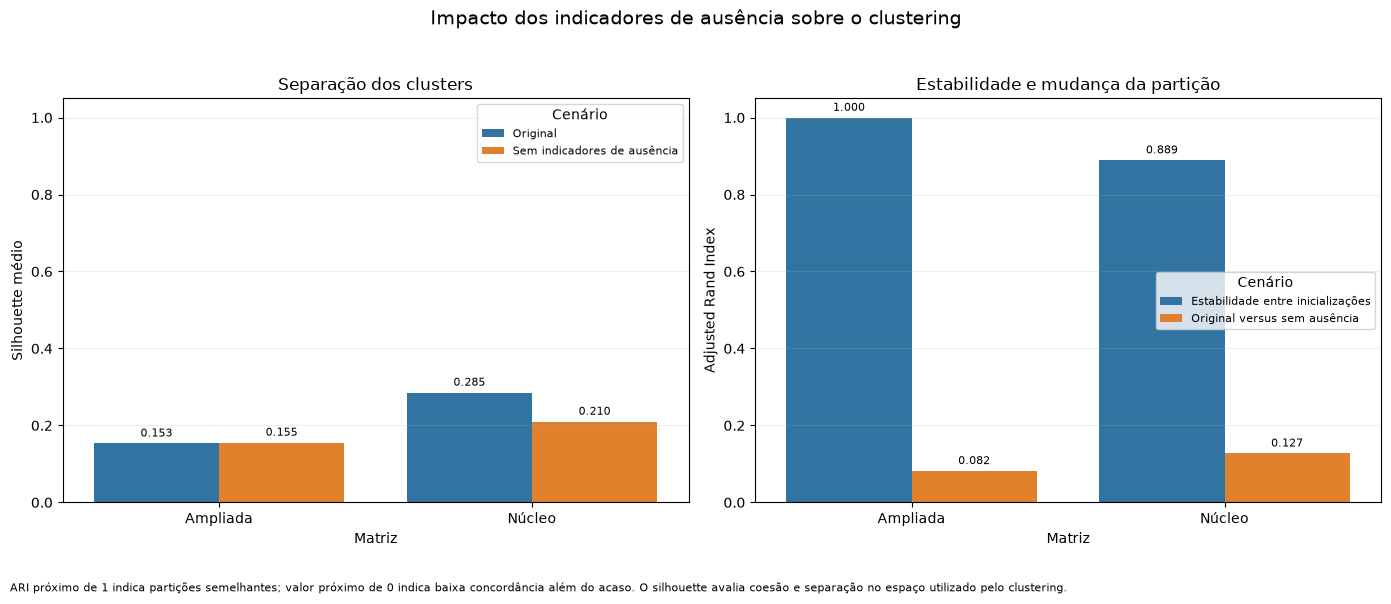

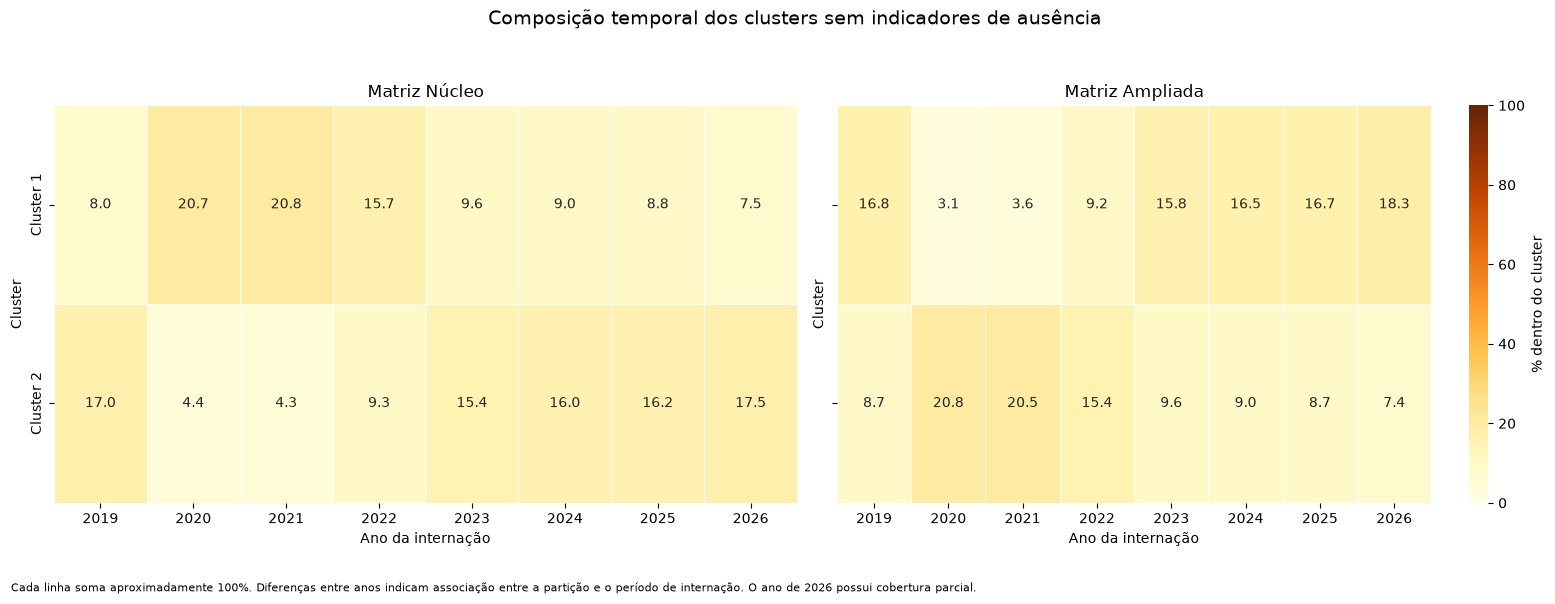

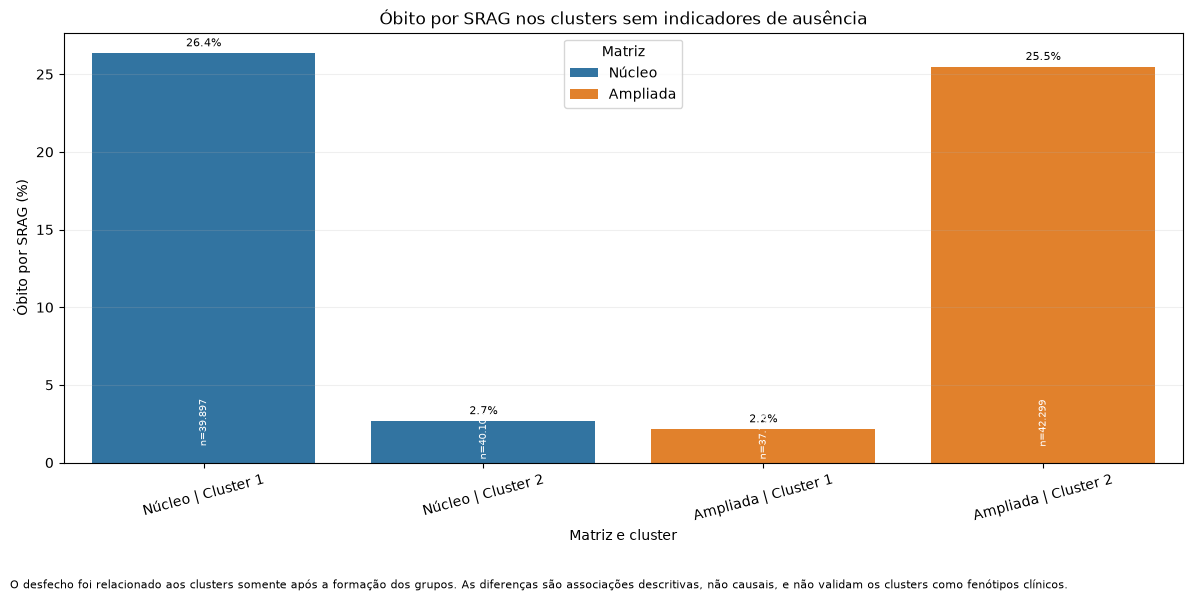

Gráfico de cobertura versus relevância não gerado: os objetos ou nomes de colunas necessários não estavam disponíveis. As demais análises finais foram preservadas.
EDA final de sensibilidade validada com sucesso.
ARI núcleo versus ampliada sem indicadores de ausência: 0.878249


,matriz,silhouette_original,silhouette_sem_indicadores_ausencia,queda_silhouette,queda_silhouette_percentual,ari_estabilidade_original,ari_original_vs_sem_ausencia,indicadores_ausencia_excluidos,features_sensibilidade,componentes_pca_90
0,ampliada,0.153334,0.155497,-0.002164,-1.411093,0.999798,0.081700,29,69,30
1,nucleo,0.285447,0.209915,0.075532,26.461054,0.889130,0.127338,27,31,15


,matriz,cluster_rotulo,quantidade_registros,quantidade_obitos,percentual_obito
0,nucleo,Cluster 1,39897,10515,26.355365
1,nucleo,Cluster 2,40103,1074,2.678104
2,ampliada,Cluster 1,37701,812,2.153789
3,ampliada,Cluster 2,42299,10777,25.478144


,verificacao,resultado
0,comparacao_duas_matrizes,True
1,silhouette_original_valido,True
2,silhouette_sensibilidade_valido,True
3,ari_comparacao_valido,True
4,composicao_temporal_nao_vazia,True
5,desfecho_cluster_nao_vazio,True
6,ari_nucleo_ampliada_valido,True
7,arquivo_comparacao_criado,True
8,figura_comparacao_criada,True
9,figura_temporal_criada,True


In [118]:
# ============================================================
# EDA FINAL DE SENSIBILIDADE, PREENCHIMENTO E RELEVANCIA
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

OBJETOS_EDA_SENSIBILIDADE_NECESSARIOS = [
    "melhores_candidatos_estabilidade",
    "resumo_sensibilidade_sem_ausencia",
    "cluster_ano_sensibilidade",
    "cluster_desfecho_sensibilidade",
    "diagnostico_final_clustering",
    "ari_nucleo_vs_ampliada_sem_ausencia",
    "C",
]

objetos_eda_sensibilidade_ausentes = [
    nome
    for nome in OBJETOS_EDA_SENSIBILIDADE_NECESSARIOS
    if nome not in globals()
]

if objetos_eda_sensibilidade_ausentes:
    raise NameError(
        "Execute primeiro as células de estabilidade, sensibilidade e "
        "conclusão do clustering. Objetos ausentes: "
        f"{objetos_eda_sensibilidade_ausentes}"
    )

MATRIZES_ESPERADAS = [
    "nucleo",
    "ampliada",
]

ROTULOS_MATRIZES_FINAIS = {
    "nucleo": "Núcleo",
    "ampliada": "Ampliada",
}

DIRETORIO_TABELAS = Path(C.TABLES_DIR)
DIRETORIO_FIGURAS = Path(C.FIGURES_DIR)

DIRETORIO_TABELAS.mkdir(
    parents=True,
    exist_ok=True,
)

DIRETORIO_FIGURAS.mkdir(
    parents=True,
    exist_ok=True,
)

CAMINHO_COMPARACAO_SENSIBILIDADE = (
    DIRETORIO_TABELAS
    / "eda_02_comparacao_original_sensibilidade.csv"
)

CAMINHO_COBERTURA_RELEVANCIA = (
    DIRETORIO_TABELAS
    / "eda_02_cobertura_relevancia_features.csv"
)

CAMINHO_FIGURA_COMPARACAO = (
    DIRETORIO_FIGURAS
    / "eda_02_comparacao_original_sensibilidade.png"
)

CAMINHO_FIGURA_TEMPORAL = (
    DIRETORIO_FIGURAS
    / "eda_02_composicao_temporal_sensibilidade.png"
)

CAMINHO_FIGURA_DESFECHO = (
    DIRETORIO_FIGURAS
    / "eda_02_desfecho_clusters_sensibilidade.png"
)

CAMINHO_FIGURA_COBERTURA_RELEVANCIA = (
    DIRETORIO_FIGURAS
    / "eda_02_cobertura_relevancia_features.png"
)


# ============================================================
# 1. COMPARACAO ENTRE SOLUCAO ORIGINAL E SENSIBILIDADE
# ============================================================

COLUNAS_ORIGINAIS_NECESSARIAS = [
    "matriz",
    "quantidade_clusters",
    "silhouette_medio",
    "ari_medio",
    "menor_cluster_percentual",
    "maior_cluster_percentual",
]

colunas_originais_ausentes = [
    coluna
    for coluna in COLUNAS_ORIGINAIS_NECESSARIAS
    if coluna not in melhores_candidatos_estabilidade.columns
]

if colunas_originais_ausentes:
    raise KeyError(
        "A tabela melhores_candidatos_estabilidade não contém: "
        f"{colunas_originais_ausentes}"
    )

COLUNAS_SENSIBILIDADE_NECESSARIAS = [
    "matriz",
    "k",
    "indicadores_ausencia_excluidos",
    "features_sensibilidade",
    "componentes_pca_90",
    "silhouette_medio",
    "menor_cluster_percentual",
    "maior_cluster_percentual",
    "ari_original_vs_sem_ausencia",
]

colunas_sensibilidade_ausentes = [
    coluna
    for coluna in COLUNAS_SENSIBILIDADE_NECESSARIAS
    if coluna not in resumo_sensibilidade_sem_ausencia.columns
]

if colunas_sensibilidade_ausentes:
    raise KeyError(
        "A tabela resumo_sensibilidade_sem_ausencia não contém: "
        f"{colunas_sensibilidade_ausentes}"
    )

comparacao_original = (
    melhores_candidatos_estabilidade[
        COLUNAS_ORIGINAIS_NECESSARIAS
    ]
    .copy()
    .rename(
        columns={
            "quantidade_clusters": "k_original",
            "silhouette_medio": "silhouette_original",
            "ari_medio": "ari_estabilidade_original",
            "menor_cluster_percentual": (
                "menor_cluster_percentual_original"
            ),
            "maior_cluster_percentual": (
                "maior_cluster_percentual_original"
            ),
        }
    )
)

comparacao_sensibilidade = (
    resumo_sensibilidade_sem_ausencia[
        COLUNAS_SENSIBILIDADE_NECESSARIAS
    ]
    .copy()
    .rename(
        columns={
            "k": "k_sem_indicadores_ausencia",
            "silhouette_medio": (
                "silhouette_sem_indicadores_ausencia"
            ),
            "menor_cluster_percentual": (
                "menor_cluster_percentual_sem_ausencia"
            ),
            "maior_cluster_percentual": (
                "maior_cluster_percentual_sem_ausencia"
            ),
        }
    )
)

comparacao_original_sensibilidade = (
    comparacao_original.merge(
        comparacao_sensibilidade,
        on="matriz",
        how="inner",
        validate="one_to_one",
    )
)

comparacao_original_sensibilidade[
    "queda_silhouette"
] = (
    comparacao_original_sensibilidade[
        "silhouette_original"
    ]
    .sub(
        comparacao_original_sensibilidade[
            "silhouette_sem_indicadores_ausencia"
        ]
    )
)

comparacao_original_sensibilidade[
    "queda_silhouette_percentual"
] = (
    comparacao_original_sensibilidade[
        "queda_silhouette"
    ]
    .div(
        comparacao_original_sensibilidade[
            "silhouette_original"
        ]
    )
    .mul(100)
)

comparacao_original_sensibilidade[
    "rotulo_matriz"
] = (
    comparacao_original_sensibilidade[
        "matriz"
    ]
    .map(ROTULOS_MATRIZES_FINAIS)
)

if set(
    comparacao_original_sensibilidade["matriz"]
) != set(MATRIZES_ESPERADAS):
    raise RuntimeError(
        "A comparação não contém exatamente as matrizes núcleo e ampliada."
    )

comparacao_original_sensibilidade.to_csv(
    CAMINHO_COMPARACAO_SENSIBILIDADE,
    index=False,
    encoding="utf-8-sig",
)

comparacao_longa = (
    comparacao_original_sensibilidade[
        [
            "rotulo_matriz",
            "silhouette_original",
            "silhouette_sem_indicadores_ausencia",
        ]
    ]
    .melt(
        id_vars="rotulo_matriz",
        var_name="cenario",
        value_name="silhouette",
    )
)

comparacao_longa["cenario"] = (
    comparacao_longa["cenario"]
    .map(
        {
            "silhouette_original": "Original",
            "silhouette_sem_indicadores_ausencia": (
                "Sem indicadores de ausência"
            ),
        }
    )
)

figura_comparacao, eixos_comparacao = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 6),
)

sns.barplot(
    data=comparacao_longa,
    x="rotulo_matriz",
    y="silhouette",
    hue="cenario",
    ax=eixos_comparacao[0],
)

for contenedor in eixos_comparacao[0].containers:
    eixos_comparacao[0].bar_label(
        contenedor,
        fmt="%.3f",
        padding=3,
        fontsize=8,
    )

comparacao_ari = (
    comparacao_original_sensibilidade[
        [
            "rotulo_matriz",
            "ari_estabilidade_original",
            "ari_original_vs_sem_ausencia",
        ]
    ]
    .melt(
        id_vars="rotulo_matriz",
        var_name="metrica",
        value_name="ari",
    )
)

comparacao_ari["metrica"] = (
    comparacao_ari["metrica"]
    .map(
        {
            "ari_estabilidade_original": (
                "Estabilidade entre inicializações"
            ),
            "ari_original_vs_sem_ausencia": (
                "Original versus sem ausência"
            ),
        }
    )
)

sns.barplot(
    data=comparacao_ari,
    x="rotulo_matriz",
    y="ari",
    hue="metrica",
    ax=eixos_comparacao[1],
)

for contenedor in eixos_comparacao[1].containers:
    eixos_comparacao[1].bar_label(
        contenedor,
        fmt="%.3f",
        padding=3,
        fontsize=8,
    )

for eixo in eixos_comparacao:
    eixo.set_xlabel("Matriz")
    eixo.grid(
        axis="y",
        alpha=0.20,
    )
    eixo.legend(
        title="Cenário",
        fontsize=8,
    )

    eixo.set_ylim(
        0,
        1.05,
    )


eixos_comparacao[0].set_title(
    "Separação dos clusters"
)

eixos_comparacao[0].set_ylabel(
    "Silhouette médio"
)

eixos_comparacao[1].set_title(
    "Estabilidade e mudança da partição"
)

eixos_comparacao[1].set_ylabel(
    "Adjusted Rand Index"
)

figura_comparacao.suptitle(
    "Impacto dos indicadores de ausência sobre o clustering",
    fontsize=14,
)

figura_comparacao.text(
    0.01,
    0.01,
    (
        "ARI próximo de 1 indica partições semelhantes; valor próximo de "
        "0 indica baixa concordância além do acaso. O silhouette avalia "
        "coesão e separação no espaço utilizado pelo clustering."
    ),
    fontsize=8,
)

figura_comparacao.tight_layout(
    rect=[
        0,
        0.06,
        1,
        0.95,
    ]
)

figura_comparacao.savefig(
    CAMINHO_FIGURA_COMPARACAO,
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(figura_comparacao)


# ============================================================
# 2. COMPOSICAO TEMPORAL DOS CLUSTERS DE SENSIBILIDADE
# ============================================================

COLUNAS_TEMPORAIS_NECESSARIAS = [
    "matriz",
    "cluster_rotulo",
    "ano_internacao",
    "quantidade",
]

colunas_temporais_ausentes = [
    coluna
    for coluna in COLUNAS_TEMPORAIS_NECESSARIAS
    if coluna not in cluster_ano_sensibilidade.columns
]

if colunas_temporais_ausentes:
    raise KeyError(
        "A tabela cluster_ano_sensibilidade não contém: "
        f"{colunas_temporais_ausentes}"
    )

CANDIDATAS_PERCENTUAL_TEMPORAL = [
    "percentual_dentro_cluster",
    "percentual_cluster",
]

COLUNA_PERCENTUAL_TEMPORAL = next(
    (
        coluna
        for coluna in CANDIDATAS_PERCENTUAL_TEMPORAL
        if coluna in cluster_ano_sensibilidade.columns
    ),
    None,
)

if COLUNA_PERCENTUAL_TEMPORAL is None:
    raise KeyError(
        "A tabela cluster_ano_sensibilidade não contém uma coluna "
        "de percentual reconhecida. Colunas esperadas: "
        f"{CANDIDATAS_PERCENTUAL_TEMPORAL}"
    )

figura_temporal, eixos_temporais = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(16, 6),
    sharey=True,
)

for indice_eixo, nome_matriz in enumerate(
    MATRIZES_ESPERADAS
):
    dados_matriz = (
        cluster_ano_sensibilidade.loc[
            cluster_ano_sensibilidade[
                "matriz"
            ].eq(nome_matriz)
        ]
        .copy()
    )

    matriz_temporal = (
        dados_matriz.pivot(
            index="cluster_rotulo",
            columns="ano_internacao",
            values=COLUNA_PERCENTUAL_TEMPORAL,
        )
        .sort_index()
        .astype("float64")
    )

    sns.heatmap(
        matriz_temporal,
        annot=True,
        fmt=".1f",
        cmap="YlOrBr",
        vmin=0,
        vmax=100,
        linewidths=0.5,
        linecolor="white",
        cbar=(indice_eixo == 1),
        cbar_kws={
            "label": "% dentro do cluster",
        },
        ax=eixos_temporais[indice_eixo],
    )

    eixos_temporais[indice_eixo].set_title(
        "Matriz "
        + ROTULOS_MATRIZES_FINAIS[nome_matriz]
    )

    eixos_temporais[indice_eixo].set_xlabel(
        "Ano da internação"
    )

    eixos_temporais[indice_eixo].set_ylabel(
        "Cluster"
    )

figura_temporal.suptitle(
    "Composição temporal dos clusters sem indicadores de ausência",
    fontsize=14,
)

figura_temporal.text(
    0.01,
    0.01,
    (
        "Cada linha soma aproximadamente 100%. Diferenças entre anos "
        "indicam associação entre a partição e o período de internação. "
        "O ano de 2026 possui cobertura parcial."
    ),
    fontsize=8,
)

figura_temporal.tight_layout(
    rect=[
        0,
        0.06,
        1,
        0.94,
    ]
)

figura_temporal.savefig(
    CAMINHO_FIGURA_TEMPORAL,
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(figura_temporal)


# ============================================================
# 3. DESFECHO POSTERIOR POR CLUSTER DE SENSIBILIDADE
# ============================================================

COLUNAS_DESFECHO_NECESSARIAS = [
    "matriz",
    "cluster_rotulo",
    "quantidade_registros",
    "quantidade_obitos",
    "percentual_obito",
]

colunas_desfecho_ausentes = [
    coluna
    for coluna in COLUNAS_DESFECHO_NECESSARIAS
    if coluna not in cluster_desfecho_sensibilidade.columns
]

if colunas_desfecho_ausentes:
    raise KeyError(
        "A tabela cluster_desfecho_sensibilidade não contém: "
        f"{colunas_desfecho_ausentes}"
    )

cluster_desfecho_grafico = (
    cluster_desfecho_sensibilidade[
        COLUNAS_DESFECHO_NECESSARIAS
    ]
    .copy()
)

cluster_desfecho_grafico["rotulo_matriz"] = (
    cluster_desfecho_grafico["matriz"]
    .map(ROTULOS_MATRIZES_FINAIS)
)

cluster_desfecho_grafico["grupo"] = (
    cluster_desfecho_grafico["rotulo_matriz"]
    + " | "
    + cluster_desfecho_grafico["cluster_rotulo"]
)

figura_desfecho, eixo_desfecho = plt.subplots(
    figsize=(12, 6)
)

sns.barplot(
    data=cluster_desfecho_grafico,
    x="grupo",
    y="percentual_obito",
    hue="rotulo_matriz",
    dodge=False,
    ax=eixo_desfecho,
)

for contenedor in eixo_desfecho.containers:
    rotulos_barras = []

    for barra in contenedor:
        altura = barra.get_height()

        if np.isnan(altura):
            rotulos_barras.append("")
        else:
            rotulos_barras.append(
                f"{altura:.1f}%"
            )

    eixo_desfecho.bar_label(
        contenedor,
        labels=rotulos_barras,
        padding=3,
        fontsize=8,
    )

for indice, linha in cluster_desfecho_grafico.reset_index(
    drop=True
).iterrows():
    eixo_desfecho.text(
        indice,
        max(
            0.2,
            linha["percentual_obito"] * 0.04,
        ),
        (
            f"n={int(linha['quantidade_registros']):,}"
            .replace(",", ".")
        ),
        ha="center",
        va="bottom",
        rotation=90,
        fontsize=7,
        color="white",
    )


eixo_desfecho.set_title(
    "Óbito por SRAG nos clusters sem indicadores de ausência"
)

eixo_desfecho.set_xlabel(
    "Matriz e cluster"
)

eixo_desfecho.set_ylabel(
    "Óbito por SRAG (%)"
)

eixo_desfecho.tick_params(
    axis="x",
    rotation=15,
)

eixo_desfecho.grid(
    axis="y",
    alpha=0.20,
)

eixo_desfecho.legend(
    title="Matriz"
)

figura_desfecho.text(
    0.01,
    0.01,
    (
        "O desfecho foi relacionado aos clusters somente após a formação "
        "dos grupos. As diferenças são associações descritivas, não "
        "causais, e não validam os clusters como fenótipos clínicos."
    ),
    fontsize=8,
)

figura_desfecho.tight_layout(
    rect=[
        0,
        0.06,
        1,
        1,
    ]
)

figura_desfecho.savefig(
    CAMINHO_FIGURA_DESFECHO,
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(figura_desfecho)


# ============================================================
# 4. COBERTURA VERSUS RELEVANCIA NA SOLUCAO ORIGINAL
# ============================================================

# A análise abaixo usa a importância absoluta do PC1 apenas como medida
# exploratória de contribuição à estrutura dominante. Não representa
# importância preditiva nem causalidade.

objetos_cobertura_disponiveis = all(
    nome in globals()
    for nome in [
        "diagnostico_matrizes_pre_imputacao",
        "loadings_componentes_principais",
    ]
)

cobertura_relevancia_features = pd.DataFrame()

if objetos_cobertura_disponiveis:
    diagnostico_cobertura = (
        diagnostico_matrizes_pre_imputacao.copy()
    )

    loadings_cobertura = (
        loadings_componentes_principais.copy()
    )

    candidatos_coluna_variavel = [
        "variavel",
        "feature",
        "feature_original",
        "coluna",
    ]

    coluna_variavel_diagnostico = next(
        (
            coluna
            for coluna in candidatos_coluna_variavel
            if coluna in diagnostico_cobertura.columns
        ),
        None,
    )

    coluna_variavel_loadings = next(
        (
            coluna
            for coluna in candidatos_coluna_variavel
            + ["feature_processada"]
            if coluna in loadings_cobertura.columns
        ),
        None,
    )

    candidatos_coluna_cobertura = [
        "percentual_preenchido",
        "percentual_nao_ausente",
        "percentual_cobertura",
    ]

    coluna_cobertura = next(
        (
            coluna
            for coluna in candidatos_coluna_cobertura
            if coluna in diagnostico_cobertura.columns
        ),
        None,
    )

    candidatos_coluna_loading = [
        "loading_absoluto",
        "loading_pc1_absoluto",
        "pc1_absoluto",
    ]

    coluna_loading_absoluto = next(
        (
            coluna
            for coluna in candidatos_coluna_loading
            if coluna in loadings_cobertura.columns
        ),
        None,
    )

    if (
        coluna_variavel_diagnostico is not None
        and coluna_variavel_loadings is not None
        and coluna_cobertura is not None
    ):
        if coluna_loading_absoluto is None:
            candidatos_loading_assinado = [
                "loading",
                "loading_pc1",
                "pc1",
            ]

            coluna_loading_assinado = next(
                (
                    coluna
                    for coluna in candidatos_loading_assinado
                    if coluna in loadings_cobertura.columns
                ),
                None,
            )

            if coluna_loading_assinado is not None:
                loadings_cobertura[
                    "loading_pc1_absoluto_calculado"
                ] = (
                    pd.to_numeric(
                        loadings_cobertura[
                            coluna_loading_assinado
                        ],
                        errors="coerce",
                    )
                    .abs()
                )

                coluna_loading_absoluto = (
                    "loading_pc1_absoluto_calculado"
                )

        if coluna_loading_absoluto is not None:
            diagnostico_cobertura["chave_variavel"] = (
                diagnostico_cobertura[
                    coluna_variavel_diagnostico
                ]
                .astype("string")
            )

            loadings_cobertura["chave_variavel"] = (
                loadings_cobertura[
                    coluna_variavel_loadings
                ]
                .astype("string")
                .str.replace(
                    r"^(numericas|binarias|categoricas)__",
                    "",
                    regex=True,
                )
                .str.replace(
                    r"^missingindicator_",
                    "",
                    regex=True,
                )
                .str.replace(
                    r"_categoria_.*$",
                    "",
                    regex=True,
                )
            )

            relevancia_por_variavel = (
                loadings_cobertura.groupby(
                    "chave_variavel",
                    dropna=False,
                )[
                    coluna_loading_absoluto
                ]
                .max()
                .rename(
                    "contribuicao_absoluta_maxima_pc1"
                )
                .reset_index()
            )

            cobertura_relevancia_features = (
                diagnostico_cobertura[
                    [
                        "chave_variavel",
                        coluna_cobertura,
                    ]
                ]
                .drop_duplicates(
                    subset=["chave_variavel"]
                )
                .merge(
                    relevancia_por_variavel,
                    on="chave_variavel",
                    how="inner",
                )
                .rename(
                    columns={
                        coluna_cobertura: (
                            "percentual_preenchido"
                        ),
                    }
                )
            )

            cobertura_relevancia_features[
                "percentual_preenchido"
            ] = pd.to_numeric(
                cobertura_relevancia_features[
                    "percentual_preenchido"
                ],
                errors="coerce",
            )

            cobertura_relevancia_features = (
                cobertura_relevancia_features.dropna(
                    subset=[
                        "percentual_preenchido",
                        "contribuicao_absoluta_maxima_pc1",
                    ]
                )
            )

if not cobertura_relevancia_features.empty:
    cobertura_relevancia_features[
        "faixa_cobertura"
    ] = pd.cut(
        cobertura_relevancia_features[
            "percentual_preenchido"
        ],
        bins=[
            -np.inf,
            50,
            80,
            95,
            np.inf,
        ],
        labels=[
            "Abaixo de 50%",
            "50% a <80%",
            "80% a <95%",
            "95% ou mais",
        ],
        right=False,
    )

    cobertura_relevancia_features = (
        cobertura_relevancia_features.sort_values(
            "contribuicao_absoluta_maxima_pc1",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    cobertura_relevancia_features.to_csv(
        CAMINHO_COBERTURA_RELEVANCIA,
        index=False,
        encoding="utf-8-sig",
    )

    limite_rotulos = min(
        15,
        len(cobertura_relevancia_features),
    )

    indices_rotulos = set(
        cobertura_relevancia_features.head(
            limite_rotulos
        ).index
    )

    figura_cobertura, eixo_cobertura = plt.subplots(
        figsize=(12, 8)
    )

    sns.scatterplot(
        data=cobertura_relevancia_features,
        x="percentual_preenchido",
        y="contribuicao_absoluta_maxima_pc1",
        hue="faixa_cobertura",
        s=80,
        alpha=0.80,
        ax=eixo_cobertura,
    )

    for indice, linha in (
        cobertura_relevancia_features.iterrows()
    ):
        if indice in indices_rotulos:
            eixo_cobertura.annotate(
                str(linha["chave_variavel"]),
                (
                    linha["percentual_preenchido"],
                    linha[
                        "contribuicao_absoluta_maxima_pc1"
                    ],
                ),
                xytext=(4, 4),
                textcoords="offset points",
                fontsize=7,
            )

    eixo_cobertura.axvline(
        50,
        color="tab:red",
        linestyle="--",
        linewidth=1,
        alpha=0.70,
    )

    eixo_cobertura.axvline(
        80,
        color="tab:orange",
        linestyle="--",
        linewidth=1,
        alpha=0.70,
    )

    eixo_cobertura.set_title(
        "Cobertura versus contribuição à estrutura dominante"
    )

    eixo_cobertura.set_xlabel(
        "Preenchimento na amostra de desenvolvimento (%)"
    )

    eixo_cobertura.set_ylabel(
        "Maior contribuição absoluta ao PC1"
    )

    eixo_cobertura.grid(
        alpha=0.20,
    )

    eixo_cobertura.legend(
        title="Faixa de cobertura",
    )

    figura_cobertura.text(
        0.01,
        0.01,
        (
            "Contribuição ao PC1 é usada apenas como diagnóstico da "
            "estrutura do clustering. Baixa cobertura com contribuição "
            "alta pode indicar influência do padrão de documentação, e "
            "não relevância clínica ou preditiva."
        ),
        fontsize=8,
    )

    figura_cobertura.tight_layout(
        rect=[
            0,
            0.06,
            1,
            1,
        ]
    )

    figura_cobertura.savefig(
        CAMINHO_FIGURA_COBERTURA_RELEVANCIA,
        dpi=160,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(figura_cobertura)

else:
    print(
        "Gráfico de cobertura versus relevância não gerado: "
        "os objetos ou nomes de colunas necessários não estavam "
        "disponíveis. As demais análises finais foram preservadas."
    )


# ============================================================
# 5. VALIDACAO E RESUMO
# ============================================================

verificacoes_eda_sensibilidade = pd.DataFrame(
    {
        "verificacao": [
            "comparacao_duas_matrizes",
            "silhouette_original_valido",
            "silhouette_sensibilidade_valido",
            "ari_comparacao_valido",
            "composicao_temporal_nao_vazia",
            "desfecho_cluster_nao_vazio",
            "ari_nucleo_ampliada_valido",
            "arquivo_comparacao_criado",
            "figura_comparacao_criada",
            "figura_temporal_criada",
            "figura_desfecho_criada",
        ],
        "resultado": [
            len(comparacao_original_sensibilidade) == 2,
            comparacao_original_sensibilidade[
                "silhouette_original"
            ].between(-1, 1).all(),
            comparacao_original_sensibilidade[
                "silhouette_sem_indicadores_ausencia"
            ].between(-1, 1).all(),
            comparacao_original_sensibilidade[
                "ari_original_vs_sem_ausencia"
            ].between(-0.5, 1).all(),
            not cluster_ano_sensibilidade.empty,
            not cluster_desfecho_sensibilidade.empty,
            -0.5 <= ari_nucleo_vs_ampliada_sem_ausencia <= 1,
            CAMINHO_COMPARACAO_SENSIBILIDADE.exists(),
            CAMINHO_FIGURA_COMPARACAO.exists(),
            CAMINHO_FIGURA_TEMPORAL.exists(),
            CAMINHO_FIGURA_DESFECHO.exists(),
        ],
    }
)

if not verificacoes_eda_sensibilidade[
    "resultado"
].all():
    falhas = (
        verificacoes_eda_sensibilidade.loc[
            ~verificacoes_eda_sensibilidade[
                "resultado"
            ],
            "verificacao",
        ]
        .tolist()
    )

    raise RuntimeError(
        "A EDA final de sensibilidade falhou em: "
        f"{falhas}"
    )

print(
    "EDA final de sensibilidade validada com sucesso."
)

print(
    "ARI núcleo versus ampliada sem indicadores de ausência:",
    round(
        ari_nucleo_vs_ampliada_sem_ausencia,
        6,
    ),
)

display(
    comparacao_original_sensibilidade[
        [
            "matriz",
            "silhouette_original",
            "silhouette_sem_indicadores_ausencia",
            "queda_silhouette",
            "queda_silhouette_percentual",
            "ari_estabilidade_original",
            "ari_original_vs_sem_ausencia",
            "indicadores_ausencia_excluidos",
            "features_sensibilidade",
            "componentes_pca_90",
        ]
    ]
)

display(
    cluster_desfecho_grafico[
        [
            "matriz",
            "cluster_rotulo",
            "quantidade_registros",
            "quantidade_obitos",
            "percentual_obito",
        ]
    ]
)

display(
    verificacoes_eda_sensibilidade
)


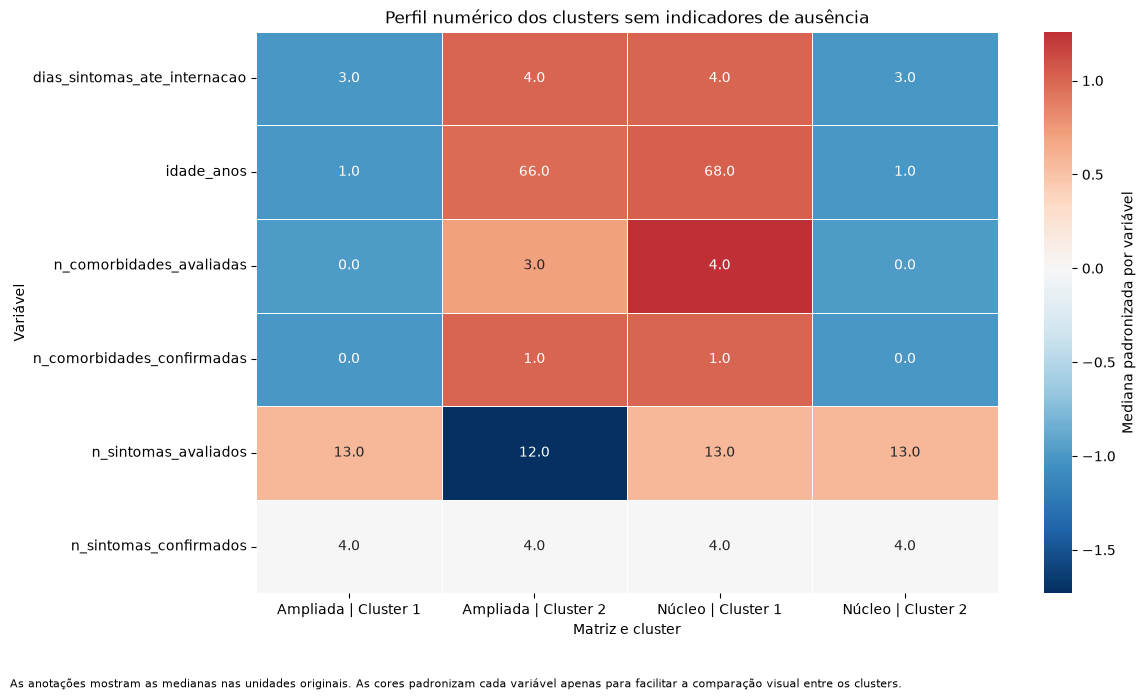

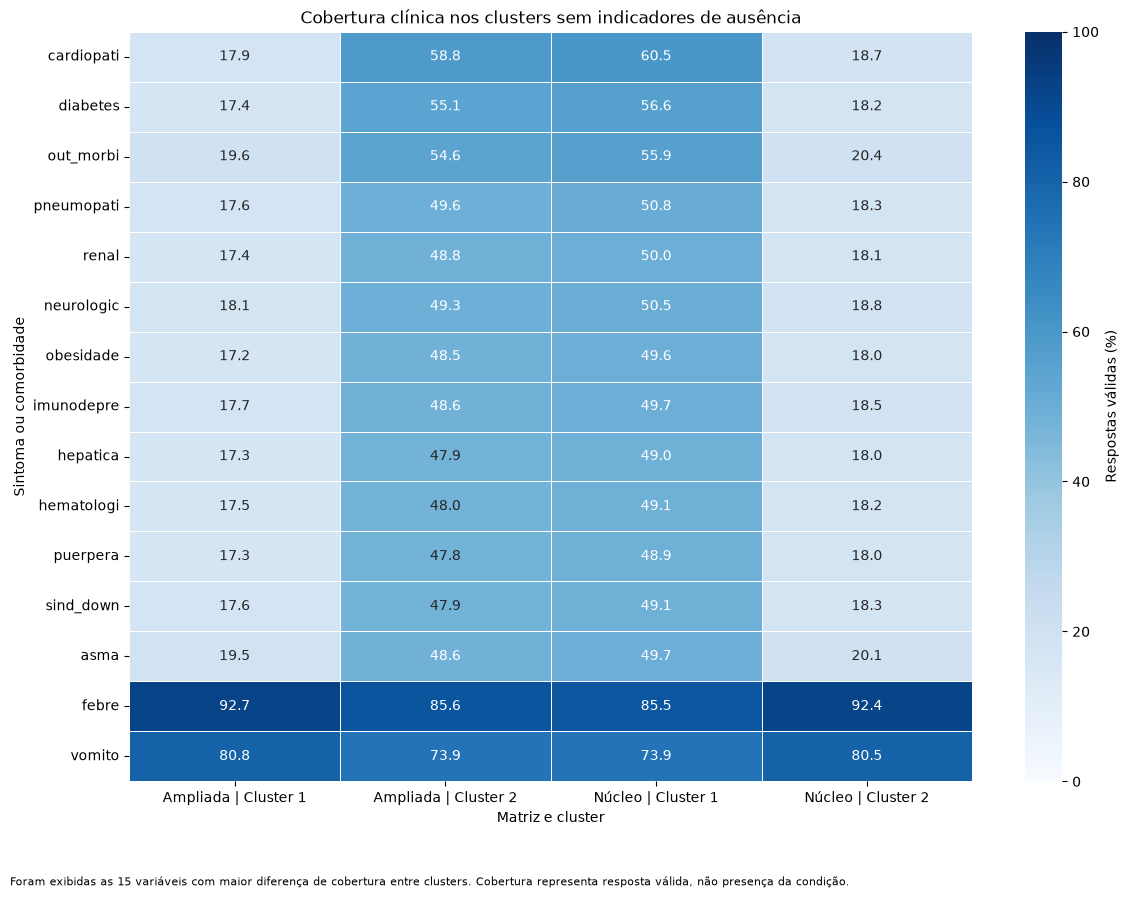

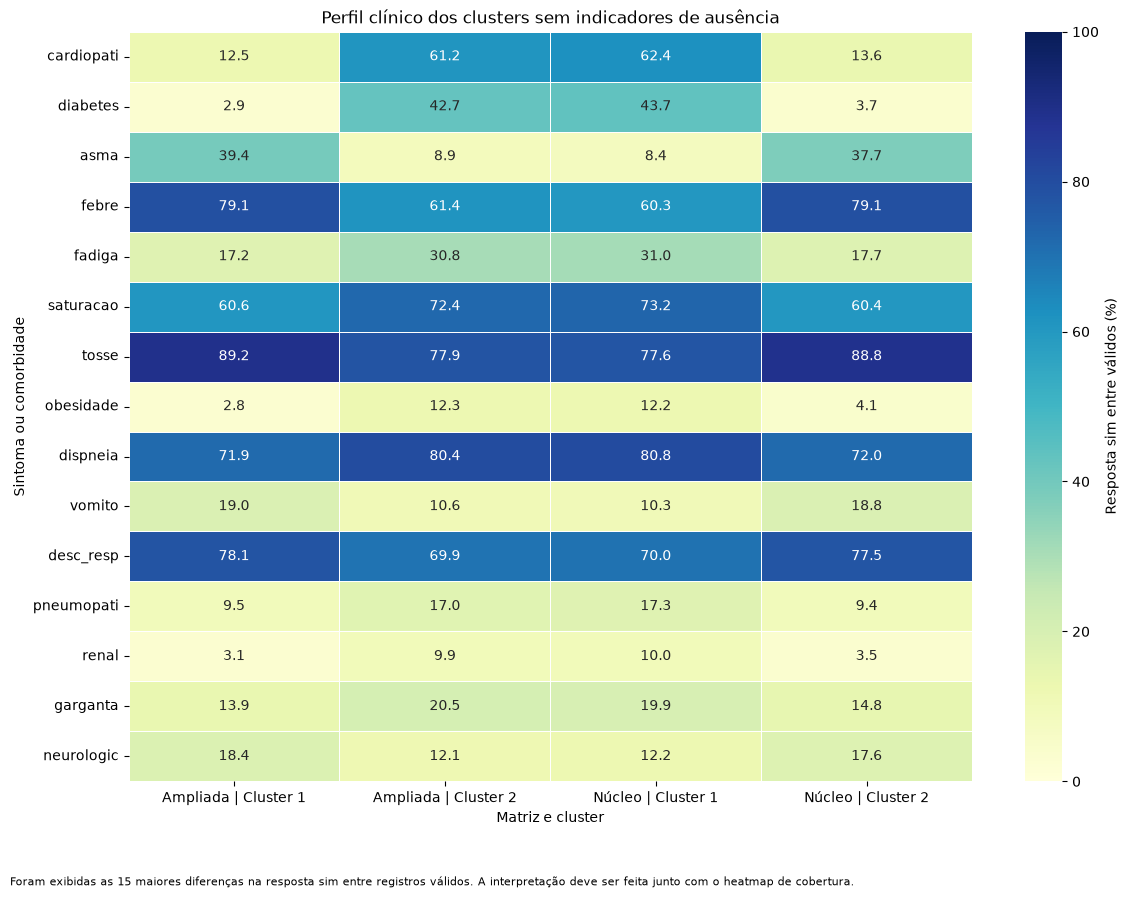

Perfis dos clusters de sensibilidade validados com sucesso.
Variáveis numéricas: ['idade_anos', 'dias_sintomas_ate_internacao', 'n_sintomas_confirmados', 'n_sintomas_avaliados', 'n_comorbidades_confirmadas', 'n_comorbidades_avaliadas']
Sintomas: 13
Comorbidades: 13


,cluster_rotulo,quantidade_registros,quantidade_preenchida,media,desvio_padrao,mediana,p25,p75,variavel,matriz,percentual_preenchido
0,Cluster 1,37701,37701,3.386966,3.465577,3.0,1.0,4.0,dias_sintomas_ate_internacao,ampliada,100.0
1,Cluster 2,42299,42299,5.197522,5.620302,4.0,1.0,7.0,dias_sintomas_ate_internacao,ampliada,100.0
2,Cluster 1,37701,37700,4.737937,7.804633,1.0,0.416667,5.0,idade_anos,ampliada,99.997348
3,Cluster 2,42299,42299,64.910744,17.272219,66.0,53.0,78.0,idade_anos,ampliada,100.0
4,Cluster 1,37701,37701,2.321981,4.845278,0.0,0.0,0.0,n_comorbidades_avaliadas,ampliada,100.0
5,Cluster 2,42299,42299,6.534339,6.104301,3.0,0.0,13.0,n_comorbidades_avaliadas,ampliada,100.0
6,Cluster 1,37701,37701,0.306093,0.605713,0.0,0.0,0.0,n_comorbidades_confirmadas,ampliada,100.0
7,Cluster 2,42299,42299,1.249793,1.138591,1.0,0.0,2.0,n_comorbidades_confirmadas,ampliada,100.0
8,Cluster 1,37701,37701,10.117,3.749203,13.0,8.0,13.0,n_sintomas_avaliados,ampliada,100.0
9,Cluster 2,42299,42299,9.72666,4.134923,12.0,6.0,13.0,n_sintomas_avaliados,ampliada,100.0


,cluster_rotulo,quantidade_registros,quantidade_respostas_validas,quantidade_sim,quantidade_sem_resposta_valida,percentual_preenchido_valido,percentual_sem_resposta_valida,percentual_sim_entre_validos,variavel,grupo_clinico,matriz
0,Cluster 1,37701,7344,2892,30357,19.479589,80.520411,39.379085,asma,comorbidade,ampliada
1,Cluster 2,42299,20564,1822,21735,48.615807,51.384193,8.860144,asma,comorbidade,ampliada
2,Cluster 1,37701,6754,843,30947,17.914644,82.085356,12.481492,cardiopati,comorbidade,ampliada
3,Cluster 2,42299,24879,15230,17420,58.816993,41.183007,61.216287,cardiopati,comorbidade,ampliada
4,Cluster 1,37701,6568,192,31133,17.421289,82.578711,2.923264,diabetes,comorbidade,ampliada
...,...,...,...,...,...,...,...,...,...,...,...
99,Cluster 2,40103,34736,20983,5367,86.616961,13.383039,60.407070,saturacao,sintoma,nucleo
100,Cluster 1,39897,35833,27792,4064,89.813770,10.186230,77.559791,tosse,sintoma,nucleo
101,Cluster 2,40103,38268,33994,1835,95.424282,4.575718,88.831400,tosse,sintoma,nucleo
102,Cluster 1,39897,29466,3042,10431,73.855177,26.144823,10.323763,vomito,sintoma,nucleo


,matriz,cluster_rotulo,sexo_categoria,quantidade,percentual_cluster
0,ampliada,Cluster 1,feminino,17077,45.295881
1,ampliada,Cluster 1,ignorado,7,0.018567
2,ampliada,Cluster 1,masculino,20617,54.685552
3,ampliada,Cluster 2,feminino,21083,49.842786
4,ampliada,Cluster 2,ignorado,4,0.009456
5,ampliada,Cluster 2,masculino,21212,50.147758
6,nucleo,Cluster 1,feminino,19952,50.008773
7,nucleo,Cluster 1,ignorado,3,0.007519
8,nucleo,Cluster 1,masculino,19942,49.983708
9,nucleo,Cluster 2,feminino,18208,45.403087


,verificacao,resultado
0,perfis_numericos_nao_vazios,True
1,perfis_binarios_nao_vazios,True
2,duas_matrizes_numericas,True
3,duas_matrizes_binarias,True
4,percentuais_cobertura_validos,True
5,percentuais_prevalencia_validos,True
6,arquivo_numerico_criado,True
7,arquivo_binario_criado,True
8,figura_numerica_criada,True
9,figura_cobertura_criada,True


In [119]:
# ============================================================
# PERFIS DESCRITIVOS DOS CLUSTERS DA ANALISE DE SENSIBILIDADE
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

OBJETOS_PERFIS_SENSIBILIDADE_NECESSARIOS = [
    "amostra_desenvolvimento",
    "atribuicoes_sensibilidade_sem_ausencia",
    "C",
]

objetos_perfis_sensibilidade_ausentes = [
    nome
    for nome in OBJETOS_PERFIS_SENSIBILIDADE_NECESSARIOS
    if nome not in globals()
]

if objetos_perfis_sensibilidade_ausentes:
    raise NameError(
        "Execute primeiro a amostragem e a sensibilidade sem indicadores "
        "de ausência. Objetos ausentes: "
        f"{objetos_perfis_sensibilidade_ausentes}"
    )

MATRIZES_PERFIS_SENSIBILIDADE = [
    "nucleo",
    "ampliada",
]

ROTULOS_MATRIZES_PERFIS = {
    "nucleo": "Núcleo",
    "ampliada": "Ampliada",
}

DIRETORIO_TABELAS = Path(C.TABLES_DIR)
DIRETORIO_FIGURAS = Path(C.FIGURES_DIR)

DIRETORIO_TABELAS.mkdir(
    parents=True,
    exist_ok=True,
)

DIRETORIO_FIGURAS.mkdir(
    parents=True,
    exist_ok=True,
)

CAMINHO_PERFIS_NUMERICOS = (
    DIRETORIO_TABELAS
    / "eda_02_perfis_numericos_clusters_sensibilidade.csv"
)

CAMINHO_PERFIS_BINARIOS = (
    DIRETORIO_TABELAS
    / "eda_02_perfis_binarios_clusters_sensibilidade.csv"
)

CAMINHO_PERFIS_SEXO = (
    DIRETORIO_TABELAS
    / "eda_02_perfis_sexo_clusters_sensibilidade.csv"
)

CAMINHO_FIGURA_NUMERICOS = (
    DIRETORIO_FIGURAS
    / "eda_02_perfis_numericos_clusters_sensibilidade.png"
)

CAMINHO_FIGURA_COBERTURA = (
    DIRETORIO_FIGURAS
    / "eda_02_cobertura_clinica_clusters_sensibilidade.png"
)

CAMINHO_FIGURA_PREVALENCIA = (
    DIRETORIO_FIGURAS
    / "eda_02_prevalencia_clinica_clusters_sensibilidade.png"
)


# ============================================================
# 1. COLUNAS DISPONIVEIS
# ============================================================

COLUNAS_NUMERICAS_PLANEJADAS = [
    "idade_anos",
    "dias_sintomas_ate_internacao",
    "n_sintomas_confirmados",
    "n_sintomas_avaliados",
    "n_comorbidades_confirmadas",
    "n_comorbidades_avaliadas",
]

COLUNAS_NUMERICAS_PERFIS = [
    coluna
    for coluna in COLUNAS_NUMERICAS_PLANEJADAS
    if coluna in amostra_desenvolvimento.columns
]

if "COLUNAS_SINTOMAS" in globals():
    COLUNAS_SINTOMAS_PERFIS = [
        coluna
        for coluna in COLUNAS_SINTOMAS
        if coluna in amostra_desenvolvimento.columns
    ]
else:
    COLUNAS_SINTOMAS_PERFIS = [
        coluna
        for coluna in [
            "febre",
            "tosse",
            "garganta",
            "dispneia",
            "desc_resp",
            "saturacao",
            "diarreia",
            "vomito",
            "dor_abd",
            "fadiga",
            "perd_olft",
            "perd_pala",
            "outro_sin",
        ]
        if coluna in amostra_desenvolvimento.columns
    ]

if "COLUNAS_COMORBIDADES" in globals():
    COLUNAS_COMORBIDADES_PERFIS = [
        coluna
        for coluna in COLUNAS_COMORBIDADES
        if coluna in amostra_desenvolvimento.columns
    ]
else:
    COLUNAS_COMORBIDADES_PERFIS = [
        coluna
        for coluna in [
            "puerpera",
            "cardiopati",
            "hematologi",
            "sind_down",
            "hepatica",
            "asma",
            "diabetes",
            "neurologic",
            "pneumopati",
            "imunodepre",
            "renal",
            "obesidade",
            "out_morbi",
        ]
        if coluna in amostra_desenvolvimento.columns
    ]

COLUNAS_BINARIAS_PERFIS = list(
    dict.fromkeys(
        COLUNAS_SINTOMAS_PERFIS
        + COLUNAS_COMORBIDADES_PERFIS
    )
)

COLUNA_SEXO_PERFIL = next(
    (
        coluna
        for coluna in [
            "sexo_categoria",
            "cs_sexo",
        ]
        if coluna in amostra_desenvolvimento.columns
    ),
    None,
)

if not COLUNAS_NUMERICAS_PERFIS:
    raise ValueError(
        "Nenhuma variável numérica planejada está disponível na amostra."
    )

if not COLUNAS_BINARIAS_PERFIS:
    raise ValueError(
        "Nenhum sintoma ou comorbidade está disponível na amostra."
    )


# ============================================================
# 2. FUNCOES AUXILIARES
# ============================================================


def normalizar_binaria_para_perfil(serie):
    if pd.api.types.is_numeric_dtype(serie):
        numerica = pd.to_numeric(
            serie,
            errors="coerce",
        )

        return numerica.where(
            numerica.isin([0, 1])
        )

    texto = (
        serie.astype("string")
        .str.strip()
        .str.lower()
        .str.replace(
            r"\.0$",
            "",
            regex=True,
        )
    )

    mapa = {
        "1": 1.0,
        "sim": 1.0,
        "yes": 1.0,
        "true": 1.0,
        "0": 0.0,
        "2": 0.0,
        "não": 0.0,
        "nao": 0.0,
        "no": 0.0,
        "false": 0.0,
    }

    return texto.map(mapa).astype("float32")


def calcular_perfis_matriz(
    nome_matriz,
    atribuicoes,
):
    if not atribuicoes.index.equals(
        amostra_desenvolvimento.index
    ):
        raise RuntimeError(
            "As atribuições da matriz "
            f"{nome_matriz} não estão alinhadas à amostra."
        )

    colunas_base = list(
        dict.fromkeys(
            COLUNAS_NUMERICAS_PERFIS
            + COLUNAS_BINARIAS_PERFIS
            + (
                [COLUNA_SEXO_PERFIL]
                if COLUNA_SEXO_PERFIL is not None
                else []
            )
        )
    )

    base = (
        amostra_desenvolvimento[
            colunas_base
        ]
        .copy()
    )

    base["cluster"] = (
        atribuicoes["cluster"]
        .astype("int16")
    )

    base["cluster_rotulo"] = (
        atribuicoes["cluster_rotulo"]
        .astype("string")
    )

    registros_numericos = []

    for coluna in COLUNAS_NUMERICAS_PERFIS:
        valores = pd.to_numeric(
            base[coluna],
            errors="coerce",
        )

        tabela = (
            pd.DataFrame(
                {
                    "cluster_rotulo": base[
                        "cluster_rotulo"
                    ],
                    "valor": valores,
                },
                index=base.index,
            )
            .groupby(
                "cluster_rotulo",
                dropna=False,
            )["valor"]
            .agg(
                quantidade_registros="size",
                quantidade_preenchida="count",
                media="mean",
                desvio_padrao="std",
                mediana="median",
                p25=lambda serie: serie.quantile(0.25),
                p75=lambda serie: serie.quantile(0.75),
            )
            .reset_index()
        )

        tabela["variavel"] = coluna
        tabela["matriz"] = nome_matriz
        tabela["percentual_preenchido"] = (
            tabela["quantidade_preenchida"]
            .div(tabela["quantidade_registros"])
            .mul(100)
        )

        registros_numericos.append(tabela)

    perfis_numericos = pd.concat(
        registros_numericos,
        ignore_index=True,
    )

    registros_binarios = []

    for coluna in COLUNAS_BINARIAS_PERFIS:
        valores = normalizar_binaria_para_perfil(
            base[coluna]
        )

        tabela_base = pd.DataFrame(
            {
                "cluster_rotulo": base[
                    "cluster_rotulo"
                ],
                "valor": valores,
            },
            index=base.index,
        )

        tabela = (
            tabela_base.groupby(
                "cluster_rotulo",
                dropna=False,
            )["valor"]
            .agg(
                quantidade_registros="size",
                quantidade_respostas_validas="count",
                quantidade_sim="sum",
            )
            .reset_index()
        )

        tabela["quantidade_sim"] = (
            tabela["quantidade_sim"]
            .fillna(0)
            .astype("int64")
        )

        tabela["quantidade_sem_resposta_valida"] = (
            tabela["quantidade_registros"]
            - tabela["quantidade_respostas_validas"]
        )

        tabela["percentual_preenchido_valido"] = (
            tabela["quantidade_respostas_validas"]
            .div(tabela["quantidade_registros"])
            .mul(100)
        )

        tabela["percentual_sem_resposta_valida"] = (
            tabela["quantidade_sem_resposta_valida"]
            .div(tabela["quantidade_registros"])
            .mul(100)
        )

        tabela["percentual_sim_entre_validos"] = np.where(
            tabela["quantidade_respostas_validas"].gt(0),
            tabela["quantidade_sim"]
            .div(tabela["quantidade_respostas_validas"])
            .mul(100),
            np.nan,
        )

        tabela["variavel"] = coluna
        tabela["grupo_clinico"] = np.where(
            tabela["variavel"].isin(
                COLUNAS_SINTOMAS_PERFIS
            ),
            "sintoma",
            "comorbidade",
        )
        tabela["matriz"] = nome_matriz

        registros_binarios.append(tabela)

    perfis_binarios = pd.concat(
        registros_binarios,
        ignore_index=True,
    )

    if COLUNA_SEXO_PERFIL is not None:
        perfis_sexo = (
            base.groupby(
                [
                    "cluster_rotulo",
                    COLUNA_SEXO_PERFIL,
                ],
                dropna=False,
            )
            .size()
            .rename("quantidade")
            .reset_index()
        )

        perfis_sexo["percentual_cluster"] = (
            perfis_sexo["quantidade"]
            .div(
                perfis_sexo.groupby(
                    "cluster_rotulo"
                )["quantidade"]
                .transform("sum")
            )
            .mul(100)
        )

        perfis_sexo.insert(
            0,
            "matriz",
            nome_matriz,
        )
    else:
        perfis_sexo = pd.DataFrame()

    return (
        perfis_numericos,
        perfis_binarios,
        perfis_sexo,
    )


# ============================================================
# 3. PERFIS PARA NUCLEO E AMPLIADA
# ============================================================

lista_perfis_numericos = []
lista_perfis_binarios = []
lista_perfis_sexo = []

for nome_matriz in MATRIZES_PERFIS_SENSIBILIDADE:
    if nome_matriz not in (
        atribuicoes_sensibilidade_sem_ausencia
    ):
        raise KeyError(
            "Não foram encontradas atribuições de sensibilidade "
            f"para a matriz {nome_matriz}."
        )

    (
        perfil_numerico,
        perfil_binario,
        perfil_sexo,
    ) = calcular_perfis_matriz(
        nome_matriz=nome_matriz,
        atribuicoes=(
            atribuicoes_sensibilidade_sem_ausencia[
                nome_matriz
            ]
        ),
    )

    lista_perfis_numericos.append(
        perfil_numerico
    )
    lista_perfis_binarios.append(
        perfil_binario
    )

    if not perfil_sexo.empty:
        lista_perfis_sexo.append(
            perfil_sexo
        )

perfis_numericos_clusters_sensibilidade = pd.concat(
    lista_perfis_numericos,
    ignore_index=True,
)

perfis_binarios_clusters_sensibilidade = pd.concat(
    lista_perfis_binarios,
    ignore_index=True,
)

if lista_perfis_sexo:
    perfis_sexo_clusters_sensibilidade = pd.concat(
        lista_perfis_sexo,
        ignore_index=True,
    )
else:
    perfis_sexo_clusters_sensibilidade = pd.DataFrame()

perfis_numericos_clusters_sensibilidade.to_csv(
    CAMINHO_PERFIS_NUMERICOS,
    index=False,
    encoding="utf-8-sig",
)

perfis_binarios_clusters_sensibilidade.to_csv(
    CAMINHO_PERFIS_BINARIOS,
    index=False,
    encoding="utf-8-sig",
)

if not perfis_sexo_clusters_sensibilidade.empty:
    perfis_sexo_clusters_sensibilidade.to_csv(
        CAMINHO_PERFIS_SEXO,
        index=False,
        encoding="utf-8-sig",
    )


# ============================================================
# 4. HEATMAP DOS PERFIS NUMERICOS
# ============================================================

metricas_numericas_heatmap = (
    perfis_numericos_clusters_sensibilidade[
        [
            "matriz",
            "cluster_rotulo",
            "variavel",
            "mediana",
        ]
    ]
    .copy()
)

metricas_numericas_heatmap["grupo"] = (
    metricas_numericas_heatmap["matriz"]
    .map(ROTULOS_MATRIZES_PERFIS)
    + " | "
    + metricas_numericas_heatmap[
        "cluster_rotulo"
    ]
)

matriz_numericos = (
    metricas_numericas_heatmap.pivot(
        index="variavel",
        columns="grupo",
        values="mediana",
    )
    .astype("float64")
)

media_linha = matriz_numericos.mean(
    axis=1
)

desvio_linha = matriz_numericos.std(
    axis=1,
    ddof=0,
)

matriz_numericos_padronizada = (
    matriz_numericos.sub(
        media_linha,
        axis=0,
    )
    .div(
        desvio_linha.replace(0, np.nan),
        axis=0,
    )
    .fillna(0)
)

anotacoes_numericos = matriz_numericos.apply(
    lambda coluna: coluna.map(
        lambda valor: (
            ""
            if pd.isna(valor)
            else f"{valor:.1f}"
        )
    )
)

figura_numericos, eixo_numericos = plt.subplots(
    figsize=(12, 7)
)

sns.heatmap(
    matriz_numericos_padronizada,
    annot=anotacoes_numericos,
    fmt="",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Mediana padronizada por variável",
    },
    ax=eixo_numericos,
)


eixo_numericos.set_title(
    "Perfil numérico dos clusters sem indicadores de ausência"
)

eixo_numericos.set_xlabel(
    "Matriz e cluster"
)

eixo_numericos.set_ylabel(
    "Variável"
)

figura_numericos.text(
    0.01,
    0.01,
    (
        "As anotações mostram as medianas nas unidades originais. "
        "As cores padronizam cada variável apenas para facilitar a "
        "comparação visual entre os clusters."
    ),
    fontsize=8,
)

figura_numericos.tight_layout(
    rect=[
        0,
        0.06,
        1,
        1,
    ]
)

figura_numericos.savefig(
    CAMINHO_FIGURA_NUMERICOS,
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(figura_numericos)


# ============================================================
# 5. HEATMAP DE COBERTURA CLINICA
# ============================================================

resumo_diferencas_cobertura = (
    perfis_binarios_clusters_sensibilidade.groupby(
        [
            "matriz",
            "variavel",
        ],
        dropna=False,
    )["percentual_preenchido_valido"]
    .agg(
        cobertura_minima="min",
        cobertura_maxima="max",
    )
    .reset_index()
)

resumo_diferencas_cobertura[
    "diferenca_absoluta_cobertura"
] = (
    resumo_diferencas_cobertura[
        "cobertura_maxima"
    ]
    .sub(
        resumo_diferencas_cobertura[
            "cobertura_minima"
        ]
    )
    .abs()
)

variaveis_maior_diferenca_cobertura = (
    resumo_diferencas_cobertura.groupby(
        "variavel"
    )["diferenca_absoluta_cobertura"]
    .max()
    .sort_values(
        ascending=False
    )
    .head(15)
    .index
    .tolist()
)

cobertura_heatmap = (
    perfis_binarios_clusters_sensibilidade.loc[
        perfis_binarios_clusters_sensibilidade[
            "variavel"
        ].isin(
            variaveis_maior_diferenca_cobertura
        )
    ]
    .copy()
)

cobertura_heatmap["grupo"] = (
    cobertura_heatmap["matriz"]
    .map(ROTULOS_MATRIZES_PERFIS)
    + " | "
    + cobertura_heatmap[
        "cluster_rotulo"
    ]
)

matriz_cobertura = (
    cobertura_heatmap.pivot(
        index="variavel",
        columns="grupo",
        values="percentual_preenchido_valido",
    )
    .reindex(
        index=variaveis_maior_diferenca_cobertura
    )
    .astype("float64")
)

figura_cobertura, eixo_cobertura = plt.subplots(
    figsize=(12, 9)
)

sns.heatmap(
    matriz_cobertura,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Respostas válidas (%)",
    },
    ax=eixo_cobertura,
)


eixo_cobertura.set_title(
    "Cobertura clínica nos clusters sem indicadores de ausência"
)

eixo_cobertura.set_xlabel(
    "Matriz e cluster"
)

eixo_cobertura.set_ylabel(
    "Sintoma ou comorbidade"
)

figura_cobertura.text(
    0.01,
    0.01,
    (
        "Foram exibidas as 15 variáveis com maior diferença de cobertura "
        "entre clusters. Cobertura representa resposta válida, não "
        "presença da condição."
    ),
    fontsize=8,
)

figura_cobertura.tight_layout(
    rect=[
        0,
        0.06,
        1,
        1,
    ]
)

figura_cobertura.savefig(
    CAMINHO_FIGURA_COBERTURA,
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(figura_cobertura)


# ============================================================
# 6. HEATMAP DE PRESENCA ENTRE RESPOSTAS VALIDAS
# ============================================================

resumo_diferencas_prevalencia = (
    perfis_binarios_clusters_sensibilidade.groupby(
        [
            "matriz",
            "variavel",
        ],
        dropna=False,
    )["percentual_sim_entre_validos"]
    .agg(
        prevalencia_minima="min",
        prevalencia_maxima="max",
    )
    .reset_index()
)

resumo_diferencas_prevalencia[
    "diferenca_absoluta_prevalencia"
] = (
    resumo_diferencas_prevalencia[
        "prevalencia_maxima"
    ]
    .sub(
        resumo_diferencas_prevalencia[
            "prevalencia_minima"
        ]
    )
    .abs()
)

variaveis_maior_diferenca_prevalencia = (
    resumo_diferencas_prevalencia.groupby(
        "variavel"
    )["diferenca_absoluta_prevalencia"]
    .max()
    .sort_values(
        ascending=False
    )
    .head(15)
    .index
    .tolist()
)

prevalencia_heatmap = (
    perfis_binarios_clusters_sensibilidade.loc[
        perfis_binarios_clusters_sensibilidade[
            "variavel"
        ].isin(
            variaveis_maior_diferenca_prevalencia
        )
    ]
    .copy()
)

prevalencia_heatmap["grupo"] = (
    prevalencia_heatmap["matriz"]
    .map(ROTULOS_MATRIZES_PERFIS)
    + " | "
    + prevalencia_heatmap[
        "cluster_rotulo"
    ]
)

matriz_prevalencia = (
    prevalencia_heatmap.pivot(
        index="variavel",
        columns="grupo",
        values="percentual_sim_entre_validos",
    )
    .reindex(
        index=variaveis_maior_diferenca_prevalencia
    )
    .astype("float64")
)

figura_prevalencia, eixo_prevalencia = plt.subplots(
    figsize=(12, 9)
)

sns.heatmap(
    matriz_prevalencia,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Resposta sim entre válidos (%)",
    },
    ax=eixo_prevalencia,
)


eixo_prevalencia.set_title(
    "Perfil clínico dos clusters sem indicadores de ausência"
)

eixo_prevalencia.set_xlabel(
    "Matriz e cluster"
)

eixo_prevalencia.set_ylabel(
    "Sintoma ou comorbidade"
)

figura_prevalencia.text(
    0.01,
    0.01,
    (
        "Foram exibidas as 15 maiores diferenças na resposta sim entre "
        "registros válidos. A interpretação deve ser feita junto com o "
        "heatmap de cobertura."
    ),
    fontsize=8,
)

figura_prevalencia.tight_layout(
    rect=[
        0,
        0.06,
        1,
        1,
    ]
)

figura_prevalencia.savefig(
    CAMINHO_FIGURA_PREVALENCIA,
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(figura_prevalencia)


# ============================================================
# 7. VALIDACOES E SAIDAS
# ============================================================

verificacoes_perfis_sensibilidade = pd.DataFrame(
    {
        "verificacao": [
            "perfis_numericos_nao_vazios",
            "perfis_binarios_nao_vazios",
            "duas_matrizes_numericas",
            "duas_matrizes_binarias",
            "percentuais_cobertura_validos",
            "percentuais_prevalencia_validos",
            "arquivo_numerico_criado",
            "arquivo_binario_criado",
            "figura_numerica_criada",
            "figura_cobertura_criada",
            "figura_prevalencia_criada",
        ],
        "resultado": [
            not perfis_numericos_clusters_sensibilidade.empty,
            not perfis_binarios_clusters_sensibilidade.empty,
            set(
                perfis_numericos_clusters_sensibilidade[
                    "matriz"
                ]
            ) == set(MATRIZES_PERFIS_SENSIBILIDADE),
            set(
                perfis_binarios_clusters_sensibilidade[
                    "matriz"
                ]
            ) == set(MATRIZES_PERFIS_SENSIBILIDADE),
            perfis_binarios_clusters_sensibilidade[
                "percentual_preenchido_valido"
            ].between(0, 100).all(),
            perfis_binarios_clusters_sensibilidade[
                "percentual_sim_entre_validos"
            ].dropna().between(0, 100).all(),
            CAMINHO_PERFIS_NUMERICOS.exists(),
            CAMINHO_PERFIS_BINARIOS.exists(),
            CAMINHO_FIGURA_NUMERICOS.exists(),
            CAMINHO_FIGURA_COBERTURA.exists(),
            CAMINHO_FIGURA_PREVALENCIA.exists(),
        ],
    }
)

if not verificacoes_perfis_sensibilidade[
    "resultado"
].all():
    falhas = (
        verificacoes_perfis_sensibilidade.loc[
            ~verificacoes_perfis_sensibilidade[
                "resultado"
            ],
            "verificacao",
        ]
        .tolist()
    )

    raise RuntimeError(
        "A caracterização dos clusters de sensibilidade falhou em: "
        f"{falhas}"
    )

print(
    "Perfis dos clusters de sensibilidade validados com sucesso."
)

print(
    "Variáveis numéricas:",
    COLUNAS_NUMERICAS_PERFIS,
)

print(
    "Sintomas:",
    len(COLUNAS_SINTOMAS_PERFIS),
)

print(
    "Comorbidades:",
    len(COLUNAS_COMORBIDADES_PERFIS),
)


display(
    perfis_numericos_clusters_sensibilidade.sort_values(
        [
            "matriz",
            "variavel",
            "cluster_rotulo",
        ]
    )
    .reset_index(drop=True)
)


display(
    perfis_binarios_clusters_sensibilidade.sort_values(
        [
            "matriz",
            "grupo_clinico",
            "variavel",
            "cluster_rotulo",
        ]
    )
    .reset_index(drop=True)
)


if not perfis_sexo_clusters_sensibilidade.empty:
    display(
        perfis_sexo_clusters_sensibilidade.sort_values(
            [
                "matriz",
                "cluster_rotulo",
                COLUNA_SEXO_PERFIL,
            ]
        )
        .reset_index(drop=True)
    )


display(
    verificacoes_perfis_sensibilidade
)


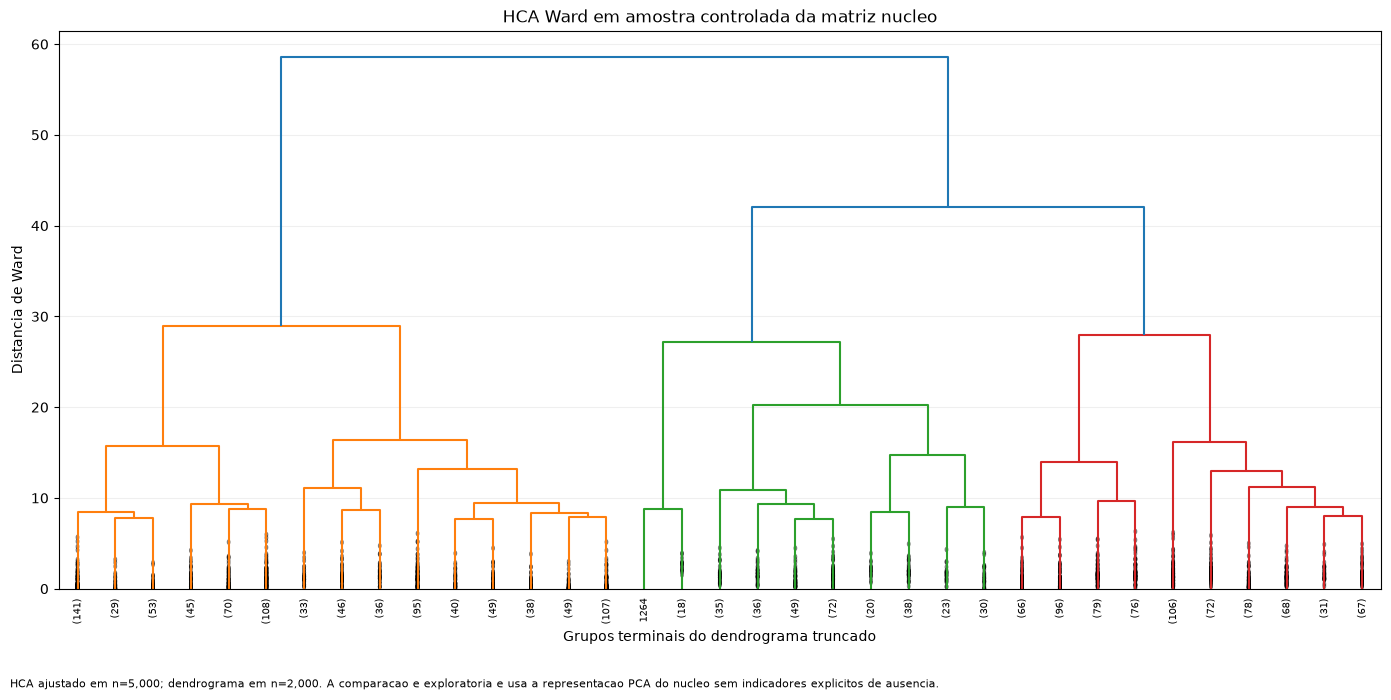

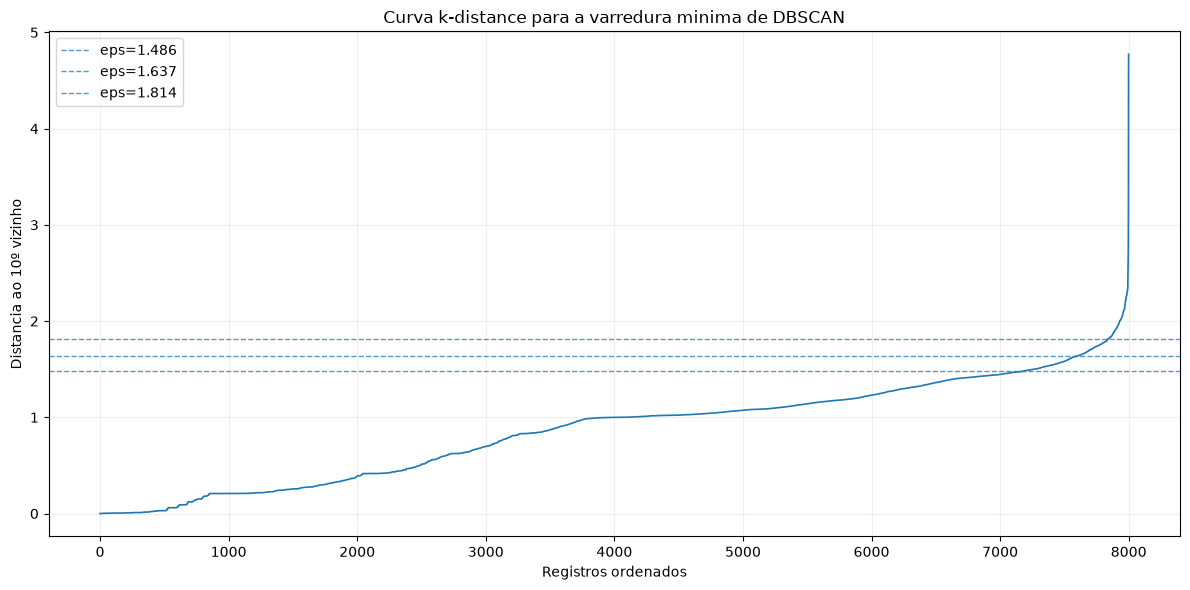

Comparacao minima de HCA e DBSCAN concluida.
Tempo para calcular k-distance do DBSCAN: 0.507 segundos
Arquivos gerados:
- C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\eda_02_dbscan_varredura_minima.csv
- C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\eda_02_hca_dbscan_resumo_minimo.csv
- C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\eda_02_hca_dendrograma_minimo.png
- C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\eda_02_dbscan_k_distance_minimo.png

Decisao metodologica: HCA e DBSCAN foram executados como comparacoes curtas em amostras controladas. Nenhum deles sera aprofundado nesta etapa; K-Means permanece como referencia exploratoria.


,metodo,matriz,quantidade_registros,quantidade_clusters,percentual_ruido,silhouette,calinski_harabasz,davies_bouldin,menor_cluster_percentual,ari_vs_kmeans,tempo_segundos,parametros,decisao
0,HCA_Ward,nucleo_sem_indicadores_ausencia,5000,2,0.0000,0.193054,1179.588210,1.916477,45.520000,0.729262,0.483580,linkage=ward; k=2,nao aprofundar: comparacao minima registrada; ...
1,DBSCAN,nucleo_sem_indicadores_ausencia,8000,3,2.6875,0.562676,127.768365,1.118179,0.102762,0.001849,1.754281,eps=1.485594; min_samples=10,nao aprofundar: comparacao minima registrada; ...


,metodo,eps,min_samples,quantidade_registros,quantidade_clusters_sem_ruido,quantidade_ruido,percentual_ruido,silhouette_sem_ruido,calinski_harabasz_sem_ruido,davies_bouldin_sem_ruido,menor_cluster_percentual_sem_ruido,ari_dbscan_vs_kmeans,tempo_segundos
0,DBSCAN,1.485594,10,8000,3,215,2.6875,0.562676,127.768365,1.118179,0.102762,0.001849,1.754281
1,DBSCAN,1.637315,10,8000,1,89,1.1125,NaN,NaN,NaN,NaN,0.000458,1.156457
2,DBSCAN,1.813659,10,8000,1,31,0.3875,NaN,NaN,NaN,NaN,0.000132,1.413088


8128

In [120]:
# ============================================================
# COMPLEMENTO MINIMO: HCA E DBSCAN EM AMOSTRA CONTROLADA
# ============================================================

from pathlib import Path
from time import perf_counter
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.neighbors import NearestNeighbors


# ------------------------------------------------------------
# 1. VALIDACAO E PARAMETROS
# ------------------------------------------------------------

OBJETOS_NECESSARIOS_HCA_DBSCAN = [
    "resultados_sensibilidade",
    "atribuicoes_sensibilidade_sem_ausencia",
]

objetos_ausentes_hca_dbscan = [
    nome
    for nome in OBJETOS_NECESSARIOS_HCA_DBSCAN
    if nome not in globals()
]

if objetos_ausentes_hca_dbscan:
    raise NameError(
        "Execute primeiro a sensibilidade sem indicadores de ausencia. "
        f"Objetos ausentes: {objetos_ausentes_hca_dbscan}"
    )

if "nucleo" not in resultados_sensibilidade:
    raise KeyError(
        "resultados_sensibilidade nao contem a matriz nucleo."
    )

representacao_hca_dbscan = resultados_sensibilidade[
    "nucleo"
]["representacao_pca"]

if not isinstance(representacao_hca_dbscan, pd.DataFrame):
    representacao_hca_dbscan = pd.DataFrame(
        representacao_hca_dbscan
    )

if representacao_hca_dbscan.empty:
    raise ValueError(
        "A representacao PCA do nucleo esta vazia."
    )

if not np.isfinite(
    representacao_hca_dbscan.to_numpy(
        dtype=np.float32,
        copy=False,
    )
).all():
    raise RuntimeError(
        "A representacao PCA contem valores nao finitos."
    )

SEMENTE_HCA_DBSCAN = int(
    globals().get(
        "SEMENTE_CLUSTERING",
        42,
    )
)

TAMANHO_AMOSTRA_HCA = min(
    5_000,
    len(representacao_hca_dbscan),
)

TAMANHO_DENDROGRAMA = min(
    2_000,
    TAMANHO_AMOSTRA_HCA,
)

TAMANHO_AMOSTRA_DBSCAN = min(
    8_000,
    len(representacao_hca_dbscan),
)

TAMANHO_SILHOUETTE = 3_000
NUMERO_VIZINHOS_DBSCAN = 10
MIN_SAMPLES_DBSCAN = 10
QUANTIS_EPS_DBSCAN = [
    0.90,
    0.95,
    0.98,
]

if TAMANHO_AMOSTRA_HCA < 100:
    raise ValueError(
        "A amostra disponivel e pequena demais para HCA."
    )

if TAMANHO_AMOSTRA_DBSCAN < 100:
    raise ValueError(
        "A amostra disponivel e pequena demais para DBSCAN."
    )

if "C" in globals() and hasattr(C, "TABLES_DIR"):
    DIRETORIO_TABELAS_HCA_DBSCAN = Path(C.TABLES_DIR)
else:
    DIRETORIO_TABELAS_HCA_DBSCAN = (
        Path.cwd()
        / "outputs"
        / "tables"
    )

if "C" in globals() and hasattr(C, "FIGURES_DIR"):
    DIRETORIO_FIGURAS_HCA_DBSCAN = Path(C.FIGURES_DIR)
else:
    DIRETORIO_FIGURAS_HCA_DBSCAN = (
        Path.cwd()
        / "reports"
        / "figures"
    )

DIRETORIO_TABELAS_HCA_DBSCAN.mkdir(
    parents=True,
    exist_ok=True,
)

DIRETORIO_FIGURAS_HCA_DBSCAN.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# 2. AMOSTRAS REPRODUZIVEIS
# ------------------------------------------------------------

indices_hca = (
    representacao_hca_dbscan.sample(
        n=TAMANHO_AMOSTRA_HCA,
        random_state=(
            SEMENTE_HCA_DBSCAN
            + 71_000
        ),
    )
    .index
)

indices_dbscan = (
    representacao_hca_dbscan.sample(
        n=TAMANHO_AMOSTRA_DBSCAN,
        random_state=(
            SEMENTE_HCA_DBSCAN
            + 72_000
        ),
    )
    .index
)

X_hca = (
    representacao_hca_dbscan.loc[
        indices_hca
    ]
    .to_numpy(
        dtype=np.float32,
        copy=True,
    )
)

X_dbscan = (
    representacao_hca_dbscan.loc[
        indices_dbscan
    ]
    .to_numpy(
        dtype=np.float32,
        copy=True,
    )
)

rotulos_kmeans_sensibilidade = (
    atribuicoes_sensibilidade_sem_ausencia[
        "nucleo"
    ]["cluster"]
)

rotulos_kmeans_hca = (
    rotulos_kmeans_sensibilidade.loc[
        indices_hca
    ]
    .to_numpy()
)

rotulos_kmeans_dbscan = (
    rotulos_kmeans_sensibilidade.loc[
        indices_dbscan
    ]
    .to_numpy()
)


# ------------------------------------------------------------
# 3. HCA MINIMO: WARD, K = 2
# ------------------------------------------------------------

inicio_hca = perf_counter()

modelo_hca_minimo = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward",
)

rotulos_hca_minimo = modelo_hca_minimo.fit_predict(
    X_hca
)

tempo_hca_segundos = (
    perf_counter()
    - inicio_hca
)

silhouette_hca = float(
    silhouette_score(
        X_hca,
        rotulos_hca_minimo,
        sample_size=min(
            TAMANHO_SILHOUETTE,
            len(X_hca),
        ),
        random_state=(
            SEMENTE_HCA_DBSCAN
            + 73_000
        ),
    )
)

calinski_hca = float(
    calinski_harabasz_score(
        X_hca,
        rotulos_hca_minimo,
    )
)

davies_hca = float(
    davies_bouldin_score(
        X_hca,
        rotulos_hca_minimo,
    )
)

ari_hca_kmeans = float(
    adjusted_rand_score(
        rotulos_kmeans_hca,
        rotulos_hca_minimo,
    )
)

contagens_hca = pd.Series(
    rotulos_hca_minimo
).value_counts()

menor_cluster_hca_percentual = float(
    contagens_hca.min()
    / len(rotulos_hca_minimo)
    * 100
)


# ------------------------------------------------------------
# 4. DENDROGRAMA TRUNCADO
# ------------------------------------------------------------

indices_dendrograma_posicoes = np.linspace(
    0,
    len(X_hca) - 1,
    num=TAMANHO_DENDROGRAMA,
    dtype=int,
)

X_dendrograma = X_hca[
    indices_dendrograma_posicoes
]

matriz_ligacao_hca = linkage(
    X_dendrograma,
    method="ward",
    metric="euclidean",
)

figura_hca, eixo_hca = plt.subplots(
    figsize=(14, 7)
)

dendrogram(
    matriz_ligacao_hca,
    truncate_mode="lastp",
    p=35,
    leaf_rotation=90,
    leaf_font_size=7,
    show_contracted=True,
    color_threshold=None,
    ax=eixo_hca,
)

eixo_hca.set_title(
    "HCA Ward em amostra controlada da matriz nucleo"
)

eixo_hca.set_xlabel(
    "Grupos terminais do dendrograma truncado"
)

eixo_hca.set_ylabel(
    "Distancia de Ward"
)

eixo_hca.grid(
    axis="y",
    alpha=0.20,
)

figura_hca.text(
    0.01,
    0.01,
    (
        f"HCA ajustado em n={TAMANHO_AMOSTRA_HCA:,}; "
        f"dendrograma em n={TAMANHO_DENDROGRAMA:,}. "
        "A comparacao e exploratoria e usa a representacao PCA "
        "do nucleo sem indicadores explicitos de ausencia."
    ),
    fontsize=8,
)

figura_hca.tight_layout(
    rect=[0, 0.05, 1, 1]
)

caminho_figura_hca = (
    DIRETORIO_FIGURAS_HCA_DBSCAN
    / "eda_02_hca_dendrograma_minimo.png"
)

figura_hca.savefig(
    caminho_figura_hca,
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(figura_hca)


# ------------------------------------------------------------
# 5. DBSCAN MINIMO: EPS GUIADO POR K-DISTANCE
# ------------------------------------------------------------

inicio_vizinhos = perf_counter()

modelo_vizinhos = NearestNeighbors(
    n_neighbors=NUMERO_VIZINHOS_DBSCAN,
    metric="euclidean",
    n_jobs=-1,
)

modelo_vizinhos.fit(X_dbscan)

distancias_vizinhos, _ = (
    modelo_vizinhos.kneighbors(
        X_dbscan,
        return_distance=True,
    )
)

distancia_k = np.sort(
    distancias_vizinhos[:, -1]
)

tempo_vizinhos_segundos = (
    perf_counter()
    - inicio_vizinhos
)

eps_candidatos = sorted(
    {
        round(
            float(
                np.quantile(
                    distancia_k,
                    quantil,
                )
            ),
            6,
        )
        for quantil in QUANTIS_EPS_DBSCAN
    }
)

figura_k_distance, eixo_k_distance = plt.subplots(
    figsize=(12, 6)
)

eixo_k_distance.plot(
    np.arange(len(distancia_k)),
    distancia_k,
    color="tab:blue",
    linewidth=1.2,
)

for eps_candidato in eps_candidatos:
    eixo_k_distance.axhline(
        eps_candidato,
        linestyle="--",
        linewidth=1,
        alpha=0.75,
        label=f"eps={eps_candidato:.3f}",
    )

eixo_titulo_dbscan = "Curva k-distance para a varredura minima de DBSCAN"
eixo_x_dbscan = "Registros ordenados"
eixo_y_dbscan = (
    f"Distancia ao {NUMERO_VIZINHOS_DBSCAN}º vizinho"
)

eixo_k_distance.set_title(eixo_titulo_dbscan)
eixo_k_distance.set_xlabel(eixo_x_dbscan)
eixo_k_distance.set_ylabel(eixo_y_dbscan)
eixo_k_distance.grid(alpha=0.20)
eixo_k_distance.legend()

figura_k_distance.tight_layout()

caminho_figura_k_distance = (
    DIRETORIO_FIGURAS_HCA_DBSCAN
    / "eda_02_dbscan_k_distance_minimo.png"
)

figura_k_distance.savefig(
    caminho_figura_k_distance,
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(figura_k_distance)

registros_dbscan = []
rotulos_dbscan_por_eps = {}

for eps_candidato in eps_candidatos:
    inicio_dbscan = perf_counter()

    modelo_dbscan = DBSCAN(
        eps=eps_candidato,
        min_samples=MIN_SAMPLES_DBSCAN,
        metric="euclidean",
        algorithm="auto",
        n_jobs=-1,
    )

    rotulos_dbscan = modelo_dbscan.fit_predict(
        X_dbscan
    )

    tempo_dbscan_segundos = (
        perf_counter()
        - inicio_dbscan
    )

    mascara_nao_ruido = (
        rotulos_dbscan != -1
    )

    clusters_observados = sorted(
        set(
            rotulos_dbscan[
                mascara_nao_ruido
            ].tolist()
        )
    )

    quantidade_clusters = len(
        clusters_observados
    )

    quantidade_ruido = int(
        (~mascara_nao_ruido).sum()
    )

    percentual_ruido = float(
        quantidade_ruido
        / len(rotulos_dbscan)
        * 100
    )

    silhouette_dbscan = np.nan
    calinski_dbscan = np.nan
    davies_dbscan = np.nan
    menor_cluster_dbscan_percentual = np.nan

    if (
        quantidade_clusters >= 2
        and int(mascara_nao_ruido.sum())
        > quantidade_clusters
    ):
        X_dbscan_valido = X_dbscan[
            mascara_nao_ruido
        ]

        rotulos_dbscan_validos = (
            rotulos_dbscan[
                mascara_nao_ruido
            ]
        )

        silhouette_dbscan = float(
            silhouette_score(
                X_dbscan_valido,
                rotulos_dbscan_validos,
                sample_size=min(
                    TAMANHO_SILHOUETTE,
                    len(X_dbscan_valido),
                ),
                random_state=(
                    SEMENTE_HCA_DBSCAN
                    + 74_000
                ),
            )
        )

        calinski_dbscan = float(
            calinski_harabasz_score(
                X_dbscan_valido,
                rotulos_dbscan_validos,
            )
        )

        davies_dbscan = float(
            davies_bouldin_score(
                X_dbscan_valido,
                rotulos_dbscan_validos,
            )
        )

        contagens_dbscan = pd.Series(
            rotulos_dbscan_validos
        ).value_counts()

        menor_cluster_dbscan_percentual = float(
            contagens_dbscan.min()
            / len(rotulos_dbscan_validos)
            * 100
        )

    ari_dbscan_kmeans = float(
        adjusted_rand_score(
            rotulos_kmeans_dbscan,
            rotulos_dbscan,
        )
    )

    registros_dbscan.append(
        {
            "metodo": "DBSCAN",
            "eps": eps_candidato,
            "min_samples": MIN_SAMPLES_DBSCAN,
            "quantidade_registros": len(X_dbscan),
            "quantidade_clusters_sem_ruido": quantidade_clusters,
            "quantidade_ruido": quantidade_ruido,
            "percentual_ruido": percentual_ruido,
            "silhouette_sem_ruido": silhouette_dbscan,
            "calinski_harabasz_sem_ruido": calinski_dbscan,
            "davies_bouldin_sem_ruido": davies_dbscan,
            "menor_cluster_percentual_sem_ruido": (
                menor_cluster_dbscan_percentual
            ),
            "ari_dbscan_vs_kmeans": ari_dbscan_kmeans,
            "tempo_segundos": tempo_dbscan_segundos,
        }
    )

    rotulos_dbscan_por_eps[
        eps_candidato
    ] = rotulos_dbscan

resultados_dbscan_minimo = pd.DataFrame(
    registros_dbscan
)

candidatos_dbscan_validos = (
    resultados_dbscan_minimo.loc[
        resultados_dbscan_minimo[
            "quantidade_clusters_sem_ruido"
        ].ge(2)
        & resultados_dbscan_minimo[
            "silhouette_sem_ruido"
        ].notna()
    ]
    .copy()
)

if candidatos_dbscan_validos.empty:
    melhor_eps_dbscan = np.nan
    decisao_dbscan = (
        "descartar: a varredura curta nao produziu "
        "ao menos dois clusters avaliaveis sem ruido"
    )
else:
    candidatos_dbscan_validos[
        "penalidade_ruido"
    ] = (
        candidatos_dbscan_validos[
            "percentual_ruido"
        ]
        / 100
    )

    candidatos_dbscan_validos[
        "criterio_selecao"
    ] = (
        candidatos_dbscan_validos[
            "silhouette_sem_ruido"
        ]
        - candidatos_dbscan_validos[
            "penalidade_ruido"
        ]
    )

    melhor_linha_dbscan = (
        candidatos_dbscan_validos
        .sort_values(
            [
                "criterio_selecao",
                "silhouette_sem_ruido",
            ],
            ascending=[
                False,
                False,
            ],
        )
        .iloc[0]
    )

    melhor_eps_dbscan = float(
        melhor_linha_dbscan["eps"]
    )

    decisao_dbscan = (
        "nao aprofundar: comparacao minima registrada; "
        "K-Means permanece como referencia"
    )


# ------------------------------------------------------------
# 6. RESUMO COMPARATIVO E EXPORTACAO
# ------------------------------------------------------------

resumo_hca_dbscan_minimo = pd.DataFrame(
    [
        {
            "metodo": "HCA_Ward",
            "matriz": "nucleo_sem_indicadores_ausencia",
            "quantidade_registros": len(X_hca),
            "quantidade_clusters": 2,
            "percentual_ruido": 0.0,
            "silhouette": silhouette_hca,
            "calinski_harabasz": calinski_hca,
            "davies_bouldin": davies_hca,
            "menor_cluster_percentual": (
                menor_cluster_hca_percentual
            ),
            "ari_vs_kmeans": ari_hca_kmeans,
            "tempo_segundos": tempo_hca_segundos,
            "parametros": "linkage=ward; k=2",
            "decisao": (
                "nao aprofundar: comparacao minima registrada; "
                "K-Means permanece como referencia"
            ),
        },
        {
            "metodo": "DBSCAN",
            "matriz": "nucleo_sem_indicadores_ausencia",
            "quantidade_registros": len(X_dbscan),
            "quantidade_clusters": (
                int(
                    melhor_linha_dbscan[
                        "quantidade_clusters_sem_ruido"
                    ]
                )
                if not candidatos_dbscan_validos.empty
                else 0
            ),
            "percentual_ruido": (
                float(
                    melhor_linha_dbscan[
                        "percentual_ruido"
                    ]
                )
                if not candidatos_dbscan_validos.empty
                else 100.0
            ),
            "silhouette": (
                float(
                    melhor_linha_dbscan[
                        "silhouette_sem_ruido"
                    ]
                )
                if not candidatos_dbscan_validos.empty
                else np.nan
            ),
            "calinski_harabasz": (
                float(
                    melhor_linha_dbscan[
                        "calinski_harabasz_sem_ruido"
                    ]
                )
                if not candidatos_dbscan_validos.empty
                else np.nan
            ),
            "davies_bouldin": (
                float(
                    melhor_linha_dbscan[
                        "davies_bouldin_sem_ruido"
                    ]
                )
                if not candidatos_dbscan_validos.empty
                else np.nan
            ),
            "menor_cluster_percentual": (
                float(
                    melhor_linha_dbscan[
                        "menor_cluster_percentual_sem_ruido"
                    ]
                )
                if not candidatos_dbscan_validos.empty
                else np.nan
            ),
            "ari_vs_kmeans": (
                float(
                    melhor_linha_dbscan[
                        "ari_dbscan_vs_kmeans"
                    ]
                )
                if not candidatos_dbscan_validos.empty
                else np.nan
            ),
            "tempo_segundos": (
                float(
                    melhor_linha_dbscan[
                        "tempo_segundos"
                    ]
                )
                if not candidatos_dbscan_validos.empty
                else np.nan
            ),
            "parametros": (
                f"eps={melhor_eps_dbscan}; "
                f"min_samples={MIN_SAMPLES_DBSCAN}"
            ),
            "decisao": decisao_dbscan,
        },
    ]
)

caminho_resultados_dbscan = (
    DIRETORIO_TABELAS_HCA_DBSCAN
    / "eda_02_dbscan_varredura_minima.csv"
)

caminho_resumo_hca_dbscan = (
    DIRETORIO_TABELAS_HCA_DBSCAN
    / "eda_02_hca_dbscan_resumo_minimo.csv"
)

resultados_dbscan_minimo.to_csv(
    caminho_resultados_dbscan,
    index=False,
    encoding="utf-8-sig",
)

resumo_hca_dbscan_minimo.to_csv(
    caminho_resumo_hca_dbscan,
    index=False,
    encoding="utf-8-sig",
)

print(
    "Comparacao minima de HCA e DBSCAN concluida."
)

print(
    "Tempo para calcular k-distance do DBSCAN:",
    round(tempo_vizinhos_segundos, 3),
    "segundos",
)

print(
    "Arquivos gerados:",
)

for caminho_gerado in [
    caminho_resultados_dbscan,
    caminho_resumo_hca_dbscan,
    caminho_figura_hca,
    caminho_figura_k_distance,
]:
    print("-", caminho_gerado)

print()
print(
    "Decisao metodologica: HCA e DBSCAN foram executados "
    "como comparacoes curtas em amostras controladas. "
    "Nenhum deles sera aprofundado nesta etapa; K-Means "
    "permanece como referencia exploratoria."
)

display(
    resumo_hca_dbscan_minimo
)

display(
    resultados_dbscan_minimo
)

# Limpeza dos maiores objetos temporarios.
del X_dendrograma
del matriz_ligacao_hca
del distancias_vizinhos

gc.collect()


# Conclusão geral do Notebook 02

## Objetivo e escopo

Este notebook descreveu a evolução temporal da coorte analítica de SRAG e explorou a existência de perfis de apresentação na admissão hospitalar por meio de técnicas não supervisionadas.

O desfecho não participou da formação dos clusters. Identificadores e variáveis posteriores à admissão foram mantidos fora das matrizes de clustering. A evolução do caso foi utilizada somente depois da definição das soluções, como caracterização descritiva posterior.

A análise foi conduzida como exploração retrospectiva e acadêmica. Os resultados não estabelecem causalidade, não validam uso clínico e não transformam os clusters em diagnósticos ou fenótipos definitivos.

## Principais achados da análise temporal

A coorte apresentou mudanças importantes entre 2019 e 2026 em volume, composição etária, mortalidade observada, preenchimento, sintomas, comorbidades, vacinação, escolaridade e distribuição territorial.

Essas mudanças impedem interpretar diferenças anuais como exclusivamente clínicas. Parte da variação pode refletir simultaneamente:

- mudanças epidemiológicas;
- alterações da população hospitalizada;
- introdução e expansão da vacinação;
- mudanças de ficha, protocolo e fluxo de notificação;
- diferenças de avaliação clínica;
- mudanças na completude do registro;
- cobertura parcial de 2026.

O ano de 2026 permanece incluído na análise descritiva, mas deve ser identificado como período parcial. Reduções de volume, preenchimento ou mortalidade nesse ano não devem ser interpretadas como equivalentes às de anos completos.

## Preenchimento e aplicabilidade

A EDA mostrou que ausência, ignorado, código inesperado e não aplicabilidade não representam necessariamente resposta negativa.

Campos clínicos e contextuais apresentaram coberturas muito diferentes entre anos e subgrupos. Em especial, comorbidades e variáveis condicionais precisaram ser interpretadas junto com seus denominadores válidos.

Por isso, os resultados distinguem sempre que possível:

- percentual preenchido;
- percentual sem resposta válida;
- percentual de resposta afirmativa entre respostas válidas;
- quantidade de sintomas ou comorbidades avaliadas;
- quantidade de sintomas ou comorbidades confirmadas.

Maior percentual afirmativo entre respostas válidas não significa maior prevalência na população inteira quando a cobertura é baixa ou desigual.

## Preparação das matrizes de clustering

Foram preparadas duas representações:

- **matriz núcleo**, com idade, sexo, intervalo entre sintomas e internação, sintomas e comorbidades;
- **matriz ampliada**, acrescentando vacinação, escolaridade e UF de residência.

Variáveis posteriores à admissão, identificadores e desfecho foram bloqueados. Os quatro contadores clínicos agregados foram retirados da formação dos clusters quando se confirmou que podiam ser reconstruídos pelas variáveis individuais, evitando atribuir peso duplicado à mesma informação.

As variáveis numéricas foram imputadas e padronizadas, as variáveis categóricas foram codificadas e as respostas clínicas foram preservadas sem transformar ausência em resposta negativa.

## PCA e diagnóstico do número de clusters

O PCA foi utilizado para reduzir redundância, comparar dimensionalidade e apoiar o diagnóstico visual. As soluções de clustering foram ajustadas no espaço necessário para preservar aproximadamente 90% da variância, e não apenas nos dois primeiros componentes exibidos nos gráficos.

O melhor silhouette ocorreu em `k = 2`:

- núcleo: aproximadamente `0,364`;
- ampliada: aproximadamente `0,294`.

As soluções originais com dois clusters também foram altamente estáveis entre diferentes inicializações:

- ARI médio do núcleo: aproximadamente `0,99995`;
- ARI médio da ampliada: aproximadamente `0,99998`.

Valores maiores de `k` reduziram silhouette e estabilidade, sem produzir ganho interpretativo proporcional.

A estabilidade em relação à inicialização mostrou que o algoritmo recuperava repetidamente a mesma partição, mas não demonstrou, por si só, relevância clínica.

## Influência dos indicadores de ausência

Os loadings do primeiro componente principal mostraram forte contribuição dos indicadores de ausência, principalmente das comorbidades.

Quando os indicadores explícitos de ausência foram retirados:

- o silhouette caiu para aproximadamente `0,233` no núcleo;
- o silhouette caiu para aproximadamente `0,169` na ampliada;
- o ARI entre a solução original e a solução sem indicadores de ausência ficou próximo de `0,09` nas duas matrizes.

Isso mostra que a partição original era estável em relação à inicialização, mas não era robusta à representação da ausência.

A retirada dos indicadores explícitos também não eliminou completamente a informação de preenchimento. Cobertura, quantidade de condições avaliadas, imputação, idade e período continuaram associados à estrutura multivariada.

## Perfis encontrados na análise de sensibilidade

A solução sem indicadores explícitos de ausência continuou separando dois grupos grandes, mas com maior sobreposição.

A divisão ficou relacionada principalmente a:

- idade;
- natureza dos sintomas registrados;
- carga e avaliação de comorbidades;
- cobertura clínica;
- composição temporal.

Um grupo apresentou perfil predominantemente pediátrico, com mediana de idade próxima de 1 ano e baixa quantidade de comorbidades avaliadas. O outro apresentou perfil predominantemente idoso, com mediana de aproximadamente 67 a 68 anos, maior quantidade de comorbidades avaliadas e maior carga clínica registrada.

A mediana de dias entre sintomas e internação foi semelhante entre os grupos, assim como a mediana do número de sintomas confirmados. A separação não ocorreu principalmente pela quantidade total de sintomas, mas pela composição etária, tipo de manifestação, comorbidades, cobertura e período.

## Dominância da idade e limite da fenotipagem

A idade foi uma das dimensões dominantes da solução. Portanto, os clusters podem representar sobretudo fases da vida, e não fenótipos clínicos independentes da idade.

Não foi realizado um novo ciclo de clustering dentro de cada faixa etária porque os rótulos não serão transportados para o pipeline supervisionado. A independência dos perfis em relação à idade permanece como limitação da fenotipagem exploratória.

Essa limitação será tratada na etapa supervisionada por desempenho e calibração separados por faixa etária, além da avaliação do ganho das demais variáveis além da idade.

## Composição temporal

Depois da retirada dos indicadores explícitos de ausência, os clusters apresentaram composição temporal distinta.

Um dos grupos concentrou maior participação de 2020 a 2022, enquanto o outro apresentou maior participação de 2019 e dos anos mais recentes. Todos os anos apareceram nos dois grupos, mas a diferença de composição confirma que o período contribui para a estrutura encontrada.

O agrupamento pode, portanto, refletir simultaneamente:

- perfil clínico;
- idade;
- fase epidemiológica;
- mudanças assistenciais;
- mudanças de vacinação;
- alterações de preenchimento e protocolo.

Os rótulos não devem ser interpretados como estruturas invariantes ou transportáveis entre períodos.

## Núcleo versus ampliada

Núcleo e ampliada sem indicadores explícitos de ausência produziram partições muito semelhantes, com ARI de aproximadamente `0,919`.

As variáveis contextuais adicionais aumentaram a dimensionalidade, mas não criaram uma estrutura substancialmente diferente. Assim, a matriz núcleo foi mantida como referência por parcimônia, enquanto a ampliada permanece como comparação incremental para a modelagem supervisionada.

Vacinação, escolaridade e território podem acrescentar informação, mas também podem funcionar como marcadores de período, elegibilidade, acesso ou processo de registro. Qualquer ganho futuro deverá ser avaliado por ano, idade e subgrupo.

## Sensibilidade a saturação e desconforto respiratório

Foi executada uma sensibilidade retirando saturação e desconforto respiratório da matriz núcleo já sem indicadores explícitos de ausência.

A comparação registrou:

- silhouette com e sem essas variáveis;
- ARI entre as partições;
- tamanho dos clusters;
- número de componentes do PCA;
- composição temporal.

Essa análise foi mantida como sensibilidade porque a base não registra de forma inequívoca o momento em que cada campo foi informado. Saturação e desconforto respiratório podem representar gravidade relevante na admissão, mas sua disponibilidade temporal precisa ser confirmada antes da inclusão na matriz principal supervisionada.

## Comparação mínima entre K-Means, HCA e DBSCAN

O K-Means foi mantido como método de referência por apresentar solução reprodutível, grupos substanciais e interpretação possível dentro dos limites da análise.

O HCA com ligação de Ward foi executado em amostra controlada. O dendrograma mostrou dois ramos superiores e o agrupamento apresentou concordância relevante, mas não perfeita, com o K-Means. O HCA foi mantido apenas como confirmação exploratória e não foi aprofundado devido ao custo e à ausência de ganho decisório adicional.

O DBSCAN foi executado em amostra controlada com `eps` orientado pela curva k-distance. Nas configurações testadas, o método produziu um agrupamento principal acompanhado por pequena proporção de ruído, sem ao menos dois clusters avaliáveis. O resultado não sustentou aprofundamento adicional.

A comparação mínima cumpriu o objetivo de verificar métodos com pressupostos diferentes:

- K-Means: divisão global por distância aos centroides;
- HCA Ward: estrutura hierárquica baseada no aumento da variância interna;
- DBSCAN: agrupamentos locais de densidade e identificação de ruído.

Não houve evidência de que HCA ou DBSCAN substituíssem a solução de referência ou alterassem a conclusão metodológica.

## Associação posterior com o desfecho

A mortalidade observada foi muito diferente entre os dois grupos da sensibilidade, aproximadamente `2,5%–2,6%` em um perfil e `26,3%–26,7%` no outro.

Essa diferença é descritiva e posterior à formação dos clusters. Ela não valida grupos de risco e não representa efeito causal.

O contraste coincide com diferenças de:

- idade;
- comorbidades;
- manifestações respiratórias;
- período;
- cobertura e avaliação clínica.

A contribuição independente de cada dimensão deverá ser avaliada no pipeline supervisionado.

## Limitações adicionais

### Unidade de análise

Cada linha representa uma notificação elegível usada como aproximação de episódio hospitalar. Sem linkage individual confiável, a análise não garante que cada registro corresponda a uma pessoa única. Transferências, reinternações e notificações repetidas podem permanecer representadas.

### Missingness residual

Retirar indicadores explícitos de ausência não elimina a informação de completude. Valores imputados, quantidade de campos avaliados, idade e período podem continuar codificando o processo de documentação.

### Confundimento temporal

Mudanças clínicas, demográficas, territoriais, vacinais e de mortalidade coincidem com mudanças de período e de preenchimento. A divisão aleatória estratificada da futura modelagem não medirá, isoladamente, transporte para anos futuros.

### Variáveis contextuais

Vacinação, escolaridade e geografia podem melhorar a previsão, mas também podem funcionar como marcadores de período, elegibilidade, acesso e prática de registro.

### Resultados brutos contraintuitivos

Associações brutas aparentemente protetoras ou prejudiciais não devem ser interpretadas causalmente. Composição etária, período, seleção hospitalar, cobertura e confundimento podem alterar direção e magnitude.

### Cobertura parcial de 2026

O ano de 2026 não representa doze meses completos e deve permanecer identificado como parcial em tabelas, gráficos e avaliações por ano.

## Decisão metodológica final

O clustering será encerrado como análise exploratória de estrutura, missingness e drift temporal.

Decisões finais:

- matriz principal documentada: núcleo;
- quantidade de clusters documentada: 2;
- K-Means: referência exploratória;
- HCA: comparação mínima concluída, sem aprofundamento;
- DBSCAN: comparação mínima concluída, sem estrutura alternativa útil;
- aplicação dos clusters à coorte completa: não;
- uso dos clusters como preditores: não;
- uso dos clusters como alvo: não;
- uso dos clusters como fenótipos clínicos definitivos: não.

## Implicações para a modelagem supervisionada

Os achados deste notebook se transformam nos seguintes requisitos:

1. utilizar apenas informações plausivelmente disponíveis até a admissão;
2. ajustar imputação, codificação e escala somente no treino;
3. preservar a distinção entre não, ignorado, ausente e não aplicável;
4. usar a matriz núcleo como baseline principal;
5. avaliar matriz ampliada apenas como ganho incremental;
6. comparar pipelines com e sem indicadores de ausência;
7. manter saturação e desconforto respiratório como sensibilidade até confirmação temporal;
8. avaliar desempenho e calibração por ano;
9. avaliar desempenho e calibração por faixa etária;
10. avaliar desempenho por sexo, UF e nível de completude;
11. realizar análise de erros com prioridade para falsos negativos;
12. não incluir cluster, ano ou variáveis posteriores à admissão como atalhos no modelo principal;
13. manter 2026 identificado como período parcial;
14. executar sensibilidade temporal depois de congelar o pipeline principal;
15. avaliar vacinação e contexto como incremento, verificando estabilidade entre anos e faixas etárias.

## Pergunta que segue para a próxima etapa

A questão central passa a ser:

> Um modelo treinado apenas com informações plausivelmente disponíveis na admissão consegue manter discriminação e calibração entre anos, faixas etárias e níveis de completude, sem depender de atalhos temporais ou padrões de documentação?

## Encerramento

O Notebook 02 cumpriu seus objetivos:

- descreveu mudanças temporais da coorte;
- identificou problemas de cobertura e aplicabilidade;
- comparou representações núcleo e ampliada;
- avaliou PCA, número de clusters, estabilidade e tamanho dos grupos;
- comparou K-Means, HCA e DBSCAN em escopo controlado;
- testou sensibilidade a indicadores de ausência;
- testou sensibilidade a saturação e desconforto respiratório;
- caracterizou perfis clínicos, demográficos e temporais;
- relacionou os grupos ao desfecho somente depois da formação;
- documentou limitações e decisões.

A expansão do clustering é encerrada neste ponto. O ganho substantivo seguinte está na construção e validação da coorte supervisionada, no congelamento das features e na comparação de modelos com avaliação temporal, calibração e análise de erros.
